In [1]:
import os
import numpy as np
import torch
from ase import Atoms
from ase.calculators.calculator import Calculator, all_changes
from ase.optimize import BFGS
from ase.mep.neb import NEB, NEBTools, NEBOptimizer
import matplotlib.pyplot as plt

# ==============================
# Torch 设置
# ==============================
device = "cpu"          # 需要的话可以改成 "cuda"
dtype_torch = torch.float64

dimension = 10

# ==============================
# 读 Q 矩阵（必须有 Q）
# ==============================
file_path = "/home/zqcai3/wzy/IVP_new/Q_data.npz"
data_npz = np.load(file_path)
Q_np = data_npz["Q"]                  # 形状应该是 (10,10)

Q_torch = torch.tensor(Q_np, dtype=dtype_torch, device=device)

# ==============================
# Müller-10 势: NumPy 版本 (能量) + Torch 版本 (自动求导)
# 形式与你训练脚本保持一致：
#   1) z = x @ Q
#   2) 用 z[0],z[1] 做 2D Müller
#   3) z[2:] 上加二次项
# ==============================

# 常数（和你代码里保持一致）
a_np = np.array([-1.0, -1.0, -6.5,  0.7], dtype=float)
b_np = np.array([0.0,  0.0, 11.0,  0.6], dtype=float)
c_np = np.array([-10.0, -10.0, -6.5, 0.7], dtype=float)
D_np = np.array([-200.0, -100.0, -170.0, 15.0], dtype=float)
X_np = np.array([1.0,   0.0,  -0.5, -1.0], dtype=float)
Y_np = np.array([0.0,   0.5,   1.5,  1.0], dtype=float)
sigma = 0.5

a_t = torch.tensor(a_np, dtype=dtype_torch, device=device)
b_t = torch.tensor(b_np, dtype=dtype_torch, device=device)
c_t = torch.tensor(c_np, dtype=dtype_torch, device=device)
D_t = torch.tensor(D_np, dtype=dtype_torch, device=device)
X_t = torch.tensor(X_np, dtype=dtype_torch, device=device)
Y_t = torch.tensor(Y_np, dtype=dtype_torch, device=device)


def V_muller10_np(x_vec):
    """
    x_vec: shape (10,) 的 numpy 数组 (真实自由度)
    势能定义：
        z = x @ Q
        在 (z0, z1) 上是标准 Müller，
        在 z2..z9 上是 1/(2σ^2) * z_i^2
    返回: 标量能量 (float)
    """
    x_vec = np.asarray(x_vec, dtype=float).reshape(dimension)  # (10,)
    z = x_vec @ Q_np    # shape (10,)
    z0, z1 = z[0], z[1]
    rest = z[2:]

    # Müller 在 (z0, z1) 上
    V = 0.0
    for i in range(4):
        exponent = (
            a_np[i] * (z0 - X_np[i])**2 +
            b_np[i] * (z0 - X_np[i]) * (z1 - Y_np[i]) +
            c_np[i] * (z1 - Y_np[i])**2
        )
        V += D_np[i] * np.exp(exponent)

    # 其余维度上的二次项
    V += np.sum((1.0 / (2.0 * sigma**2)) * rest**2)

    return float(V)

# def V_muller10_np(x_vec):
#     """
#     x_vec: shape (10,) 的 numpy 数组 (真实自由度)
#     势能定义：
#         z = x @ Q
#         在 (z0, z1) 上是标准 Müller，
#         在 z2..z9 上是 1/(2σ^2) * z_i^2
#     返回: 标量能量 (float)
#     """
#     x_vec = np.asarray(x_vec, dtype=float).reshape(dimension)  # (10,)
#     z = x_vec @ Q_np    # shape (10,)
#     z0, z1 = z[0], z[1]
#     rest = z[2:]

#     # Müller 在 (z0, z1) 上
#     V = 0.0
#     for i in range(4):
#         exponent = (
#             a_np[i] * (z0 - X_np[i])**2 +
#             b_np[i] * (z0 - X_np[i]) * (z1 - Y_np[i]) +
#             c_np[i] * (z1 - Y_np[i])**2
#         )
#         V += D_np[i] * np.exp(exponent)

#     # 其余维度上的二次项
#     V += np.sum((1.0 / (2.0 * sigma**2)) * rest**2)

#     return float(V)
def V_muller10_np(x_vec):
    """
    计算 Müller‑10 势能，支持批量输入。

    参数:
        x_vec: shape (10,) 或 (N, 10) 的 numpy 数组（真实自由度）
    返回:
        若输入为 (10,)，返回标量能量；
        若输入为 (N,10)，返回 shape (N,) 的能量数组。
    """
    # 保留原 reshape 的兼容性，但改为更灵活的处理
    x = np.asarray(x_vec, dtype=float)
    single_input = (x.ndim == 1)

    if single_input:
        x = x.reshape(1, dimension)      # 变成 (1, 10)
    elif x.ndim != 2 or x.shape[1] != dimension:
        raise ValueError(f"Input must be 1D ({dimension},) or 2D (N,{dimension})")

    # 所有样本通过 Q 变换到特征空间
    z = x @ Q_np                     # (N, 10)
    z0, z1 = z[:, 0], z[:, 1]       # (N,) 和 (N,)
    rest = z[:, 2:]                  # (N, 8)

    # Müller 部分（在 z0‑z1 平面上）
    V = np.zeros(z.shape[0], dtype=float)
    for i in range(4):
        exponent = (
            a_np[i] * (z0 - X_np[i])**2
            + b_np[i] * (z0 - X_np[i]) * (z1 - Y_np[i])
            + c_np[i] * (z1 - Y_np[i])**2
        )
        V += D_np[i] * np.exp(exponent)

    # 其余维度的二次项
    V += np.sum((1.0 / (2.0 * sigma**2)) * rest**2, axis=1)

    if single_input:
        return V[0]                  # 返回 Python float
    return V                         # 返回 numpy 数组


def V_muller10_torch(x_vec_t):
    """
    x_vec_t: shape (10,) 的 torch tensor (requires_grad=True)
    同样的势能定义 (z = xQ)
    """
    z = x_vec_t @ Q_torch      # (10,)
    z0, z1 = z[0], z[1]
    rest = z[2:]

    V = torch.zeros(1, dtype=dtype_torch, device=device)[0]

    # Müller 部分
    for i in range(4):
        dz0 = z0 - X_t[i]
        dz1 = z1 - Y_t[i]
        exponent = a_t[i] * dz0**2 + b_t[i] * dz0 * dz1 + c_t[i] * dz1**2
        V = V + D_t[i] * torch.exp(exponent)

    # 二次项
    V = V + torch.sum((1.0 / (2.0 * sigma**2)) * rest**2)

    return V


def grad_V_muller10_np(x_vec):
    """
    用 torch-autograd 计算 dV/dx:
    输入: x_vec: (10,) numpy
    输出: grad: (10,) numpy
    """
    x = np.asarray(x_vec, dtype=float).reshape(dimension)
    x_t = torch.tensor(x, dtype=dtype_torch, device=device, requires_grad=True)
    V = V_muller10_torch(x_t)
    (grad_t,) = torch.autograd.grad(V, x_t, create_graph=False)
    grad_np = grad_t.detach().cpu().numpy()
    return grad_np



# ==============================
# ASE Calculator 封装 Müller-10(Q)
# ==============================
class Muller10Calculator(Calculator):
    implemented_properties = ['energy', 'forces']

    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.force_calls = 0

    def calculate(self, atoms=None, properties=['energy'], system_changes=all_changes):
        super().calculate(atoms, properties, system_changes)

        if 'forces' in properties:
            self.force_calls += 1

        pos = atoms.get_positions()           # (n_atoms, 3)
        n_atoms = pos.shape[0]
        assert n_atoms == dimension, f"need {dimension} atoms, got {n_atoms}"

        # 用每个原子的 x 坐标代表一个自由度
        x_vec = pos[:, 0].copy()              # (10,)

        # 能量
        energy = V_muller10_np(x_vec)

        # 梯度（dV/dx）
        grad = grad_V_muller10_np(x_vec)      # (10,)

        # ASE forces = -dE/d(positions)
        forces = np.zeros_like(pos)
        forces[:, 0] = -grad   # 只对 x 分量有力

        self.results['energy'] = float(energy)
        self.results['forces'] = forces

def finite_difference_first_second_with_tau_np(x):
    """
    使用 forward/central 差分定义 dphi_ds，并在 N+1 个点上返回相关量。

    参数
    ----------
    x : ndarray, shape (N+2, d)
        几何点序列，其中 x[0] = x0, x[1:N+1] = P, x[N+1] = x1

    返回
    -------
    s_images : ndarray, shape (N+1, 1)
        0..N 点对应的归一化弧长参数
    dphi_ds : ndarray, shape (N+1, d)
        一阶导数（对弧长 s）
    d2phi_ds2 : ndarray, shape (N+1, d)
        二阶导数（对弧长 s）
    tau : ndarray, shape (N+1, d)
        单位切向量
    dtau_ds : ndarray, shape (N+1, d)
        切向量对弧长的导数
    """
    N_plus_2, d = x.shape
    N = N_plus_2 - 2
    dtype = x.dtype

    # 几何点就是输入的 x
    phi = x   # (N+2, d)

    # 均匀参数 s ∈ [0, 1], 共 N+2 个点
    s_full_1d = np.linspace(0.0, 1.0, N + 2, dtype=dtype)
    ds = 1.0 / (N + 1)
    eps = 1e-16

    # 在 i = 0..N 上返回 s_images (N+1 个点)
    s_images = s_full_1d[:N + 1].reshape(-1, 1)  # (N+1, 1)

    # 预分配数组
    dphi_ds   = np.zeros((N + 1, d), dtype=dtype)
    d2phi_ds2 = np.zeros((N + 1, d), dtype=dtype)
    tau       = np.zeros((N + 1, d), dtype=dtype)
    dtau_ds   = np.zeros((N + 1, d), dtype=dtype)

    # 1) dphi/ds: i=0 用 forward，i=1..N 用 central
    dphi_ds[0] = (phi[1] - phi[0]) / (ds + eps)
    for i in range(1, N + 1):
        dphi_ds[i] = (phi[i + 1] - phi[i - 1]) / (2.0 * ds + eps)

    # 2) d2phi/ds2: i=0..N-1 用 forward，i=N 用 backward
    for i in range(N + 1):
        if i < N:
            d2phi_ds2[i] = (dphi_ds[i + 1] - dphi_ds[i]) / (ds + eps)
        else:  # i == N
            d2phi_ds2[i] = (dphi_ds[i] - dphi_ds[i - 1]) / (ds + eps)

    # 3) tau = dphi_ds / ||dphi_ds||
    dphi_norm = np.linalg.norm(dphi_ds, axis=1, keepdims=True)  # (N+1, 1)
    tau = dphi_ds / (dphi_norm + eps)

    # 4) dtau/ds: 类似二阶差分
    for i in range(N + 1):
        if i < N:
            dtau_ds[i] = (tau[i + 1] - tau[i]) / (ds + eps)
        else:  # i == N
            dtau_ds[i] = (tau[i] - tau[i - 1]) / (ds + eps)

    return s_images, dphi_ds, d2phi_ds2, tau, dtau_ds


def tangent_by_neb(input_x):
    muller_start = [6.23499399e-01, 2.80377512e-02] + [0.0] * (dimension - 2)
    muller_end   = [-5.58223673e-01, 1.44172580e+00] + [0.0] * (dimension - 2)

    muller_start = np.array(muller_start, dtype=float)
    muller_end   = np.array(muller_end, dtype=float)

    x_start = (Q_np @ muller_start.reshape(-1, 1)).flatten()
    x_end   = (Q_np @ muller_end.reshape(-1, 1)).flatten()

    reactant = make_point_atoms_10d(x_start)
    product  = make_point_atoms_10d(x_end)

    print("Initial reactant energy:", reactant.get_potential_energy())
    print("Initial product  energy:", product.get_potential_energy())

    # 2. 优化端点
    print("Relaxing endpoints with BFGS ...")
    # BFGS(reactant, logfile='reactant_opt.log').run(fmax=1e-3, steps=200)
    # BFGS(product,  logfile='product_opt.log').run(fmax=1e-3, steps=200)

    print("Relaxed reactant energy:", reactant.get_potential_energy())
    print("Relaxed product  energy:", product.get_potential_energy())

    # 3. 构造初始 band
    n_images = input_x.shape[0]
    images = []

    
    # 3.2 Interior images 1..50 from NN initialization
    for i in range(n_images):
        # Build an Atoms from this 10D point
        image = make_point_atoms_10d(input_x[i,:].flatten())
        images.append(image)

   

    # 4. NEB 设置 (不再用 neb.interpolate / idpp，因为我们已经有初始化路径)
    neb = NEB(images, climb=False, parallel=False, method = "reparam_neb", k = 10)
    return neb.get_tangent()


def compute_loss_arc(X):
    s, dphi_ds, d2phi_ds2, tau, dtau_ds_P = finite_difference_first_second_with_tau_np(X)
    x_tangent = X[2:] - X[:-2]
    partial_s_x2 = x_tangent
    partial_ss_x2 = d2phi_ds2[1:]
    norm_partial_s_x2 = np.sqrt(np.sum(partial_s_x2**2, axis=1, keepdims=True))
    loss_arc = np.mean(
        np.sum(partial_s_x2 * partial_ss_x2, axis=1, keepdims=True)**2 * norm_partial_s_x2
    )
    return loss_arc


Processing: NEB (Tangent Improved + ode Integrator), spring=50
File: /home/zqcai3/wzy/IVP_IVM/M10_neb/N12_k50_alpha0.0001_ode_results.npz
Processing: NEB (Tangent Improved + ode Integrator), spring=60
File: /home/zqcai3/wzy/IVP_IVM/M10_neb/N12_k60_alpha0.0001_ode_results.npz
Processing: NEB (Tangent Improved + ode Integrator), spring=70
File: /home/zqcai3/wzy/IVP_IVM/M10_neb/N12_k70_alpha0.0001_ode_results.npz
Processing: NEB (Tangent Improved + ode Integrator), spring=80
File: /home/zqcai3/wzy/IVP_IVM/M10_neb/N12_k80_alpha0.0001_ode_results.npz
Processing: NEB (Tangent Improved + ode Integrator), spring=90
File: /home/zqcai3/wzy/IVP_IVM/M10_neb/N12_k90_alpha0.0001_ode_results.npz
Processing: NEB (Tangent Improved + ode Integrator), spring=100
File: /home/zqcai3/wzy/IVP_IVM/M10_neb/N12_k100_alpha0.0001_ode_results.npz
Processing: NEB (Tangent Improved + ode Integrator), spring=150
File: /home/zqcai3/wzy/IVP_IVM/M10_neb/N12_k150_alpha0.0001_ode_results.npz
Processing: NEB (Tangent Impro

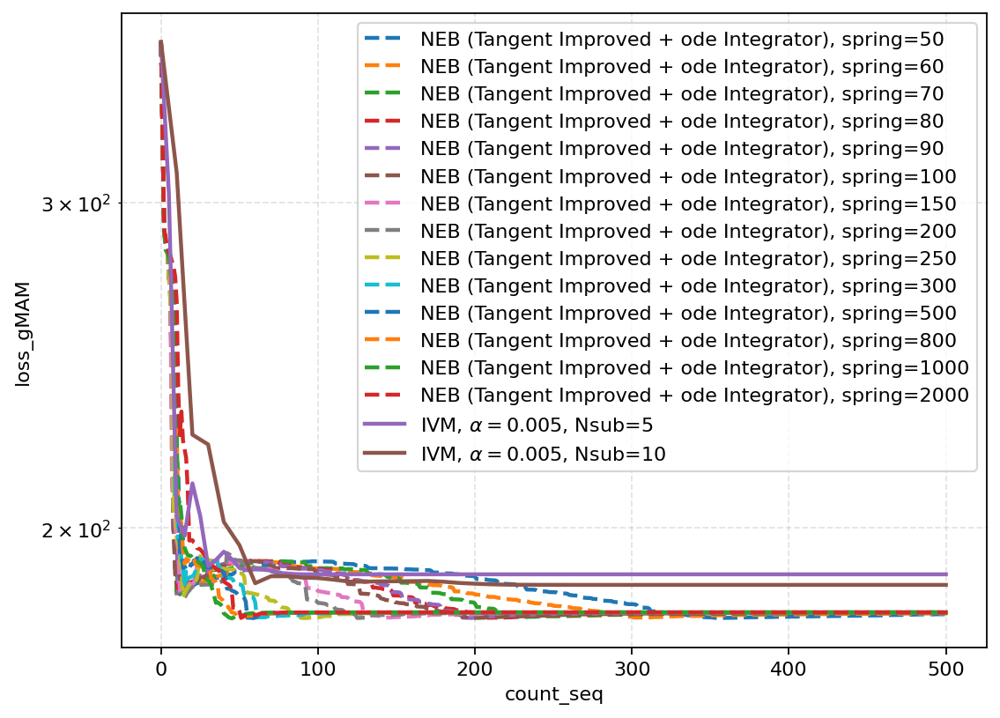

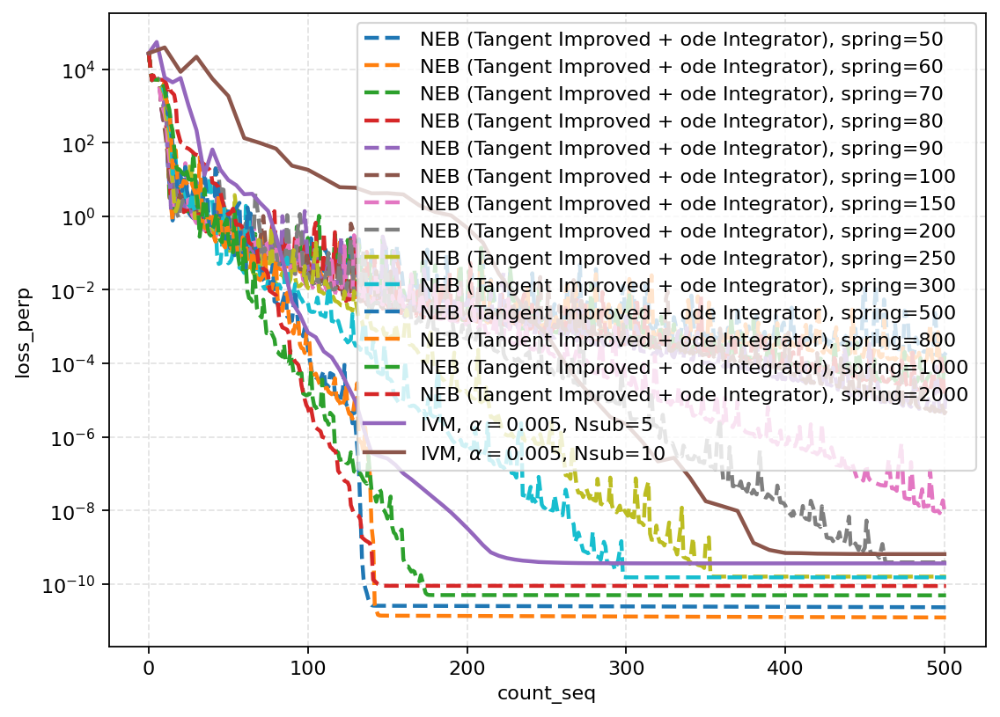

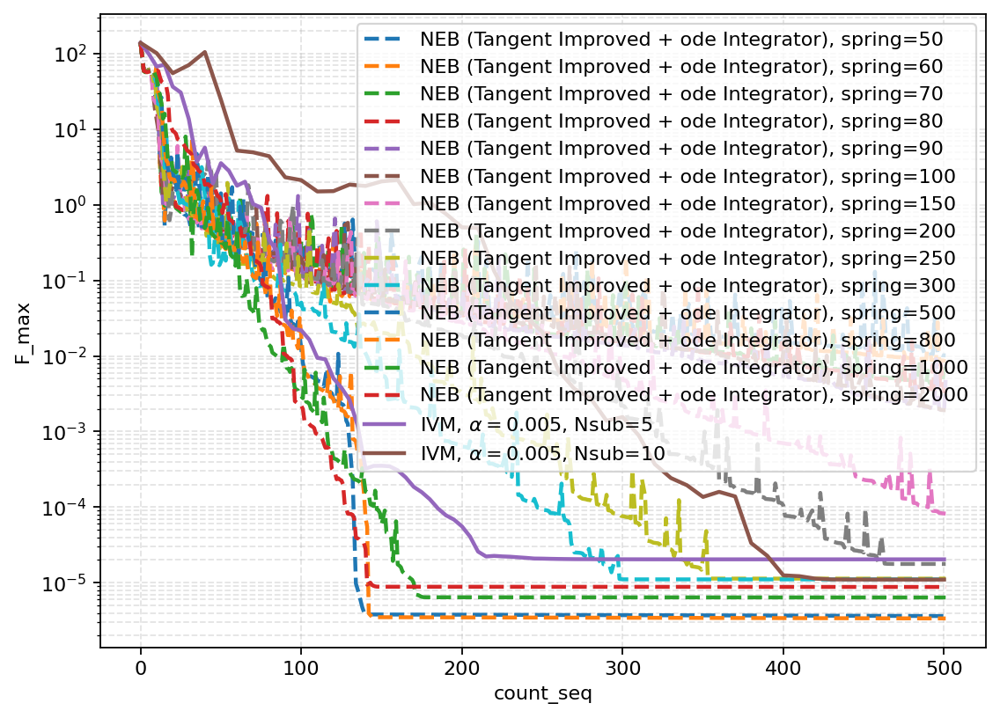

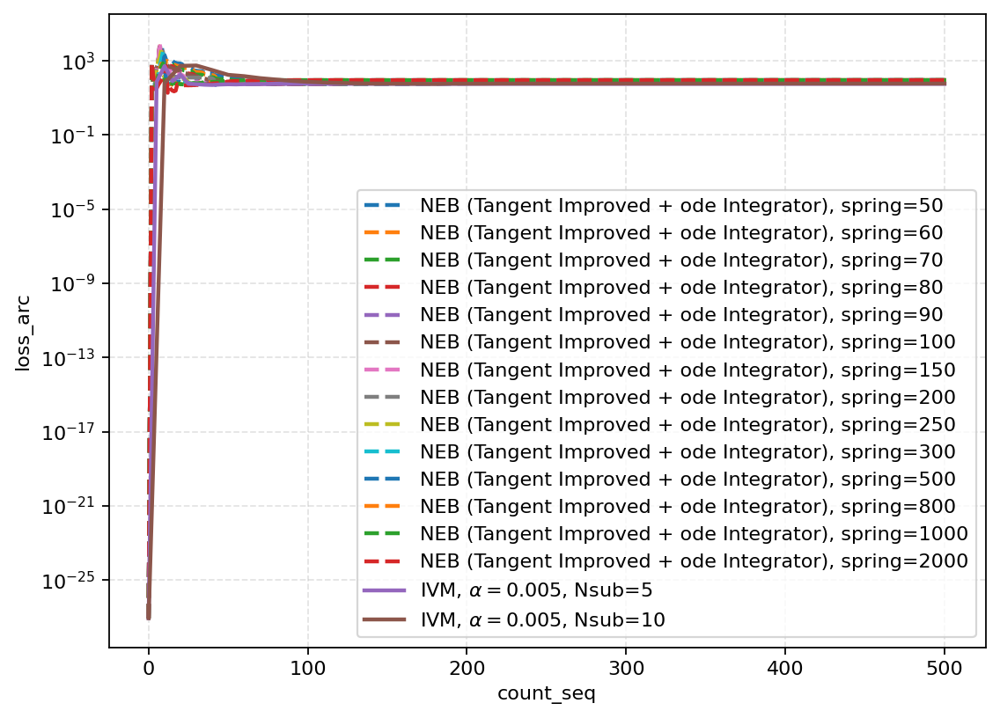

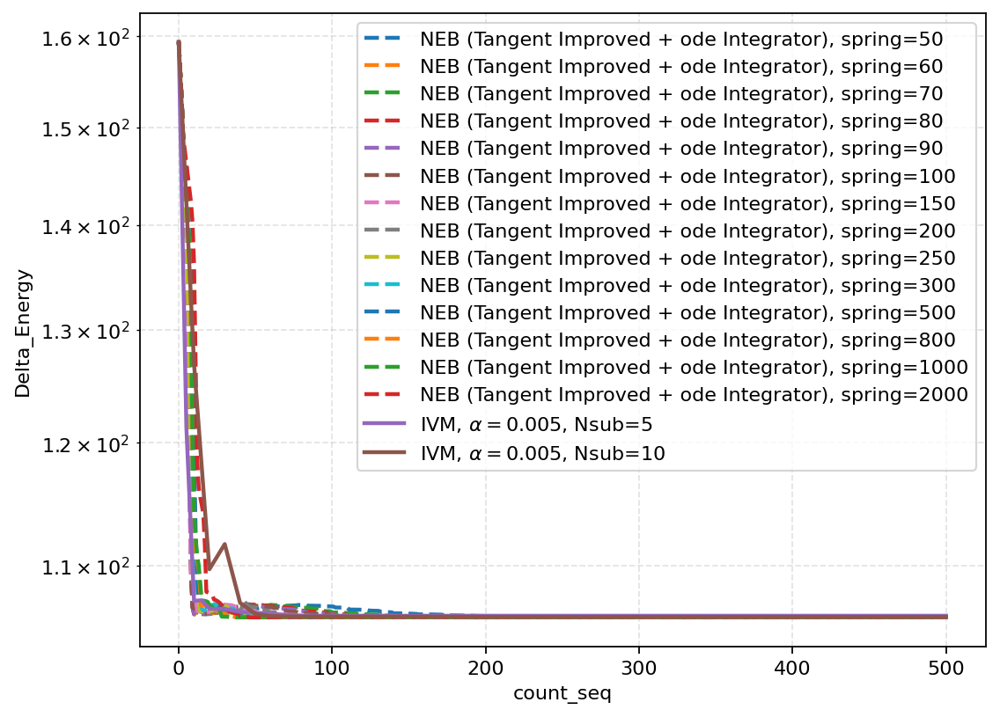

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 如果你的 numpy 版本比较旧，没有 np.trapezoid，就自动改用 np.trapz
try:
    trapz = np.trapezoid
except AttributeError:
    trapz = np.trapz


# ============================================================
# 1. 基础工具函数
# ============================================================

def compute_path_derivatives(images_seq):
    """
    images_seq: shape (T, N, d)
        T = iteration 数量
        N = 每条路径上的离散点数，包括两个端点
        d = 维度

    返回:
        s: shape (N,)
        phi_s: shape (T, N, d)
        phi_ss: shape (T, N, d)
        speed: shape (T, N), 即 |phi'(s)|
    """
    images_seq = np.asarray(images_seq)
    T, N, d = images_seq.shape

    s = np.linspace(0.0, 1.0, N)

    phi_s = np.gradient(images_seq, s, axis=1, edge_order=2)
    phi_ss = np.gradient(phi_s, s, axis=1, edge_order=2)

    speed = np.linalg.norm(phi_s, axis=2)

    return s, phi_s, phi_ss, speed


def line_integral_force_quantity(q_force, speed, N_path):
    """
    对定义在 force 网格上的 quantity 做 line integral.

    q_force: shape (T, N_force)
        例如 |F_perp|^2 或 |F_original|

    speed: shape (T, N_path)
        从 images_seq 算出来的 |phi'(s)|

    N_path:
        images_seq.shape[1]

    常见情况:
        F_perp, F_original 只在内部点记录，
        所以 N_force = N_path - 2.
    """
    q_force = np.asarray(q_force)
    speed = np.asarray(speed)

    T, N_force = q_force.shape
    ds = 1.0 / (N_path - 1)

    if N_force == N_path - 2:
        # F 只在内部点有值，对应 images_seq[:, 1:-1, :]
        speed_force = speed[:, 1:-1]
        return np.sum(q_force * speed_force, axis=1) * ds

    elif N_force == N_path:
        # F 在包括端点的整条路径上都有值
        s = np.linspace(0.0, 1.0, N_path)
        return trapz(q_force * speed, s, axis=1)

    else:
        # 兜底：如果 force 网格数和 path 网格数不匹配，则把 speed 插值过去
        s_path = np.linspace(0.0, 1.0, N_path)
        s_force = np.linspace(0.0, 1.0, N_force)

        speed_force = np.empty((T, N_force))
        for i in range(T):
            speed_force[i] = np.interp(s_force, s_path, speed[i])

        return trapz(q_force * speed_force, s_force, axis=1)


def compute_delta_energy(images_seq, V_func, dense_n=500, E_min=None):
    """
    计算 Delta_Energy = max_s V(phi(s)) - E_min.

    这里按照你给的代码：
        E_min = V_muller10_np(images_seq[0]).min()

    images_seq: shape (T, N, d)
    V_func: 例如 V_muller10_np
    """
    images_seq = np.asarray(images_seq)
    T, N, d = images_seq.shape

    t_old = np.linspace(0.0, 1.0, N)
    t_new = np.linspace(0.0, 1.0, dense_n)

    if E_min is None:
        E0 = V_func(images_seq[0])
        E_min = np.min(E0)

    Delta_Energy = np.empty(T)

    for i in range(T):
        X = images_seq[i]

        X_dense = np.column_stack([
            np.interp(t_new, t_old, X[:, dim])
            for dim in range(d)
        ])

        E_dense = V_func(X_dense)
        Delta_Energy[i] = np.max(E_dense) - E_min

    return Delta_Energy


def compute_all_metrics(images_seq, count_seq, F_perp, F_original, V_func,
                        fmax_mode="direct"):
    """
    计算五个指标:
        loss_gMAM
        loss_perp
        F_max
        loss_arc
        Delta_Energy

    fmax_mode:
        "direct" : F_max = np.max(F_perp)，严格按照你说的直接 max
        "abs"    : F_max = np.max(np.abs(F_perp))，如果你想看最大幅值可用这个
    """
    images_seq = np.asarray(images_seq)
    count_seq = np.asarray(count_seq)
    F_perp = np.asarray(F_perp)
    F_original = np.asarray(F_original)

    # 保证所有数组 iteration 维度一致
    T = min(
        images_seq.shape[0],
        count_seq.shape[0],
        F_perp.shape[0],
        F_original.shape[0],
    )

    images_seq = images_seq[:T]
    count_seq = count_seq[:T]
    F_perp = F_perp[:T]
    F_original = F_original[:T]

    T, N_path, d = images_seq.shape

    s, phi_s, phi_ss, speed = compute_path_derivatives(images_seq)

    # ------------------------------------------------------------
    # loss_gMAM = integral |nabla U(phi)| |phi'(s)| ds
    # 这里 F_original 代表 nabla(phi) / nabla U(phi)
    # ------------------------------------------------------------
    F_original_norm = np.linalg.norm(F_original, axis=2)
    loss_gMAM = line_integral_force_quantity(
        F_original_norm,
        speed,
        N_path
    )

    # ------------------------------------------------------------
    # loss_perp = integral |F_perp|^2 |phi'(s)| ds
    # ------------------------------------------------------------
    F_perp_norm_sq = np.sum(F_perp ** 2, axis=2)
    loss_perp = line_integral_force_quantity(
        F_perp_norm_sq,
        speed,
        N_path
    )

    # ------------------------------------------------------------
    # F_max
    # 你说直接取 max，所以默认用 direct。
    # 如果你实际想看最大幅值，把 fmax_mode 改成 "abs"。
    # ------------------------------------------------------------
    if fmax_mode == "direct":
        F_max = np.max(F_perp.reshape(T, -1), axis=1)
    elif fmax_mode == "abs":
        F_max = np.max(np.abs(F_perp.reshape(T, -1)), axis=1)
    else:
        raise ValueError("fmax_mode must be either 'direct' or 'abs'.")

    # ------------------------------------------------------------
    # loss_arc = integral ( <phi'(s), phi''(s)> )^2 |phi'(s)| ds
    # ------------------------------------------------------------
    inner_phi_s_phi_ss = np.sum(phi_s * phi_ss, axis=2)
    arc_integrand = inner_phi_s_phi_ss ** 2 * speed
    loss_arc = trapz(arc_integrand, s, axis=1)

    # ------------------------------------------------------------
    # Delta_Energy
    # ------------------------------------------------------------
    Delta_Energy = compute_delta_energy(
        images_seq,
        V_func=V_func,
        dense_n=500,
        E_min=None,
    )

    return {
        "count_seq": count_seq,
        "loss_gMAM": loss_gMAM,
        "loss_perp": loss_perp,
        "F_max": F_max,
        "loss_arc": loss_arc,
        "Delta_Energy": Delta_Energy,
    }


# ============================================================
# 2. 读取 NEB 和 IVM 数据
# ============================================================

def load_neb_runs(base_dir, n_images, alpha_list=(1e-4,), k_list=(1, 10, 20)):
    """
    读取所有 NEB 数据。

    你的路径格式:
    /home/zqcai3/wzy/IVP_IVM/M10_neb/N{n_images + 2}_k{k_neb}_alpha{alpha_neb}_ode_results.npz
    """
    base_dir = Path(base_dir)
    runs = []

    for alpha_neb in alpha_list:
        for k_neb in k_list:
            file_path = (
                base_dir
                / "M10_neb"
                / f"N{n_images + 2}_k{k_neb}_alpha{alpha_neb}_ode_results.npz"
            )

            loaded = np.load(file_path)

            runs.append({
                "method": "NEB",
                "label": f"NEB (Tangent Improved + ode Integrator), spring={k_neb}",
                "file": file_path,
                "images_seq": loaded["images_seq"],
                "count_seq": loaded["count_seq"],
                "F_perp": loaded["F_perp"],
                "F_original": loaded["F_original"],
            })

    return runs


def load_ivm_runs(base_dir, n_images, Nsub_list=(5, 10),
                  lr=0.05, alphaIVP=0.005):
    """
    读取所有 IVM 数据。

    你的路径格式:
    /home/zqcai3/wzy/IVP_IVM/M10_IVM_images_N{n_images}/N{n_images}_lr0.05_alphaIVP0.005_Nsub{Nsub}_results.npz
    """
    base_dir = Path(base_dir)
    runs = []

    for Nsub in Nsub_list:
        file_path = (
            base_dir
            / f"M10_IVM_images_N{n_images}"
            / f"N{n_images}_lr{lr}_alphaIVP{alphaIVP}_Nsub{Nsub}_results.npz"
        )

        loaded = np.load(file_path)

        runs.append({
            "method": "IVM",
            "label": fr"IVM, $\alpha = {alphaIVP}$, Nsub={Nsub}",
            "file": file_path,
            "images_seq": loaded["images_seq"],
            "count_seq": loaded["count_seq"],
            "F_perp": loaded["F_perp"],
            "F_original": loaded["F_original"],
        })

    return runs


# ============================================================
# 3. 画图函数
# ============================================================

def semilogy_safe(ax, x, y, label, linestyle="-", linewidth=2.0):
    """
    semilogy 要求 y > 0。
    如果 y 里面有非正数，则忽略这些点。
    """
    x = np.asarray(x)
    y = np.asarray(y)

    mask = np.isfinite(x) & np.isfinite(y) & (y > 0)

    if np.count_nonzero(mask) == 0:
        print(f"[Warning] {label}: no positive finite values for semilogy.")
        return

    ax.semilogy(
        x[mask],
        y[mask],
        label=label,
        linestyle=linestyle,
        linewidth=linewidth,
    )


def plot_metric_comparison(runs, metric_name, ylabel, save_dir=None):
    """
    对一个 metric 画一张图。
    """
    fig, ax = plt.subplots(figsize=(7.2, 5.2), dpi=160)

    for run in runs:
        x = run["metrics"]["count_seq"]
        y = run["metrics"][metric_name]

        if run["method"] == "NEB":
            linestyle = "--"
        else:
            linestyle = "-"

        semilogy_safe(
            ax,
            x,
            y,
            label=run["label"],
            linestyle=linestyle,
            linewidth=2.0,
        )

    ax.set_xlabel("count_seq")
    ax.set_ylabel(ylabel)
    ax.grid(True, which="both", linestyle="--", alpha=0.35)
    ax.legend()
    fig.tight_layout()

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        fig.savefig(save_dir / f"compare_{metric_name}.png", bbox_inches="tight")
        fig.savefig(save_dir / f"compare_{metric_name}.pdf", bbox_inches="tight")

    plt.show()


def plot_all_comparisons(runs, save_dir=None):
    """
    画五张图。
    """
    metric_info = {
        "loss_gMAM": "loss_gMAM",
        "loss_perp": "loss_perp",
        "F_max": "F_max",
        "loss_arc": "loss_arc",
        "Delta_Energy": "Delta_Energy",
    }

    for metric_name, ylabel in metric_info.items():
        plot_metric_comparison(
            runs,
            metric_name=metric_name,
            ylabel=ylabel,
            save_dir=save_dir,
        )


# ============================================================
# 4. 主程序
# ============================================================

# 你需要提前定义:
#   n_images
#   V_muller10_np
#
# 例如:
n_images = 10

base_dir = "/home/zqcai3/wzy/IVP_IVM"

neb_runs = load_neb_runs(
    base_dir=base_dir,
    n_images=n_images,
    alpha_list=(1e-4,),
    k_list=[50, 60, 70, 80, 90, 100, 150, 200, 250, 300, 500, 800, 1000, 2000],
)

ivm_runs = load_ivm_runs(
    base_dir=base_dir,
    n_images=n_images,
    Nsub_list=(5, 10),
    lr=0.05,
    alphaIVP=0.005,
)

runs = neb_runs + ivm_runs

# 计算所有指标
for run in runs:
    print("Processing:", run["label"])
    print("File:", run["file"])

    run["metrics"] = compute_all_metrics(
        images_seq=run["images_seq"],
        count_seq=run["count_seq"],
        F_perp=run["F_perp"],
        F_original=run["F_original"],
        V_func=V_muller10_np,
        fmax_mode="direct",   # 严格按照你说的直接 max
        # fmax_mode="abs",    # 如果你想看最大幅值，可以改成这个
    )

# 保存目录，可改
save_dir = Path(base_dir) / "comparison_figures"

plot_all_comparisons(
    runs,
    save_dir=save_dir,
)

Scanning finished experiments under:
  /home/zqcai3/wzy/IVP_IVM
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.005_steps100 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.005_steps1000 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.005_steps1500 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.005_steps200 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.005_steps2000 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.005_steps500 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.01_steps100 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.01_steps1000 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.01_steps1500 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.01_steps200 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.01_steps2000 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.01_steps500 | T=51, fina

[Loaded] M10_IVM_images_N10_Nsub15_alpha0.005_steps100 | T=34, final_count=495
[Loaded] M10_IVM_images_N10_Nsub15_alpha0.005_steps1000 | T=34, final_count=495
[Loaded] M10_IVM_images_N10_Nsub15_alpha0.005_steps1500 | T=34, final_count=495
[Loaded] M10_IVM_images_N10_Nsub15_alpha0.005_steps200 | T=34, final_count=495
[Loaded] M10_IVM_images_N10_Nsub15_alpha0.005_steps2000 | T=34, final_count=495
[Loaded] M10_IVM_images_N10_Nsub15_alpha0.005_steps500 | T=34, final_count=495
[Loaded] M10_IVM_images_N10_Nsub15_alpha0.01_steps100 | T=34, final_count=495
[Loaded] M10_IVM_images_N10_Nsub15_alpha0.01_steps1000 | T=34, final_count=495
[Loaded] M10_IVM_images_N10_Nsub15_alpha0.01_steps1500 | T=34, final_count=495
[Loaded] M10_IVM_images_N10_Nsub15_alpha0.01_steps200 | T=34, final_count=495
[Loaded] M10_IVM_images_N10_Nsub15_alpha0.01_steps2000 | T=34, final_count=495
[Loaded] M10_IVM_images_N10_Nsub15_alpha0.01_steps500 | T=34, final_count=495
[Loaded] M10_IVM_images_N10_Nsub15_alpha0.05_steps10

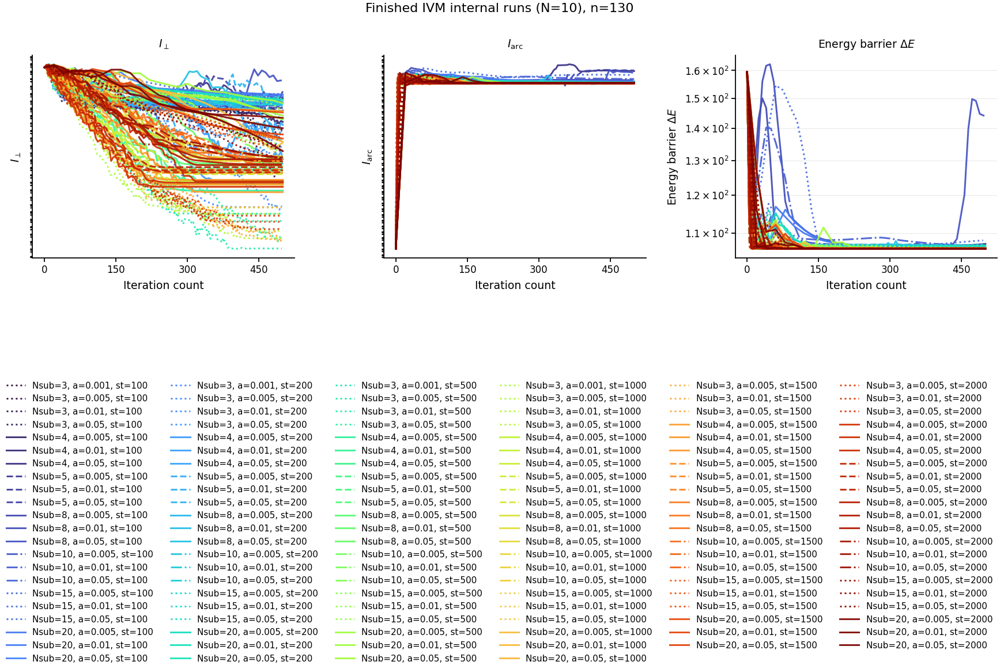

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_100_3metrics_x_count.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_100_3metrics_x_count.png


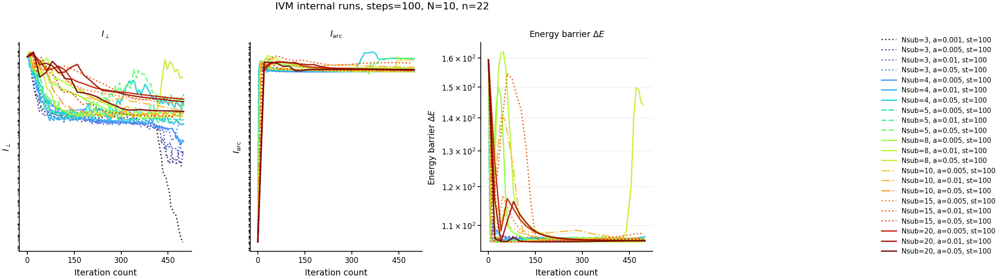

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_200_3metrics_x_count.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_200_3metrics_x_count.png


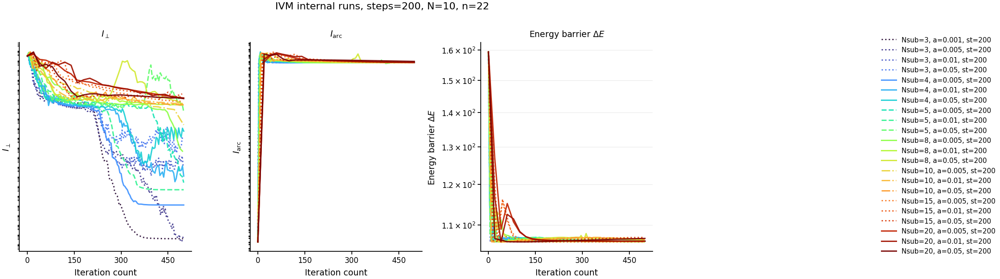

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_500_3metrics_x_count.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_500_3metrics_x_count.png


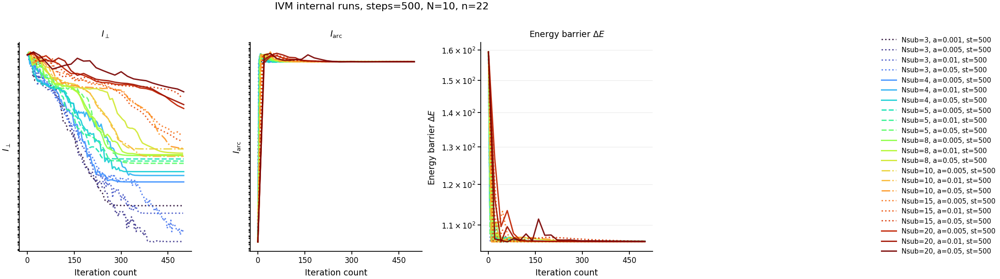

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_1000_3metrics_x_count.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_1000_3metrics_x_count.png


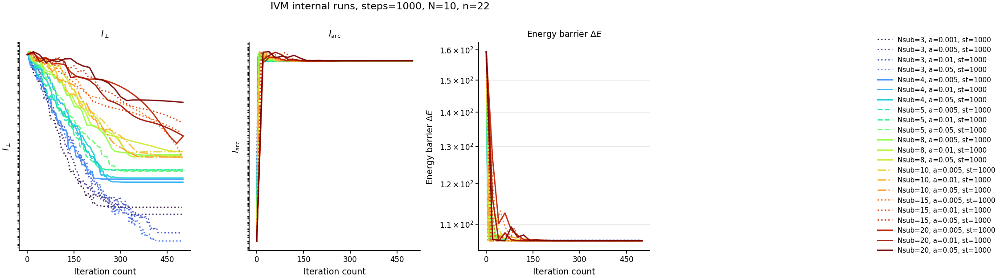

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_1500_3metrics_x_count.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_1500_3metrics_x_count.png


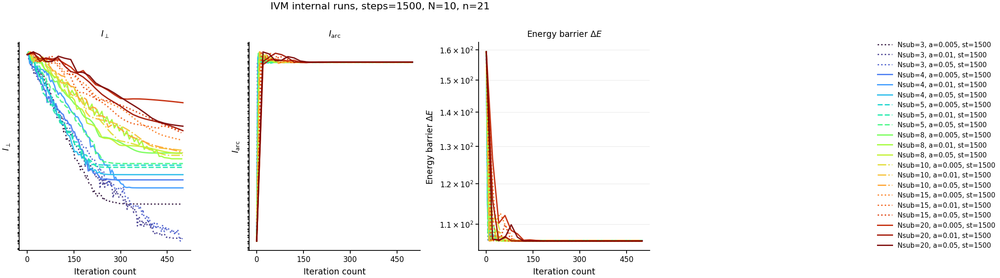

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_2000_3metrics_x_count.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_2000_3metrics_x_count.png


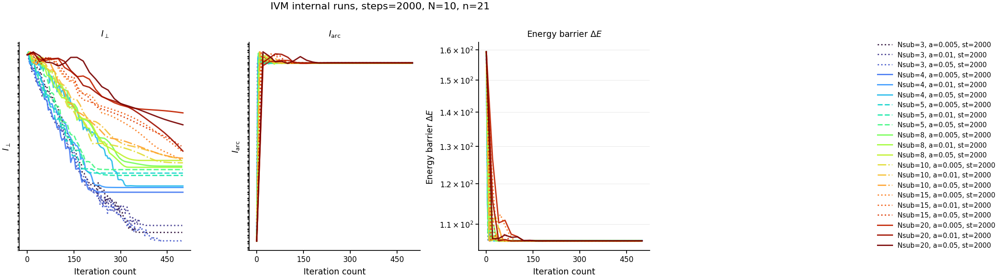


Done.
Figures and CSV saved to:
  /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics


In [3]:
# ============================================================
# IVM 内部调参结果 Notebook 可视化
# 只画已经跑完的实验:
#   loss_perp, loss_arc, Delta_Energy
#
# 修改说明：
#   指定 n_images = 20，仅加载和使用 N=20 的实验（文件夹名中的 N20）。
# ============================================================

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

import re
import csv
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter, MaxNLocator


# ============================================================
# 0. 配置区
# ============================================================

base_path = Path("/home/zqcai3/wzy/IVP_IVM/")
q_data_path = Path("/home/zqcai3/wzy/IVP_new/Q_data.npz")

dimension = 10

# ------------------------------------------------------------
# 明确指定：我们做的是 n_images = 20 的实验，文件夹名中为 N20
# ------------------------------------------------------------
n_images = 10
N_INTERIOR = n_images

# 你的实验目录格式:
# M10_IVM_images_N20_Nsub4_alpha0.005_steps100/results.npz
FOLDER_REGEX = re.compile(
    r"^M10_IVM_images_N(?P<N>\d+)_Nsub(?P<Nsub>\d+)_alpha(?P<alpha>[^_]+)_steps(?P<steps>\d+)$"
)

# 保存图片和 csv 的地方
save_dir = base_path / "comparison_figures" / "IVM_internal_notebook_3metrics"
save_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Notebook 显示和保存开关
# ------------------------------------------------------------

DISPLAY_IN_NOTEBOOK = True
SAVE_FIGURES = True

SAVE_FORMATS = ("pdf", "png")
PNG_DPI = 500

# ------------------------------------------------------------
# 横坐标选择
# ------------------------------------------------------------
# "count"      : 横坐标用 count_seq，也就是你的 i * N_sub
# "grad_evals" : 横坐标用 count_seq * N_INTERIOR
X_AXIS_MODE = "count"
# X_AXIS_MODE = "grad_evals"

if X_AXIS_MODE == "count":
    X_AXIS_LABEL = "Iteration count"
elif X_AXIS_MODE == "grad_evals":
    X_AXIS_LABEL = "Number of gradient evaluations"
else:
    raise ValueError("X_AXIS_MODE must be 'count' or 'grad_evals'.")

GRAD_EVALS_PER_COUNT = N_INTERIOR

# ------------------------------------------------------------
# 画图内容
# ------------------------------------------------------------

MAKE_ALL_FIGURE = True
MAKE_GROUP_BY_STEPS_FIGURES = True
MAKE_GROUP_BY_NSUB_FIGURES = False
MAKE_GROUP_BY_ALPHA_FIGURES = False

SHOW_LEGEND = True

# y 轴是否使用 log scale
USE_LOG_Y = True

# Delta Energy 插值密度
DENSE_N_FOR_DELTA_E = 500

# 如果之后你在训练中保存 results_partial.npz，
# 可以把这里改成 ("results_partial.npz", "results.npz")
RESULT_FILE_PRIORITY = ("results.npz",)


# ============================================================
# 1. Matplotlib 风格
# ============================================================

try:
    trapz = np.trapezoid
except AttributeError:
    trapz = np.trapz


def setup_style():
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 8.0,
        "axes.labelsize": 8.5,
        "axes.titlesize": 8.5,
        "xtick.labelsize": 7.5,
        "ytick.labelsize": 7.5,
        "legend.fontsize": 6.8,

        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,

        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "xtick.minor.width": 0.6,
        "ytick.minor.width": 0.6,
        "xtick.major.size": 3.0,
        "ytick.major.size": 3.0,
        "xtick.minor.size": 1.8,
        "ytick.minor.size": 1.8,

        "legend.frameon": False,
        "legend.handlelength": 2.2,

        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",

        "figure.dpi": 160,
        "savefig.dpi": PNG_DPI,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.03,
    })


setup_style()


# ============================================================
# 2. Müller-10 potential
# ============================================================

Q_np = np.load(q_data_path)["Q"]

a_np = np.array([-1.0, -1.0, -6.5, 0.7], dtype=float)
b_np = np.array([0.0, 0.0, 11.0, 0.6], dtype=float)
c_np = np.array([-10.0, -10.0, -6.5, 0.7], dtype=float)
D_np = np.array([-200.0, -100.0, -170.0, 15.0], dtype=float)
X_np = np.array([1.0, 0.0, -0.5, -1.0], dtype=float)
Y_np = np.array([0.0, 0.5, 1.5, 1.0], dtype=float)
sigma = 0.5


def V_muller10_np(x_vec):
    """
    Müller-10 势能，支持单点和批量输入。

    参数:
        x_vec: shape (10,) 或 (N, 10)

    返回:
        单点输入 -> float
        批量输入 -> shape (N,) numpy array
    """
    x = np.asarray(x_vec, dtype=float)
    single_input = x.ndim == 1

    if single_input:
        x = x.reshape(1, dimension)
    elif x.ndim != 2 or x.shape[1] != dimension:
        raise ValueError(
            f"Input must have shape ({dimension},) or (N,{dimension}), got {x.shape}"
        )

    z = x @ Q_np

    z0 = z[:, 0]
    z1 = z[:, 1]
    rest = z[:, 2:]

    V = np.zeros(z.shape[0], dtype=float)

    for i in range(4):
        exponent = (
            a_np[i] * (z0 - X_np[i]) ** 2
            + b_np[i] * (z0 - X_np[i]) * (z1 - Y_np[i])
            + c_np[i] * (z1 - Y_np[i]) ** 2
        )
        V += D_np[i] * np.exp(exponent)

    V += np.sum((1.0 / (2.0 * sigma ** 2)) * rest ** 2, axis=1)

    if single_input:
        return float(V[0])

    return V


# ============================================================
# 3. 三个指标计算
# ============================================================

def compute_path_derivatives(images_seq):
    """
    images_seq: shape (T, N_path, d)

    返回:
        s: shape (N_path,)
        phi_s: shape (T, N_path, d)
        phi_ss: shape (T, N_path, d)
        speed: shape (T, N_path)
    """
    images_seq = np.asarray(images_seq, dtype=float)

    if images_seq.ndim != 3:
        raise ValueError(
            f"images_seq must have shape (T, N_path, d), got {images_seq.shape}"
        )

    T, N_path, d = images_seq.shape

    s = np.linspace(0.0, 1.0, N_path)
    edge_order = 2 if N_path >= 3 else 1

    phi_s = np.gradient(images_seq, s, axis=1, edge_order=edge_order)
    phi_ss = np.gradient(phi_s, s, axis=1, edge_order=edge_order)

    speed = np.linalg.norm(phi_s, axis=2)

    return s, phi_s, phi_ss, speed


def line_integral_force_quantity(q_force, speed, N_path):
    """
    对 force 网格上的 quantity 做 line integral。

    常见情况:
        q_force shape = (T, N_path - 2)，对应 interior images。
    """
    q_force = np.asarray(q_force, dtype=float)
    speed = np.asarray(speed, dtype=float)

    if q_force.ndim != 2:
        raise ValueError(f"q_force must have shape (T, N_force), got {q_force.shape}")

    if speed.ndim != 2:
        raise ValueError(f"speed must have shape (T, N_path), got {speed.shape}")

    T, N_force = q_force.shape
    ds = 1.0 / (N_path - 1)

    if N_force == N_path - 2:
        speed_force = speed[:, 1:-1]
        return np.sum(q_force * speed_force, axis=1) * ds

    elif N_force == N_path - 1:
        speed_force = speed[:, :-1]
        return np.sum(q_force * speed_force, axis=1) * ds

    elif N_force == N_path:
        s = np.linspace(0.0, 1.0, N_path)
        return trapz(q_force * speed, s, axis=1)

    else:
        s_path = np.linspace(0.0, 1.0, N_path)
        s_force = np.linspace(0.0, 1.0, N_force)

        speed_force = np.empty((T, N_force), dtype=float)

        for i in range(T):
            speed_force[i] = np.interp(s_force, s_path, speed[i])

        return trapz(q_force * speed_force, s_force, axis=1)


def compute_loss_perp(images_seq, F_perp):
    """
    loss_perp = integral |F_perp|^2 |phi'(s)| ds
    """
    images_seq = np.asarray(images_seq, dtype=float)
    F_perp = np.asarray(F_perp, dtype=float)

    if images_seq.ndim != 3:
        raise ValueError(f"images_seq must be 3D, got {images_seq.shape}")

    if F_perp.ndim != 3:
        raise ValueError(f"F_perp must be 3D, got {F_perp.shape}")

    T = min(images_seq.shape[0], F_perp.shape[0])

    images_seq = images_seq[:T]
    F_perp = F_perp[:T]

    T, N_path, d = images_seq.shape

    s, phi_s, phi_ss, speed = compute_path_derivatives(images_seq)

    F_perp_norm_sq = np.sum(F_perp ** 2, axis=2)

    loss_perp = line_integral_force_quantity(
        q_force=F_perp_norm_sq,
        speed=speed,
        N_path=N_path,
    )

    return loss_perp


def compute_loss_arc(images_seq):
    """
    loss_arc = integral (<phi'(s), phi''(s)>)^2 |phi'(s)| ds
    """
    images_seq = np.asarray(images_seq, dtype=float)

    s, phi_s, phi_ss, speed = compute_path_derivatives(images_seq)

    inner_phi_s_phi_ss = np.sum(phi_s * phi_ss, axis=2)
    arc_integrand = inner_phi_s_phi_ss ** 2 * speed

    loss_arc = trapz(arc_integrand, s, axis=1)

    return loss_arc


def compute_delta_energy(images_seq, V_func, dense_n=500, E_min=None):
    """
    Delta_Energy = max_s V(phi(s)) - E_min

    默认:
        E_min = min V(images_seq[0])
    """
    images_seq = np.asarray(images_seq, dtype=float)

    if images_seq.ndim != 3:
        raise ValueError(f"images_seq must be 3D, got {images_seq.shape}")

    T, N_path, d = images_seq.shape

    s_old = np.linspace(0.0, 1.0, N_path)
    s_new = np.linspace(0.0, 1.0, dense_n)

    if E_min is None:
        E0 = V_func(images_seq[0])
        E_min = float(np.min(E0))

    Delta_Energy = np.empty(T, dtype=float)

    for i in range(T):
        X = images_seq[i]

        X_dense = np.column_stack([
            np.interp(s_new, s_old, X[:, dim_idx])
            for dim_idx in range(d)
        ])

        E_dense = V_func(X_dense)
        Delta_Energy[i] = float(np.max(E_dense) - E_min)

    return Delta_Energy


def compute_metrics_for_run(run):
    """
    给一个 run 计算:
        loss_perp
        loss_arc
        Delta_Energy
    """
    images_seq = np.asarray(run["images_seq"], dtype=float)
    count_seq = np.asarray(run["count_seq"], dtype=float).reshape(-1)
    F_perp = np.asarray(run["F_perp"], dtype=float)

    T = min(images_seq.shape[0], count_seq.shape[0], F_perp.shape[0])

    images_seq = images_seq[:T]
    count_seq = count_seq[:T]
    F_perp = F_perp[:T]

    if T == 0:
        raise ValueError("Empty run: no time frames found.")

    loss_perp = compute_loss_perp(images_seq, F_perp)
    loss_arc = compute_loss_arc(images_seq)
    Delta_Energy = compute_delta_energy(
        images_seq=images_seq,
        V_func=V_muller10_np,
        dense_n=DENSE_N_FOR_DELTA_E,
        E_min=None,
    )

    grad_count_seq = count_seq * GRAD_EVALS_PER_COUNT

    run["images_seq"] = images_seq
    run["count_seq"] = count_seq
    run["F_perp"] = F_perp

    run["metrics"] = {
        "count_seq": count_seq,
        "grad_count_seq": grad_count_seq,
        "loss_perp": loss_perp,
        "loss_arc": loss_arc,
        "Delta_Energy": Delta_Energy,
    }

    return run


# ============================================================
# 4. 自动扫描已经跑完的实验
# ============================================================

def parse_folder_name(folder_name):
    m = FOLDER_REGEX.match(folder_name)

    if m is None:
        return None

    info = {
        "N": int(m.group("N")),
        "Nsub": int(m.group("Nsub")),
        "alpha": float(m.group("alpha")),
        "steps": int(m.group("steps")),
    }

    return info


def label_for_run(run):
    return (
        f"Nsub={run['Nsub']}, "
        f"alpha={run['alpha']:g}, "
        f"steps={run['steps']}"
    )


def short_label_for_run(run):
    return f"Nsub={run['Nsub']}, a={run['alpha']:g}, st={run['steps']}"


def find_result_file(folder):
    """
    按 RESULT_FILE_PRIORITY 寻找结果文件。
    默认只找 results.npz。
    """
    for name in RESULT_FILE_PRIORITY:
        p = folder / name
        if p.exists():
            return p

    return None


def load_finished_runs(base_path):
    """
    扫描 base_path 下所有已经有 results.npz 的实验。
    """
    runs = []

    folders = sorted([p for p in base_path.iterdir() if p.is_dir()])

    for folder in folders:
        info = parse_folder_name(folder.name)

        if info is None:
            continue

        result_file = find_result_file(folder)

        if result_file is None:
            print(f"[Skip unfinished] {folder.name}: no result file")
            continue

        try:
            data = np.load(result_file, allow_pickle=True)

            required = ["images_seq", "count_seq", "F_perp"]
            missing = [k for k in required if k not in data.files]

            if len(missing) > 0:
                print(f"[Skip] {result_file}: missing keys {missing}")
                continue

            run = {
                "folder": folder,
                "file": result_file,
                "N": info["N"],
                "Nsub": info["Nsub"],
                "alpha": info["alpha"],
                "steps": info["steps"],
                "images_seq": data["images_seq"],
                "count_seq": data["count_seq"],
                "F_perp": data["F_perp"],
            }

            run["label"] = label_for_run(run)
            run["short_label"] = short_label_for_run(run)

            run = compute_metrics_for_run(run)

            runs.append(run)

            print(
                f"[Loaded] {folder.name} | "
                f"T={len(run['metrics']['count_seq'])}, "
                f"final_count={run['metrics']['count_seq'][-1]:.0f}"
            )

        except Exception as e:
            print(f"[Skip error] {result_file}: {repr(e)}")

    runs = sorted(
        runs,
        key=lambda r: (r["steps"], r["Nsub"], r["alpha"], str(r["folder"]))
    )

    return runs


# ============================================================
# 5. 绘图工具
# ============================================================

METRIC_INFO = {
    "loss_perp": {
        "ylabel": r"$I_{\perp}$",
        "title": r"$I_{\perp}$",
    },
    "loss_arc": {
        "ylabel": r"$I_{\mathrm{arc}}$",
        "title": r"$I_{\mathrm{arc}}$",
    },
    "Delta_Energy": {
        "ylabel": r"Energy barrier $\Delta E$",
        "title": r"Energy barrier $\Delta E$",
    },
}


def get_x(run):
    if X_AXIS_MODE == "count":
        return run["metrics"]["count_seq"]
    elif X_AXIS_MODE == "grad_evals":
        return run["metrics"]["grad_count_seq"]
    else:
        raise ValueError("Unknown X_AXIS_MODE.")


def count_formatter(x, pos=None):
    if not np.isfinite(x):
        return ""

    ax = abs(x)

    if ax >= 1e6:
        return f"{x / 1e6:g}M"

    if ax >= 1e3:
        return f"{x / 1e3:g}k"

    if abs(x - round(x)) < 1e-8:
        return f"{int(round(x))}"

    return f"{x:g}"


def sci_formatter(y, pos=None):
    if not np.isfinite(y):
        return ""

    if y == 0:
        return "0"

    ay = abs(y)

    if ay < 1e-3 or ay >= 1e4:
        return f"{y:.1e}"

    return f"{y:g}"


def style_axis(ax):
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        length=3.0,
        width=0.8,
        pad=2.0,
    )

    ax.tick_params(
        axis="both",
        which="minor",
        direction="out",
        length=1.8,
        width=0.6,
        pad=2.0,
    )

    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.xaxis.set_major_formatter(FuncFormatter(count_formatter))

    if USE_LOG_Y:
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(
            LogLocator(base=10.0, subs=(1.0, 2.0, 5.0), numticks=8)
        )
        ax.yaxis.set_minor_locator(
            LogLocator(base=10.0, subs=(3.0, 4.0, 6.0, 7.0, 8.0, 9.0), numticks=60)
        )
        ax.yaxis.set_minor_formatter(NullFormatter())
    else:
        ax.yaxis.set_major_formatter(FuncFormatter(sci_formatter))

    ax.grid(
        True,
        axis="y",
        which="major",
        linestyle="-",
        linewidth=0.35,
        color="0.88",
        alpha=1.0,
        zorder=0,
    )


def make_color_map(runs):
    """
    给每条曲线分配颜色。
    """
    n = len(runs)

    if n <= 10:
        cmap = plt.get_cmap("tab10")
        colors = [cmap(i % 10) for i in range(n)]
    elif n <= 20:
        cmap = plt.get_cmap("tab20")
        colors = [cmap(i % 20) for i in range(n)]
    else:
        cmap = plt.get_cmap("turbo")
        colors = [cmap(i / max(n - 1, 1)) for i in range(n)]

    return {
        id(run): colors[i]
        for i, run in enumerate(runs)
    }


def get_linestyle(run):
    """
    用 Nsub 给一点线型区分。
    """
    styles = ["-", "--", "-.", ":"]
    return styles[run["Nsub"] % len(styles)]


def plot_metric_curves(ax, runs, metric_name, color_map):
    for run in runs:
        x = np.asarray(get_x(run), dtype=float).reshape(-1)
        y = np.asarray(run["metrics"][metric_name], dtype=float).reshape(-1)

        T = min(len(x), len(y))
        x = x[:T]
        y = y[:T]

        mask = np.isfinite(x) & np.isfinite(y)

        if USE_LOG_Y:
            mask = mask & (y > 0)

        if np.count_nonzero(mask) == 0:
            print(f"[Warning] no valid data for {run['label']} metric={metric_name}")
            continue

        ax.plot(
            x[mask],
            y[mask],
            label=run["short_label"],
            color=color_map[id(run)],
            linestyle=get_linestyle(run),
            linewidth=1.35,
            alpha=0.92,
        )

    info = METRIC_INFO[metric_name]
    ax.set_title(info["title"])
    ax.set_xlabel(X_AXIS_LABEL)
    ax.set_ylabel(info["ylabel"])

    style_axis(ax)


def save_figure(fig, stem):
    if not SAVE_FIGURES:
        return

    for ext in SAVE_FORMATS:
        out = save_dir / f"{stem}.{ext}"

        if ext.lower() == "png":
            fig.savefig(out, dpi=PNG_DPI, bbox_inches="tight")
        else:
            fig.savefig(out, bbox_inches="tight")

        print(f"Saved: {out}")


def sanitize_float_for_filename(x):
    s = f"{x:g}"
    s = s.replace(".", "p")
    s = s.replace("-", "m")
    return s


def plot_1x3_runs(runs, stem, suptitle=None):
    """
    画 1x3:
        loss_perp, loss_arc, Delta_Energy

    在 Notebook 中会直接显示。
    同时可保存到 save_dir。
    """
    if len(runs) == 0:
        print(f"[Skip plot] {stem}: no runs")
        return

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(13.5, 3.8),
        dpi=160,
    )

    color_map = make_color_map(runs)

    metric_order = ["loss_perp", "loss_arc", "Delta_Energy"]

    for ax, metric_name in zip(axes, metric_order):
        plot_metric_curves(
            ax=ax,
            runs=runs,
            metric_name=metric_name,
            color_map=color_map,
        )

    if SHOW_LEGEND:
        handles, labels = axes[0].get_legend_handles_labels()

        if len(runs) <= 24:
            fig.legend(
                handles,
                labels,
                loc="center left",
                bbox_to_anchor=(1.01, 0.5),
                frameon=False,
                ncol=1,
            )
            fig.subplots_adjust(right=0.78, wspace=0.34)
        else:
            ncol = 4 if len(runs) <= 60 else 6
            fig.legend(
                handles,
                labels,
                loc="upper center",
                bbox_to_anchor=(0.5, -0.03),
                frameon=False,
                ncol=ncol,
            )
            fig.subplots_adjust(bottom=0.30, wspace=0.34)
    else:
        fig.subplots_adjust(wspace=0.34)

    if suptitle is not None:
        fig.suptitle(suptitle, y=1.03, fontsize=10)

    save_figure(fig, stem)

    if DISPLAY_IN_NOTEBOOK:
        plt.show()
    else:
        plt.close(fig)


# ============================================================
# 6. CSV 和终端表格
# ============================================================

def save_final_metrics_csv(runs):
    csv_path = save_dir / "finished_ivm_internal_final_metrics.csv"

    fieldnames = [
        "N",
        "Nsub",
        "alpha",
        "steps",
        "file",
        "final_count",
        "final_gradient_evals",
        "loss_perp",
        "loss_arc",
        "Delta_Energy",
    ]

    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

        for run in runs:
            m = run["metrics"]

            row = {
                "N": run["N"],
                "Nsub": run["Nsub"],
                "alpha": run["alpha"],
                "steps": run["steps"],
                "file": str(run["file"]),
                "final_count": float(m["count_seq"][-1]),
                "final_gradient_evals": float(m["grad_count_seq"][-1]),
                "loss_perp": float(m["loss_perp"][-1]),
                "loss_arc": float(m["loss_arc"][-1]),
                "Delta_Energy": float(m["Delta_Energy"][-1]),
            }

            writer.writerow(row)

    print(f"Saved: {csv_path}")


def print_final_table(runs):
    print("\nFinal metrics of finished IVM runs:")
    header = (
        f"{'Nsub':>6} "
        f"{'alpha':>12} "
        f"{'steps':>8} "
        f"{'final_count':>14} "
        f"{'loss_perp':>16} "
        f"{'loss_arc':>16} "
        f"{'Delta_Energy':>16}"
    )
    print(header)
    print("-" * len(header))

    for run in runs:
        m = run["metrics"]

        print(
            f"{run['Nsub']:6d} "
            f"{run['alpha']:12.4g} "
            f"{run['steps']:8d} "
            f"{m['count_seq'][-1]:14.0f} "
            f"{m['loss_perp'][-1]:16.6e} "
            f"{m['loss_arc'][-1]:16.6e} "
            f"{m['Delta_Energy'][-1]:16.6e}"
        )


# ============================================================
# 7. 分组
# ============================================================

def group_runs_by_key(runs, key):
    groups = {}

    for run in runs:
        value = run[key]
        groups.setdefault(value, []).append(run)

    return dict(sorted(groups.items(), key=lambda kv: kv[0]))


# ============================================================
# 8. 主程序
# ============================================================

def main():
    print(f"Scanning finished experiments under:\n  {base_path}")

    runs = load_finished_runs(base_path)

    # ------------------------------------------------------------
    # 只保留 N == n_images 的实验（当前固定为 20）
    # ------------------------------------------------------------
    runs_N_filtered = [r for r in runs if r["N"] == n_images]

    if len(runs_N_filtered) < len(runs):
        print(
            f"\nFiltered by N = {n_images}: "
            f"kept {len(runs_N_filtered)} of {len(runs)} runs."
        )
    else:
        print(f"\nAll loaded runs have N = {n_images}.")

    runs = runs_N_filtered

    if len(runs) == 0:
        print("\nNo finished experiments found for N =", n_images)
        print("A finished experiment should have:")
        print(f"  M10_IVM_images_N{n_images}_Nsub*_alpha*_steps*/results.npz")
        return []

    print(f"\nTotal finished runs loaded: {len(runs)}")

    print_final_table(runs)
    save_final_metrics_csv(runs)

    # ------------------------------------------------------------
    # 8.1 所有已完成实验画在一张图里
    # ------------------------------------------------------------
    if MAKE_ALL_FIGURE:
        plot_1x3_runs(
            runs=runs,
            stem=f"IVM_internal_all_finished_3metrics_x_{X_AXIS_MODE}",
            suptitle=f"Finished IVM internal runs (N={n_images}), n={len(runs)}",
        )

    # ------------------------------------------------------------
    # 8.2 按 steps 分组
    # ------------------------------------------------------------
    if MAKE_GROUP_BY_STEPS_FIGURES:
        groups = group_runs_by_key(runs, "steps")

        for steps, group in groups.items():
            plot_1x3_runs(
                runs=group,
                stem=f"IVM_internal_by_steps_{steps}_3metrics_x_{X_AXIS_MODE}",
                suptitle=f"IVM internal runs, steps={steps}, N={n_images}, n={len(group)}",
            )

    # ------------------------------------------------------------
    # 8.3 按 Nsub 分组
    # ------------------------------------------------------------
    if MAKE_GROUP_BY_NSUB_FIGURES:
        groups = group_runs_by_key(runs, "Nsub")

        for Nsub, group in groups.items():
            plot_1x3_runs(
                runs=group,
                stem=f"IVM_internal_by_Nsub_{Nsub}_3metrics_x_{X_AXIS_MODE}",
                suptitle=f"IVM internal runs, Nsub={Nsub}, N={n_images}, n={len(group)}",
            )

    # ------------------------------------------------------------
    # 8.4 按 alpha 分组
    # ------------------------------------------------------------
    if MAKE_GROUP_BY_ALPHA_FIGURES:
        groups = group_runs_by_key(runs, "alpha")

        for alpha, group in groups.items():
            alpha_s = sanitize_float_for_filename(alpha)

            plot_1x3_runs(
                runs=group,
                stem=f"IVM_internal_by_alpha_{alpha_s}_3metrics_x_{X_AXIS_MODE}",
                suptitle=f"IVM internal runs, alpha={alpha:g}, N={n_images}, n={len(group)}",
            )

    print("\nDone.")
    print(f"Figures and CSV saved to:\n  {save_dir}")

    return runs


# ============================================================
# 9. 在 Notebook 中直接运行
# ============================================================

runs = main()

Scanning finished experiments under:
  /home/zqcai3/wzy/IVP_IVM


[Loaded] M10_IVM_images_N10_Nsub10_alpha0.005_steps100 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.005_steps1000 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.005_steps1500 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.005_steps200 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.005_steps2000 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.005_steps500 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.01_steps100 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.01_steps1000 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.01_steps1500 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.01_steps200 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.01_steps2000 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.01_steps500 | T=51, final_count=500
[Loaded] M10_IVM_images_N10_Nsub10_alpha0.05_steps10

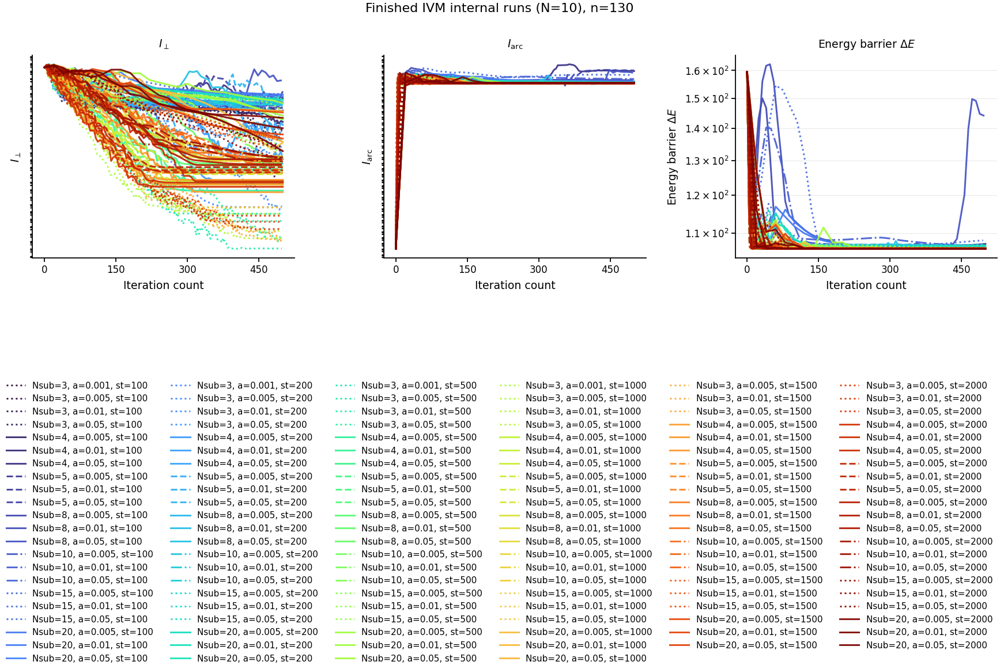

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_100_3metrics_x_count.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_100_3metrics_x_count.png


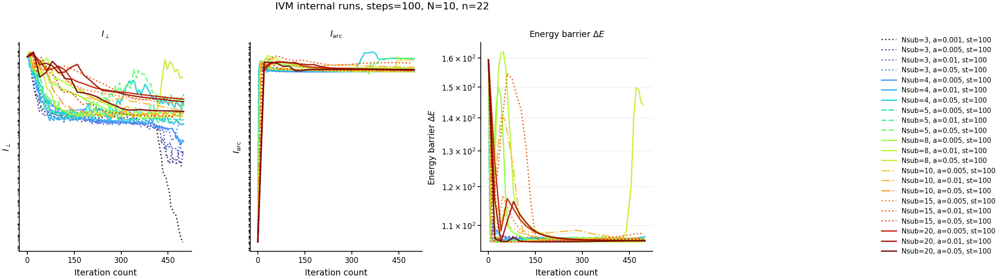

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_200_3metrics_x_count.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_200_3metrics_x_count.png


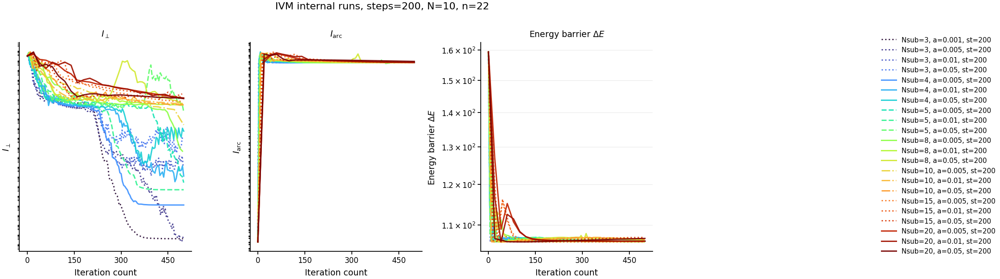

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_500_3metrics_x_count.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_500_3metrics_x_count.png


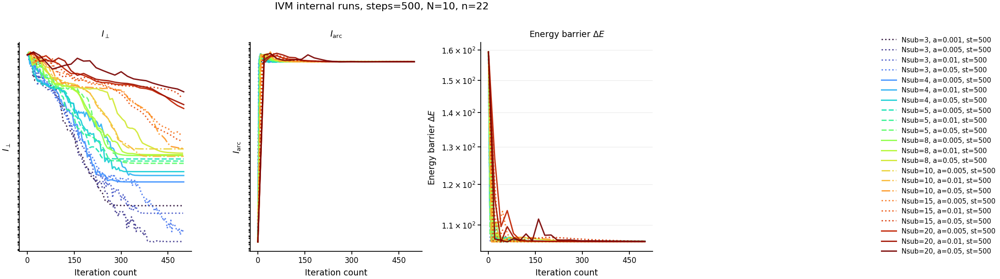

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_1000_3metrics_x_count.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_1000_3metrics_x_count.png


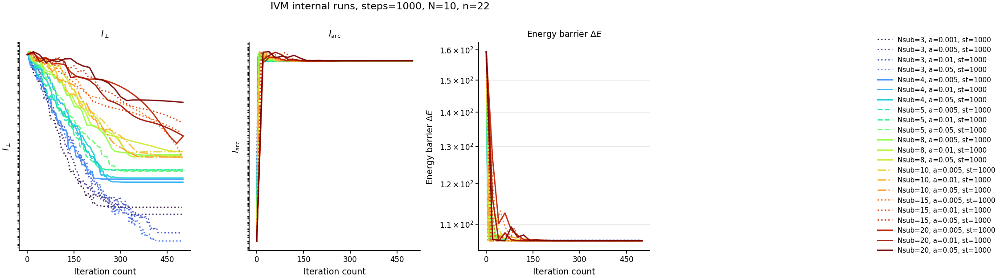

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_1500_3metrics_x_count.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_1500_3metrics_x_count.png


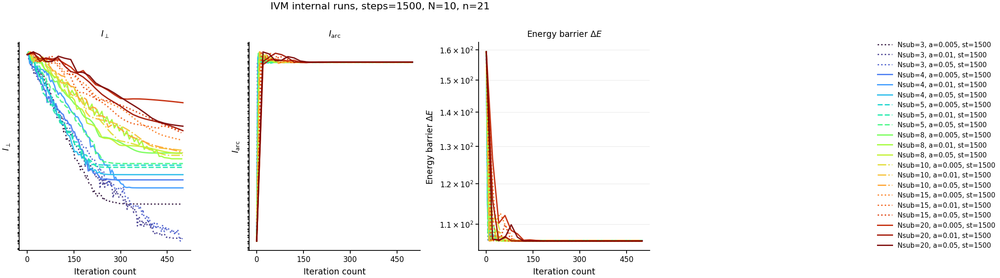

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_2000_3metrics_x_count.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics/IVM_internal_by_steps_2000_3metrics_x_count.png


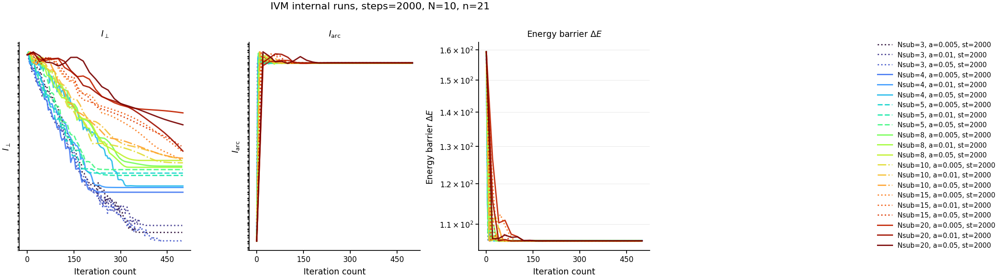


Done.
Figures and CSV saved to:
  /home/zqcai3/wzy/IVP_IVM/comparison_figures/IVM_internal_notebook_3metrics


In [4]:
# ============================================================
# IVM 内部调参结果 Notebook 可视化
# 只画已经跑完的实验:
#   loss_perp, loss_arc, Delta_Energy
#
# 修改说明：
#   指定 n_images = 20，仅加载和使用 N=20 的实验（文件夹名中的 N20）。
# ============================================================

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

import re
import csv
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter, MaxNLocator


# ============================================================
# 0. 配置区
# ============================================================

base_path = Path("/home/zqcai3/wzy/IVP_IVM/")
q_data_path = Path("/home/zqcai3/wzy/IVP_new/Q_data.npz")

dimension = 10

# ------------------------------------------------------------
# 明确指定：我们做的是 n_images = 20 的实验，文件夹名中为 N20
# ------------------------------------------------------------
n_images = 10
N_INTERIOR = n_images

# 你的实验目录格式:
# M10_IVM_images_N20_Nsub4_alpha0.005_steps100/results.npz
FOLDER_REGEX = re.compile(
    r"^M10_IVM_images_N(?P<N>\d+)_Nsub(?P<Nsub>\d+)_alpha(?P<alpha>[^_]+)_steps(?P<steps>\d+)$"
)

# 保存图片和 csv 的地方
save_dir = base_path / "comparison_figures" / "IVM_internal_notebook_3metrics"
save_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Notebook 显示和保存开关
# ------------------------------------------------------------

DISPLAY_IN_NOTEBOOK = True
SAVE_FIGURES = True

SAVE_FORMATS = ("pdf", "png")
PNG_DPI = 500

# ------------------------------------------------------------
# 横坐标选择
# ------------------------------------------------------------
# "count"      : 横坐标用 count_seq，也就是你的 i * N_sub
# "grad_evals" : 横坐标用 count_seq * N_INTERIOR
X_AXIS_MODE = "count"
# X_AXIS_MODE = "grad_evals"

if X_AXIS_MODE == "count":
    X_AXIS_LABEL = "Iteration count"
elif X_AXIS_MODE == "grad_evals":
    X_AXIS_LABEL = "Number of gradient evaluations"
else:
    raise ValueError("X_AXIS_MODE must be 'count' or 'grad_evals'.")

GRAD_EVALS_PER_COUNT = N_INTERIOR

# ------------------------------------------------------------
# 画图内容
# ------------------------------------------------------------

MAKE_ALL_FIGURE = True
MAKE_GROUP_BY_STEPS_FIGURES = True
MAKE_GROUP_BY_NSUB_FIGURES = False
MAKE_GROUP_BY_ALPHA_FIGURES = False

SHOW_LEGEND = True

# y 轴是否使用 log scale
USE_LOG_Y = True

# Delta Energy 插值密度
DENSE_N_FOR_DELTA_E = 500

# 如果之后你在训练中保存 results_partial.npz，
# 可以把这里改成 ("results_partial.npz", "results.npz")
RESULT_FILE_PRIORITY = ("results.npz",)


# ============================================================
# 1. Matplotlib 风格
# ============================================================

try:
    trapz = np.trapezoid
except AttributeError:
    trapz = np.trapz


def setup_style():
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 8.0,
        "axes.labelsize": 8.5,
        "axes.titlesize": 8.5,
        "xtick.labelsize": 7.5,
        "ytick.labelsize": 7.5,
        "legend.fontsize": 6.8,

        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,

        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "xtick.minor.width": 0.6,
        "ytick.minor.width": 0.6,
        "xtick.major.size": 3.0,
        "ytick.major.size": 3.0,
        "xtick.minor.size": 1.8,
        "ytick.minor.size": 1.8,

        "legend.frameon": False,
        "legend.handlelength": 2.2,

        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",

        "figure.dpi": 160,
        "savefig.dpi": PNG_DPI,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.03,
    })


setup_style()


# ============================================================
# 2. Müller-10 potential
# ============================================================

Q_np = np.load(q_data_path)["Q"]

a_np = np.array([-1.0, -1.0, -6.5, 0.7], dtype=float)
b_np = np.array([0.0, 0.0, 11.0, 0.6], dtype=float)
c_np = np.array([-10.0, -10.0, -6.5, 0.7], dtype=float)
D_np = np.array([-200.0, -100.0, -170.0, 15.0], dtype=float)
X_np = np.array([1.0, 0.0, -0.5, -1.0], dtype=float)
Y_np = np.array([0.0, 0.5, 1.5, 1.0], dtype=float)
sigma = 0.5


def V_muller10_np(x_vec):
    """
    Müller-10 势能，支持单点和批量输入。

    参数:
        x_vec: shape (10,) 或 (N, 10)

    返回:
        单点输入 -> float
        批量输入 -> shape (N,) numpy array
    """
    x = np.asarray(x_vec, dtype=float)
    single_input = x.ndim == 1

    if single_input:
        x = x.reshape(1, dimension)
    elif x.ndim != 2 or x.shape[1] != dimension:
        raise ValueError(
            f"Input must have shape ({dimension},) or (N,{dimension}), got {x.shape}"
        )

    z = x @ Q_np

    z0 = z[:, 0]
    z1 = z[:, 1]
    rest = z[:, 2:]

    V = np.zeros(z.shape[0], dtype=float)

    for i in range(4):
        exponent = (
            a_np[i] * (z0 - X_np[i]) ** 2
            + b_np[i] * (z0 - X_np[i]) * (z1 - Y_np[i])
            + c_np[i] * (z1 - Y_np[i]) ** 2
        )
        V += D_np[i] * np.exp(exponent)

    V += np.sum((1.0 / (2.0 * sigma ** 2)) * rest ** 2, axis=1)

    if single_input:
        return float(V[0])

    return V


# ============================================================
# 3. 三个指标计算
# ============================================================

def compute_path_derivatives(images_seq):
    """
    images_seq: shape (T, N_path, d)

    返回:
        s: shape (N_path,)
        phi_s: shape (T, N_path, d)
        phi_ss: shape (T, N_path, d)
        speed: shape (T, N_path)
    """
    images_seq = np.asarray(images_seq, dtype=float)

    if images_seq.ndim != 3:
        raise ValueError(
            f"images_seq must have shape (T, N_path, d), got {images_seq.shape}"
        )

    T, N_path, d = images_seq.shape

    s = np.linspace(0.0, 1.0, N_path)
    edge_order = 2 if N_path >= 3 else 1

    phi_s = np.gradient(images_seq, s, axis=1, edge_order=edge_order)
    phi_ss = np.gradient(phi_s, s, axis=1, edge_order=edge_order)

    speed = np.linalg.norm(phi_s, axis=2)

    return s, phi_s, phi_ss, speed


def line_integral_force_quantity(q_force, speed, N_path):
    """
    对 force 网格上的 quantity 做 line integral。

    常见情况:
        q_force shape = (T, N_path - 2)，对应 interior images。
    """
    q_force = np.asarray(q_force, dtype=float)
    speed = np.asarray(speed, dtype=float)

    if q_force.ndim != 2:
        raise ValueError(f"q_force must have shape (T, N_force), got {q_force.shape}")

    if speed.ndim != 2:
        raise ValueError(f"speed must have shape (T, N_path), got {speed.shape}")

    T, N_force = q_force.shape
    ds = 1.0 / (N_path - 1)

    if N_force == N_path - 2:
        speed_force = speed[:, 1:-1]
        return np.sum(q_force * speed_force, axis=1) * ds

    elif N_force == N_path - 1:
        speed_force = speed[:, :-1]
        return np.sum(q_force * speed_force, axis=1) * ds

    elif N_force == N_path:
        s = np.linspace(0.0, 1.0, N_path)
        return trapz(q_force * speed, s, axis=1)

    else:
        s_path = np.linspace(0.0, 1.0, N_path)
        s_force = np.linspace(0.0, 1.0, N_force)

        speed_force = np.empty((T, N_force), dtype=float)

        for i in range(T):
            speed_force[i] = np.interp(s_force, s_path, speed[i])

        return trapz(q_force * speed_force, s_force, axis=1)


def compute_loss_perp(images_seq, F_perp):
    """
    loss_perp = integral |F_perp|^2 |phi'(s)| ds
    """
    images_seq = np.asarray(images_seq, dtype=float)
    F_perp = np.asarray(F_perp, dtype=float)

    if images_seq.ndim != 3:
        raise ValueError(f"images_seq must be 3D, got {images_seq.shape}")

    if F_perp.ndim != 3:
        raise ValueError(f"F_perp must be 3D, got {F_perp.shape}")

    T = min(images_seq.shape[0], F_perp.shape[0])

    images_seq = images_seq[:T]
    F_perp = F_perp[:T]

    T, N_path, d = images_seq.shape

    s, phi_s, phi_ss, speed = compute_path_derivatives(images_seq)

    F_perp_norm_sq = np.sum(F_perp ** 2, axis=2)

    loss_perp = line_integral_force_quantity(
        q_force=F_perp_norm_sq,
        speed=speed,
        N_path=N_path,
    )

    return loss_perp


def compute_loss_arc(images_seq):
    """
    loss_arc = integral (<phi'(s), phi''(s)>)^2 |phi'(s)| ds
    """
    images_seq = np.asarray(images_seq, dtype=float)

    s, phi_s, phi_ss, speed = compute_path_derivatives(images_seq)

    inner_phi_s_phi_ss = np.sum(phi_s * phi_ss, axis=2)
    arc_integrand = inner_phi_s_phi_ss ** 2 * speed

    loss_arc = trapz(arc_integrand, s, axis=1)

    return loss_arc


def compute_delta_energy(images_seq, V_func, dense_n=500, E_min=None):
    """
    Delta_Energy = max_s V(phi(s)) - E_min

    默认:
        E_min = min V(images_seq[0])
    """
    images_seq = np.asarray(images_seq, dtype=float)

    if images_seq.ndim != 3:
        raise ValueError(f"images_seq must be 3D, got {images_seq.shape}")

    T, N_path, d = images_seq.shape

    s_old = np.linspace(0.0, 1.0, N_path)
    s_new = np.linspace(0.0, 1.0, dense_n)

    if E_min is None:
        E0 = V_func(images_seq[0])
        E_min = float(np.min(E0))

    Delta_Energy = np.empty(T, dtype=float)

    for i in range(T):
        X = images_seq[i]

        X_dense = np.column_stack([
            np.interp(s_new, s_old, X[:, dim_idx])
            for dim_idx in range(d)
        ])

        E_dense = V_func(X_dense)
        Delta_Energy[i] = float(np.max(E_dense) - E_min)

    return Delta_Energy


def compute_metrics_for_run(run):
    """
    给一个 run 计算:
        loss_perp
        loss_arc
        Delta_Energy
    """
    images_seq = np.asarray(run["images_seq"], dtype=float)
    count_seq = np.asarray(run["count_seq"], dtype=float).reshape(-1)
    F_perp = np.asarray(run["F_perp"], dtype=float)

    T = min(images_seq.shape[0], count_seq.shape[0], F_perp.shape[0])

    images_seq = images_seq[:T]
    count_seq = count_seq[:T]
    F_perp = F_perp[:T]

    if T == 0:
        raise ValueError("Empty run: no time frames found.")

    loss_perp = compute_loss_perp(images_seq, F_perp)
    loss_arc = compute_loss_arc(images_seq)
    Delta_Energy = compute_delta_energy(
        images_seq=images_seq,
        V_func=V_muller10_np,
        dense_n=DENSE_N_FOR_DELTA_E,
        E_min=None,
    )

    grad_count_seq = count_seq * GRAD_EVALS_PER_COUNT

    run["images_seq"] = images_seq
    run["count_seq"] = count_seq
    run["F_perp"] = F_perp

    run["metrics"] = {
        "count_seq": count_seq,
        "grad_count_seq": grad_count_seq,
        "loss_perp": loss_perp,
        "loss_arc": loss_arc,
        "Delta_Energy": Delta_Energy,
    }

    return run


# ============================================================
# 4. 自动扫描已经跑完的实验
# ============================================================

def parse_folder_name(folder_name):
    m = FOLDER_REGEX.match(folder_name)

    if m is None:
        return None

    info = {
        "N": int(m.group("N")),
        "Nsub": int(m.group("Nsub")),
        "alpha": float(m.group("alpha")),
        "steps": int(m.group("steps")),
    }

    return info


def label_for_run(run):
    return (
        f"Nsub={run['Nsub']}, "
        f"alpha={run['alpha']:g}, "
        f"steps={run['steps']}"
    )


def short_label_for_run(run):
    return f"Nsub={run['Nsub']}, a={run['alpha']:g}, st={run['steps']}"


def find_result_file(folder):
    """
    按 RESULT_FILE_PRIORITY 寻找结果文件。
    默认只找 results.npz。
    """
    for name in RESULT_FILE_PRIORITY:
        p = folder / name
        if p.exists():
            return p

    return None


def load_finished_runs(base_path):
    """
    扫描 base_path 下所有已经有 results.npz 的实验。
    """
    runs = []

    folders = sorted([p for p in base_path.iterdir() if p.is_dir()])

    for folder in folders:
        info = parse_folder_name(folder.name)

        if info is None:
            continue

        result_file = find_result_file(folder)

        if result_file is None:
            print(f"[Skip unfinished] {folder.name}: no result file")
            continue

        try:
            data = np.load(result_file, allow_pickle=True)

            required = ["images_seq", "count_seq", "F_perp"]
            missing = [k for k in required if k not in data.files]

            if len(missing) > 0:
                print(f"[Skip] {result_file}: missing keys {missing}")
                continue

            run = {
                "folder": folder,
                "file": result_file,
                "N": info["N"],
                "Nsub": info["Nsub"],
                "alpha": info["alpha"],
                "steps": info["steps"],
                "images_seq": data["images_seq"],
                "count_seq": data["count_seq"],
                "F_perp": data["F_perp"],
            }

            run["label"] = label_for_run(run)
            run["short_label"] = short_label_for_run(run)

            run = compute_metrics_for_run(run)

            runs.append(run)

            print(
                f"[Loaded] {folder.name} | "
                f"T={len(run['metrics']['count_seq'])}, "
                f"final_count={run['metrics']['count_seq'][-1]:.0f}"
            )

        except Exception as e:
            print(f"[Skip error] {result_file}: {repr(e)}")

    runs = sorted(
        runs,
        key=lambda r: (r["steps"], r["Nsub"], r["alpha"], str(r["folder"]))
    )

    return runs


# ============================================================
# 5. 绘图工具
# ============================================================

METRIC_INFO = {
    "loss_perp": {
        "ylabel": r"$I_{\perp}$",
        "title": r"$I_{\perp}$",
    },
    "loss_arc": {
        "ylabel": r"$I_{\mathrm{arc}}$",
        "title": r"$I_{\mathrm{arc}}$",
    },
    "Delta_Energy": {
        "ylabel": r"Energy barrier $\Delta E$",
        "title": r"Energy barrier $\Delta E$",
    },
}


def get_x(run):
    if X_AXIS_MODE == "count":
        return run["metrics"]["count_seq"]
    elif X_AXIS_MODE == "grad_evals":
        return run["metrics"]["grad_count_seq"]
    else:
        raise ValueError("Unknown X_AXIS_MODE.")


def count_formatter(x, pos=None):
    if not np.isfinite(x):
        return ""

    ax = abs(x)

    if ax >= 1e6:
        return f"{x / 1e6:g}M"

    if ax >= 1e3:
        return f"{x / 1e3:g}k"

    if abs(x - round(x)) < 1e-8:
        return f"{int(round(x))}"

    return f"{x:g}"


def sci_formatter(y, pos=None):
    if not np.isfinite(y):
        return ""

    if y == 0:
        return "0"

    ay = abs(y)

    if ay < 1e-3 or ay >= 1e4:
        return f"{y:.1e}"

    return f"{y:g}"


def style_axis(ax):
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        length=3.0,
        width=0.8,
        pad=2.0,
    )

    ax.tick_params(
        axis="both",
        which="minor",
        direction="out",
        length=1.8,
        width=0.6,
        pad=2.0,
    )

    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.xaxis.set_major_formatter(FuncFormatter(count_formatter))

    if USE_LOG_Y:
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(
            LogLocator(base=10.0, subs=(1.0, 2.0, 5.0), numticks=8)
        )
        ax.yaxis.set_minor_locator(
            LogLocator(base=10.0, subs=(3.0, 4.0, 6.0, 7.0, 8.0, 9.0), numticks=60)
        )
        ax.yaxis.set_minor_formatter(NullFormatter())
    else:
        ax.yaxis.set_major_formatter(FuncFormatter(sci_formatter))

    ax.grid(
        True,
        axis="y",
        which="major",
        linestyle="-",
        linewidth=0.35,
        color="0.88",
        alpha=1.0,
        zorder=0,
    )


def make_color_map(runs):
    """
    给每条曲线分配颜色。
    """
    n = len(runs)

    if n <= 10:
        cmap = plt.get_cmap("tab10")
        colors = [cmap(i % 10) for i in range(n)]
    elif n <= 20:
        cmap = plt.get_cmap("tab20")
        colors = [cmap(i % 20) for i in range(n)]
    else:
        cmap = plt.get_cmap("turbo")
        colors = [cmap(i / max(n - 1, 1)) for i in range(n)]

    return {
        id(run): colors[i]
        for i, run in enumerate(runs)
    }


def get_linestyle(run):
    """
    用 Nsub 给一点线型区分。
    """
    styles = ["-", "--", "-.", ":"]
    return styles[run["Nsub"] % len(styles)]


def plot_metric_curves(ax, runs, metric_name, color_map):
    for run in runs:
        x = np.asarray(get_x(run), dtype=float).reshape(-1)
        y = np.asarray(run["metrics"][metric_name], dtype=float).reshape(-1)

        T = min(len(x), len(y))
        x = x[:T]
        y = y[:T]

        mask = np.isfinite(x) & np.isfinite(y)

        if USE_LOG_Y:
            mask = mask & (y > 0)

        if np.count_nonzero(mask) == 0:
            print(f"[Warning] no valid data for {run['label']} metric={metric_name}")
            continue

        ax.plot(
            x[mask],
            y[mask],
            label=run["short_label"],
            color=color_map[id(run)],
            linestyle=get_linestyle(run),
            linewidth=1.35,
            alpha=0.92,
        )

    info = METRIC_INFO[metric_name]
    ax.set_title(info["title"])
    ax.set_xlabel(X_AXIS_LABEL)
    ax.set_ylabel(info["ylabel"])

    style_axis(ax)


def save_figure(fig, stem):
    if not SAVE_FIGURES:
        return

    for ext in SAVE_FORMATS:
        out = save_dir / f"{stem}.{ext}"

        if ext.lower() == "png":
            fig.savefig(out, dpi=PNG_DPI, bbox_inches="tight")
        else:
            fig.savefig(out, bbox_inches="tight")

        print(f"Saved: {out}")


def sanitize_float_for_filename(x):
    s = f"{x:g}"
    s = s.replace(".", "p")
    s = s.replace("-", "m")
    return s


def plot_1x3_runs(runs, stem, suptitle=None):
    """
    画 1x3:
        loss_perp, loss_arc, Delta_Energy

    在 Notebook 中会直接显示。
    同时可保存到 save_dir。
    """
    if len(runs) == 0:
        print(f"[Skip plot] {stem}: no runs")
        return

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(13.5, 3.8),
        dpi=160,
    )

    color_map = make_color_map(runs)

    metric_order = ["loss_perp", "loss_arc", "Delta_Energy"]

    for ax, metric_name in zip(axes, metric_order):
        plot_metric_curves(
            ax=ax,
            runs=runs,
            metric_name=metric_name,
            color_map=color_map,
        )

    if SHOW_LEGEND:
        handles, labels = axes[0].get_legend_handles_labels()

        if len(runs) <= 24:
            fig.legend(
                handles,
                labels,
                loc="center left",
                bbox_to_anchor=(1.01, 0.5),
                frameon=False,
                ncol=1,
            )
            fig.subplots_adjust(right=0.78, wspace=0.34)
        else:
            ncol = 4 if len(runs) <= 60 else 6
            fig.legend(
                handles,
                labels,
                loc="upper center",
                bbox_to_anchor=(0.5, -0.03),
                frameon=False,
                ncol=ncol,
            )
            fig.subplots_adjust(bottom=0.30, wspace=0.34)
    else:
        fig.subplots_adjust(wspace=0.34)

    if suptitle is not None:
        fig.suptitle(suptitle, y=1.03, fontsize=10)

    save_figure(fig, stem)

    if DISPLAY_IN_NOTEBOOK:
        plt.show()
    else:
        plt.close(fig)


# ============================================================
# 6. CSV 和终端表格
# ============================================================

def save_final_metrics_csv(runs):
    csv_path = save_dir / "finished_ivm_internal_final_metrics.csv"

    fieldnames = [
        "N",
        "Nsub",
        "alpha",
        "steps",
        "file",
        "final_count",
        "final_gradient_evals",
        "loss_perp",
        "loss_arc",
        "Delta_Energy",
    ]

    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

        for run in runs:
            m = run["metrics"]

            row = {
                "N": run["N"],
                "Nsub": run["Nsub"],
                "alpha": run["alpha"],
                "steps": run["steps"],
                "file": str(run["file"]),
                "final_count": float(m["count_seq"][-1]),
                "final_gradient_evals": float(m["grad_count_seq"][-1]),
                "loss_perp": float(m["loss_perp"][-1]),
                "loss_arc": float(m["loss_arc"][-1]),
                "Delta_Energy": float(m["Delta_Energy"][-1]),
            }

            writer.writerow(row)

    print(f"Saved: {csv_path}")


def print_final_table(runs):
    print("\nFinal metrics of finished IVM runs:")
    header = (
        f"{'Nsub':>6} "
        f"{'alpha':>12} "
        f"{'steps':>8} "
        f"{'final_count':>14} "
        f"{'loss_perp':>16} "
        f"{'loss_arc':>16} "
        f"{'Delta_Energy':>16}"
    )
    print(header)
    print("-" * len(header))

    for run in runs:
        m = run["metrics"]

        print(
            f"{run['Nsub']:6d} "
            f"{run['alpha']:12.4g} "
            f"{run['steps']:8d} "
            f"{m['count_seq'][-1]:14.0f} "
            f"{m['loss_perp'][-1]:16.6e} "
            f"{m['loss_arc'][-1]:16.6e} "
            f"{m['Delta_Energy'][-1]:16.6e}"
        )


# ============================================================
# 7. 分组
# ============================================================

def group_runs_by_key(runs, key):
    groups = {}

    for run in runs:
        value = run[key]
        groups.setdefault(value, []).append(run)

    return dict(sorted(groups.items(), key=lambda kv: kv[0]))


# ============================================================
# 8. 主程序
# ============================================================

def main():
    print(f"Scanning finished experiments under:\n  {base_path}")

    runs = load_finished_runs(base_path)

    # ------------------------------------------------------------
    # 只保留 N == n_images 的实验（当前固定为 20）
    # ------------------------------------------------------------
    runs_N_filtered = [r for r in runs if r["N"] == n_images]

    if len(runs_N_filtered) < len(runs):
        print(
            f"\nFiltered by N = {n_images}: "
            f"kept {len(runs_N_filtered)} of {len(runs)} runs."
        )
    else:
        print(f"\nAll loaded runs have N = {n_images}.")

    runs = runs_N_filtered

    if len(runs) == 0:
        print("\nNo finished experiments found for N =", n_images)
        print("A finished experiment should have:")
        print(f"  M10_IVM_images_N{n_images}_Nsub*_alpha*_steps*/results.npz")
        return []

    print(f"\nTotal finished runs loaded: {len(runs)}")

    print_final_table(runs)
    save_final_metrics_csv(runs)

    # ------------------------------------------------------------
    # 8.1 所有已完成实验画在一张图里
    # ------------------------------------------------------------
    if MAKE_ALL_FIGURE:
        plot_1x3_runs(
            runs=runs,
            stem=f"IVM_internal_all_finished_3metrics_x_{X_AXIS_MODE}",
            suptitle=f"Finished IVM internal runs (N={n_images}), n={len(runs)}",
        )

    # ------------------------------------------------------------
    # 8.2 按 steps 分组
    # ------------------------------------------------------------
    if MAKE_GROUP_BY_STEPS_FIGURES:
        groups = group_runs_by_key(runs, "steps")

        for steps, group in groups.items():
            plot_1x3_runs(
                runs=group,
                stem=f"IVM_internal_by_steps_{steps}_3metrics_x_{X_AXIS_MODE}",
                suptitle=f"IVM internal runs, steps={steps}, N={n_images}, n={len(group)}",
            )

    # ------------------------------------------------------------
    # 8.3 按 Nsub 分组
    # ------------------------------------------------------------
    if MAKE_GROUP_BY_NSUB_FIGURES:
        groups = group_runs_by_key(runs, "Nsub")

        for Nsub, group in groups.items():
            plot_1x3_runs(
                runs=group,
                stem=f"IVM_internal_by_Nsub_{Nsub}_3metrics_x_{X_AXIS_MODE}",
                suptitle=f"IVM internal runs, Nsub={Nsub}, N={n_images}, n={len(group)}",
            )

    # ------------------------------------------------------------
    # 8.4 按 alpha 分组
    # ------------------------------------------------------------
    if MAKE_GROUP_BY_ALPHA_FIGURES:
        groups = group_runs_by_key(runs, "alpha")

        for alpha, group in groups.items():
            alpha_s = sanitize_float_for_filename(alpha)

            plot_1x3_runs(
                runs=group,
                stem=f"IVM_internal_by_alpha_{alpha_s}_3metrics_x_{X_AXIS_MODE}",
                suptitle=f"IVM internal runs, alpha={alpha:g}, N={n_images}, n={len(group)}",
            )

    print("\nDone.")
    print(f"Figures and CSV saved to:\n  {save_dir}")

    return runs


# ============================================================
# 9. 在 Notebook 中直接运行
# ============================================================

runs = main()


Loaded 25 gMAM runs.
Processing final metrics: gMAM, lr=0.03, c=0.01
File: /home/zqcai3/wzy/IVP_IVM/Data/M10_N20_Images_gMAM_lr0.03_c0.01/M10_M10_N20_Images_gMAM_lr0.03_c0.01.npz
Processing final metrics: gMAM, lr=0.03, c=0.1
File: /home/zqcai3/wzy/IVP_IVM/Data/M10_N20_Images_gMAM_lr0.03_c0.1/M10_M10_N20_Images_gMAM_lr0.03_c0.1.npz
Processing final metrics: gMAM, lr=0.03, c=1
File: /home/zqcai3/wzy/IVP_IVM/Data/M10_N20_Images_gMAM_lr0.03_c1.0/M10_M10_N20_Images_gMAM_lr0.03_c1.0.npz
Processing final metrics: gMAM, lr=0.03, c=10
File: /home/zqcai3/wzy/IVP_IVM/Data/M10_N20_Images_gMAM_lr0.03_c10.0/M10_M10_N20_Images_gMAM_lr0.03_c10.0.npz
Processing final metrics: gMAM, lr=0.03, c=100
File: /home/zqcai3/wzy/IVP_IVM/Data/M10_N20_Images_gMAM_lr0.03_c100.0/M10_M10_N20_Images_gMAM_lr0.03_c100.0.npz
Processing final metrics: gMAM, lr=0.01, c=0.01
File: /home/zqcai3/wzy/IVP_IVM/Data/M10_N20_Images_gMAM_lr0.01_c0.01/M10_M10_N20_Images_gMAM_lr0.01_c0.01.npz
Processing final metrics: gMAM, lr=0.01

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_c_by_lr/final_loss_gMAM_vs_c_by_lr.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_c_by_lr/final_loss_gMAM_vs_c_by_lr.pdf


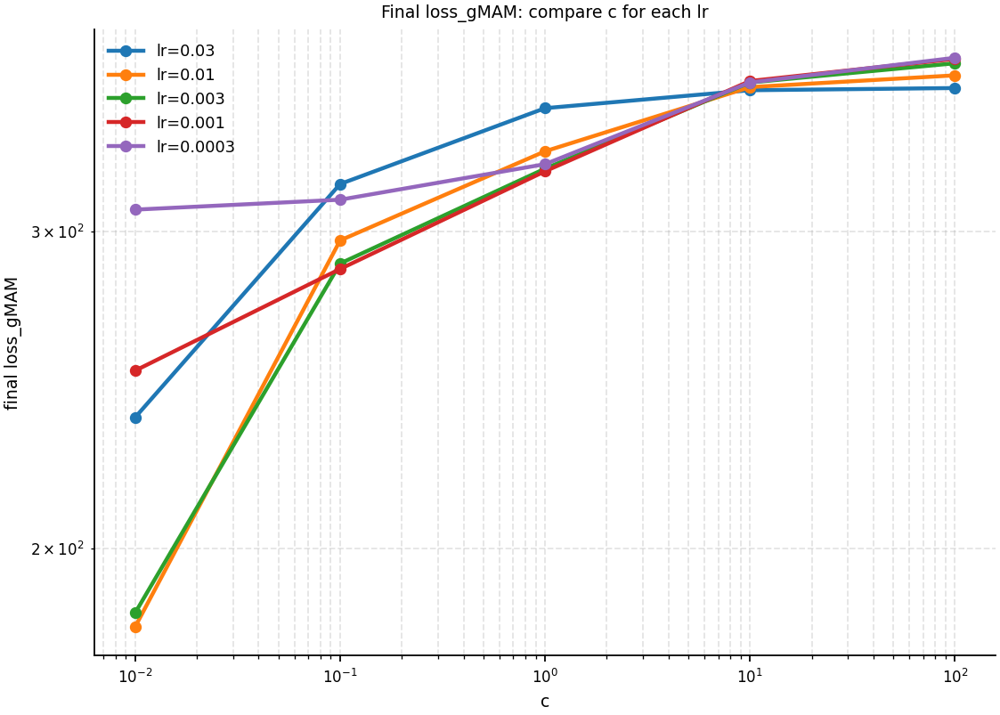

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_lr_by_c/final_loss_gMAM_vs_lr_by_c.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_lr_by_c/final_loss_gMAM_vs_lr_by_c.pdf


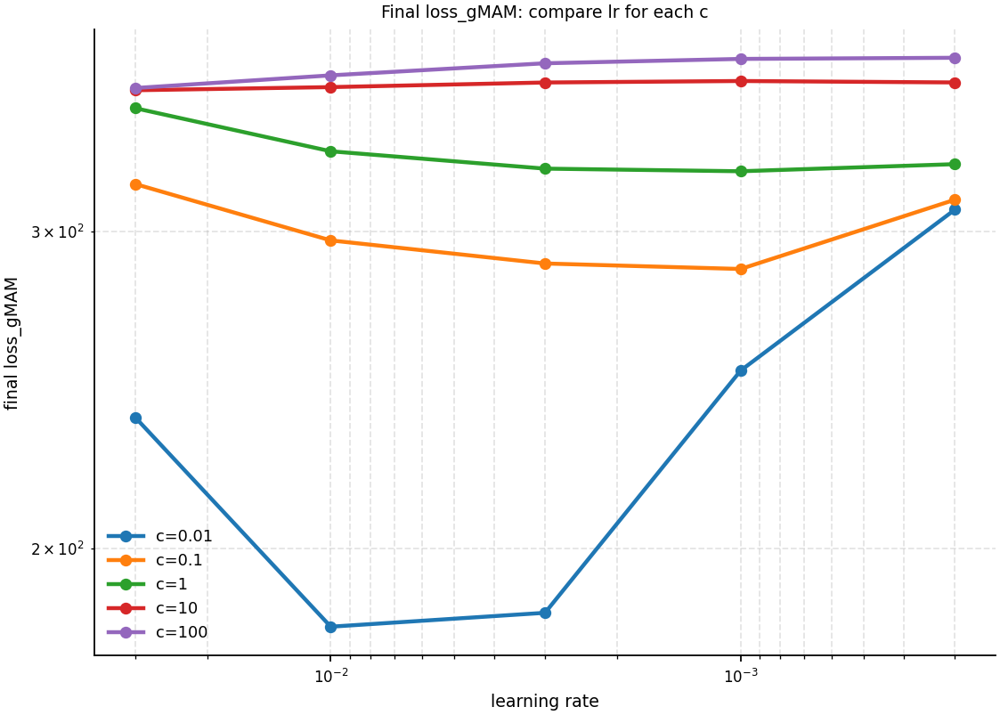

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/heatmaps/final_loss_gMAM_heatmap.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/heatmaps/final_loss_gMAM_heatmap.pdf


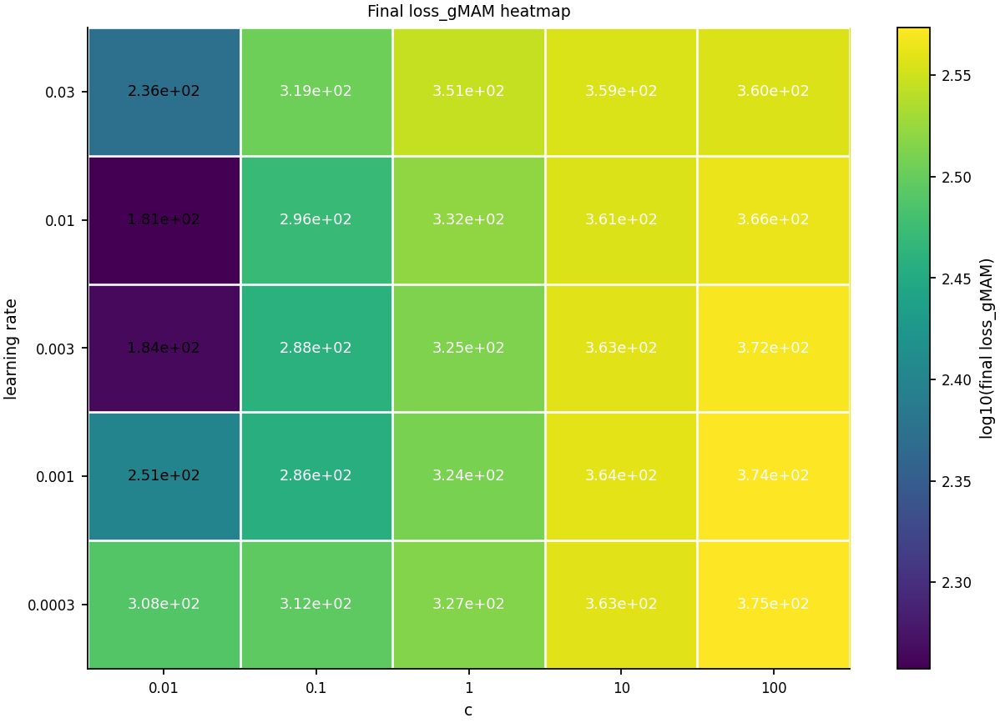


Plotting final metric: loss_perp
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_c_by_lr/final_loss_perp_vs_c_by_lr.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_c_by_lr/final_loss_perp_vs_c_by_lr.pdf


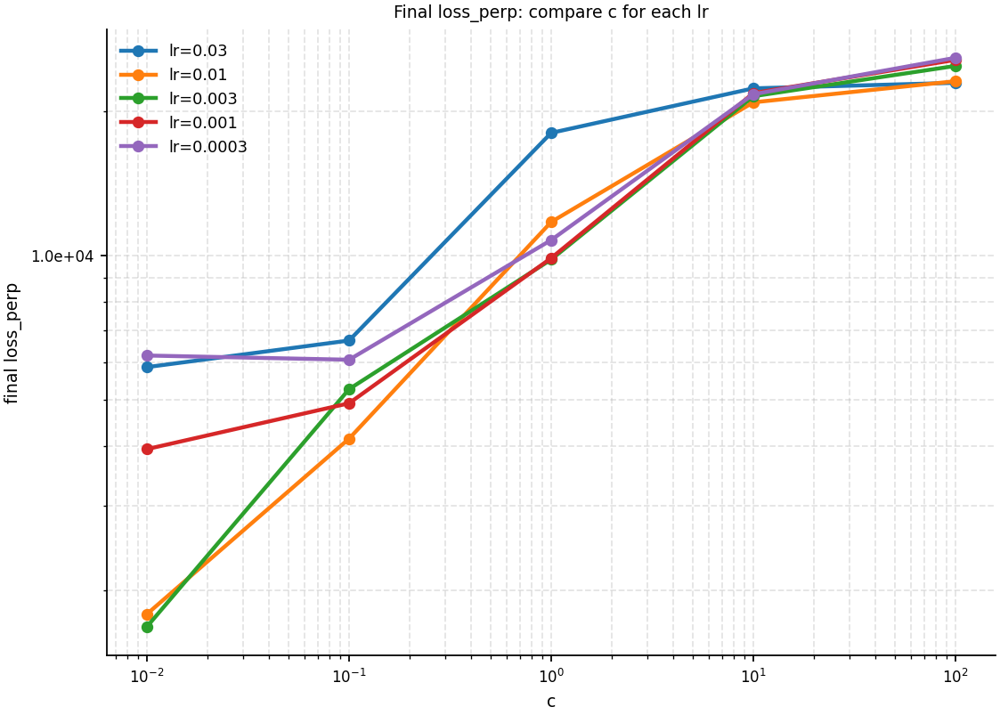

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_lr_by_c/final_loss_perp_vs_lr_by_c.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_lr_by_c/final_loss_perp_vs_lr_by_c.pdf


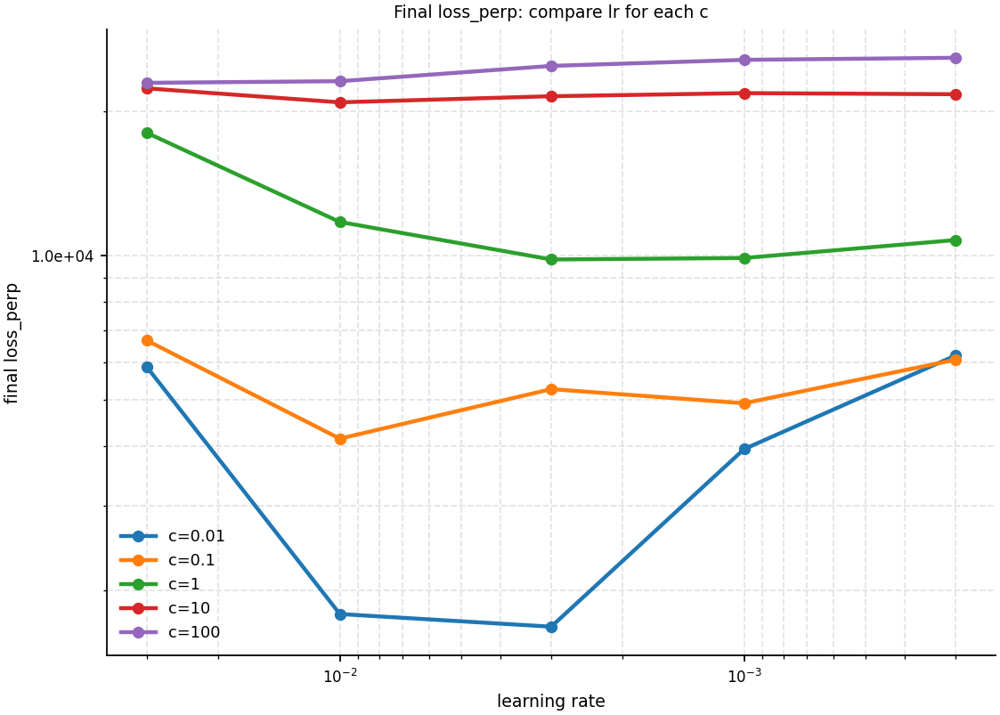

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/heatmaps/final_loss_perp_heatmap.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/heatmaps/final_loss_perp_heatmap.pdf


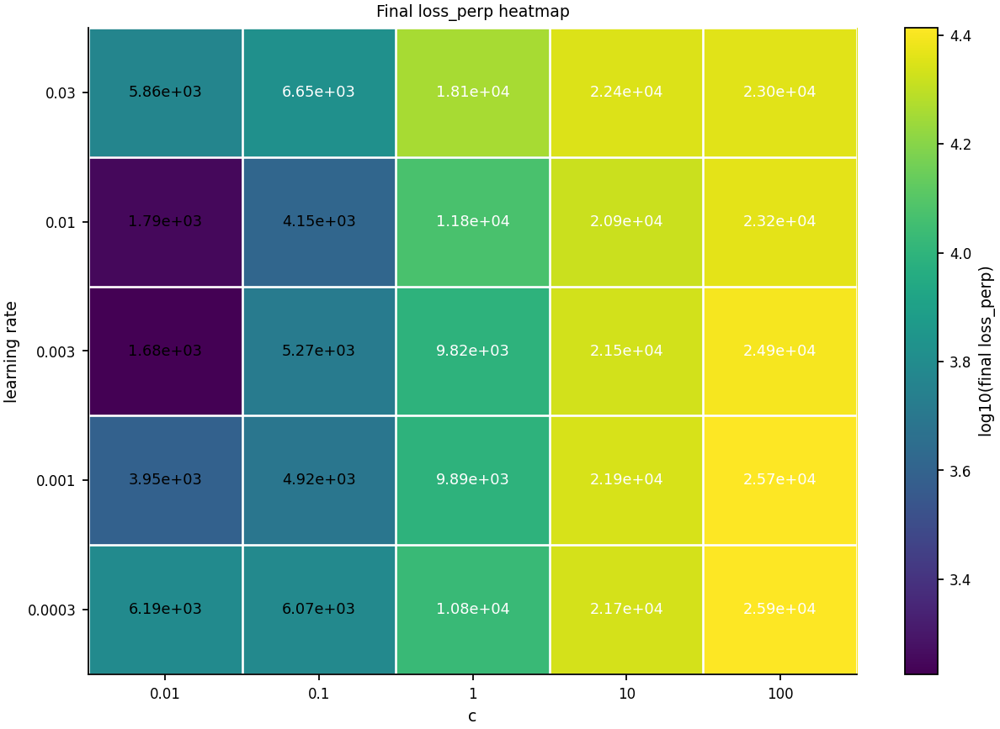


Plotting final metric: F_max
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_c_by_lr/final_F_max_vs_c_by_lr.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_c_by_lr/final_F_max_vs_c_by_lr.pdf


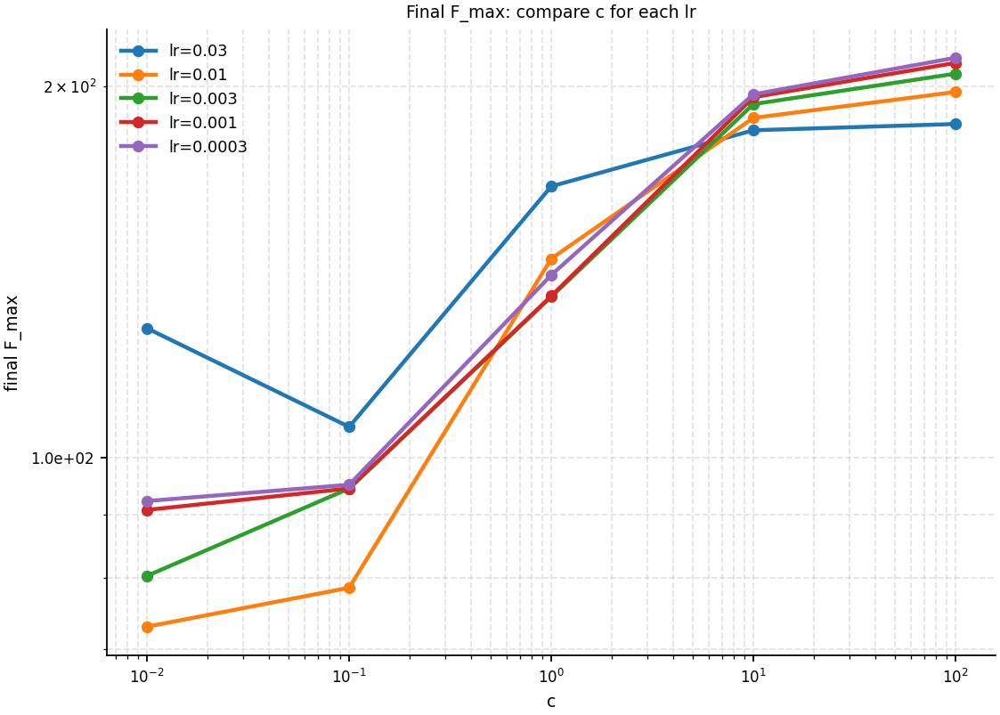

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_lr_by_c/final_F_max_vs_lr_by_c.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_lr_by_c/final_F_max_vs_lr_by_c.pdf


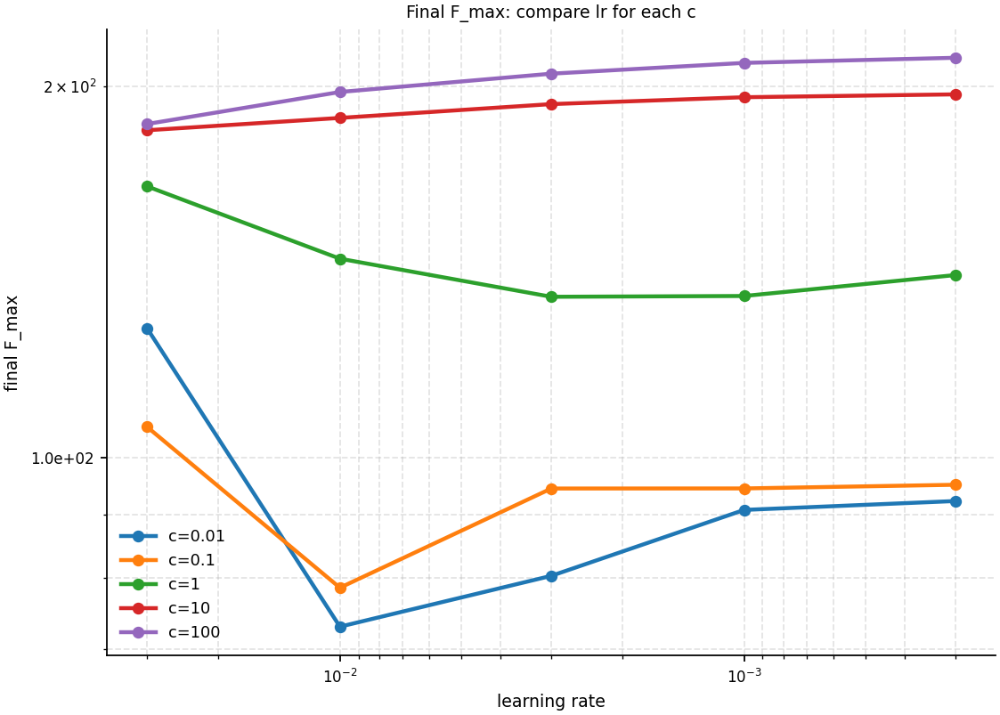

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/heatmaps/final_F_max_heatmap.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/heatmaps/final_F_max_heatmap.pdf


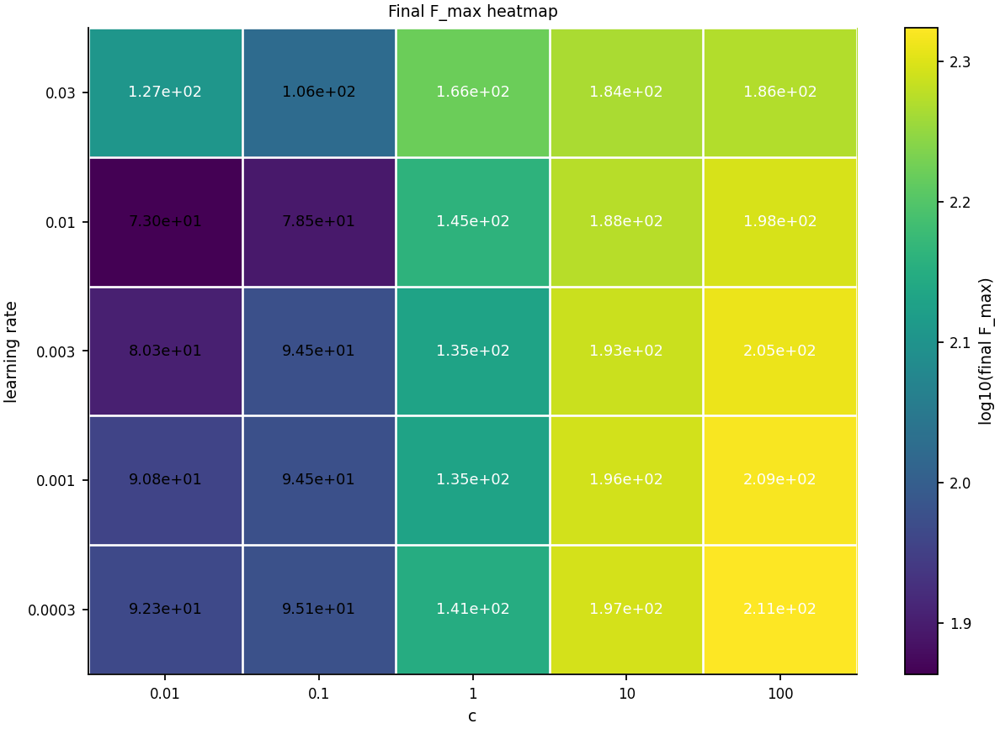


Plotting final metric: loss_arc
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_c_by_lr/final_loss_arc_vs_c_by_lr.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_c_by_lr/final_loss_arc_vs_c_by_lr.pdf


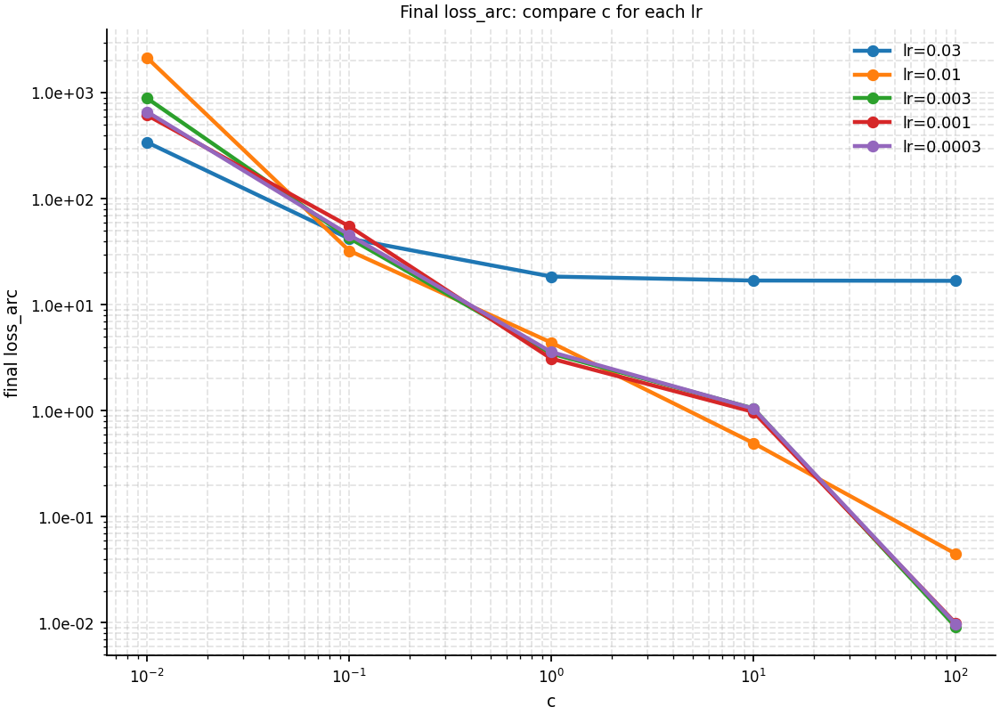

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_lr_by_c/final_loss_arc_vs_lr_by_c.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_lr_by_c/final_loss_arc_vs_lr_by_c.pdf


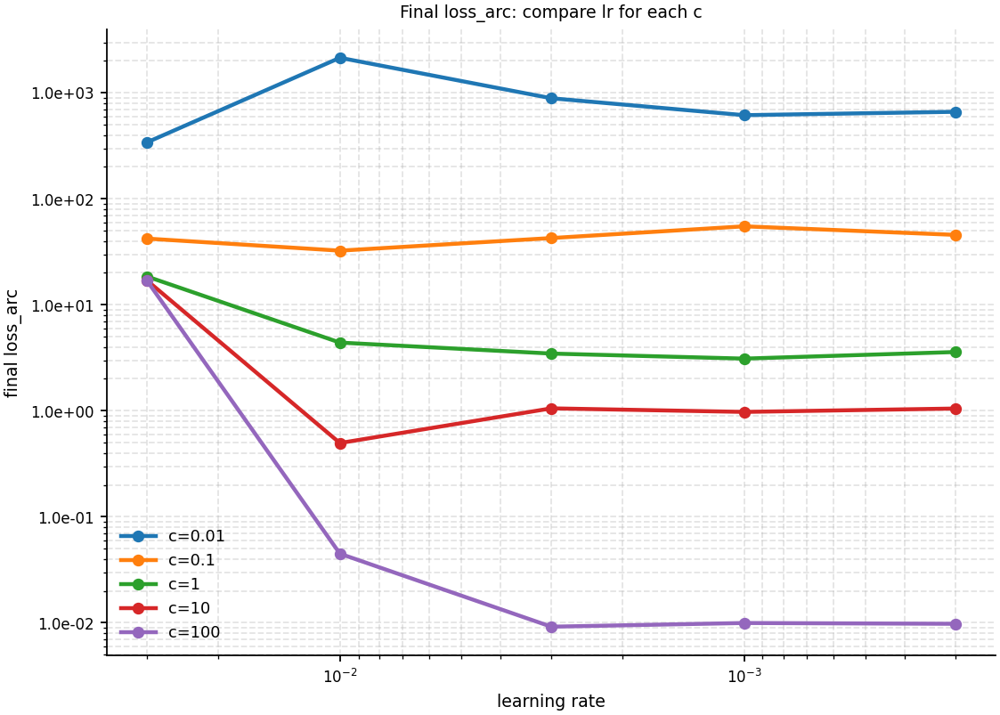

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/heatmaps/final_loss_arc_heatmap.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/heatmaps/final_loss_arc_heatmap.pdf


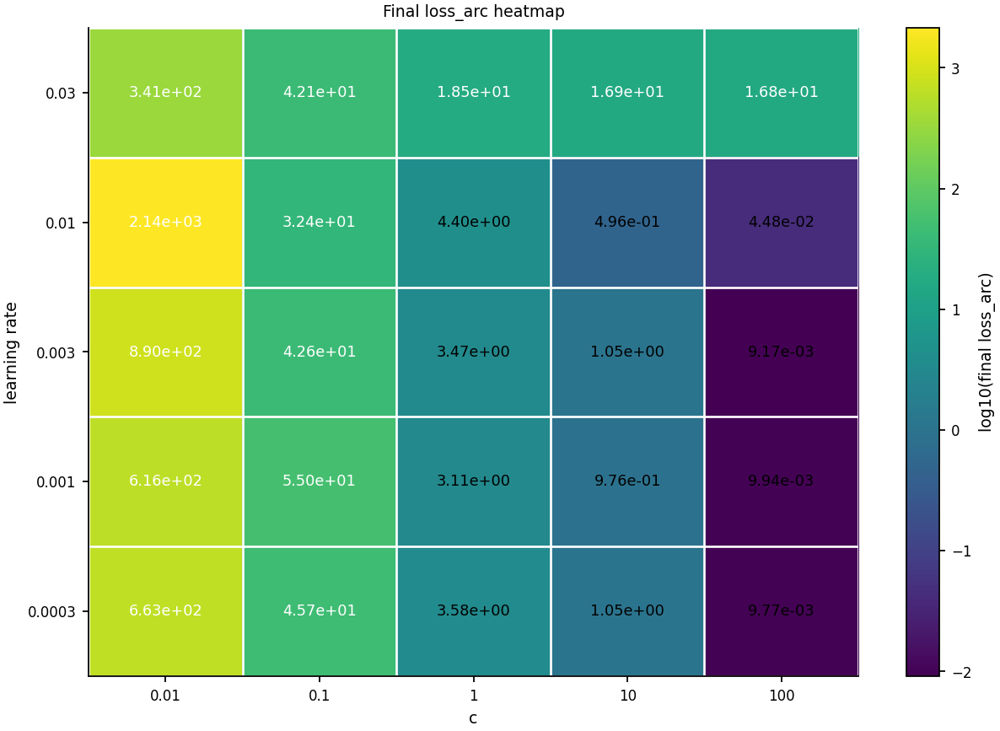


Plotting final metric: Delta_Energy
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_c_by_lr/final_Delta_Energy_vs_c_by_lr.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_c_by_lr/final_Delta_Energy_vs_c_by_lr.pdf


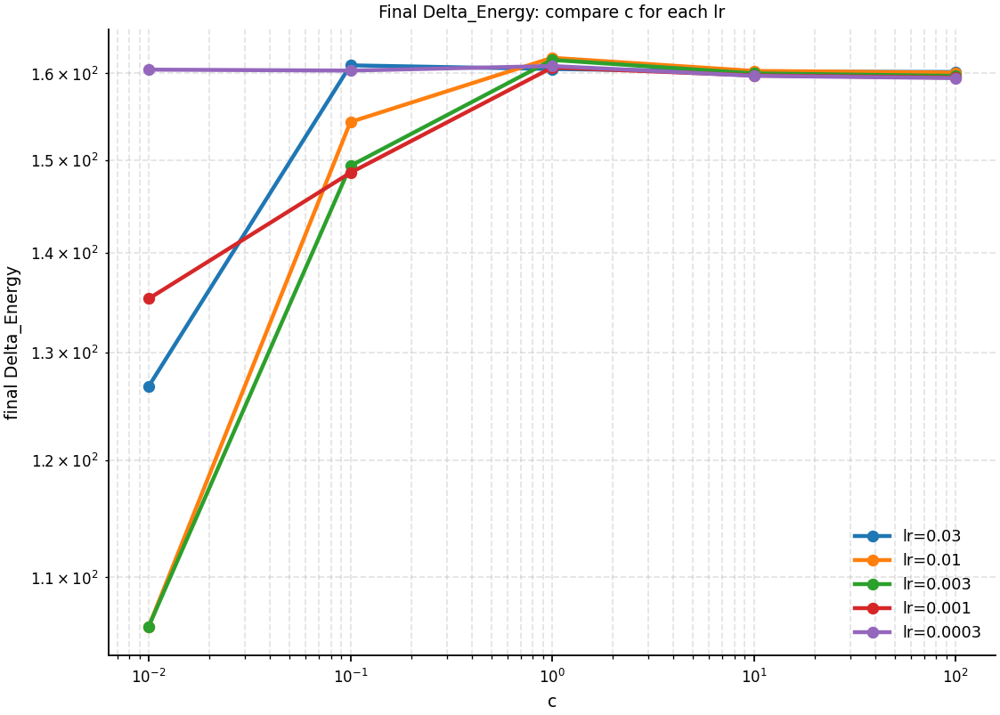

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_lr_by_c/final_Delta_Energy_vs_lr_by_c.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/vs_lr_by_c/final_Delta_Energy_vs_lr_by_c.pdf


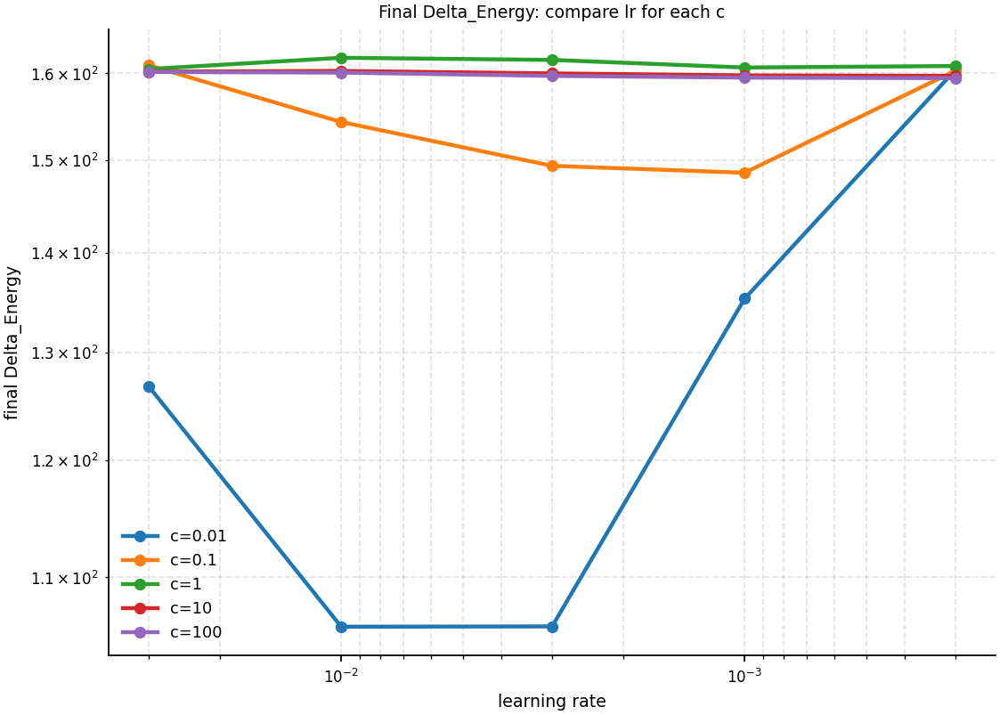

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/heatmaps/final_Delta_Energy_heatmap.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/heatmaps/final_Delta_Energy_heatmap.pdf


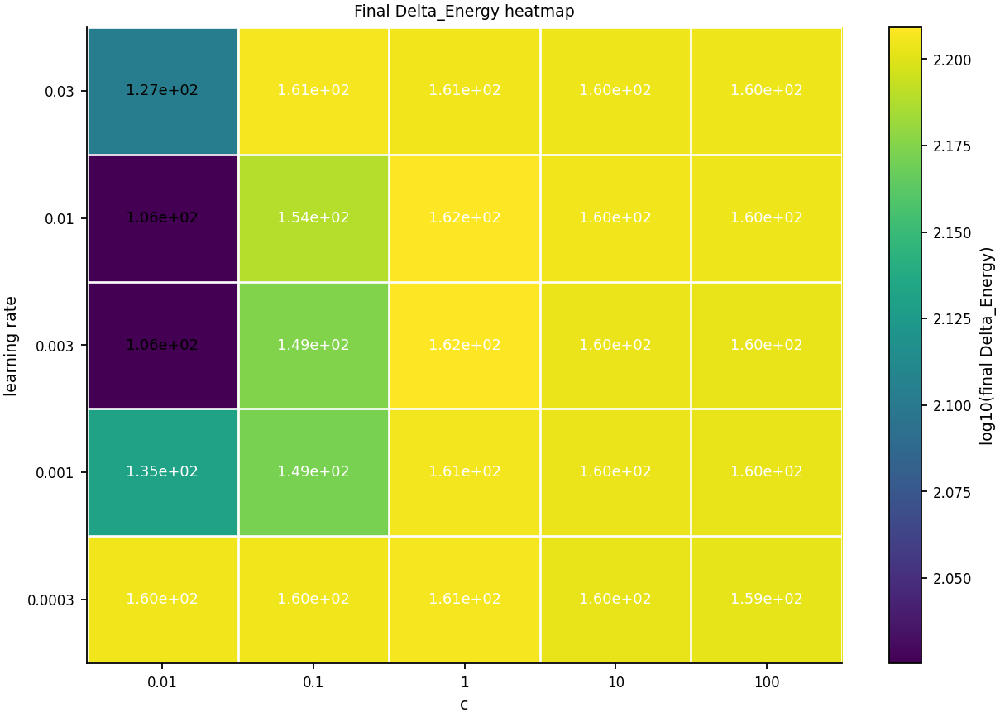

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/ranked/ranked_final_loss_gMAM.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/ranked/ranked_final_loss_gMAM.pdf


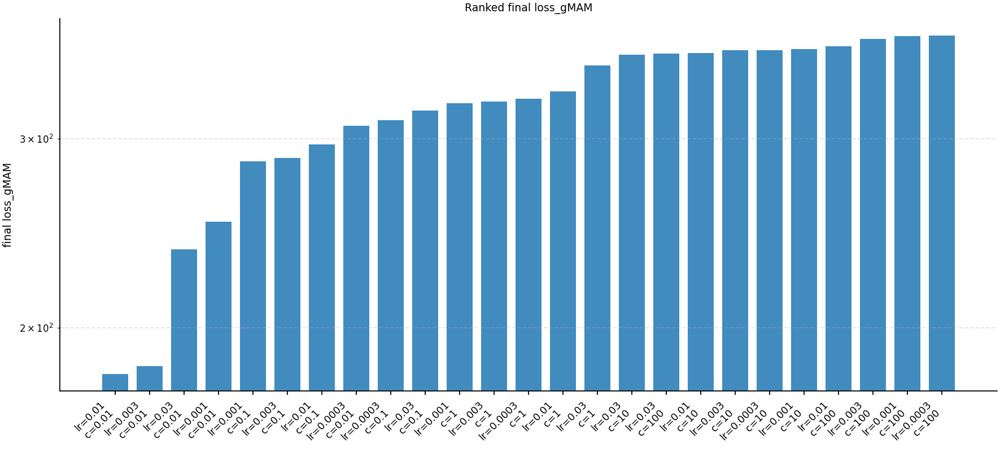

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/ranked/ranked_final_loss_perp.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/ranked/ranked_final_loss_perp.pdf


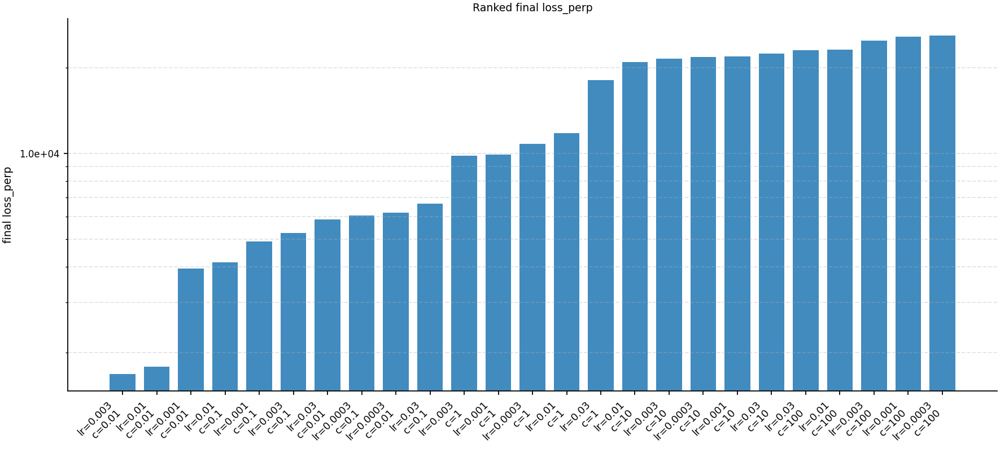

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/ranked/ranked_final_F_max.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/ranked/ranked_final_F_max.pdf


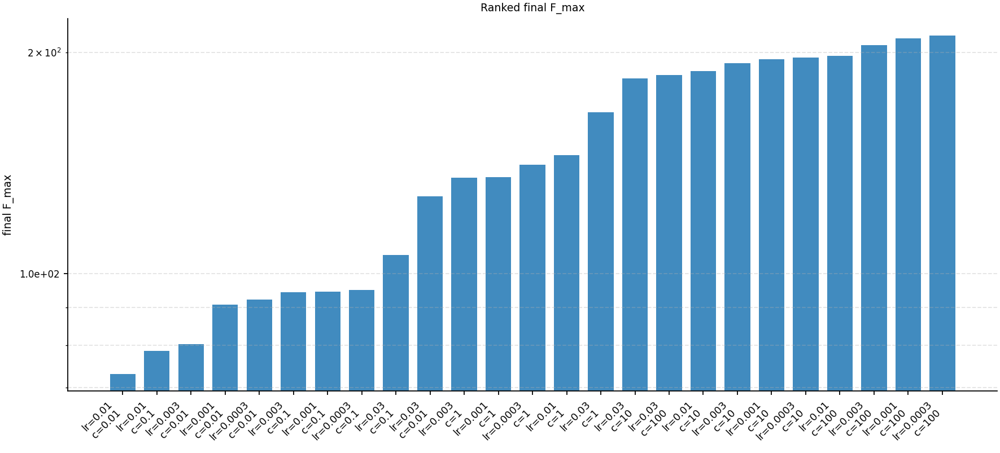

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/ranked/ranked_final_loss_arc.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/ranked/ranked_final_loss_arc.pdf


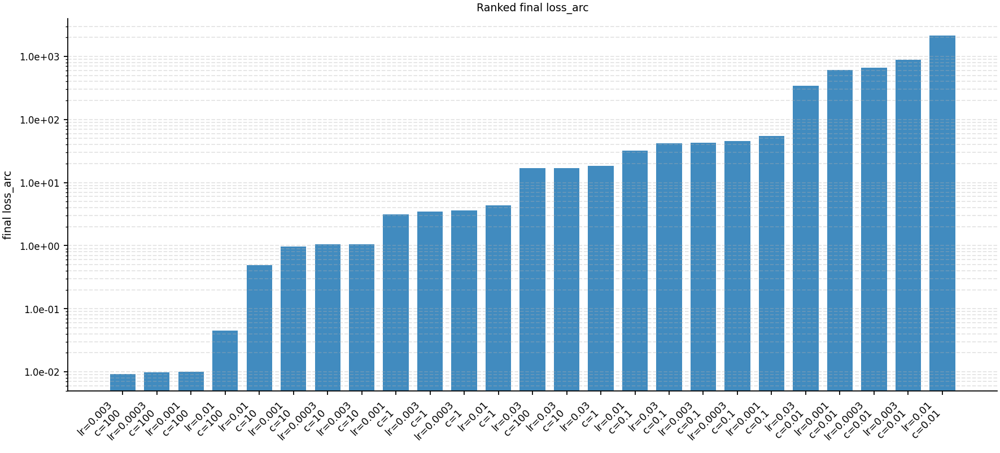

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/ranked/ranked_final_Delta_Energy.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores/ranked/ranked_final_Delta_Energy.pdf


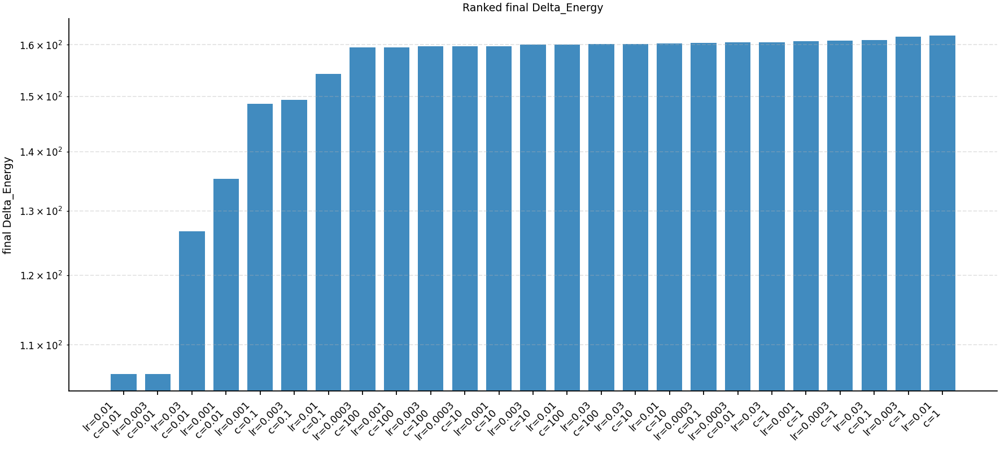


Done.
Figures and CSV saved to:
  /home/zqcai3/wzy/IVP_IVM/comparison_figures/gMAM_final_scores


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import FuncFormatter
import csv


# ============================================================
# 0. 配置区
# ============================================================

base_dir = "/home/zqcai3/wzy/IVP_IVM"

n_images = 20

lr_list = [
    3e-2,
    1e-2,
    3e-3,
    1e-3,
    3e-4,
]

c3_list = [
    1e-2,
    1e-1,
    1e0,
    1e1,
    1e2,
]

save_root = Path(base_dir) / "comparison_figures" / "gMAM_final_scores"

# 是否计算 Delta_Energy
# 如果设为 True，需要前面已经定义 V_muller10_np
INCLUDE_DELTA_ENERGY = True

# 是否显示图片
# 如果在服务器上批量跑，建议设为 False，只保存图片
SHOW_FIGURES = True

# 是否保存 png 和 pdf
SAVE_PNG = True
SAVE_PDF = True


# ============================================================
# 1. 前置检查
# ============================================================

if INCLUDE_DELTA_ENERGY:
    if "V_muller10_np" not in globals():
        raise NameError(
            "INCLUDE_DELTA_ENERGY=True, but `V_muller10_np` is not defined. "
            "Please define V_muller10_np first, or set INCLUDE_DELTA_ENERGY=False."
        )


try:
    trapz = np.trapezoid
except AttributeError:
    trapz = np.trapz


# ============================================================
# 2. 基础工具函数
# ============================================================

def sci_label(v, digits=3):
    """
    科学计数法 label。
    """
    if not np.isfinite(v):
        return "nan"

    if v == 0:
        return "0"

    return f"{v:.{digits}e}"


def float_tag(v):
    """
    用于文件夹名或文件名。
    """
    s = f"{float(v):g}"
    s = s.replace(".", "p")
    s = s.replace("-", "m")
    s = s.replace("+", "")
    return s


def _float_close(a, b, rtol=1e-12, atol=1e-15):
    return np.isclose(float(a), float(b), rtol=rtol, atol=atol)


def _float_in(v, values):
    if values is None:
        return True

    return any(_float_close(v, vv) for vv in values)


def _candidate_float_strings(v):
    """
    为 float 生成多个可能的字符串形式，用来兼容文件名。

    例如:
        0.01 -> ["0.01"]
        1.0  -> ["1.0", "1"]
        10.0 -> ["10.0", "10"]
    """
    candidates = []

    candidates.append(str(v))

    try:
        candidates.append(str(float(v)))
        candidates.append(f"{float(v):g}")
    except Exception:
        pass

    out = []

    for s in candidates:
        if s not in out:
            out.append(s)

    return out


def _get_gmam_data_dir(base_dir, data_subdir="Data"):
    """
    允许 base_dir 传两种形式:

    1. /home/zqcai3/wzy/IVP_IVM
    2. /home/zqcai3/wzy/IVP_IVM/Data
    """
    base_dir = Path(base_dir)

    if base_dir.name == data_subdir:
        return base_dir

    return base_dir / data_subdir


def _find_gmam_file(base_dir, n_images, lr, c3, data_subdir="Data"):
    """
    自动寻找 gMAM npz 文件。

    默认保存格式:

        Data/
          M10_N10_Images_gMAM_lr0.01_c1.0/
            M10_M10_N10_Images_gMAM_lr0.01_c1.0.npz
    """
    data_dir = _get_gmam_data_dir(base_dir, data_subdir=data_subdir)

    lr_candidates = _candidate_float_strings(lr)
    c3_candidates = _candidate_float_strings(c3)

    tried = []

    for lr_s in lr_candidates:
        for c3_s in c3_candidates:

            casenum = f"M10_N{n_images}_Images_gMAM_lr{lr_s}_c{c3_s}"
            file_path = data_dir / casenum / f"M10_{casenum}.npz"

            tried.append((file_path, casenum))

            if file_path.exists():
                return file_path, casenum

    return tried[0]


def evaluate_V_on_points(X_points, V_func):
    """
    在一批点上计算势能。

    优先尝试 V_func(X_points) 向量化；
    如果失败，则退回逐点计算。
    """
    X_points = np.asarray(X_points, dtype=float)

    try:
        V_vals = np.asarray(V_func(X_points), dtype=float).reshape(-1)

        if V_vals.shape[0] == X_points.shape[0]:
            return V_vals

    except Exception:
        pass

    V_vals = np.array([
        float(np.asarray(V_func(xi)))
        for xi in X_points
    ])

    return V_vals


def compute_path_derivatives_single_path(path):
    """
    对单条路径计算 phi_s, phi_ss, speed。

    path: shape (N, d)

    返回:
        s:      shape (N,)
        phi_s:  shape (N, d)
        phi_ss: shape (N, d)
        speed:  shape (N,)
    """
    path = np.asarray(path, dtype=float)

    if path.ndim != 2:
        raise ValueError(f"path must have shape (N, d), got {path.shape}")

    N, d = path.shape

    s = np.linspace(0.0, 1.0, N)

    edge_order = 2 if N >= 3 else 1

    phi_s = np.gradient(path, s, axis=0, edge_order=edge_order)
    phi_ss = np.gradient(phi_s, s, axis=0, edge_order=edge_order)

    speed = np.linalg.norm(phi_s, axis=1)

    return s, phi_s, phi_ss, speed


def line_integral_force_quantity_single_path(q_force, speed, N_path):
    """
    对单条路径上定义的 quantity 做 line integral。

    q_force: shape (N_force,)
        例如 |F_perp|^2 或 |F_original|。

    speed: shape (N_path,)
        从最终路径算出的 |phi'(s)|。

    N_path:
        最终路径点数，包括两个端点。

    支持三种常见情况:

    1. N_force == N_path - 2
       force 只在内部点。

    2. N_force == N_path - 1
       gMAM 当前常见保存方式：
       force 在 [x0, P0, ..., P_{N-1}] 上，不包含最后 endpoint x1。

    3. N_force == N_path
       force 在完整路径上都有。
    """
    q_force = np.asarray(q_force, dtype=float).reshape(-1)
    speed = np.asarray(speed, dtype=float).reshape(-1)

    N_force = q_force.shape[0]

    ds = 1.0 / (N_path - 1)

    if N_force == N_path - 2:
        speed_force = speed[1:-1]
        return np.sum(q_force * speed_force) * ds

    elif N_force == N_path - 1:
        speed_force = speed[:-1]
        return np.sum(q_force * speed_force) * ds

    elif N_force == N_path:
        s = np.linspace(0.0, 1.0, N_path)
        return trapz(q_force * speed, s)

    else:
        # 兜底：force 网格数和 path 网格数不匹配时，插值 speed
        s_path = np.linspace(0.0, 1.0, N_path)
        s_force = np.linspace(0.0, 1.0, N_force)

        speed_force = np.interp(s_force, s_path, speed)

        return trapz(q_force * speed_force, s_force)


def compute_delta_energy_final(
    final_path,
    initial_path,
    V_func,
    dense_n=500,
    E_min=None,
):
    """
    计算最终路径的能垒:

        Delta_Energy = max_s V(phi_final(s)) - E_min

    默认:

        E_min = min V(initial_path)

    这样和之前的代码逻辑保持一致。
    """
    final_path = np.asarray(final_path, dtype=float)
    initial_path = np.asarray(initial_path, dtype=float)

    if final_path.ndim != 2:
        raise ValueError(
            f"final_path must have shape (N, d), got {final_path.shape}"
        )

    if initial_path.ndim != 2:
        raise ValueError(
            f"initial_path must have shape (N, d), got {initial_path.shape}"
        )

    N, d = final_path.shape

    if E_min is None:
        E0 = evaluate_V_on_points(initial_path, V_func)
        E_min = np.min(E0)

    t_old = np.linspace(0.0, 1.0, N)
    t_new = np.linspace(0.0, 1.0, dense_n)

    X_dense = np.column_stack([
        np.interp(t_new, t_old, final_path[:, dim])
        for dim in range(d)
    ])

    E_dense = evaluate_V_on_points(X_dense, V_func)

    Delta_Energy = np.max(E_dense) - E_min

    return float(Delta_Energy)


# ============================================================
# 3. 读取 gMAM 数据
# ============================================================

def load_gmam_runs(
    base_dir,
    n_images,
    lr_list,
    c3_list,
    data_subdir="Data",
    allow_missing=True,
):
    """
    读取所有 gMAM 实验数据。

    每个 run 包含:
        method
        label
        lr
        c3
        file
        images_seq
        count_seq
        F_perp
        F_original
        fmaxs
    """
    runs = []

    for lr in lr_list:
        for c3 in c3_list:

            file_path, casenum = _find_gmam_file(
                base_dir=base_dir,
                n_images=n_images,
                lr=lr,
                c3=c3,
                data_subdir=data_subdir,
            )

            if not file_path.exists():
                msg = f"[Missing gMAM file] lr={lr:g}, c3={c3:g}\n  {file_path}"

                if allow_missing:
                    print(msg)
                    continue
                else:
                    raise FileNotFoundError(msg)

            loaded = np.load(file_path, allow_pickle=True)

            required_keys = [
                "images_seq",
                "count_seq",
                "F_perp",
                "F_original",
            ]

            missing_keys = [
                k for k in required_keys
                if k not in loaded.files
            ]

            if len(missing_keys) > 0:
                msg = (
                    f"[Skip] file missing keys {missing_keys}: \n"
                    f"  {file_path}"
                )

                if allow_missing:
                    print(msg)
                    continue
                else:
                    raise KeyError(msg)

            run = {
                "method": "gMAM",
                "label": f"gMAM, lr={lr:g}, c={c3:g}",
                "lr": float(lr),
                "c3": float(c3),
                "file": file_path,
                "images_seq": loaded["images_seq"],
                "count_seq": loaded["count_seq"],
                "F_perp": loaded["F_perp"],
                "F_original": loaded["F_original"],
            }

            if "fmaxs" in loaded.files:
                run["fmaxs"] = loaded["fmaxs"]
            else:
                run["fmaxs"] = None

            runs.append(run)

    print(f"\nLoaded {len(runs)} gMAM runs.")

    return runs


# ============================================================
# 4. 只计算最终指标
# ============================================================

def compute_final_metrics_for_run(
    run,
    V_func=None,
    include_delta_energy=True,
    dense_n_energy=500,
    fmax_mode="saved_or_norm",
):
    """
    只计算某个 run 的最终指标。

    输出 dict:
        final_count
        loss_gMAM
        loss_perp
        F_max
        loss_arc
        Delta_Energy, optional
    """
    images_seq = np.asarray(run["images_seq"], dtype=float)
    count_seq = np.asarray(run["count_seq"])
    F_perp = np.asarray(run["F_perp"], dtype=float)
    F_original = np.asarray(run["F_original"], dtype=float)

    saved_fmaxs = run.get("fmaxs", None)

    if saved_fmaxs is not None:
        saved_fmaxs = np.asarray(saved_fmaxs, dtype=float)

    if images_seq.ndim != 3:
        raise ValueError(
            f"images_seq must have shape (T, N, d), got {images_seq.shape}"
        )

    if F_perp.ndim != 3:
        raise ValueError(
            f"F_perp must have shape (T, N_force, d), got {F_perp.shape}"
        )

    if F_original.ndim != 3:
        raise ValueError(
            f"F_original must have shape (T, N_force, d), got {F_original.shape}"
        )

    lengths = [
        images_seq.shape[0],
        count_seq.reshape(-1).shape[0],
        F_perp.shape[0],
        F_original.shape[0],
    ]

    if saved_fmaxs is not None:
        lengths.append(saved_fmaxs.reshape(-1).shape[0])

    T = min(lengths)

    if T <= 0:
        raise ValueError(f"Empty sequence in run: {run['label']}")

    images_seq = images_seq[:T]
    count_seq = count_seq.reshape(-1)[:T]
    F_perp = F_perp[:T]
    F_original = F_original[:T]

    if saved_fmaxs is not None:
        saved_fmaxs = saved_fmaxs.reshape(-1)[:T]

    initial_path = images_seq[0]
    final_path = images_seq[-1]

    final_F_perp = F_perp[-1]
    final_F_original = F_original[-1]

    final_count = count_seq[-1]

    N_path = final_path.shape[0]

    s, phi_s, phi_ss, speed = compute_path_derivatives_single_path(final_path)

    # ------------------------------------------------------------
    # loss_gMAM = integral |nabla U(phi)| |phi'(s)| ds
    # 这里沿用之前逻辑，F_original_norm 表示原始 force/gradient 的范数。
    # ------------------------------------------------------------
    F_original_norm = np.linalg.norm(final_F_original, axis=1)

    loss_gMAM = line_integral_force_quantity_single_path(
        q_force=F_original_norm,
        speed=speed,
        N_path=N_path,
    )

    # ------------------------------------------------------------
    # loss_perp = integral |F_perp|^2 |phi'(s)| ds
    # ------------------------------------------------------------
    F_perp_norm_sq = np.sum(final_F_perp ** 2, axis=1)

    loss_perp = line_integral_force_quantity_single_path(
        q_force=F_perp_norm_sq,
        speed=speed,
        N_path=N_path,
    )

    # ------------------------------------------------------------
    # F_max
    # ------------------------------------------------------------
    if fmax_mode == "saved_or_norm":
        if saved_fmaxs is not None:
            F_max = saved_fmaxs[-1]
        else:
            F_max = np.max(np.linalg.norm(final_F_perp, axis=1))

    elif fmax_mode == "saved":
        if saved_fmaxs is None:
            raise ValueError("fmax_mode='saved' but saved_fmaxs is None.")
        F_max = saved_fmaxs[-1]

    elif fmax_mode == "norm":
        F_max = np.max(np.linalg.norm(final_F_perp, axis=1))

    elif fmax_mode == "direct":
        F_max = np.max(final_F_perp)

    elif fmax_mode == "abs":
        F_max = np.max(np.abs(final_F_perp))

    else:
        raise ValueError(
            "fmax_mode must be one of: "
            "'saved_or_norm', 'saved', 'norm', 'direct', 'abs'."
        )

    # ------------------------------------------------------------
    # loss_arc = integral (<phi'(s), phi''(s)>)^2 |phi'(s)| ds
    # ------------------------------------------------------------
    inner_phi_s_phi_ss = np.sum(phi_s * phi_ss, axis=1)
    arc_integrand = inner_phi_s_phi_ss ** 2 * speed

    loss_arc = trapz(arc_integrand, s)

    metrics = {
        "final_count": float(final_count),
        "loss_gMAM": float(loss_gMAM),
        "loss_perp": float(loss_perp),
        "F_max": float(F_max),
        "loss_arc": float(loss_arc),
    }

    # ------------------------------------------------------------
    # Delta_Energy
    # ------------------------------------------------------------
    if include_delta_energy:
        if V_func is None:
            raise ValueError(
                "include_delta_energy=True but V_func is None."
            )

        Delta_Energy = compute_delta_energy_final(
            final_path=final_path,
            initial_path=initial_path,
            V_func=V_func,
            dense_n=dense_n_energy,
            E_min=None,
        )

        metrics["Delta_Energy"] = float(Delta_Energy)

    return metrics


def compute_all_final_metrics(
    gmam_runs,
    include_delta_energy=True,
    V_func=None,
    dense_n_energy=500,
):
    """
    为所有 gMAM runs 计算最终指标。
    """
    for run in gmam_runs:
        print("Processing final metrics:", run["label"])
        print("File:", run["file"])

        run["final_metrics"] = compute_final_metrics_for_run(
            run=run,
            V_func=V_func,
            include_delta_energy=include_delta_energy,
            dense_n_energy=dense_n_energy,
            fmax_mode="saved_or_norm",
        )

    return gmam_runs


# ============================================================
# 5. 整理最终成绩表格
# ============================================================

def get_metric_names(include_delta_energy=True):
    metric_names = [
        "loss_gMAM",
        "loss_perp",
        "F_max",
        "loss_arc",
    ]

    if include_delta_energy:
        metric_names.append("Delta_Energy")

    return metric_names


def build_final_records(gmam_runs, include_delta_energy=True):
    """
    把所有 run 的最终成绩整理为 list[dict]。
    """
    metric_names = get_metric_names(include_delta_energy=include_delta_energy)

    records = []

    for run in gmam_runs:
        if "final_metrics" not in run:
            continue

        m = run["final_metrics"]

        record = {
            "lr": float(run["lr"]),
            "c3": float(run["c3"]),
            "final_count": float(m["final_count"]),
            "file": str(run["file"]),
        }

        for metric_name in metric_names:
            record[metric_name] = float(m[metric_name])

        records.append(record)

    return records


def print_final_summary(records, sort_by="loss_perp", include_delta_energy=True):
    """
    打印最终指标 summary。
    """
    if len(records) == 0:
        print("No records.")
        return

    metric_names = get_metric_names(include_delta_energy=include_delta_energy)

    if sort_by not in metric_names:
        raise ValueError(f"sort_by must be one of {metric_names}")

    records_sorted = sorted(records, key=lambda r: r[sort_by])

    header_parts = [
        f"{'lr':>10}",
        f"{'c3':>10}",
        f"{'count':>10}",
    ]

    for metric_name in metric_names:
        header_parts.append(f"{metric_name:>16}")

    header = "  ".join(header_parts)

    print("\nSorted by:", sort_by)
    print(header)
    print("-" * len(header))

    for r in records_sorted:
        row_parts = [
            f"{r['lr']:10.3g}",
            f"{r['c3']:10.3g}",
            f"{r['final_count']:10.0f}",
        ]

        for metric_name in metric_names:
            row_parts.append(f"{r[metric_name]:16.6e}")

        print("  ".join(row_parts))


def save_final_records_csv(
    records,
    save_path,
    include_delta_energy=True,
):
    """
    保存最终指标为 CSV。
    """
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    metric_names = get_metric_names(include_delta_energy=include_delta_energy)

    fieldnames = [
        "lr",
        "c3",
        "final_count",
    ] + metric_names + [
        "file",
    ]

    with open(save_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

        for r in records:
            writer.writerow(r)

    print(f"\nSaved CSV:\n  {save_path}")


# ============================================================
# 6. 从 records 里提取数据
# ============================================================

def find_record(records, lr, c3):
    """
    根据 lr 和 c3 找对应 record。
    """
    for r in records:
        if _float_close(r["lr"], lr) and _float_close(r["c3"], c3):
            return r

    return None


def get_metric_grid(records, lr_list, c3_list, metric_name):
    """
    构造矩阵:

        rows = lr_list
        cols = c3_list

    grid[i, j] = metric(lr_i, c3_j)
    """
    grid = np.full((len(lr_list), len(c3_list)), np.nan, dtype=float)

    for i, lr in enumerate(lr_list):
        for j, c3 in enumerate(c3_list):
            r = find_record(records, lr, c3)

            if r is not None:
                grid[i, j] = r[metric_name]

    return grid


def get_line_vs_c3(records, lr, c3_list, metric_name):
    """
    固定 lr，取不同 c3 下的 metric。
    """
    xs = []
    ys = []

    for c3 in c3_list:
        r = find_record(records, lr, c3)

        if r is None:
            continue

        y = r[metric_name]

        if np.isfinite(y):
            xs.append(float(c3))
            ys.append(float(y))

    return np.asarray(xs), np.asarray(ys)


def get_line_vs_lr(records, c3, lr_list, metric_name):
    """
    固定 c3，取不同 lr 下的 metric。
    """
    xs = []
    ys = []

    for lr in lr_list:
        r = find_record(records, lr, c3)

        if r is None:
            continue

        y = r[metric_name]

        if np.isfinite(y):
            xs.append(float(lr))
            ys.append(float(y))

    return np.asarray(xs), np.asarray(ys)


# ============================================================
# 7. 画图工具
# ============================================================

def log_tick_formatter(y, pos=None):
    if not np.isfinite(y) or y <= 0:
        return ""

    return f"{y:.1e}"


def save_figure(fig, save_path_without_suffix):
    """
    保存 png/pdf。
    """
    save_path_without_suffix = Path(save_path_without_suffix)
    save_path_without_suffix.parent.mkdir(parents=True, exist_ok=True)

    if SAVE_PNG:
        png_path = save_path_without_suffix.with_suffix(".png")
        fig.savefig(png_path, bbox_inches="tight", dpi=300)
        print(f"Saved: {png_path}")

    if SAVE_PDF:
        pdf_path = save_path_without_suffix.with_suffix(".pdf")
        fig.savefig(pdf_path, bbox_inches="tight")
        print(f"Saved: {pdf_path}")


def set_log_axis_if_positive(ax, x_values=None, y_values=None, xlog=False, ylog=True):
    """
    如果数据全为正，则使用 log scale。
    """
    if xlog and x_values is not None:
        x_values = np.asarray(x_values, dtype=float)
        x_valid = x_values[np.isfinite(x_values)]

        if x_valid.size > 0 and np.all(x_valid > 0):
            ax.set_xscale("log")

    if ylog and y_values is not None:
        y_values = np.asarray(y_values, dtype=float)
        y_valid = y_values[np.isfinite(y_values)]

        if y_valid.size > 0 and np.all(y_valid > 0):
            ax.set_yscale("log")
            ax.yaxis.set_major_formatter(FuncFormatter(log_tick_formatter))


def plot_final_vs_c3_by_lr(
    records,
    lr_list,
    c3_list,
    metric_name,
    save_dir,
    show=True,
):
    """
    固定 lr，横轴 c3，比较最终 metric。
    """
    fig, ax = plt.subplots(figsize=(7.2, 5.2), dpi=160)

    all_x = []
    all_y = []

    for lr in lr_list:
        x, y = get_line_vs_c3(
            records=records,
            lr=lr,
            c3_list=c3_list,
            metric_name=metric_name,
        )

        if len(x) == 0:
            continue

        all_x.append(x)
        all_y.append(y)

        ax.plot(
            x,
            y,
            marker="o",
            linewidth=2.0,
            markersize=5,
            label=f"lr={lr:g}",
        )

    if len(all_x) > 0:
        all_x = np.concatenate(all_x)
        all_y = np.concatenate(all_y)

        set_log_axis_if_positive(
            ax,
            x_values=all_x,
            y_values=all_y,
            xlog=True,
            ylog=True,
        )

    ax.set_xlabel("c")
    ax.set_ylabel(f"final {metric_name}")
    ax.set_title(f"Final {metric_name}: compare c for each lr")

    ax.grid(True, which="both", linestyle="--", alpha=0.35)
    ax.legend(fontsize=8)

    fig.tight_layout()

    save_figure(
        fig,
        Path(save_dir) / f"final_{metric_name}_vs_c_by_lr",
    )

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig, ax


def plot_final_vs_lr_by_c3(
    records,
    lr_list,
    c3_list,
    metric_name,
    save_dir,
    show=True,
):
    """
    固定 c3，横轴 lr，比较最终 metric。
    """
    fig, ax = plt.subplots(figsize=(7.2, 5.2), dpi=160)

    all_x = []
    all_y = []

    for c3 in c3_list:
        x, y = get_line_vs_lr(
            records=records,
            c3=c3,
            lr_list=lr_list,
            metric_name=metric_name,
        )

        if len(x) == 0:
            continue

        all_x.append(x)
        all_y.append(y)

        ax.plot(
            x,
            y,
            marker="o",
            linewidth=2.0,
            markersize=5,
            label=f"c={c3:g}",
        )

    if len(all_x) > 0:
        all_x = np.concatenate(all_x)
        all_y = np.concatenate(all_y)

        set_log_axis_if_positive(
            ax,
            x_values=all_x,
            y_values=all_y,
            xlog=True,
            ylog=True,
        )

    # 一般我们希望 lr 从大到小看，所以把 x 轴反过来
    ax.invert_xaxis()

    ax.set_xlabel("learning rate")
    ax.set_ylabel(f"final {metric_name}")
    ax.set_title(f"Final {metric_name}: compare lr for each c")

    ax.grid(True, which="both", linestyle="--", alpha=0.35)
    ax.legend(fontsize=8)

    fig.tight_layout()

    save_figure(
        fig,
        Path(save_dir) / f"final_{metric_name}_vs_lr_by_c",
    )

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig, ax


def plot_final_metric_heatmap(
    records,
    lr_list,
    c3_list,
    metric_name,
    save_dir,
    show=True,
    cmap_name="viridis",
):
    """
    画 lr × c3 的最终 metric heatmap。

    显示的是 log10(metric)，格子里标注原始 metric 数值。
    """
    grid = get_metric_grid(
        records=records,
        lr_list=lr_list,
        c3_list=c3_list,
        metric_name=metric_name,
    )

    log_grid = np.full_like(grid, np.nan, dtype=float)

    positive_mask = np.isfinite(grid) & (grid > 0)
    log_grid[positive_mask] = np.log10(grid[positive_mask])

    masked_log_grid = np.ma.masked_invalid(log_grid)

    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad(color="lightgray")

    fig, ax = plt.subplots(figsize=(8.0, 5.6), dpi=160)

    im = ax.imshow(
        masked_log_grid,
        cmap=cmap,
        aspect="auto",
        origin="upper",
    )

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(f"log10(final {metric_name})")

    ax.set_xticks(np.arange(len(c3_list)))
    ax.set_yticks(np.arange(len(lr_list)))

    ax.set_xticklabels([f"{c3:g}" for c3 in c3_list])
    ax.set_yticklabels([f"{lr:g}" for lr in lr_list])

    ax.set_xlabel("c")
    ax.set_ylabel("learning rate")
    ax.set_title(f"Final {metric_name} heatmap")

    # 网格线
    ax.set_xticks(np.arange(len(c3_list) + 1) - 0.5, minor=True)
    ax.set_yticks(np.arange(len(lr_list) + 1) - 0.5, minor=True)
    ax.grid(which="minor", color="white", linestyle="-", linewidth=1.2)
    ax.tick_params(which="minor", bottom=False, left=False)

    # 标注原始值
    finite_log = log_grid[np.isfinite(log_grid)]

    if finite_log.size > 0:
        log_mid = 0.5 * (np.nanmin(finite_log) + np.nanmax(finite_log))
    else:
        log_mid = 0.0

    for i in range(len(lr_list)):
        for j in range(len(c3_list)):
            v = grid[i, j]
            lv = log_grid[i, j]

            if np.isfinite(v):
                text_color = "white" if np.isfinite(lv) and lv > log_mid else "black"

                ax.text(
                    j,
                    i,
                    sci_label(v, digits=2),
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=text_color,
                )
            else:
                ax.text(
                    j,
                    i,
                    "missing",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="black",
                )

    fig.tight_layout()

    save_figure(
        fig,
        Path(save_dir) / f"final_{metric_name}_heatmap",
    )

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig, ax


def plot_all_final_score_figures(
    records,
    lr_list,
    c3_list,
    save_root,
    include_delta_energy=True,
    show=True,
):
    """
    对所有最终指标画图。
    """
    save_root = Path(save_root)

    metric_names = get_metric_names(include_delta_energy=include_delta_energy)

    for metric_name in metric_names:

        print(f"\nPlotting final metric: {metric_name}")

        # 1. 固定 lr，比 c
        plot_final_vs_c3_by_lr(
            records=records,
            lr_list=lr_list,
            c3_list=c3_list,
            metric_name=metric_name,
            save_dir=save_root / "vs_c_by_lr",
            show=show,
        )

        # 2. 固定 c，比 lr
        plot_final_vs_lr_by_c3(
            records=records,
            lr_list=lr_list,
            c3_list=c3_list,
            metric_name=metric_name,
            save_dir=save_root / "vs_lr_by_c",
            show=show,
        )

        # 3. heatmap
        plot_final_metric_heatmap(
            records=records,
            lr_list=lr_list,
            c3_list=c3_list,
            metric_name=metric_name,
            save_dir=save_root / "heatmaps",
            show=show,
            cmap_name="viridis",
        )


# ============================================================
# 8. 额外：画一个综合排名图
# ============================================================

def plot_ranked_final_metric(
    records,
    metric_name,
    save_dir,
    show=True,
    smaller_is_better=True,
):
    """
    把所有参数组合按照某个最终 metric 排序，画成 bar plot。
    """
    valid_records = [
        r for r in records
        if metric_name in r and np.isfinite(r[metric_name])
    ]

    if len(valid_records) == 0:
        print(f"[Skip] no valid records for {metric_name}")
        return None, None

    valid_records = sorted(
        valid_records,
        key=lambda r: r[metric_name],
        reverse=not smaller_is_better,
    )

    labels = [
        f"lr={r['lr']:g}\nc={r['c3']:g}"
        for r in valid_records
    ]

    values = np.array([
        r[metric_name]
        for r in valid_records
    ], dtype=float)

    x = np.arange(len(values))

    fig, ax = plt.subplots(figsize=(max(8.0, 0.45 * len(values)), 5.2), dpi=160)

    ax.bar(
        x,
        values,
        width=0.75,
        color="tab:blue",
        alpha=0.85,
    )

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)

    set_log_axis_if_positive(
        ax,
        x_values=None,
        y_values=values,
        xlog=False,
        ylog=True,
    )

    ax.set_ylabel(f"final {metric_name}")
    ax.set_title(f"Ranked final {metric_name}")

    ax.grid(True, which="both", axis="y", linestyle="--", alpha=0.35)

    fig.tight_layout()

    save_figure(
        fig,
        Path(save_dir) / f"ranked_final_{metric_name}",
    )

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig, ax


def plot_all_ranked_final_metrics(
    records,
    save_root,
    include_delta_energy=True,
    show=True,
):
    metric_names = get_metric_names(include_delta_energy=include_delta_energy)

    for metric_name in metric_names:
        plot_ranked_final_metric(
            records=records,
            metric_name=metric_name,
            save_dir=Path(save_root) / "ranked",
            show=show,
            smaller_is_better=True,
        )


# ============================================================
# 9. 主程序
# ============================================================

# ------------------------------------------------------------
# 9.1 读取所有 gMAM runs
# ------------------------------------------------------------
gmam_runs = load_gmam_runs(
    base_dir=base_dir,
    n_images=n_images,
    lr_list=lr_list,
    c3_list=c3_list,
    data_subdir="Data",
    allow_missing=True,
)


# ------------------------------------------------------------
# 9.2 只计算最终指标
# ------------------------------------------------------------
gmam_runs = compute_all_final_metrics(
    gmam_runs=gmam_runs,
    include_delta_energy=INCLUDE_DELTA_ENERGY,
    V_func=V_muller10_np if INCLUDE_DELTA_ENERGY else None,
    dense_n_energy=500,
)


# ------------------------------------------------------------
# 9.3 整理 records
# ------------------------------------------------------------
records = build_final_records(
    gmam_runs=gmam_runs,
    include_delta_energy=INCLUDE_DELTA_ENERGY,
)


# ------------------------------------------------------------
# 9.4 保存最终结果 CSV
# ------------------------------------------------------------
save_final_records_csv(
    records=records,
    save_path=save_root / "gMAM_final_scores.csv",
    include_delta_energy=INCLUDE_DELTA_ENERGY,
)


# ------------------------------------------------------------
# 9.5 打印 summary
# ------------------------------------------------------------
print_final_summary(
    records,
    sort_by="loss_perp",
    include_delta_energy=INCLUDE_DELTA_ENERGY,
)

print_final_summary(
    records,
    sort_by="F_max",
    include_delta_energy=INCLUDE_DELTA_ENERGY,
)

if INCLUDE_DELTA_ENERGY:
    print_final_summary(
        records,
        sort_by="Delta_Energy",
        include_delta_energy=INCLUDE_DELTA_ENERGY,
    )


# ------------------------------------------------------------
# 9.6 画最终成绩图
# ------------------------------------------------------------
plot_all_final_score_figures(
    records=records,
    lr_list=lr_list,
    c3_list=c3_list,
    save_root=save_root,
    include_delta_energy=INCLUDE_DELTA_ENERGY,
    show=SHOW_FIGURES,
)


# ------------------------------------------------------------
# 9.7 画排序 bar plot
# ------------------------------------------------------------
plot_all_ranked_final_metrics(
    records=records,
    save_root=save_root,
    include_delta_energy=INCLUDE_DELTA_ENERGY,
    show=SHOW_FIGURES,
)


print("\nDone.")
print(f"Figures and CSV saved to:\n  {save_root}")


Loaded 25 StrNET runs.
Processing final metrics: StrNET, lr=0.03, c=0.01
File: /home/zqcai3/wzy/IVP_IVM/Data/M10_N10_Images_StrNET_lr0.03_c0.01/M10_M10_N10_Images_StrNET_lr0.03_c0.01.npz
Processing final metrics: StrNET, lr=0.03, c=0.1
File: /home/zqcai3/wzy/IVP_IVM/Data/M10_N10_Images_StrNET_lr0.03_c0.1/M10_M10_N10_Images_StrNET_lr0.03_c0.1.npz
Processing final metrics: StrNET, lr=0.03, c=1
File: /home/zqcai3/wzy/IVP_IVM/Data/M10_N10_Images_StrNET_lr0.03_c1.0/M10_M10_N10_Images_StrNET_lr0.03_c1.0.npz
Processing final metrics: StrNET, lr=0.03, c=10
File: /home/zqcai3/wzy/IVP_IVM/Data/M10_N10_Images_StrNET_lr0.03_c10.0/M10_M10_N10_Images_StrNET_lr0.03_c10.0.npz
Processing final metrics: StrNET, lr=0.03, c=100
File: /home/zqcai3/wzy/IVP_IVM/Data/M10_N10_Images_StrNET_lr0.03_c100.0/M10_M10_N10_Images_StrNET_lr0.03_c100.0.npz
Processing final metrics: StrNET, lr=0.01, c=0.01
File: /home/zqcai3/wzy/IVP_IVM/Data/M10_N10_Images_StrNET_lr0.01_c0.01/M10_M10_N10_Images_StrNET_lr0.01_c0.01.npz
P

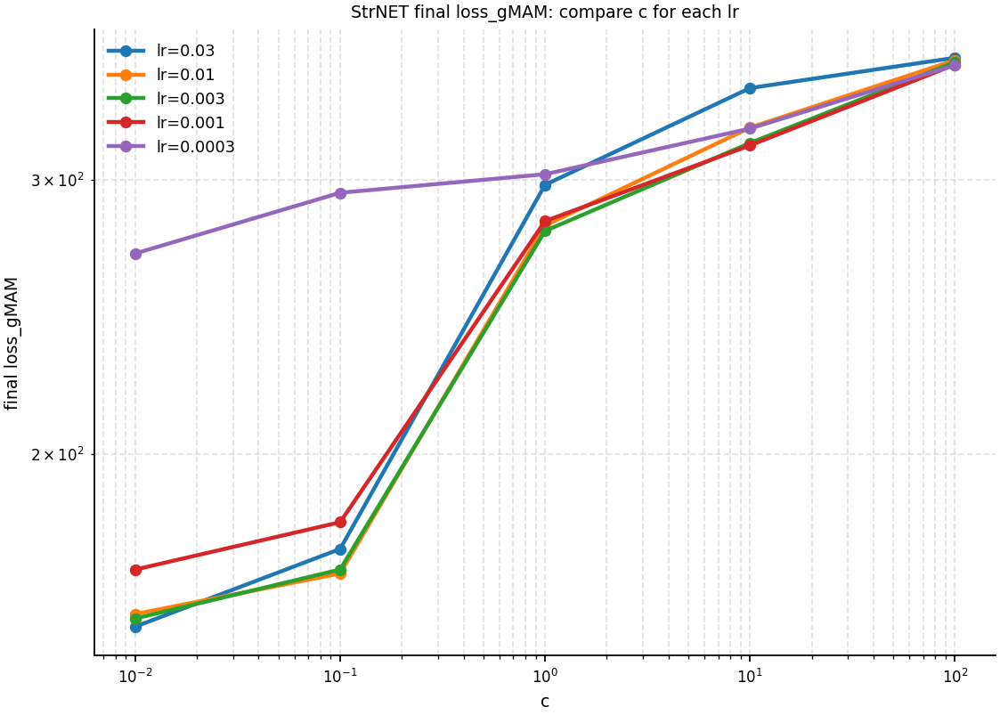

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_lr_by_c/StrNET_final_loss_gMAM_vs_lr_by_c.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_lr_by_c/StrNET_final_loss_gMAM_vs_lr_by_c.pdf


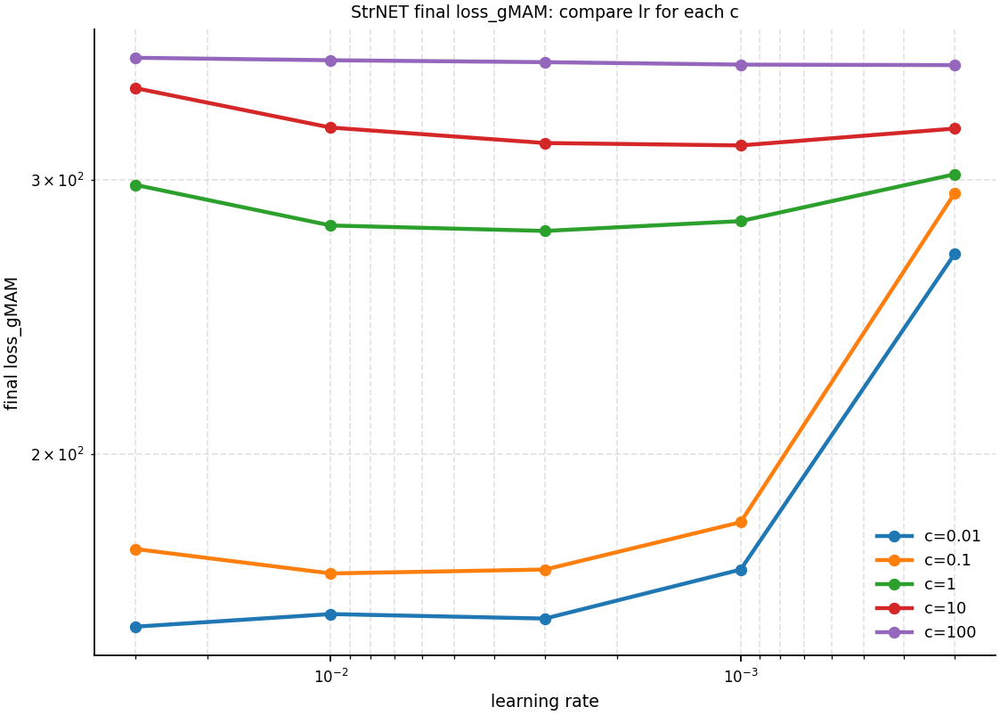

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/heatmaps/StrNET_final_loss_gMAM_heatmap.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/heatmaps/StrNET_final_loss_gMAM_heatmap.pdf


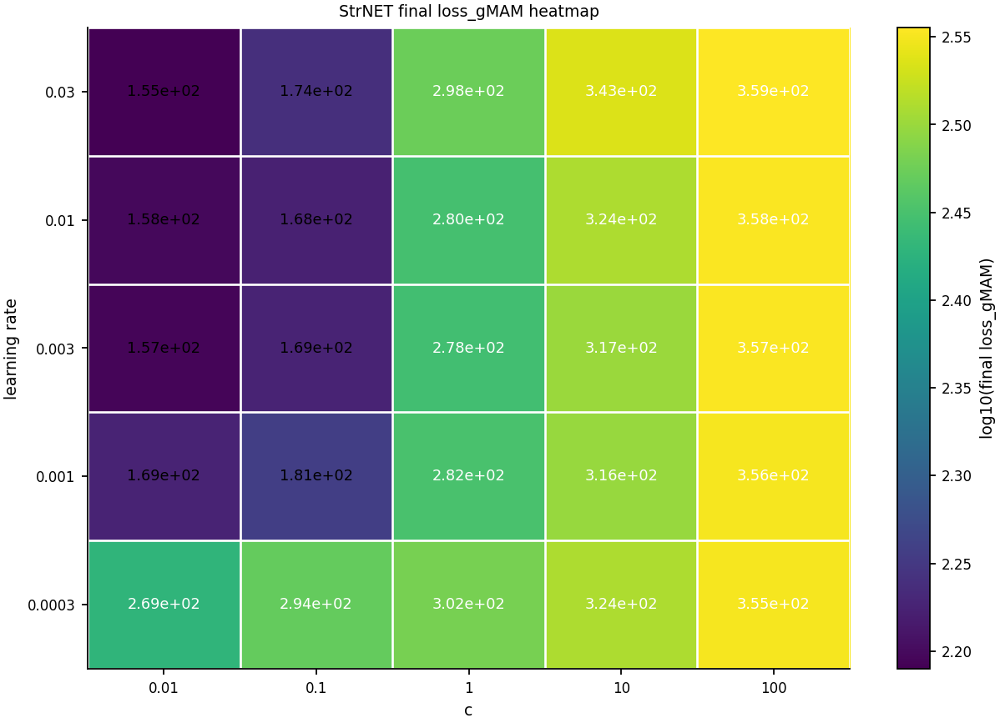


Plotting final metric: loss_perp
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_c_by_lr/StrNET_final_loss_perp_vs_c_by_lr.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_c_by_lr/StrNET_final_loss_perp_vs_c_by_lr.pdf


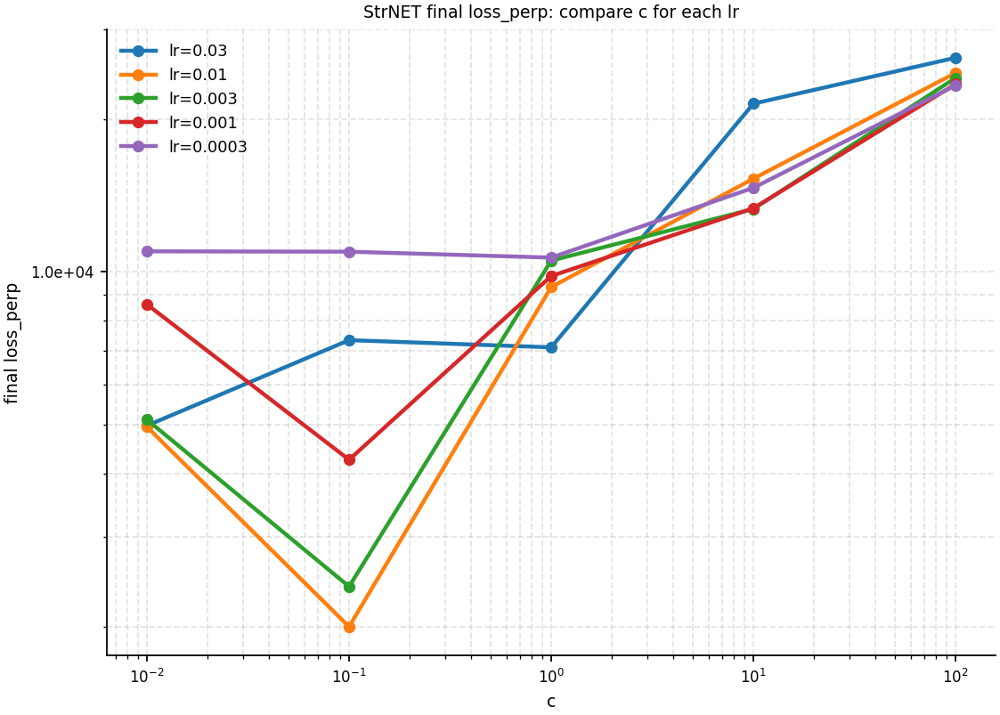

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_lr_by_c/StrNET_final_loss_perp_vs_lr_by_c.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_lr_by_c/StrNET_final_loss_perp_vs_lr_by_c.pdf


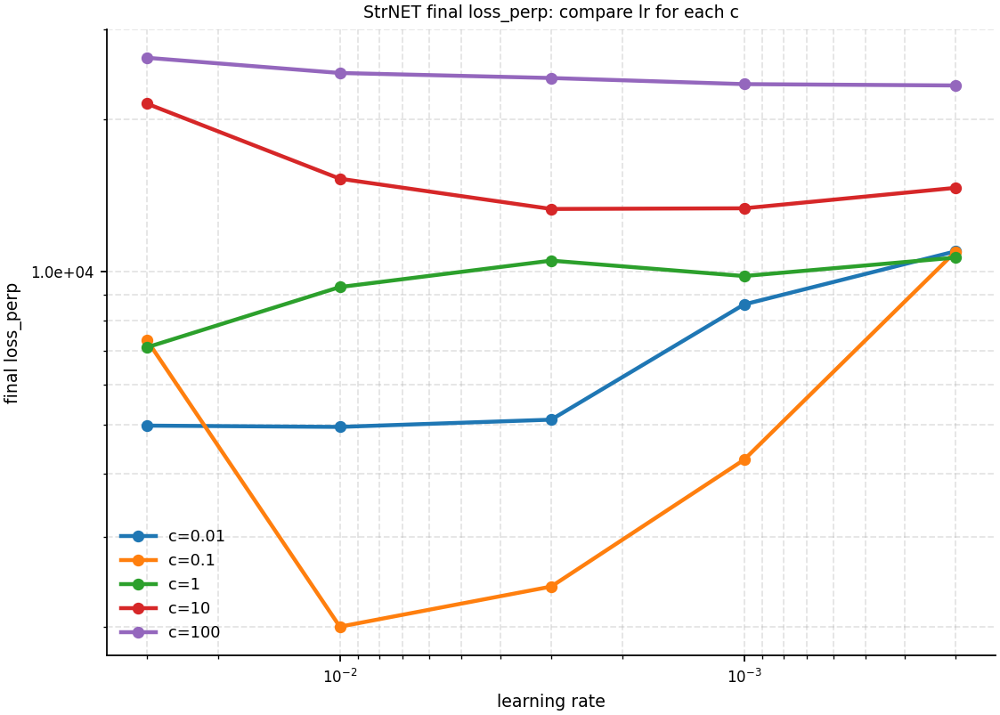

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/heatmaps/StrNET_final_loss_perp_heatmap.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/heatmaps/StrNET_final_loss_perp_heatmap.pdf


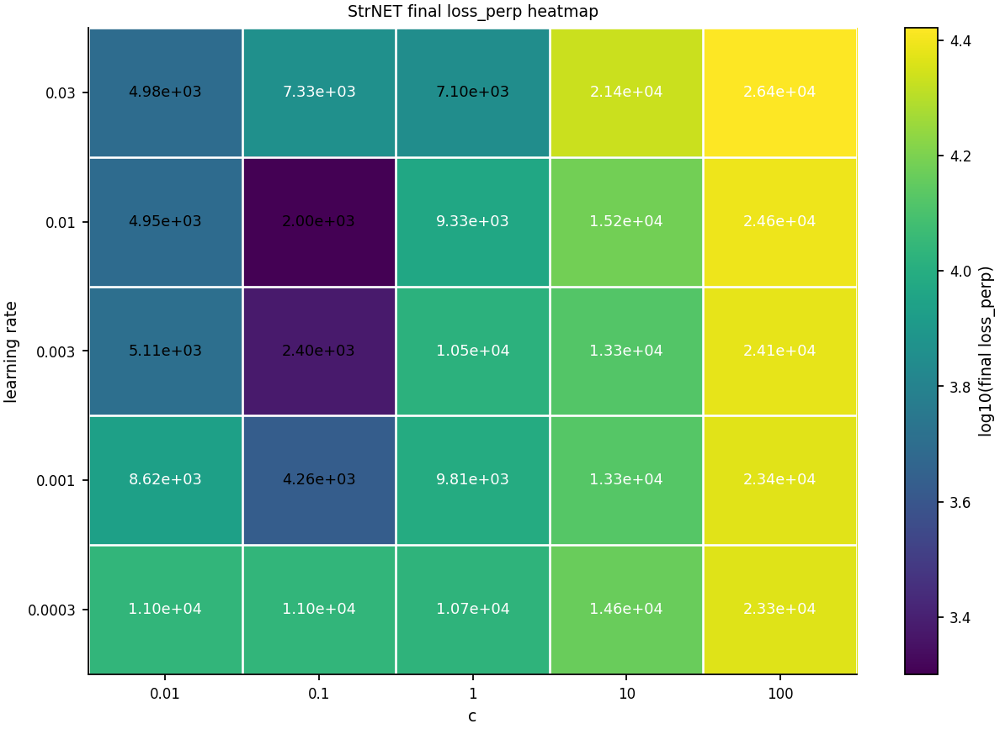


Plotting final metric: F_max
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_c_by_lr/StrNET_final_F_max_vs_c_by_lr.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_c_by_lr/StrNET_final_F_max_vs_c_by_lr.pdf


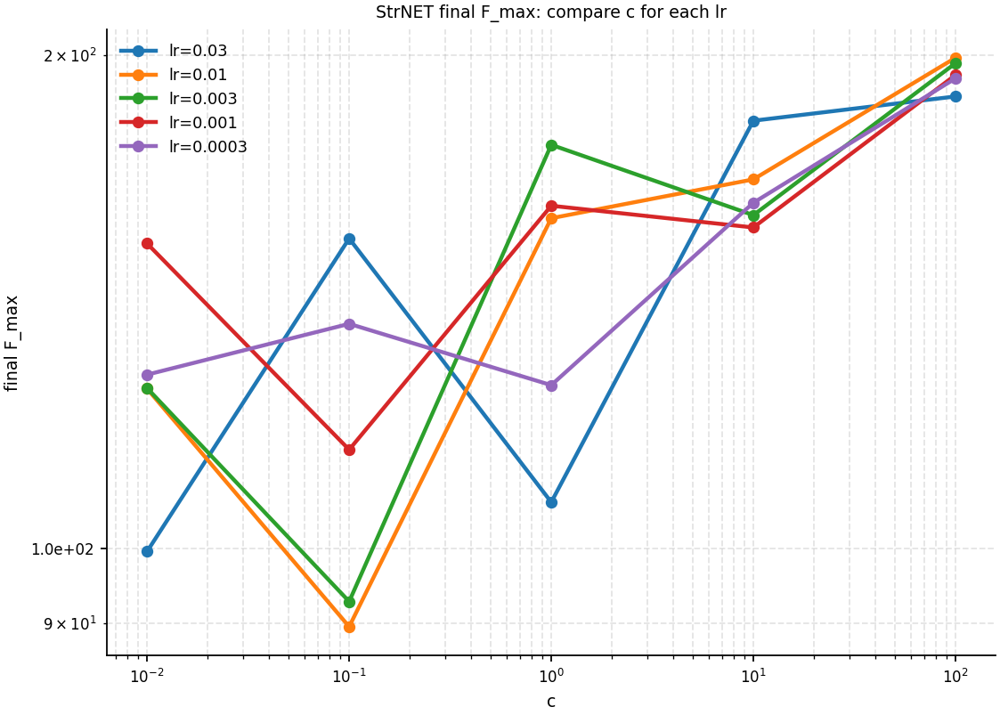

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_lr_by_c/StrNET_final_F_max_vs_lr_by_c.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_lr_by_c/StrNET_final_F_max_vs_lr_by_c.pdf


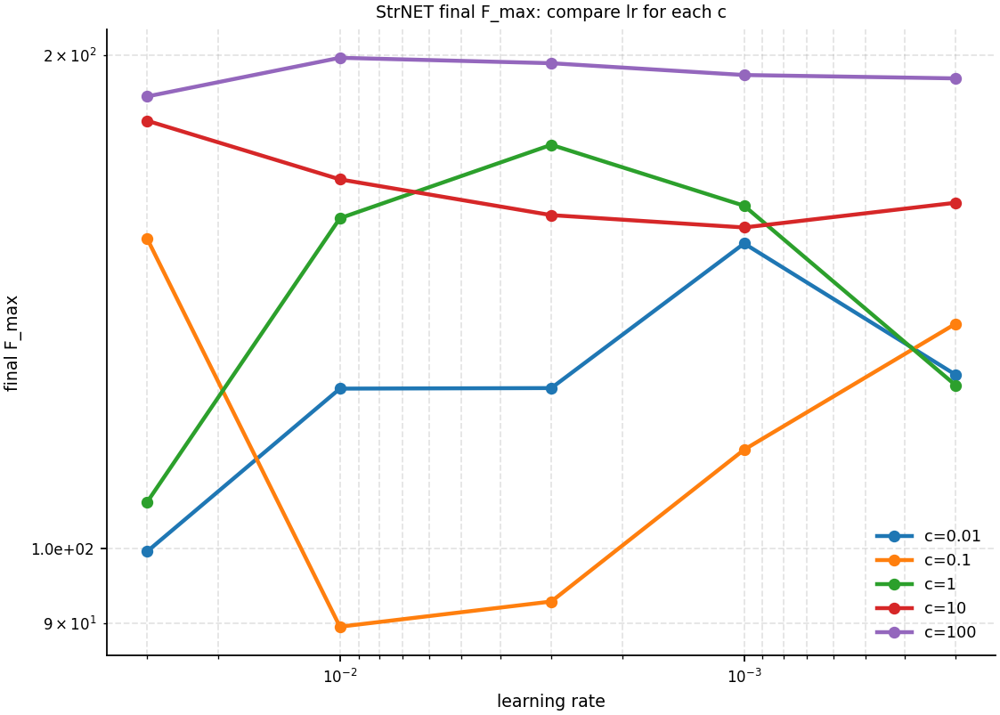

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/heatmaps/StrNET_final_F_max_heatmap.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/heatmaps/StrNET_final_F_max_heatmap.pdf


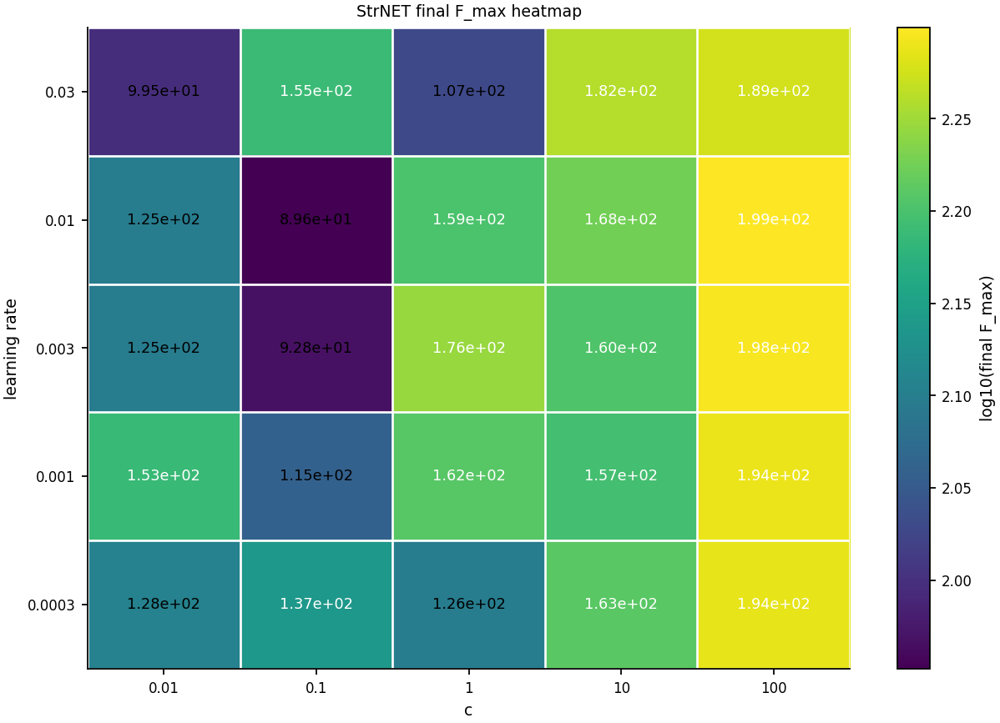


Plotting final metric: loss_arc
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_c_by_lr/StrNET_final_loss_arc_vs_c_by_lr.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_c_by_lr/StrNET_final_loss_arc_vs_c_by_lr.pdf


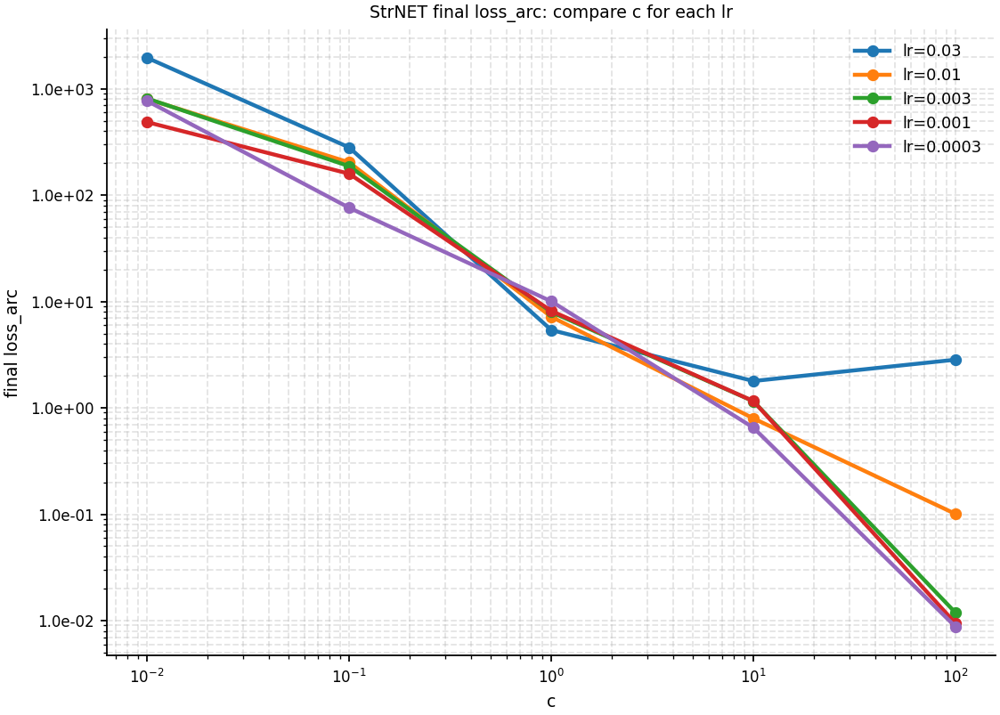

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_lr_by_c/StrNET_final_loss_arc_vs_lr_by_c.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_lr_by_c/StrNET_final_loss_arc_vs_lr_by_c.pdf


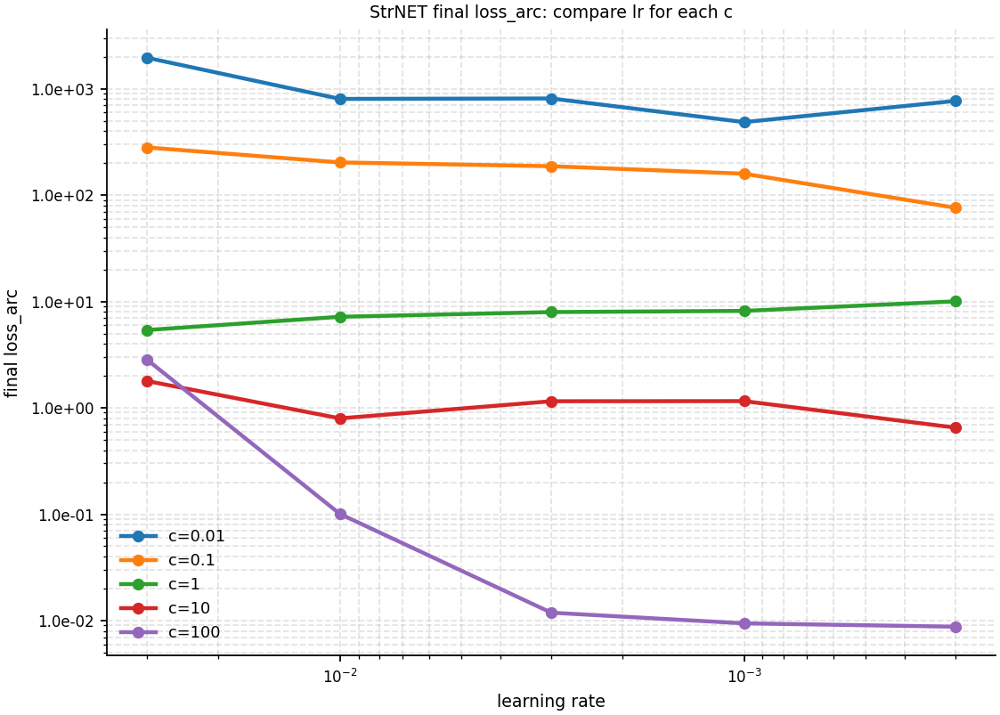

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/heatmaps/StrNET_final_loss_arc_heatmap.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/heatmaps/StrNET_final_loss_arc_heatmap.pdf


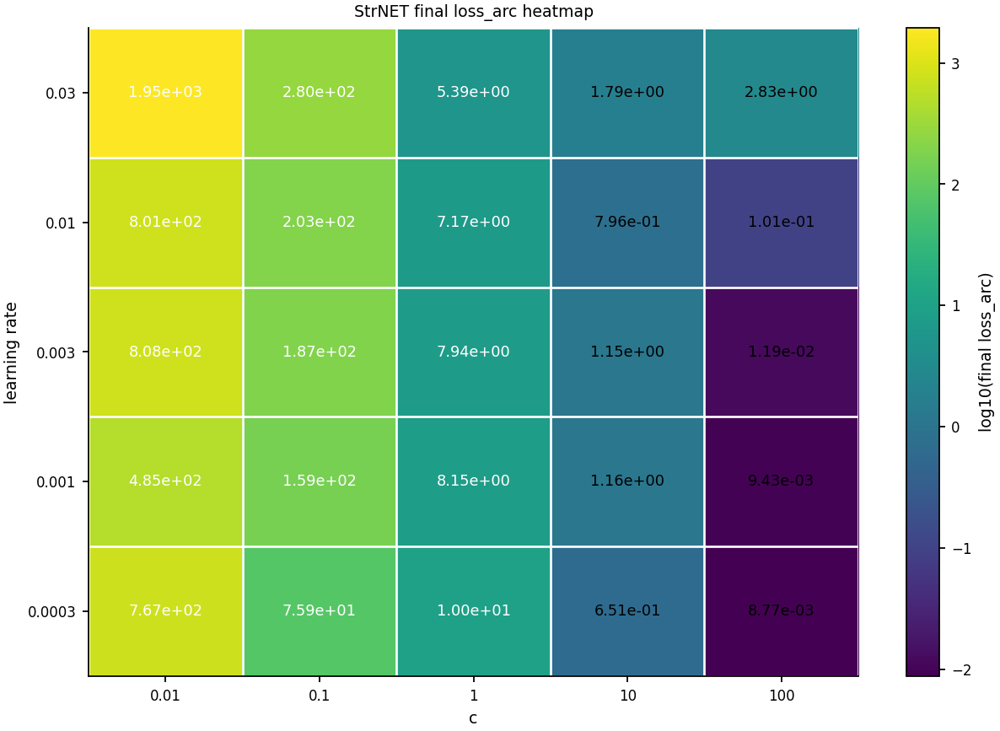


Plotting final metric: Delta_Energy
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_c_by_lr/StrNET_final_Delta_Energy_vs_c_by_lr.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_c_by_lr/StrNET_final_Delta_Energy_vs_c_by_lr.pdf


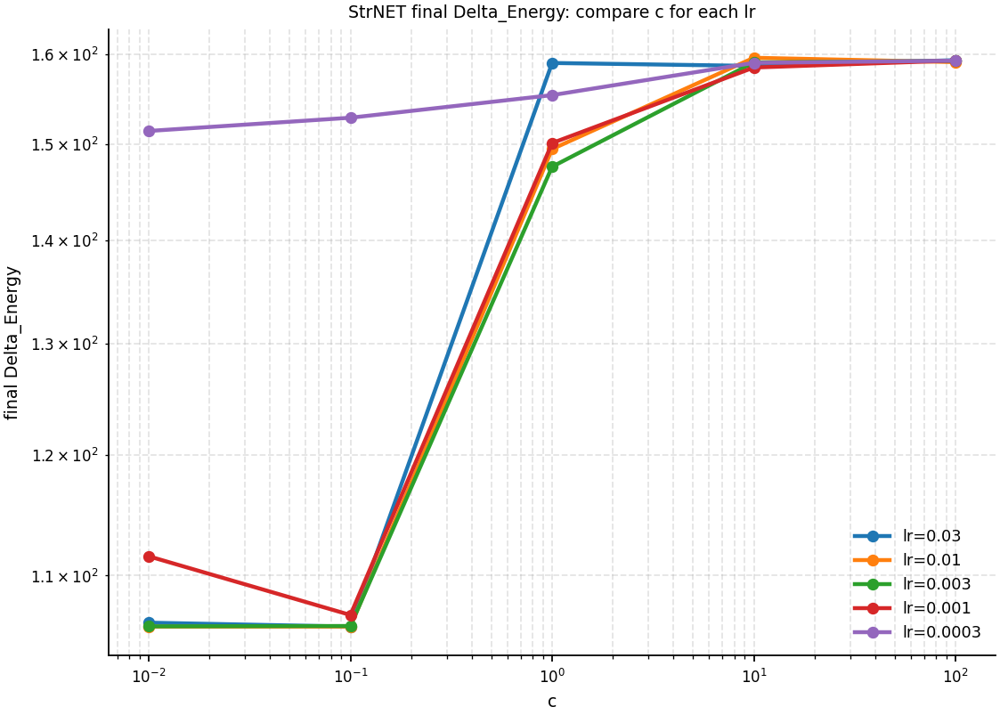

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_lr_by_c/StrNET_final_Delta_Energy_vs_lr_by_c.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/vs_lr_by_c/StrNET_final_Delta_Energy_vs_lr_by_c.pdf


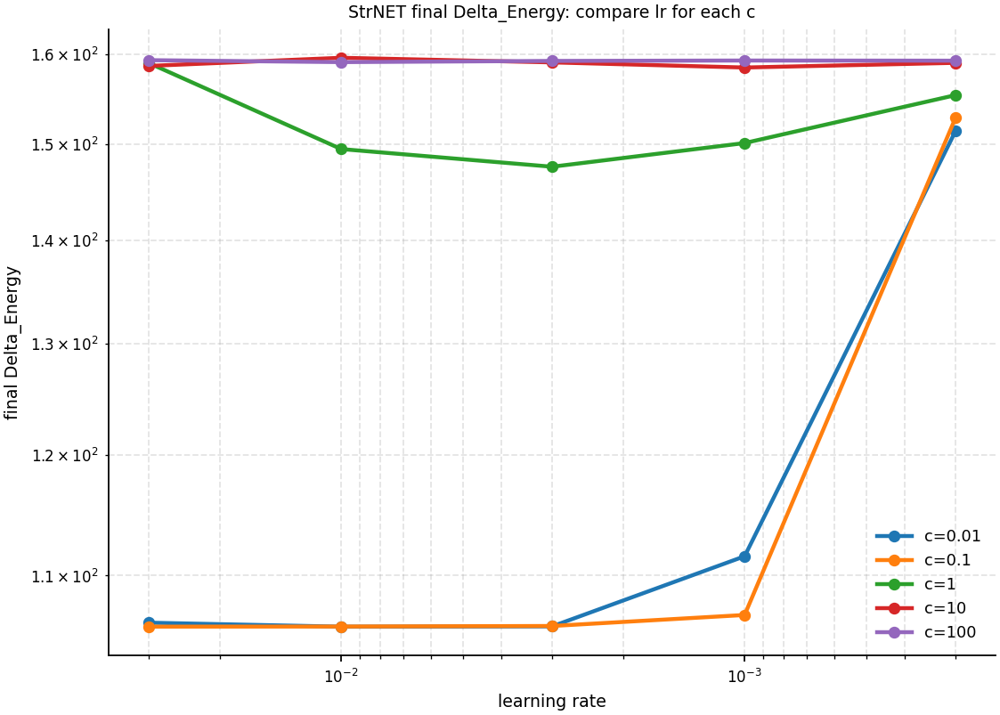

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/heatmaps/StrNET_final_Delta_Energy_heatmap.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/heatmaps/StrNET_final_Delta_Energy_heatmap.pdf


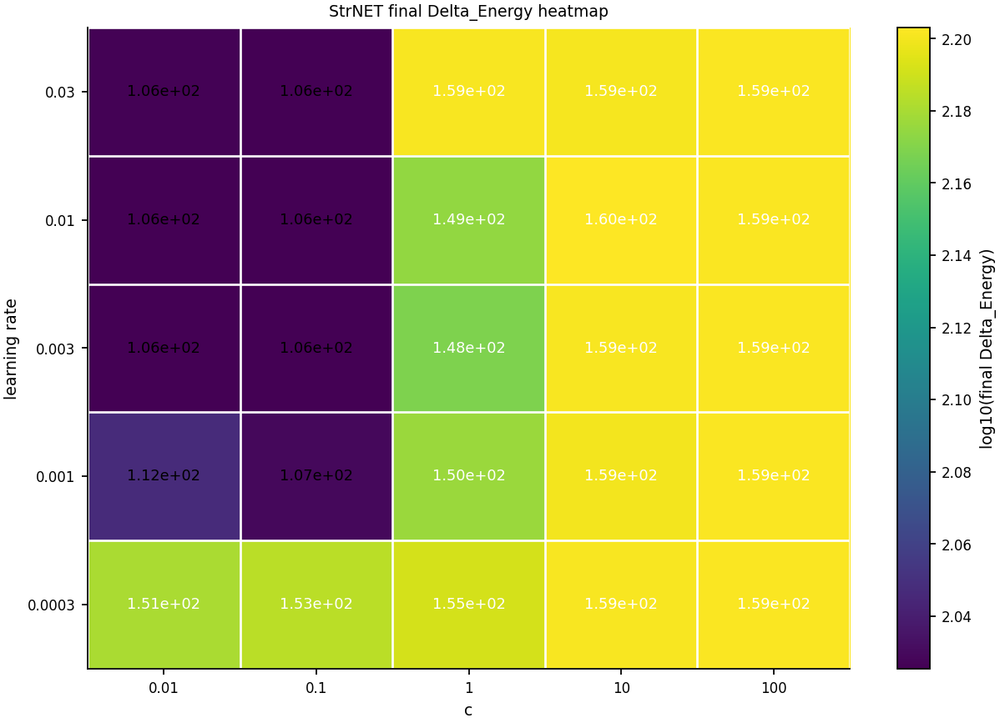

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/ranked/StrNET_ranked_final_loss_gMAM.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/ranked/StrNET_ranked_final_loss_gMAM.pdf


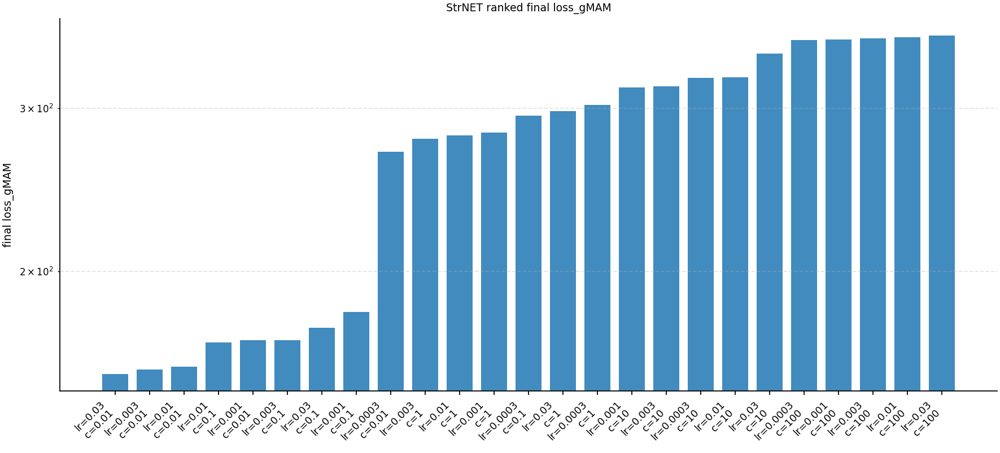

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/ranked/StrNET_ranked_final_loss_perp.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/ranked/StrNET_ranked_final_loss_perp.pdf


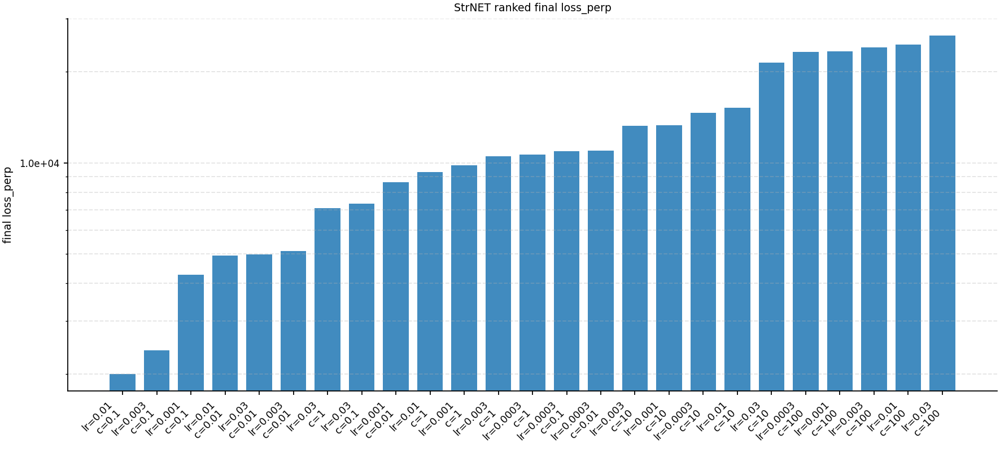

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/ranked/StrNET_ranked_final_F_max.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/ranked/StrNET_ranked_final_F_max.pdf


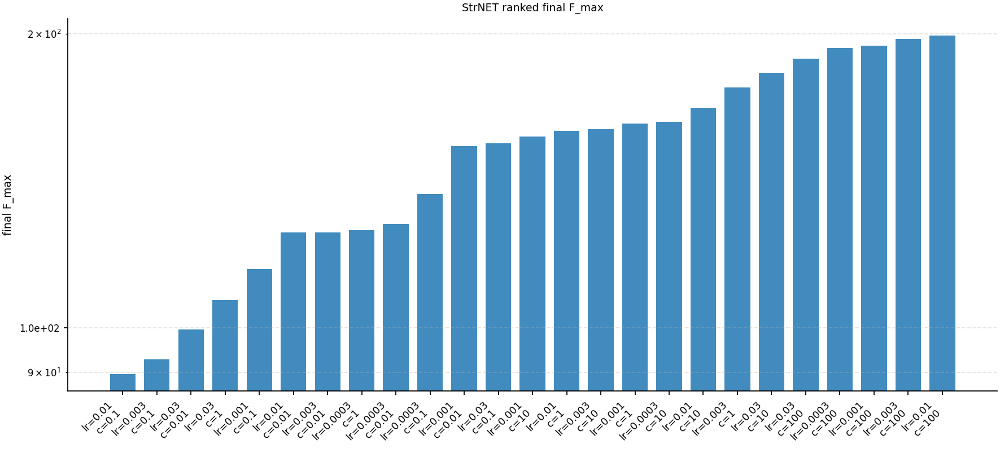

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/ranked/StrNET_ranked_final_loss_arc.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/ranked/StrNET_ranked_final_loss_arc.pdf


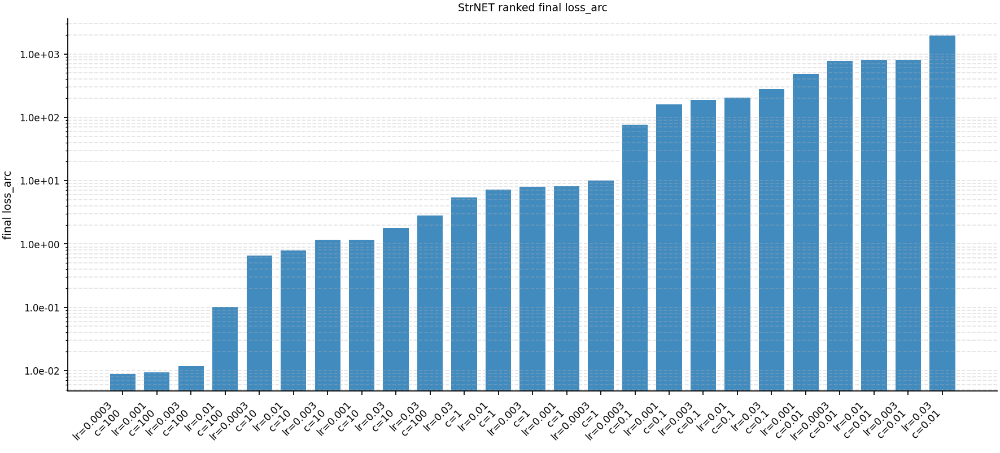

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/ranked/StrNET_ranked_final_Delta_Energy.png
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores/ranked/StrNET_ranked_final_Delta_Energy.pdf


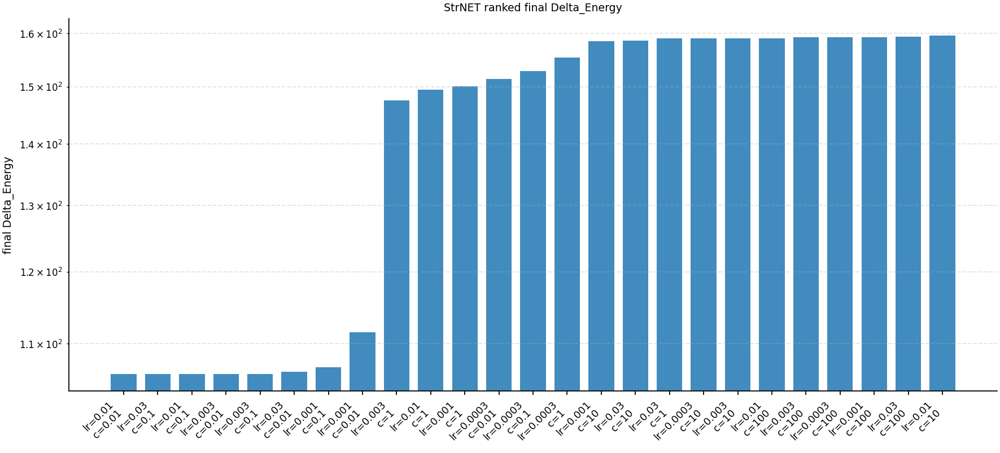


Done.
Figures and CSV saved to:
  /home/zqcai3/wzy/IVP_IVM/comparison_figures/StrNET_final_scores


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import FuncFormatter
import csv


# ============================================================
# 0. 配置区
# ============================================================

base_dir = "/home/zqcai3/wzy/IVP_IVM"

# 注意：
# 这里 n_images 对应你文件名里的 N。
# 在 StrNET 训练代码里 N=10 表示 10 个 interior points，
# 所以完整路径 images_seq 里实际是 N+2=12 个点。
n_images = 10

lr_list = [
    3e-2,
    1e-2,
    3e-3,
    1e-3,
    3e-4,
]

c3_list = [
    1e-2,
    1e-1,
    1e0,
    1e1,
    1e2,
]

method_name = "StrNET"

save_root = Path(base_dir) / "comparison_figures" / "StrNET_final_scores"

# Q_data 路径，用于计算 Delta_Energy
q_data_path = "/home/zqcai3/wzy/IVP_new/Q_data.npz"

dimension = 10

# 是否计算 Delta_Energy
INCLUDE_DELTA_ENERGY = True

# 服务器上批量跑建议 False
SHOW_FIGURES = True

# 是否保存图片
SAVE_PNG = True
SAVE_PDF = True


# ============================================================
# 1. Müller-10 势能，用于 Delta_Energy
# ============================================================

Q_np = None

if INCLUDE_DELTA_ENERGY:
    q_data = np.load(q_data_path)
    Q_np = q_data["Q"]

a_np = np.array([-1.0, -1.0, -6.5, 0.7], dtype=float)
b_np = np.array([0.0, 0.0, 11.0, 0.6], dtype=float)
c_np = np.array([-10.0, -10.0, -6.5, 0.7], dtype=float)
D_np = np.array([-200.0, -100.0, -170.0, 15.0], dtype=float)
X_np = np.array([1.0, 0.0, -0.5, -1.0], dtype=float)
Y_np = np.array([0.0, 0.5, 1.5, 1.0], dtype=float)
sigma = 0.5


def V_muller10_np(x_vec):
    """
    Müller-10 势能，支持单点和批量输入。

    输入:
        x_vec: shape (10,) 或 (N, 10)

    输出:
        单点输入 -> float
        批量输入 -> shape (N,) numpy array
    """
    if Q_np is None:
        raise RuntimeError("Q_np is None. Please load Q_data first.")

    x = np.asarray(x_vec, dtype=float)
    single_input = x.ndim == 1

    if single_input:
        x = x.reshape(1, dimension)
    elif x.ndim != 2 or x.shape[1] != dimension:
        raise ValueError(
            f"Input must have shape ({dimension},) or (N,{dimension}), got {x.shape}"
        )

    z = x @ Q_np

    z0 = z[:, 0]
    z1 = z[:, 1]
    rest = z[:, 2:]

    V = np.zeros(z.shape[0], dtype=float)

    for i in range(4):
        exponent = (
            a_np[i] * (z0 - X_np[i]) ** 2
            + b_np[i] * (z0 - X_np[i]) * (z1 - Y_np[i])
            + c_np[i] * (z1 - Y_np[i]) ** 2
        )
        V += D_np[i] * np.exp(exponent)

    V += np.sum((1.0 / (2.0 * sigma ** 2)) * rest ** 2, axis=1)

    if single_input:
        return float(V[0])

    return V


# ============================================================
# 2. 基础工具函数
# ============================================================

try:
    trapz = np.trapezoid
except AttributeError:
    trapz = np.trapz


def sci_label(v, digits=3):
    """
    科学计数法 label。
    """
    if not np.isfinite(v):
        return "nan"

    if v == 0:
        return "0"

    return f"{v:.{digits}e}"


def float_tag(v):
    """
    用于文件名或目录名。
    """
    s = f"{float(v):g}"
    s = s.replace(".", "p")
    s = s.replace("-", "m")
    s = s.replace("+", "")
    return s


def _float_close(a, b, rtol=1e-12, atol=1e-15):
    return np.isclose(float(a), float(b), rtol=rtol, atol=atol)


def _candidate_float_strings(v):
    """
    生成多个可能的浮点数字符串，用来兼容文件夹命名。

    例如:
        1.0 -> ["1.0", "1"]
        10.0 -> ["10.0", "10"]
        0.0003 -> ["0.0003"]
    """
    candidates = []

    candidates.append(str(v))

    try:
        candidates.append(str(float(v)))
        candidates.append(f"{float(v):g}")
    except Exception:
        pass

    out = []

    for s in candidates:
        if s not in out:
            out.append(s)

    return out


def _get_data_dir(base_dir, data_subdir="Data"):
    """
    允许 base_dir 是:

    1. /home/zqcai3/wzy/IVP_IVM
    2. /home/zqcai3/wzy/IVP_IVM/Data
    """
    base_dir = Path(base_dir)

    if base_dir.name == data_subdir:
        return base_dir

    return base_dir / data_subdir


def _find_strnet_file(base_dir, n_images, lr, c3, data_subdir="Data"):
    """
    自动寻找 StrNET npz 文件。

    目标格式:

        Data/
          M10_N10_Images_StrNET_lr0.01_c1.0/
            M10_M10_N10_Images_StrNET_lr0.01_c1.0.npz
    """
    data_dir = _get_data_dir(base_dir, data_subdir=data_subdir)

    lr_candidates = _candidate_float_strings(lr)
    c3_candidates = _candidate_float_strings(c3)

    tried = []

    for lr_s in lr_candidates:
        for c3_s in c3_candidates:

            casenum = f"M10_N{n_images}_Images_StrNET_lr{lr_s}_c{c3_s}"
            file_path = data_dir / casenum / f"M10_{casenum}.npz"

            tried.append((file_path, casenum))

            if file_path.exists():
                return file_path, casenum

    return tried[0]


def evaluate_V_on_points(X_points, V_func):
    """
    在一批点上计算势能。

    优先尝试 V_func(X_points) 向量化；
    如果失败，则退回逐点计算。
    """
    X_points = np.asarray(X_points, dtype=float)

    try:
        V_vals = np.asarray(V_func(X_points), dtype=float).reshape(-1)

        if V_vals.shape[0] == X_points.shape[0]:
            return V_vals

    except Exception:
        pass

    V_vals = np.array([
        float(np.asarray(V_func(xi)))
        for xi in X_points
    ])

    return V_vals


# ============================================================
# 3. 路径几何和积分
# ============================================================

def compute_path_derivatives_single_path(path):
    """
    对单条路径计算 phi_s, phi_ss, speed。

    path:
        shape (N_path, d)

    返回:
        s:       shape (N_path,)
        phi_s:   shape (N_path, d)
        phi_ss:  shape (N_path, d)
        speed:   shape (N_path,)
    """
    path = np.asarray(path, dtype=float)

    if path.ndim != 2:
        raise ValueError(f"path must have shape (N_path, d), got {path.shape}")

    N_path, d = path.shape

    s = np.linspace(0.0, 1.0, N_path)

    edge_order = 2 if N_path >= 3 else 1

    phi_s = np.gradient(path, s, axis=0, edge_order=edge_order)
    phi_ss = np.gradient(phi_s, s, axis=0, edge_order=edge_order)

    speed = np.linalg.norm(phi_s, axis=1)

    return s, phi_s, phi_ss, speed


def line_integral_force_quantity_single_path(q_force, speed, N_path):
    """
    对路径上的 quantity 做 line integral。

    q_force:
        shape (N_force,)

    speed:
        shape (N_path,)

    N_path:
        完整路径点数，包括两个端点。

    支持几种情况:

    1. N_force == N_path - 2
       quantity 只在 interior points 上。

    2. N_force == N_path - 1
       StrNET 当前保存方式：
       F_perp/F_original 在 [x0, P0, ..., P_{N-1}] 上，
       不包含最后 endpoint x1。

    3. N_force == N_path
       quantity 在完整路径上。
    """
    q_force = np.asarray(q_force, dtype=float).reshape(-1)
    speed = np.asarray(speed, dtype=float).reshape(-1)

    N_force = q_force.shape[0]

    ds = 1.0 / (N_path - 1)

    if N_force == N_path - 2:
        speed_force = speed[1:-1]
        return float(np.sum(q_force * speed_force) * ds)

    elif N_force == N_path - 1:
        speed_force = speed[:-1]
        return float(np.sum(q_force * speed_force) * ds)

    elif N_force == N_path:
        s = np.linspace(0.0, 1.0, N_path)
        return float(trapz(q_force * speed, s))

    else:
        # 兜底：如果 force 网格和 path 网格不匹配，则插值 speed
        s_path = np.linspace(0.0, 1.0, N_path)
        s_force = np.linspace(0.0, 1.0, N_force)

        speed_force = np.interp(s_force, s_path, speed)

        return float(trapz(q_force * speed_force, s_force))


def compute_delta_energy_final(
    final_path,
    initial_path,
    V_func,
    dense_n=500,
    E_min=None,
):
    """
    计算最终路径能垒:

        Delta_Energy = max_s V(phi_final(s)) - E_min

    默认:
        E_min = min V(initial_path)

    这样和前面 gMAM 后处理代码保持一致。
    """
    final_path = np.asarray(final_path, dtype=float)
    initial_path = np.asarray(initial_path, dtype=float)

    if final_path.ndim != 2:
        raise ValueError(f"final_path must have shape (N_path, d), got {final_path.shape}")

    if initial_path.ndim != 2:
        raise ValueError(f"initial_path must have shape (N_path, d), got {initial_path.shape}")

    N_path, d = final_path.shape

    if E_min is None:
        E0 = evaluate_V_on_points(initial_path, V_func)
        E_min = np.min(E0)

    t_old = np.linspace(0.0, 1.0, N_path)
    t_new = np.linspace(0.0, 1.0, dense_n)

    X_dense = np.column_stack([
        np.interp(t_new, t_old, final_path[:, dim])
        for dim in range(d)
    ])

    E_dense = evaluate_V_on_points(X_dense, V_func)

    Delta_Energy = np.max(E_dense) - E_min

    return float(Delta_Energy)


# ============================================================
# 4. 读取 StrNET 数据
# ============================================================

def load_strnet_runs(
    base_dir,
    n_images,
    lr_list,
    c3_list,
    data_subdir="Data",
    allow_missing=True,
):
    """
    读取所有 StrNET 实验数据。

    每个 run 包含:
        method
        label
        lr
        c3
        file
        images_seq
        count_seq
        F_perp
        F_original
        fmaxs
    """
    runs = []

    for lr in lr_list:
        for c3 in c3_list:

            file_path, casenum = _find_strnet_file(
                base_dir=base_dir,
                n_images=n_images,
                lr=lr,
                c3=c3,
                data_subdir=data_subdir,
            )

            if not file_path.exists():
                msg = f"[Missing StrNET file] lr={lr:g}, c3={c3:g}\n  {file_path}"

                if allow_missing:
                    print(msg)
                    continue
                else:
                    raise FileNotFoundError(msg)

            loaded = np.load(file_path, allow_pickle=True)

            required_keys = [
                "images_seq",
                "count_seq",
                "F_perp",
                "F_original",
            ]

            missing_keys = [
                k for k in required_keys
                if k not in loaded.files
            ]

            if len(missing_keys) > 0:
                msg = (
                    f"[Skip] file missing keys {missing_keys}: \n"
                    f"  {file_path}"
                )

                if allow_missing:
                    print(msg)
                    continue
                else:
                    raise KeyError(msg)

            run = {
                "method": "StrNET",
                "label": f"StrNET, lr={lr:g}, c={c3:g}",
                "lr": float(lr),
                "c3": float(c3),
                "file": file_path,
                "images_seq": loaded["images_seq"],
                "count_seq": loaded["count_seq"],
                "F_perp": loaded["F_perp"],
                "F_original": loaded["F_original"],
            }

            if "fmaxs" in loaded.files:
                run["fmaxs"] = loaded["fmaxs"]
            else:
                run["fmaxs"] = None

            runs.append(run)

    print(f"\nLoaded {len(runs)} StrNET runs.")

    return runs


# ============================================================
# 5. 只计算最终指标
# ============================================================

def compute_final_metrics_for_strnet_run(
    run,
    V_func=None,
    include_delta_energy=True,
    dense_n_energy=500,
    fmax_mode="saved_or_norm",
):
    """
    只计算某个 StrNET run 的最终指标。

    输出:
        final_count
        loss_gMAM
        loss_perp
        F_max
        loss_arc
        Delta_Energy, optional
    """
    images_seq = np.asarray(run["images_seq"], dtype=float)
    count_seq = np.asarray(run["count_seq"])
    F_perp = np.asarray(run["F_perp"], dtype=float)
    F_original = np.asarray(run["F_original"], dtype=float)

    saved_fmaxs = run.get("fmaxs", None)

    if saved_fmaxs is not None:
        saved_fmaxs = np.asarray(saved_fmaxs, dtype=float)

    if images_seq.ndim != 3:
        raise ValueError(
            f"images_seq must have shape (T, N_path, d), got {images_seq.shape}"
        )

    if F_perp.ndim != 3:
        raise ValueError(
            f"F_perp must have shape (T, N_force, d), got {F_perp.shape}"
        )

    if F_original.ndim != 3:
        raise ValueError(
            f"F_original must have shape (T, N_force, d), got {F_original.shape}"
        )

    lengths = [
        images_seq.shape[0],
        count_seq.reshape(-1).shape[0],
        F_perp.shape[0],
        F_original.shape[0],
    ]

    if saved_fmaxs is not None:
        lengths.append(saved_fmaxs.reshape(-1).shape[0])

    T = min(lengths)

    if T <= 0:
        raise ValueError(f"Empty sequence in run: {run['label']}")

    images_seq = images_seq[:T]
    count_seq = count_seq.reshape(-1)[:T]
    F_perp = F_perp[:T]
    F_original = F_original[:T]

    if saved_fmaxs is not None:
        saved_fmaxs = saved_fmaxs.reshape(-1)[:T]

    initial_path = images_seq[0]
    final_path = images_seq[-1]

    final_F_perp = F_perp[-1]
    final_F_original = F_original[-1]

    final_count = count_seq[-1]

    N_path = final_path.shape[0]

    s, phi_s, phi_ss, speed = compute_path_derivatives_single_path(final_path)

    # ------------------------------------------------------------
    # loss_gMAM
    #
    # 和前面 gMAM 后处理保持一致:
    #
    #     integral ||F_original|| * ||phi_s|| ds
    #
    # 在你的 StrNET 保存代码里:
    #     F_original = g_P = gradient_tensor(phi_loss)
    #
    # 所以这里就是沿最终路径积分 ||grad V||。
    # ------------------------------------------------------------
    F_original_norm = np.linalg.norm(final_F_original, axis=1)

    loss_gMAM = line_integral_force_quantity_single_path(
        q_force=F_original_norm,
        speed=speed,
        N_path=N_path,
    )

    # ------------------------------------------------------------
    # loss_perp
    #
    #     integral ||F_perp||^2 * ||phi_s|| ds
    # ------------------------------------------------------------
    F_perp_norm_sq = np.sum(final_F_perp ** 2, axis=1)

    loss_perp = line_integral_force_quantity_single_path(
        q_force=F_perp_norm_sq,
        speed=speed,
        N_path=N_path,
    )

    # ------------------------------------------------------------
    # F_max
    # ------------------------------------------------------------
    if fmax_mode == "saved_or_norm":
        if saved_fmaxs is not None:
            F_max = saved_fmaxs[-1]
        else:
            F_max = np.max(np.linalg.norm(final_F_perp, axis=1))

    elif fmax_mode == "saved":
        if saved_fmaxs is None:
            raise ValueError("fmax_mode='saved' but saved_fmaxs is None.")
        F_max = saved_fmaxs[-1]

    elif fmax_mode == "norm":
        F_max = np.max(np.linalg.norm(final_F_perp, axis=1))

    elif fmax_mode == "direct":
        F_max = np.max(final_F_perp)

    elif fmax_mode == "abs":
        F_max = np.max(np.abs(final_F_perp))

    else:
        raise ValueError(
            "fmax_mode must be one of: "
            "'saved_or_norm', 'saved', 'norm', 'direct', 'abs'."
        )

    # ------------------------------------------------------------
    # loss_arc
    #
    # 和前面 gMAM 后处理一致:
    #
    #     integral <phi_s, phi_ss>^2 * ||phi_s|| ds
    # ------------------------------------------------------------
    inner_phi_s_phi_ss = np.sum(phi_s * phi_ss, axis=1)
    arc_integrand = inner_phi_s_phi_ss ** 2 * speed

    loss_arc = trapz(arc_integrand, s)

    metrics = {
        "final_count": float(final_count),
        "loss_gMAM": float(loss_gMAM),
        "loss_perp": float(loss_perp),
        "F_max": float(F_max),
        "loss_arc": float(loss_arc),
    }

    # ------------------------------------------------------------
    # Delta_Energy
    # ------------------------------------------------------------
    if include_delta_energy:
        if V_func is None:
            raise ValueError(
                "include_delta_energy=True but V_func is None."
            )

        Delta_Energy = compute_delta_energy_final(
            final_path=final_path,
            initial_path=initial_path,
            V_func=V_func,
            dense_n=dense_n_energy,
            E_min=None,
        )

        metrics["Delta_Energy"] = float(Delta_Energy)

    return metrics


def compute_all_final_metrics(
    strnet_runs,
    include_delta_energy=True,
    V_func=None,
    dense_n_energy=500,
):
    """
    为所有 StrNET runs 计算最终指标。
    """
    for run in strnet_runs:
        print("Processing final metrics:", run["label"])
        print("File:", run["file"])

        run["final_metrics"] = compute_final_metrics_for_strnet_run(
            run=run,
            V_func=V_func,
            include_delta_energy=include_delta_energy,
            dense_n_energy=dense_n_energy,
            fmax_mode="saved_or_norm",
        )

    return strnet_runs


# ============================================================
# 6. 整理最终成绩表格
# ============================================================

def get_metric_names(include_delta_energy=True):
    metric_names = [
        "loss_gMAM",
        "loss_perp",
        "F_max",
        "loss_arc",
    ]

    if include_delta_energy:
        metric_names.append("Delta_Energy")

    return metric_names


def build_final_records(strnet_runs, include_delta_energy=True):
    """
    把所有 run 的最终成绩整理为 list[dict]。
    """
    metric_names = get_metric_names(include_delta_energy=include_delta_energy)

    records = []

    for run in strnet_runs:
        if "final_metrics" not in run:
            continue

        m = run["final_metrics"]

        record = {
            "method": run["method"],
            "lr": float(run["lr"]),
            "c3": float(run["c3"]),
            "final_count": float(m["final_count"]),
            "file": str(run["file"]),
        }

        for metric_name in metric_names:
            record[metric_name] = float(m[metric_name])

        records.append(record)

    return records


def print_final_summary(records, sort_by="loss_perp", include_delta_energy=True):
    """
    打印最终指标 summary。
    """
    if len(records) == 0:
        print("No records.")
        return

    metric_names = get_metric_names(include_delta_energy=include_delta_energy)

    if sort_by not in metric_names:
        raise ValueError(f"sort_by must be one of {metric_names}")

    records_sorted = sorted(records, key=lambda r: r[sort_by])

    header_parts = [
        f"{'lr':>10}",
        f"{'c3':>10}",
        f"{'count':>10}",
    ]

    for metric_name in metric_names:
        header_parts.append(f"{metric_name:>16}")

    header = "  ".join(header_parts)

    print("\nSorted by:", sort_by)
    print(header)
    print("-" * len(header))

    for r in records_sorted:
        row_parts = [
            f"{r['lr']:10.3g}",
            f"{r['c3']:10.3g}",
            f"{r['final_count']:10.0f}",
        ]

        for metric_name in metric_names:
            row_parts.append(f"{r[metric_name]:16.6e}")

        print("  ".join(row_parts))


def save_final_records_csv(
    records,
    save_path,
    include_delta_energy=True,
):
    """
    保存最终指标为 CSV。
    """
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    metric_names = get_metric_names(include_delta_energy=include_delta_energy)

    fieldnames = [
        "method",
        "lr",
        "c3",
        "final_count",
    ] + metric_names + [
        "file",
    ]

    with open(save_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

        for r in records:
            writer.writerow(r)

    print(f"\nSaved CSV:\n  {save_path}")


# ============================================================
# 7. 从 records 里提取数据
# ============================================================

def find_record(records, lr, c3):
    """
    根据 lr 和 c3 找对应 record。
    """
    for r in records:
        if _float_close(r["lr"], lr) and _float_close(r["c3"], c3):
            return r

    return None


def get_metric_grid(records, lr_list, c3_list, metric_name):
    """
    构造矩阵:

        rows = lr_list
        cols = c3_list

    grid[i, j] = metric(lr_i, c3_j)
    """
    grid = np.full((len(lr_list), len(c3_list)), np.nan, dtype=float)

    for i, lr in enumerate(lr_list):
        for j, c3 in enumerate(c3_list):
            r = find_record(records, lr, c3)

            if r is not None:
                grid[i, j] = r[metric_name]

    return grid


def get_line_vs_c3(records, lr, c3_list, metric_name):
    """
    固定 lr，取不同 c3 下的 metric。
    """
    xs = []
    ys = []

    for c3 in c3_list:
        r = find_record(records, lr, c3)

        if r is None:
            continue

        y = r[metric_name]

        if np.isfinite(y):
            xs.append(float(c3))
            ys.append(float(y))

    return np.asarray(xs), np.asarray(ys)


def get_line_vs_lr(records, c3, lr_list, metric_name):
    """
    固定 c3，取不同 lr 下的 metric。
    """
    xs = []
    ys = []

    for lr in lr_list:
        r = find_record(records, lr, c3)

        if r is None:
            continue

        y = r[metric_name]

        if np.isfinite(y):
            xs.append(float(lr))
            ys.append(float(y))

    return np.asarray(xs), np.asarray(ys)


# ============================================================
# 8. 画图工具
# ============================================================

def log_tick_formatter(y, pos=None):
    if not np.isfinite(y) or y <= 0:
        return ""

    return f"{y:.1e}"


def save_figure(fig, save_path_without_suffix):
    """
    保存 png/pdf。
    """
    save_path_without_suffix = Path(save_path_without_suffix)
    save_path_without_suffix.parent.mkdir(parents=True, exist_ok=True)

    if SAVE_PNG:
        png_path = save_path_without_suffix.with_suffix(".png")
        fig.savefig(png_path, bbox_inches="tight", dpi=300)
        print(f"Saved: {png_path}")

    if SAVE_PDF:
        pdf_path = save_path_without_suffix.with_suffix(".pdf")
        fig.savefig(pdf_path, bbox_inches="tight")
        print(f"Saved: {pdf_path}")


def set_log_axis_if_positive(ax, x_values=None, y_values=None, xlog=False, ylog=True):
    """
    如果数据全为正，则使用 log scale。
    """
    if xlog and x_values is not None:
        x_values = np.asarray(x_values, dtype=float)
        x_valid = x_values[np.isfinite(x_values)]

        if x_valid.size > 0 and np.all(x_valid > 0):
            ax.set_xscale("log")

    if ylog and y_values is not None:
        y_values = np.asarray(y_values, dtype=float)
        y_valid = y_values[np.isfinite(y_values)]

        if y_valid.size > 0 and np.all(y_valid > 0):
            ax.set_yscale("log")
            ax.yaxis.set_major_formatter(FuncFormatter(log_tick_formatter))


def plot_final_vs_c3_by_lr(
    records,
    lr_list,
    c3_list,
    metric_name,
    save_dir,
    show=True,
):
    """
    固定 lr，横轴 c3，比较最终 metric。
    """
    fig, ax = plt.subplots(figsize=(7.2, 5.2), dpi=160)

    all_x = []
    all_y = []

    for lr in lr_list:
        x, y = get_line_vs_c3(
            records=records,
            lr=lr,
            c3_list=c3_list,
            metric_name=metric_name,
        )

        if len(x) == 0:
            continue

        all_x.append(x)
        all_y.append(y)

        ax.plot(
            x,
            y,
            marker="o",
            linewidth=2.0,
            markersize=5,
            label=f"lr={lr:g}",
        )

    if len(all_x) > 0:
        all_x = np.concatenate(all_x)
        all_y = np.concatenate(all_y)

        set_log_axis_if_positive(
            ax,
            x_values=all_x,
            y_values=all_y,
            xlog=True,
            ylog=True,
        )

    ax.set_xlabel("c")
    ax.set_ylabel(f"final {metric_name}")
    ax.set_title(f"StrNET final {metric_name}: compare c for each lr")

    ax.grid(True, which="both", linestyle="--", alpha=0.35)
    ax.legend(fontsize=8)

    fig.tight_layout()

    save_figure(
        fig,
        Path(save_dir) / f"StrNET_final_{metric_name}_vs_c_by_lr",
    )

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig, ax


def plot_final_vs_lr_by_c3(
    records,
    lr_list,
    c3_list,
    metric_name,
    save_dir,
    show=True,
):
    """
    固定 c3，横轴 lr，比较最终 metric。
    """
    fig, ax = plt.subplots(figsize=(7.2, 5.2), dpi=160)

    all_x = []
    all_y = []

    for c3 in c3_list:
        x, y = get_line_vs_lr(
            records=records,
            c3=c3,
            lr_list=lr_list,
            metric_name=metric_name,
        )

        if len(x) == 0:
            continue

        all_x.append(x)
        all_y.append(y)

        ax.plot(
            x,
            y,
            marker="o",
            linewidth=2.0,
            markersize=5,
            label=f"c={c3:g}",
        )

    if len(all_x) > 0:
        all_x = np.concatenate(all_x)
        all_y = np.concatenate(all_y)

        set_log_axis_if_positive(
            ax,
            x_values=all_x,
            y_values=all_y,
            xlog=True,
            ylog=True,
        )

    # lr 从大到小显示
    ax.invert_xaxis()

    ax.set_xlabel("learning rate")
    ax.set_ylabel(f"final {metric_name}")
    ax.set_title(f"StrNET final {metric_name}: compare lr for each c")

    ax.grid(True, which="both", linestyle="--", alpha=0.35)
    ax.legend(fontsize=8)

    fig.tight_layout()

    save_figure(
        fig,
        Path(save_dir) / f"StrNET_final_{metric_name}_vs_lr_by_c",
    )

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig, ax


def plot_final_metric_heatmap(
    records,
    lr_list,
    c3_list,
    metric_name,
    save_dir,
    show=True,
    cmap_name="viridis",
):
    """
    画 lr × c3 的最终 metric heatmap。

    显示 log10(metric)，格子里标注原始 metric 数值。
    """
    grid = get_metric_grid(
        records=records,
        lr_list=lr_list,
        c3_list=c3_list,
        metric_name=metric_name,
    )

    log_grid = np.full_like(grid, np.nan, dtype=float)

    positive_mask = np.isfinite(grid) & (grid > 0)
    log_grid[positive_mask] = np.log10(grid[positive_mask])

    masked_log_grid = np.ma.masked_invalid(log_grid)

    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad(color="lightgray")

    fig, ax = plt.subplots(figsize=(8.0, 5.6), dpi=160)

    im = ax.imshow(
        masked_log_grid,
        cmap=cmap,
        aspect="auto",
        origin="upper",
    )

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(f"log10(final {metric_name})")

    ax.set_xticks(np.arange(len(c3_list)))
    ax.set_yticks(np.arange(len(lr_list)))

    ax.set_xticklabels([f"{c3:g}" for c3 in c3_list])
    ax.set_yticklabels([f"{lr:g}" for lr in lr_list])

    ax.set_xlabel("c")
    ax.set_ylabel("learning rate")
    ax.set_title(f"StrNET final {metric_name} heatmap")

    # 网格线
    ax.set_xticks(np.arange(len(c3_list) + 1) - 0.5, minor=True)
    ax.set_yticks(np.arange(len(lr_list) + 1) - 0.5, minor=True)
    ax.grid(which="minor", color="white", linestyle="-", linewidth=1.2)
    ax.tick_params(which="minor", bottom=False, left=False)

    # 标注原始值
    finite_log = log_grid[np.isfinite(log_grid)]

    if finite_log.size > 0:
        log_mid = 0.5 * (np.nanmin(finite_log) + np.nanmax(finite_log))
    else:
        log_mid = 0.0

    for i in range(len(lr_list)):
        for j in range(len(c3_list)):
            v = grid[i, j]
            lv = log_grid[i, j]

            if np.isfinite(v):
                text_color = "white" if np.isfinite(lv) and lv > log_mid else "black"

                ax.text(
                    j,
                    i,
                    sci_label(v, digits=2),
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=text_color,
                )
            else:
                ax.text(
                    j,
                    i,
                    "missing",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="black",
                )

    fig.tight_layout()

    save_figure(
        fig,
        Path(save_dir) / f"StrNET_final_{metric_name}_heatmap",
    )

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig, ax


def plot_all_final_score_figures(
    records,
    lr_list,
    c3_list,
    save_root,
    include_delta_energy=True,
    show=True,
):
    """
    对所有最终指标画图。
    """
    save_root = Path(save_root)

    metric_names = get_metric_names(include_delta_energy=include_delta_energy)

    for metric_name in metric_names:

        print(f"\nPlotting final metric: {metric_name}")

        # 1. 固定 lr，比 c
        plot_final_vs_c3_by_lr(
            records=records,
            lr_list=lr_list,
            c3_list=c3_list,
            metric_name=metric_name,
            save_dir=save_root / "vs_c_by_lr",
            show=show,
        )

        # 2. 固定 c，比 lr
        plot_final_vs_lr_by_c3(
            records=records,
            lr_list=lr_list,
            c3_list=c3_list,
            metric_name=metric_name,
            save_dir=save_root / "vs_lr_by_c",
            show=show,
        )

        # 3. heatmap
        plot_final_metric_heatmap(
            records=records,
            lr_list=lr_list,
            c3_list=c3_list,
            metric_name=metric_name,
            save_dir=save_root / "heatmaps",
            show=show,
            cmap_name="viridis",
        )


# ============================================================
# 9. 排序 bar plot
# ============================================================

def plot_ranked_final_metric(
    records,
    metric_name,
    save_dir,
    show=True,
    smaller_is_better=True,
):
    """
    把所有参数组合按照某个最终 metric 排序，画成 bar plot。
    """
    valid_records = [
        r for r in records
        if metric_name in r and np.isfinite(r[metric_name])
    ]

    if len(valid_records) == 0:
        print(f"[Skip] no valid records for {metric_name}")
        return None, None

    valid_records = sorted(
        valid_records,
        key=lambda r: r[metric_name],
        reverse=not smaller_is_better,
    )

    labels = [
        f"lr={r['lr']:g}\nc={r['c3']:g}"
        for r in valid_records
    ]

    values = np.array([
        r[metric_name]
        for r in valid_records
    ], dtype=float)

    x = np.arange(len(values))

    fig, ax = plt.subplots(
        figsize=(max(8.0, 0.45 * len(values)), 5.2),
        dpi=160,
    )

    ax.bar(
        x,
        values,
        width=0.75,
        color="tab:blue",
        alpha=0.85,
    )

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)

    set_log_axis_if_positive(
        ax,
        x_values=None,
        y_values=values,
        xlog=False,
        ylog=True,
    )

    ax.set_ylabel(f"final {metric_name}")
    ax.set_title(f"StrNET ranked final {metric_name}")

    ax.grid(True, which="both", axis="y", linestyle="--", alpha=0.35)

    fig.tight_layout()

    save_figure(
        fig,
        Path(save_dir) / f"StrNET_ranked_final_{metric_name}",
    )

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig, ax


def plot_all_ranked_final_metrics(
    records,
    save_root,
    include_delta_energy=True,
    show=True,
):
    metric_names = get_metric_names(include_delta_energy=include_delta_energy)

    for metric_name in metric_names:
        plot_ranked_final_metric(
            records=records,
            metric_name=metric_name,
            save_dir=Path(save_root) / "ranked",
            show=show,
            smaller_is_better=True,
        )


# ============================================================
# 10. 主程序
# ============================================================

# ------------------------------------------------------------
# 10.1 读取所有 StrNET runs
# ------------------------------------------------------------
strnet_runs = load_strnet_runs(
    base_dir=base_dir,
    n_images=n_images,
    lr_list=lr_list,
    c3_list=c3_list,
    data_subdir="Data",
    allow_missing=True,
)


# ------------------------------------------------------------
# 10.2 只计算最终指标
# ------------------------------------------------------------
strnet_runs = compute_all_final_metrics(
    strnet_runs=strnet_runs,
    include_delta_energy=INCLUDE_DELTA_ENERGY,
    V_func=V_muller10_np if INCLUDE_DELTA_ENERGY else None,
    dense_n_energy=500,
)


# ------------------------------------------------------------
# 10.3 整理 records
# ------------------------------------------------------------
records = build_final_records(
    strnet_runs=strnet_runs,
    include_delta_energy=INCLUDE_DELTA_ENERGY,
)


# ------------------------------------------------------------
# 10.4 保存最终结果 CSV
# ------------------------------------------------------------
save_final_records_csv(
    records=records,
    save_path=save_root / "StrNET_final_scores.csv",
    include_delta_energy=INCLUDE_DELTA_ENERGY,
)


# ------------------------------------------------------------
# 10.5 打印 summary
# ------------------------------------------------------------
print_final_summary(
    records,
    sort_by="loss_perp",
    include_delta_energy=INCLUDE_DELTA_ENERGY,
)

print_final_summary(
    records,
    sort_by="F_max",
    include_delta_energy=INCLUDE_DELTA_ENERGY,
)

print_final_summary(
    records,
    sort_by="loss_arc",
    include_delta_energy=INCLUDE_DELTA_ENERGY,
)

print_final_summary(
    records,
    sort_by="loss_gMAM",
    include_delta_energy=INCLUDE_DELTA_ENERGY,
)

if INCLUDE_DELTA_ENERGY:
    print_final_summary(
        records,
        sort_by="Delta_Energy",
        include_delta_energy=INCLUDE_DELTA_ENERGY,
    )


# ------------------------------------------------------------
# 10.6 画最终成绩图
# ------------------------------------------------------------
plot_all_final_score_figures(
    records=records,
    lr_list=lr_list,
    c3_list=c3_list,
    save_root=save_root,
    include_delta_energy=INCLUDE_DELTA_ENERGY,
    show=SHOW_FIGURES,
)


# ------------------------------------------------------------
# 10.7 画排序 bar plot
# ------------------------------------------------------------
plot_all_ranked_final_metrics(
    records=records,
    save_root=save_root,
    include_delta_energy=INCLUDE_DELTA_ENERGY,
    show=SHOW_FIGURES,
)


print("\nDone.")
print(f"Figures and CSV saved to:\n  {save_root}")


Processing: IVM, Nsub=3, alpha=0.005, steps=500
Method: IVM
File: /home/zqcai3/wzy/IVP_IVM/M10_IVM_images_N10_Nsub3_alpha0.005_steps500/results.npz
images_seq shape: (167, 12, 10)
F_perp shape: (167, 10, 10)
gradient evals per count: 10.0
final count: 498.0
final gradient evaluations: 4980.0
final loss_perp: 9.109336886223337e-21
final loss_arc: 57.59061324128943
final Delta_Energy: 106.19687579662559

Processing: NEB, k=800
Method: NEB
File: /home/zqcai3/wzy/IVP_IVM/M10_neb/N12_k800_alpha0.0001_ode_results.npz
images_seq shape: (482, 12, 10)
F_perp shape: (482, 10, 10)
gradient evals per count: 10.0
final count: 501.0
final gradient evaluations: 5010.0
final loss_perp: 1.2290264770872988e-11
final loss_arc: 91.13423206964161
final Delta_Energy: 106.0725202766797

Processing: gMAM, lr=0.01, c=0.1
Method: gMAM
File: /home/zqcai3/wzy/IVP_IVM/Data/M10_N10_Images_gMAM_lr0.01_c0.1/M10_M10_N10_Images_gMAM_lr0.01_c0.1.npz
images_seq shape: (251, 12, 10)
F_perp shape: (251, 11, 10)
gradient e

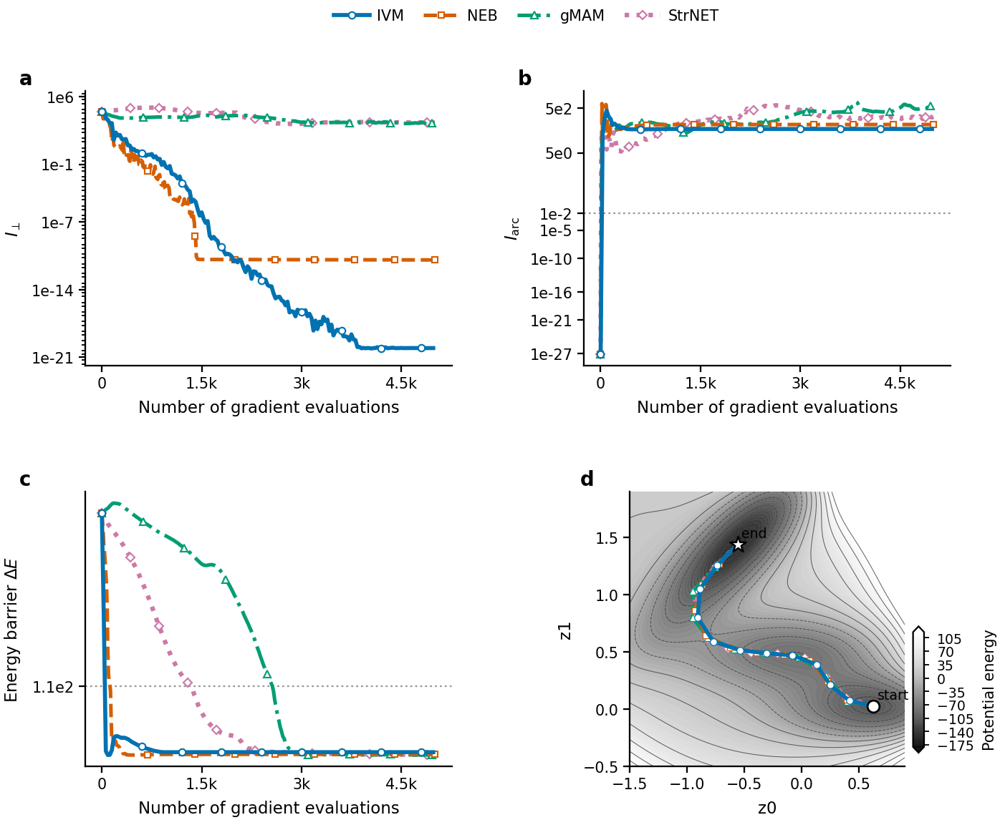

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/BestMethods_3metrics_contour/N10_BestMethods_1x3_lossperp_lossarc_deltaE_gradEvals_compressed.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/BestMethods_3metrics_contour/N10_BestMethods_1x3_lossperp_lossarc_deltaE_gradEvals_compressed.svg
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/BestMethods_3metrics_contour/N10_BestMethods_1x3_lossperp_lossarc_deltaE_gradEvals_compressed.png


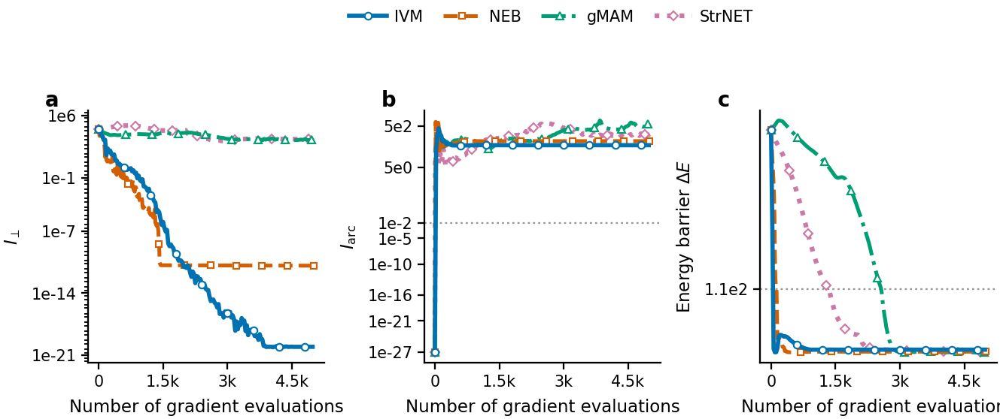

/tmp/ipykernel_171723/3038853110.py:2613: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=0.25)


Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/BestMethods_3metrics_contour/N10_BestMethods_contour_final_paths.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/BestMethods_3metrics_contour/N10_BestMethods_contour_final_paths.svg
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/BestMethods_3metrics_contour/N10_BestMethods_contour_final_paths.png


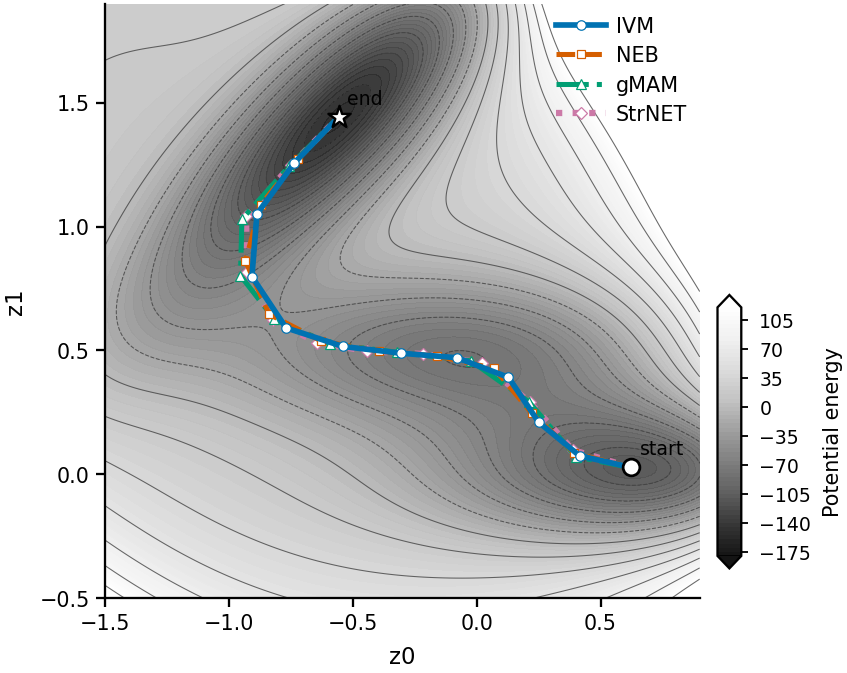


Done.
Figures and CSV saved to:
  /home/zqcai3/wzy/IVP_IVM/comparison_figures/BestMethods_3metrics_contour


In [11]:
# ============================================================
# Best-method comparison plot for IVM / NEB / gMAM
# Metrics:
#   1. loss_perp
#   2. loss_arc
#   3. Delta_Energy
# plus contour plot of final paths
# ============================================================

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

import csv
import re
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter, MaxNLocator
from matplotlib.gridspec import GridSpec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


# ============================================================
# 0. 全局配置
# ============================================================

base_dir = Path("/home/zqcai3/wzy/IVP_IVM")
q_data_path = Path("/home/zqcai3/wzy/IVP_new/Q_data.npz")

dimension = 10

# 你的实验是 N=20
n_images = 10

# ------------------------------------------------------------
# 是否纳入不同方法
# ------------------------------------------------------------

INCLUDE_IVM = True
INCLUDE_NEB = True
INCLUDE_GMAM = True

# 你这次没有给 StrNET 的最优参数，所以默认不画
# 如果之后需要加 StrNET，把这里改成 True，并设置 best_strnet_lr / best_strnet_c
INCLUDE_STRNET = True

# ------------------------------------------------------------
# 当前最优参数
# ------------------------------------------------------------

# IVM:
# 你说的 Nsub = 4, a = 0.01, st = 1500
# 这里的 best_ivm_alpha 对应目录名里的 alpha，也对应你说的 a
best_ivm_Nsub = 3
best_ivm_alpha = 5e-3
best_ivm_steps = 500

# NEB:
# 你说 NEB 最好的是 20
best_neb_string = 800
neb_alpha = 1e-4

# gMAM:
# 你说 gMAM 最好的是 c = 0.01, lr = 0.01
best_gmam_lr = 1e-2
best_gmam_c = 1e-1

# StrNET:
# 默认不画，仅当 INCLUDE_STRNET = True 时使用
best_strnet_lr = 1e-2
best_strnet_c = 1e-1

# ------------------------------------------------------------
# 结果文件优先级
# ------------------------------------------------------------
# 如果以后你保存中间结果，可以改成:
# RESULT_FILE_PRIORITY = ("results_partial.npz", "results.npz")
RESULT_FILE_PRIORITY = ("results.npz",)

# ------------------------------------------------------------
# 输出目录
# ------------------------------------------------------------

save_dir = base_dir / "comparison_figures" / "BestMethods_3metrics_contour"
save_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 绘图开关
# ------------------------------------------------------------

USE_COMPRESSED_Y = True

SAVE_2X2_PANEL = True
SAVE_1X3_METRICS = True
SAVE_CONTOUR_ONLY = True

SHOW_FIGURES = True
SHOW_GRID = False

SAVE_FORMATS = ("pdf", "svg", "png")
PNG_DPI = 600

# ------------------------------------------------------------
# 横坐标配置：number of gradient evaluations
# ------------------------------------------------------------

X_AXIS_KEY = "grad_count_seq"
X_AXIS_LABEL = "Number of gradient evaluations"

# 当前定义：
# 每个 count 对应 n_images 次 force / gradient evaluation
# 如果你的 IVM count_seq 已经包含 Nsub，例如 count_seq = i * Nsub，
# 那么这里不需要再乘 Nsub。
N_GRAD_EVALS_PER_COUNT = n_images

GRAD_EVALS_PER_COUNT_BY_METHOD = {
    "IVM": N_GRAD_EVALS_PER_COUNT,
    "NEB": N_GRAD_EVALS_PER_COUNT,
    "gMAM": N_GRAD_EVALS_PER_COUNT,
    "StrNET": N_GRAD_EVALS_PER_COUNT,
}

# 如果你之后确认 IVM 的 count_seq 没有包含 Nsub，
# 而你想把内部 Nsub 子步也算进 gradient evaluations，
# 可以改成:
# GRAD_EVALS_PER_COUNT_BY_METHOD["IVM"] = N_GRAD_EVALS_PER_COUNT * best_ivm_Nsub

# ------------------------------------------------------------
# Contour plot 配置
# ------------------------------------------------------------

CONTOUR_XLIM = (-1.5, 0.9)
CONTOUR_YLIM = (-0.5, 1.9)
CONTOUR_N_GRID = 320

POTENTIAL_LEVEL_MIN = -180.0
POTENTIAL_LEVEL_MAX = 120.0
POTENTIAL_N_LEVELS = 61

CONTOUR_LABELS = False
SHOW_CONTOUR_COLORBAR = True
SHOW_START_END = True

# ------------------------------------------------------------
# Delta Energy 插值密度
# ------------------------------------------------------------

DENSE_N_FOR_DELTA_E = 500

# 如果你的 numpy 版本比较旧，没有 np.trapezoid，就自动改用 np.trapz
try:
    trapz = np.trapezoid
except AttributeError:
    trapz = np.trapz


# ============================================================
# 1. Nature / Science 风格 Matplotlib 设置
# ============================================================

def mm_to_inch(mm):
    return mm / 25.4


def setup_publication_style():
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 7.0,
        "axes.labelsize": 7.5,
        "xtick.labelsize": 6.8,
        "ytick.labelsize": 6.8,
        "legend.fontsize": 6.8,

        "mathtext.fontset": "dejavusans",
        "mathtext.default": "it",

        "axes.linewidth": 0.75,
        "axes.spines.top": False,
        "axes.spines.right": False,

        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.width": 0.75,
        "ytick.major.width": 0.75,
        "xtick.minor.width": 0.6,
        "ytick.minor.width": 0.6,
        "xtick.major.size": 3.0,
        "ytick.major.size": 3.0,
        "xtick.minor.size": 1.8,
        "ytick.minor.size": 1.8,

        "legend.frameon": False,
        "legend.handlelength": 2.2,
        "legend.handletextpad": 0.5,
        "legend.borderaxespad": 0.4,

        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",

        "figure.dpi": 180,
        "savefig.dpi": PNG_DPI,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.02,
        "savefig.transparent": False,
    })


setup_publication_style()


# ============================================================
# 2. Müller-10 势能
# ============================================================

Q_np = np.load(q_data_path)["Q"]

a_np = np.array([-1.0, -1.0, -6.5, 0.7], dtype=float)
b_np = np.array([0.0, 0.0, 11.0, 0.6], dtype=float)
c_np = np.array([-10.0, -10.0, -6.5, 0.7], dtype=float)
D_np = np.array([-200.0, -100.0, -170.0, 15.0], dtype=float)
X_np = np.array([1.0, 0.0, -0.5, -1.0], dtype=float)
Y_np = np.array([0.0, 0.5, 1.5, 1.0], dtype=float)
sigma = 0.5


def V_muller10_np(x_vec):
    """
    Müller-10 势能，支持单点和批量输入。

    参数:
        x_vec: shape (10,) 或 (N, 10)

    返回:
        单点输入 -> float
        批量输入 -> shape (N,) numpy array
    """
    x = np.asarray(x_vec, dtype=float)
    single_input = x.ndim == 1

    if single_input:
        x = x.reshape(1, dimension)
    elif x.ndim != 2 or x.shape[1] != dimension:
        raise ValueError(
            f"Input must have shape ({dimension},) or (N,{dimension}), got {x.shape}"
        )

    z = x @ Q_np

    z0 = z[:, 0]
    z1 = z[:, 1]
    rest = z[:, 2:]

    V = np.zeros(z.shape[0], dtype=float)

    for i in range(4):
        exponent = (
            a_np[i] * (z0 - X_np[i]) ** 2
            + b_np[i] * (z0 - X_np[i]) * (z1 - Y_np[i])
            + c_np[i] * (z1 - Y_np[i]) ** 2
        )
        V += D_np[i] * np.exp(exponent)

    V += np.sum((1.0 / (2.0 * sigma ** 2)) * rest ** 2, axis=1)

    if single_input:
        return float(V[0])

    return V


# ============================================================
# 3. 指标计算函数
# ============================================================

def compute_path_derivatives(images_seq):
    """
    images_seq: shape (T, N, d)

    返回:
        s: shape (N,)
        phi_s: shape (T, N, d)
        phi_ss: shape (T, N, d)
        speed: shape (T, N)
    """
    images_seq = np.asarray(images_seq, dtype=float)

    if images_seq.ndim != 3:
        raise ValueError(
            f"images_seq must have shape (T, N, d), got {images_seq.shape}"
        )

    T, N, d = images_seq.shape

    s = np.linspace(0.0, 1.0, N)
    edge_order = 2 if N >= 3 else 1

    phi_s = np.gradient(images_seq, s, axis=1, edge_order=edge_order)
    phi_ss = np.gradient(phi_s, s, axis=1, edge_order=edge_order)

    speed = np.linalg.norm(phi_s, axis=2)

    return s, phi_s, phi_ss, speed


def line_integral_force_quantity(q_force, speed, N_path):
    """
    对定义在 force 网格上的 quantity 做 line integral。

    支持:
        N_force = N_path - 2
        N_force = N_path - 1
        N_force = N_path
        其他情况用插值兜底
    """
    q_force = np.asarray(q_force, dtype=float)
    speed = np.asarray(speed, dtype=float)

    if q_force.ndim != 2:
        raise ValueError(
            f"q_force must have shape (T, N_force), got {q_force.shape}"
        )

    if speed.ndim != 2:
        raise ValueError(
            f"speed must have shape (T, N_path), got {speed.shape}"
        )

    T, N_force = q_force.shape
    ds = 1.0 / (N_path - 1)

    if N_force == N_path - 2:
        speed_force = speed[:, 1:-1]
        return np.sum(q_force * speed_force, axis=1) * ds

    elif N_force == N_path - 1:
        speed_force = speed[:, :-1]
        return np.sum(q_force * speed_force, axis=1) * ds

    elif N_force == N_path:
        s = np.linspace(0.0, 1.0, N_path)
        return trapz(q_force * speed, s, axis=1)

    else:
        s_path = np.linspace(0.0, 1.0, N_path)
        s_force = np.linspace(0.0, 1.0, N_force)

        speed_force = np.empty((T, N_force), dtype=float)

        for i in range(T):
            speed_force[i] = np.interp(s_force, s_path, speed[i])

        return trapz(q_force * speed_force, s_force, axis=1)


def compute_delta_energy(images_seq, V_func, dense_n=500, E_min=None):
    """
    计算:
        Delta_Energy = max_s V(phi(s)) - E_min

    默认:
        E_min = min V(images_seq[0])
    """
    images_seq = np.asarray(images_seq, dtype=float)

    if images_seq.ndim != 3:
        raise ValueError(
            f"images_seq must have shape (T, N, d), got {images_seq.shape}"
        )

    T, N, d = images_seq.shape

    t_old = np.linspace(0.0, 1.0, N)
    t_new = np.linspace(0.0, 1.0, dense_n)

    if E_min is None:
        E0 = V_func(images_seq[0])
        E_min = float(np.min(E0))

    Delta_Energy = np.empty(T, dtype=float)

    for i in range(T):
        X = images_seq[i]

        X_dense = np.column_stack([
            np.interp(t_new, t_old, X[:, dim])
            for dim in range(d)
        ])

        E_dense = V_func(X_dense)
        Delta_Energy[i] = float(np.max(E_dense) - E_min)

    return Delta_Energy


def compute_selected_metrics(
    images_seq,
    count_seq,
    F_perp,
    V_func,
):
    """
    计算三个指标:
        loss_perp
        loss_arc
        Delta_Energy
    """
    images_seq = np.asarray(images_seq, dtype=float)
    count_seq = np.asarray(count_seq, dtype=float).reshape(-1)
    F_perp = np.asarray(F_perp, dtype=float)

    if images_seq.ndim != 3:
        raise ValueError(
            f"images_seq must have shape (T, N_path, d), got {images_seq.shape}"
        )

    if F_perp.ndim != 3:
        raise ValueError(
            f"F_perp must have shape (T, N_force, d), got {F_perp.shape}"
        )

    T = min(
        images_seq.shape[0],
        count_seq.shape[0],
        F_perp.shape[0],
    )

    images_seq = images_seq[:T]
    count_seq = count_seq[:T]
    F_perp = F_perp[:T]

    T, N_path, d = images_seq.shape

    s, phi_s, phi_ss, speed = compute_path_derivatives(images_seq)

    # ------------------------------------------------------------
    # loss_perp = integral |F_perp|^2 |phi'(s)| ds
    # ------------------------------------------------------------
    F_perp_norm_sq = np.sum(F_perp ** 2, axis=2)

    loss_perp = line_integral_force_quantity(
        q_force=F_perp_norm_sq,
        speed=speed,
        N_path=N_path,
    )

    # ------------------------------------------------------------
    # loss_arc = integral (<phi'(s), phi''(s)>)^2 |phi'(s)| ds
    # ------------------------------------------------------------
    inner_phi_s_phi_ss = np.sum(phi_s * phi_ss, axis=2)
    arc_integrand = inner_phi_s_phi_ss ** 2 * speed

    loss_arc = trapz(arc_integrand, s, axis=1)

    # ------------------------------------------------------------
    # Delta_Energy
    # ------------------------------------------------------------
    Delta_Energy = compute_delta_energy(
        images_seq=images_seq,
        V_func=V_func,
        dense_n=DENSE_N_FOR_DELTA_E,
        E_min=None,
    )

    return {
        "count_seq": count_seq,
        "loss_perp": loss_perp,
        "loss_arc": loss_arc,
        "Delta_Energy": Delta_Energy,
    }


def add_gradient_eval_count_to_run(run):
    """
    给每个 run 的 metrics 新增:
        grad_count_seq = count_seq * grad_evals_per_count
    """
    method = run.get("method", "")
    factor = GRAD_EVALS_PER_COUNT_BY_METHOD.get(
        method,
        N_GRAD_EVALS_PER_COUNT,
    )

    m = run["metrics"]
    count_seq = np.asarray(m["count_seq"], dtype=float).reshape(-1)

    m["grad_count_seq"] = count_seq * float(factor)
    m["grad_evals_per_count"] = float(factor)

    return run


# ============================================================
# 4. 文件搜索工具函数
# ============================================================

def candidate_float_strings(v):
    """
    生成多个可能的浮点数字符串，用来兼容不同文件名。
    例如:
        0.01, 1e-2, 1e-02, 1.0e-02
    """
    out = []

    def add(s):
        if s is None:
            return

        s = str(s)
        variants = [s]

        if "E" in s:
            variants.append(s.replace("E", "e"))

        if "e" in s or "E" in s:
            ss = s.replace("E", "e")
            variants.append(ss.replace("e-0", "e-").replace("e+0", "e+"))

        for item in variants:
            if item not in out:
                out.append(item)

    add(str(v))

    try:
        fv = float(v)

        add(str(fv))
        add(f"{fv:g}")
        add(f"{fv:.1e}")
        add(f"{fv:.0e}")

        for nd in [2, 3, 4, 5, 6, 8, 10, 12]:
            add(f"{fv:.{nd}g}")

        for nd in [1, 2, 3, 4, 5, 6, 8, 10, 12]:
            s = f"{fv:.{nd}f}".rstrip("0").rstrip(".")
            if s == "-0":
                s = "0"
            add(s)

        if fv.is_integer():
            add(str(int(fv)))

    except Exception:
        pass

    return out


def get_data_dir(base_dir, data_subdir="Data"):
    """
    允许 base_dir 是:
        /home/zqcai3/wzy/IVP_IVM

    或者:
        /home/zqcai3/wzy/IVP_IVM/Data
    """
    base_dir = Path(base_dir)

    if base_dir.name == data_subdir:
        return base_dir

    return base_dir / data_subdir


def method_tag_candidates(method_tag):
    """
    兼容大小写不同的 gMAM / StrNET 文件名。
    """
    m = method_tag.lower()

    if m == "gmam":
        return ["gMAM", "GMAM", "gmam", "Gmam"]

    if m == "strnet":
        return ["StrNET", "STRNET", "strnet", "StrNet"]

    return [method_tag]


def load_npz_run(file_path, method, label, details):
    """
    通用读取函数。

    必需字段:
        images_seq
        count_seq
        F_perp

    可选字段:
        F_original
    """
    file_path = Path(file_path)
    loaded = np.load(file_path, allow_pickle=True)

    required = [
        "images_seq",
        "count_seq",
        "F_perp",
    ]

    missing = [
        k for k in required
        if k not in loaded.files
    ]

    if len(missing) > 0:
        raise KeyError(
            f"{file_path} missing required keys: {missing}\n"
            f"Available keys: {loaded.files}"
        )

    run = {
        "method": method,
        "label": label,
        "details": details,
        "file": file_path,
        "images_seq": loaded["images_seq"],
        "count_seq": loaded["count_seq"],
        "F_perp": loaded["F_perp"],
    }

    if "F_original" in loaded.files:
        run["F_original"] = loaded["F_original"]

    return run


def parse_ivm_alpha_from_folder_name(folder_name, n_images, Nsub, steps):
    """
    解析目录:
        M10_IVM_images_N20_Nsub4_alpha0.01_steps1500
    或:
        M10_IVM_images_N20_Nsub4_a0.01_steps1500
    """
    pattern = (
        rf"^M10_IVM_images_N{n_images}_"
        rf"Nsub{Nsub}_"
        rf"(?:alpha|a)(?P<alpha>[^_]+)_"
        rf"steps{steps}$"
    )

    m = re.match(pattern, folder_name)

    if m is None:
        return None

    try:
        return float(m.group("alpha"))
    except Exception:
        return None


# ============================================================
# 5. 读取 IVM / NEB / gMAM / StrNET
# ============================================================

def load_ivm_best_run(
    base_dir,
    n_images,
    Nsub,
    alpha,
    steps,
):
    """
    读取当前新版 IVM 结果。

    优先搜索:
        M10_IVM_images_N20_Nsub4_alpha0.01_steps1500/results.npz

    也兼容:
        M10_IVM_images_N20_Nsub4_a0.01_steps1500/results.npz
    """
    base_dir = Path(base_dir)

    alpha_candidates = candidate_float_strings(alpha)

    tried = []
    candidates = []

    # ------------------------------------------------------------
    # 1. 精确路径搜索
    # ------------------------------------------------------------
    for alpha_s in alpha_candidates:
        folder_names = [
            f"M10_IVM_images_N{n_images}_Nsub{Nsub}_alpha{alpha_s}_steps{steps}",
            f"M10_IVM_images_N{n_images}_Nsub{Nsub}_a{alpha_s}_steps{steps}",
        ]

        for folder_name in folder_names:
            folder = base_dir / folder_name

            for fname in RESULT_FILE_PRIORITY:
                p = folder / fname
                tried.append(p)

                if p.exists():
                    candidates.append(p)

    if len(candidates) > 0:
        file_path = candidates[0]

        return load_npz_run(
            file_path=file_path,
            method="IVM",
            label="IVM",
            details=f"IVM, Nsub={Nsub}, alpha={alpha:g}, steps={steps}",
        )

    # ------------------------------------------------------------
    # 2. glob 搜索
    # ------------------------------------------------------------
    folder_patterns = [
        f"M10_IVM_images_N{n_images}_Nsub{Nsub}_alpha*_steps{steps}",
        f"M10_IVM_images_N{n_images}_Nsub{Nsub}_a*_steps{steps}",
        f"**/M10_IVM_images_N{n_images}_Nsub{Nsub}_alpha*_steps{steps}",
        f"**/M10_IVM_images_N{n_images}_Nsub{Nsub}_a*_steps{steps}",
    ]

    glob_folders = []

    for pattern in folder_patterns:
        glob_folders.extend(base_dir.glob(pattern))

    glob_folders = [
        p for p in glob_folders
        if p.is_dir()
    ]

    # 去重
    seen = set()
    unique_folders = []

    for p in glob_folders:
        ps = str(p.resolve())

        if ps not in seen:
            unique_folders.append(p)
            seen.add(ps)

    for folder in unique_folders:
        alpha_val = parse_ivm_alpha_from_folder_name(
            folder.name,
            n_images=n_images,
            Nsub=Nsub,
            steps=steps,
        )

        if alpha_val is not None:
            if not np.isclose(alpha_val, float(alpha), rtol=1e-10, atol=1e-14):
                continue

        for fname in RESULT_FILE_PRIORITY:
            p = folder / fname

            if p.exists():
                candidates.append(p)

    if len(candidates) > 0:
        def score_file(p):
            alpha_val = parse_ivm_alpha_from_folder_name(
                p.parent.name,
                n_images=n_images,
                Nsub=Nsub,
                steps=steps,
            )

            if alpha_val is None:
                alpha_score = 1e99
            else:
                alpha_score = abs(alpha_val - float(alpha))

            try:
                priority_score = RESULT_FILE_PRIORITY.index(p.name)
            except ValueError:
                priority_score = 999

            return (
                alpha_score,
                priority_score,
                len(str(p)),
                str(p),
            )

        candidates = sorted(candidates, key=score_file)
        file_path = candidates[0]

        return load_npz_run(
            file_path=file_path,
            method="IVM",
            label="IVM",
            details=f"IVM, Nsub={Nsub}, alpha={alpha:g}, steps={steps}",
        )

    tried_preview = "\n".join([f"  {p}" for p in tried[:60]])

    raise FileNotFoundError(
        f"Could not find IVM result for:\n"
        f"  N={n_images}, Nsub={Nsub}, alpha={alpha}, steps={steps}\n\n"
        f"Expected folder like:\n"
        f"  {base_dir}/M10_IVM_images_N{n_images}_Nsub{Nsub}_alpha{alpha:g}_steps{steps}/results.npz\n\n"
        f"Some tried paths:\n{tried_preview}"
    )


def load_neb_best_run(
    base_dir,
    n_images,
    k_neb=20,
    alpha_neb=1e-4,
):
    """
    读取 NEB 最优数据。

    优先搜索:
        M10_neb/N22_k20_alpha1e-04_ode_results.npz

    也会兼容 N20 和不同 alpha 字符串写法。
    """
    base_dir = Path(base_dir)
    neb_dirs = [
        base_dir / "M10_neb",
        base_dir,
    ]

    N_candidates = [
        n_images + 2,
        n_images,
    ]

    alpha_candidates = candidate_float_strings(alpha_neb)

    tried = []
    candidates = []

    # ------------------------------------------------------------
    # 1. 精确路径搜索
    # ------------------------------------------------------------
    for neb_dir in neb_dirs:
        for N_tag in N_candidates:
            for alpha_s in alpha_candidates:
                p = neb_dir / f"N{N_tag}_k{k_neb}_alpha{alpha_s}_ode_results.npz"
                tried.append(p)

                if p.exists():
                    candidates.append(p)

    if len(candidates) > 0:
        file_path = candidates[0]

        return load_npz_run(
            file_path=file_path,
            method="NEB",
            label="NEB",
            details=f"NEB, k={k_neb}",
        )

    # ------------------------------------------------------------
    # 2. glob 搜索
    # ------------------------------------------------------------
    for neb_dir in neb_dirs:
        if not neb_dir.exists():
            continue

        for N_tag in N_candidates:
            pattern = f"N{N_tag}_k{k_neb}_alpha*_ode_results.npz"
            candidates.extend(neb_dir.glob(pattern))

        # 递归兜底
        pattern = f"**/N*_k{k_neb}_alpha*_ode_results.npz"
        candidates.extend(neb_dir.glob(pattern))

    candidates = [
        p for p in candidates
        if p.is_file()
    ]

    # 去重
    seen = set()
    unique_candidates = []

    for p in candidates:
        ps = str(p.resolve())

        if ps not in seen:
            unique_candidates.append(p)
            seen.add(ps)

    if len(unique_candidates) > 0:
        def score_neb_file(p):
            name = p.name

            score_N = 999
            for i, N_tag in enumerate(N_candidates):
                if f"N{N_tag}_" in name:
                    score_N = i
                    break

            score_alpha = 999
            for i, alpha_s in enumerate(alpha_candidates):
                if f"alpha{alpha_s}_" in name:
                    score_alpha = i
                    break

            return (
                score_N,
                score_alpha,
                len(str(p)),
                str(p),
            )

        unique_candidates = sorted(unique_candidates, key=score_neb_file)
        file_path = unique_candidates[0]

        return load_npz_run(
            file_path=file_path,
            method="NEB",
            label="NEB",
            details=f"NEB, k={k_neb}",
        )

    tried_preview = "\n".join([f"  {p}" for p in tried[:60]])

    raise FileNotFoundError(
        f"Could not find NEB file for k/string={k_neb}, alpha={alpha_neb}.\n"
        f"Some tried paths:\n{tried_preview}"
    )


def find_param_method_npz(
    base_dir,
    method_tag,
    n_images,
    lr,
    c,
    data_subdir="Data",
):
    """
    搜索 gMAM / StrNET 的 npz 文件。
    """
    data_dir = get_data_dir(base_dir, data_subdir=data_subdir)

    if not data_dir.exists():
        raise FileNotFoundError(f"Data directory does not exist: {data_dir}")

    lr_candidates = candidate_float_strings(lr)
    c_candidates = candidate_float_strings(c)
    tag_candidates = method_tag_candidates(method_tag)

    tried = []

    # ------------------------------------------------------------
    # 1. 精确候选路径
    # ------------------------------------------------------------
    for tag in tag_candidates:
        for lr_s in lr_candidates:
            for c_s in c_candidates:

                case_candidates = [
                    f"M10_N{n_images}_Images_{tag}_lr{lr_s}_c{c_s}",
                    f"M10_N{n_images}_{tag}_lr{lr_s}_c{c_s}",
                    f"M10_N{n_images}_Images_{tag}_c{c_s}_lr{lr_s}",
                    f"M10_N{n_images}_{tag}_c{c_s}_lr{lr_s}",

                    # 兼容旧代码里可能出现的 c3 写法
                    f"M10_N{n_images}_Images_{tag}_lr{lr_s}_c3{c_s}",
                    f"M10_N{n_images}_{tag}_lr{lr_s}_c3{c_s}",
                ]

                for casenum in case_candidates:
                    exact_paths = [
                        data_dir / casenum / f"M10_{casenum}.npz",
                        data_dir / casenum / f"{casenum}.npz",
                        data_dir / casenum / f"M10_{casenum}_results.npz",
                        data_dir / casenum / "results.npz",
                        data_dir / f"M10_{casenum}.npz",
                        data_dir / f"{casenum}.npz",
                    ]

                    for p in exact_paths:
                        tried.append(p)

                        if p.exists():
                            return p

                    folder = data_dir / casenum

                    if folder.exists() and folder.is_dir():
                        npz_files = sorted(folder.glob("*.npz"))

                        if len(npz_files) > 0:
                            return npz_files[0]

    # ------------------------------------------------------------
    # 2. glob 递归搜索
    # ------------------------------------------------------------
    glob_matches = []

    for tag in tag_candidates:
        for lr_s in lr_candidates:
            for c_s in c_candidates:
                patterns = [
                    f"**/*N{n_images}*{tag}*lr{lr_s}*c{c_s}*.npz",
                    f"**/*N{n_images}*{tag}*c{c_s}*lr{lr_s}*.npz",
                    f"**/*N{n_images}*{tag}*lr{lr_s}*c3{c_s}*.npz",
                ]

                for pattern in patterns:
                    glob_matches.extend(data_dir.glob(pattern))

    glob_matches = [
        p for p in glob_matches
        if p.is_file()
    ]

    unique_matches = []
    seen = set()

    for p in glob_matches:
        ps = str(p.resolve())

        if ps not in seen:
            unique_matches.append(p)
            seen.add(ps)

    if len(unique_matches) > 0:
        unique_matches = sorted(
            unique_matches,
            key=lambda p: (
                0 if "Images" in str(p) else 1,
                len(str(p)),
                str(p),
            )
        )

        return unique_matches[0]

    tried_preview = "\n".join([f"  {p}" for p in tried[:80]])

    raise FileNotFoundError(
        f"Could not find npz file for method={method_tag}, "
        f"N={n_images}, lr={lr}, c={c}.\n"
        f"Data dir:\n  {data_dir}\n\n"
        f"Some tried paths:\n{tried_preview}\n"
    )


def load_param_method_best_run(
    base_dir,
    method_tag,
    n_images,
    lr,
    c,
    data_subdir="Data",
):
    """
    读取 gMAM 或 StrNET 最优参数数据。
    """
    file_path = find_param_method_npz(
        base_dir=base_dir,
        method_tag=method_tag,
        n_images=n_images,
        lr=lr,
        c=c,
        data_subdir=data_subdir,
    )

    method_lower = method_tag.lower()

    if method_lower == "gmam":
        method_name = "gMAM"
    elif method_lower == "strnet":
        method_name = "StrNET"
    else:
        method_name = method_tag

    return load_npz_run(
        file_path=file_path,
        method=method_name,
        label=method_name,
        details=f"{method_name}, lr={lr:g}, c={c:g}",
    )


# ============================================================
# 6. Publication-style 绘图工具
# ============================================================

Y_TICK_LABEL_STYLE = "e"
Y_TICK_SIG_DIGITS = 2

COMPRESS_Y_CONFIG = {
    "loss_arc": {
        "threshold": 1e-2,
        "side": "below",
        "factor": 0.25,
        "tick_multipliers_normal": (1, 2, 5),
        "tick_multipliers_compressed": (1,),
        "compressed_tick_every": 1,
        "max_total_ticks": 8,
        "force_threshold_tick": True,
    },
    "Delta_Energy": {
        "threshold": 1.1e2,
        "side": "above",
        "factor": 0.25,
        "tick_multipliers_normal": (1, 2, 5),
        "tick_multipliers_compressed": (1,),
        "compressed_tick_every": 1,
        "max_total_ticks": 8,
        "force_threshold_tick": True,
    },
}

# Okabe-Ito / colorblind-friendly palette
METHOD_STYLE = {
    "IVM": {
        "linestyle": "-",
        "linewidth": 1.85,
        "color": "#0072B2",
        "marker": "o",
        "markersize": 3.1,
        "zorder": 5,
    },
    "NEB": {
        "linestyle": "--",
        "linewidth": 1.65,
        "color": "#D55E00",
        "marker": "s",
        "markersize": 2.9,
        "zorder": 4,
    },
    "gMAM": {
        "linestyle": "-.",
        "linewidth": 1.65,
        "color": "#009E73",
        "marker": "^",
        "markersize": 3.1,
        "zorder": 3,
    },
    "StrNET": {
        "linestyle": ":",
        "linewidth": 2.05,
        "color": "#CC79A7",
        "marker": "D",
        "markersize": 2.8,
        "zorder": 2,
    },
}

METRIC_INFO = {
    "loss_perp": {
        "ylabel": r"$I_{\perp}$",
        "panel": "a",
    },
    "loss_arc": {
        "ylabel": r"$I_{\mathrm{arc}}$",
        "panel": "b",
    },
    "Delta_Energy": {
        "ylabel": r"Energy barrier $\Delta E$",
        "panel": "c",
    },
}


def get_plot_style(run):
    method = run.get("method", "")

    default_style = {
        "linestyle": "-",
        "linewidth": 1.4,
        "color": "black",
        "marker": None,
        "markersize": 2.8,
        "zorder": 1,
    }

    return METHOD_STYLE.get(method, default_style)


def format_tick_label_sci(v, sig_digits=2, style="e"):
    """
    把原始 y 数值格式化成科学计数法。
    """
    if not np.isfinite(v):
        return ""

    if v == 0:
        return "0"

    sign = "-" if v < 0 else ""
    av = abs(float(v))

    exponent = int(np.floor(np.log10(av)))
    mantissa = av / (10.0 ** exponent)

    mantissa_str = f"{mantissa:.{sig_digits}g}"
    mantissa_val = float(mantissa_str)

    if mantissa_val >= 10.0:
        mantissa_val = mantissa_val / 10.0
        exponent += 1
        mantissa_str = f"{mantissa_val:.{sig_digits}g}"

    if style == "e":
        return f"{sign}{mantissa_str}e{exponent}"

    elif style == "times":
        return f"{sign}{mantissa_str}×10^{exponent}"

    else:
        raise ValueError("style must be either 'e' or 'times'.")


def mpl_sci_formatter(y, pos=None):
    if not np.isfinite(y) or y <= 0:
        return ""

    return format_tick_label_sci(
        y,
        sig_digits=Y_TICK_SIG_DIGITS,
        style=Y_TICK_LABEL_STYLE,
    )


def apply_scientific_y_formatter(ax):
    ax.yaxis.set_major_formatter(FuncFormatter(mpl_sci_formatter))


def count_formatter(x, pos=None):
    """
    横坐标格式。
    当前横坐标是 number of gradient evaluations。
    """
    if not np.isfinite(x):
        return ""

    ax_abs = abs(x)

    if ax_abs >= 1e6:
        return f"{x / 1e6:g}M"

    if ax_abs >= 1e3:
        return f"{x / 1e3:g}k"

    if abs(x - round(x)) < 1e-8:
        return f"{int(round(x))}"

    return f"{x:g}"


def get_x_values_for_run(run):
    """
    获取绘图横坐标。

    默认优先使用:
        grad_count_seq

    如果没有，则退回:
        count_seq
    """
    m = run["metrics"]

    if X_AXIS_KEY in m:
        return m[X_AXIS_KEY]

    return m["count_seq"]


def compressed_log10_transform(y, threshold, side="above", factor=0.25):
    """
    在 log10(y) 空间做局部压缩。
    """
    y = np.asarray(y, dtype=float)

    z = np.log10(y)
    z0 = np.log10(threshold)

    z_new = z.copy()

    if side == "above":
        mask = z > z0
        z_new[mask] = z0 + factor * (z[mask] - z0)

    elif side == "below":
        mask = z < z0
        z_new[mask] = z0 + factor * (z[mask] - z0)

    else:
        raise ValueError("side must be either 'above' or 'below'.")

    return z_new


def is_in_compressed_region(v, threshold, side):
    if threshold is None or side is None:
        return False

    if side == "above":
        return v > threshold

    elif side == "below":
        return v < threshold

    else:
        raise ValueError("side must be either 'above' or 'below'.")


def unique_sorted(values):
    values = [
        float(v)
        for v in values
        if np.isfinite(v)
    ]

    values = sorted(values)

    if len(values) == 0:
        return []

    out = [values[0]]

    for v in values[1:]:
        if not np.isclose(v, out[-1], rtol=1e-12, atol=0.0):
            out.append(v)

    return out


def downsample_keep_ends(values, max_n):
    values = list(values)

    if max_n is None:
        return values

    if len(values) <= max_n:
        return values

    if max_n <= 0:
        return []

    if max_n == 1:
        return [values[len(values) // 2]]

    idx = np.linspace(0, len(values) - 1, max_n)
    idx = np.round(idx).astype(int)
    idx = sorted(set(idx.tolist()))

    while len(idx) > max_n:
        idx.pop(-2)

    return [
        values[i]
        for i in idx
    ]


def thin_compressed_ticks(ticks, threshold, side, compressed_tick_every=1):
    ticks = unique_sorted(ticks)

    if compressed_tick_every is None or compressed_tick_every <= 1:
        return ticks

    normal_ticks = []
    compressed_ticks = []

    for t in ticks:
        if is_in_compressed_region(t, threshold, side):
            compressed_ticks.append(t)
        else:
            normal_ticks.append(t)

    compressed_ticks = [
        t for i, t in enumerate(compressed_ticks)
        if i % compressed_tick_every == 0
    ]

    return unique_sorted(normal_ticks + compressed_ticks)


def enforce_max_total_ticks(
    ticks,
    max_total_ticks,
    threshold=None,
    force_threshold_tick=True,
):
    ticks = unique_sorted(ticks)

    if max_total_ticks is None:
        return ticks

    if len(ticks) <= max_total_ticks:
        return ticks

    ticks_new = downsample_keep_ends(ticks, max_total_ticks)

    if (
        force_threshold_tick
        and threshold is not None
        and any(np.isclose(t, threshold, rtol=1e-12, atol=0.0) for t in ticks)
        and not any(np.isclose(t, threshold, rtol=1e-12, atol=0.0) for t in ticks_new)
    ):
        log_ticks_new = np.log10(np.asarray(ticks_new))
        log_threshold = np.log10(threshold)

        idx_replace = int(np.argmin(np.abs(log_ticks_new - log_threshold)))
        ticks_new[idx_replace] = float(threshold)
        ticks_new = unique_sorted(ticks_new)

    return ticks_new


def make_log_ticks(
    y_min,
    y_max,
    threshold=None,
    side=None,
    tick_multipliers_normal=(1, 2, 5),
    tick_multipliers_compressed=(1,),
    compressed_tick_every=1,
    max_total_ticks=8,
    force_threshold_tick=True,
):
    y_min = float(y_min)
    y_max = float(y_max)

    if y_min <= 0 or y_max <= 0:
        return []

    if y_min > y_max:
        y_min, y_max = y_max, y_min

    e_min = int(np.floor(np.log10(y_min)))
    e_max = int(np.ceil(np.log10(y_max)))

    multipliers_all = sorted(
        set(list(tick_multipliers_normal) + list(tick_multipliers_compressed))
    )

    ticks = []

    for e in range(e_min, e_max + 1):
        for m in multipliers_all:
            v = m * (10.0 ** e)

            if not (y_min <= v <= y_max):
                continue

            if threshold is None or side is None:
                if m in tick_multipliers_normal:
                    ticks.append(v)
            else:
                if is_in_compressed_region(v, threshold, side):
                    if m in tick_multipliers_compressed:
                        ticks.append(v)
                else:
                    if m in tick_multipliers_normal:
                        ticks.append(v)

    if (
        force_threshold_tick
        and threshold is not None
        and y_min <= threshold <= y_max
    ):
        ticks.append(float(threshold))

    ticks = unique_sorted(ticks)

    if len(ticks) == 0:
        ticks = [y_min, y_max]

        if threshold is not None and y_min <= threshold <= y_max:
            ticks.append(float(threshold))

        ticks = unique_sorted(ticks)

    if threshold is not None and side is not None:
        ticks = thin_compressed_ticks(
            ticks,
            threshold=threshold,
            side=side,
            compressed_tick_every=compressed_tick_every,
        )

    ticks = enforce_max_total_ticks(
        ticks,
        max_total_ticks=max_total_ticks,
        threshold=threshold,
        force_threshold_tick=force_threshold_tick,
    )

    return ticks


def get_markevery(x, target_markers=8):
    x = np.asarray(x).reshape(-1)
    n = x.size

    if n <= 1:
        return 1

    return max(n // target_markers, 1)


def plot_compressed_logy_safe(
    ax,
    x,
    y,
    label,
    threshold,
    side="above",
    factor=0.25,
    linestyle="-",
    linewidth=1.5,
    color=None,
    marker=None,
    markersize=3.0,
    markevery=1,
    zorder=1,
):
    """
    画局部压缩后的 log-y 曲线。
    """
    x = np.asarray(x).reshape(-1)
    y = np.asarray(y).reshape(-1)

    mask = np.isfinite(x) & np.isfinite(y) & (y > 0)

    if np.count_nonzero(mask) == 0:
        print(f"[Warning] {label}: no positive finite values for compressed log-y plot.")
        return None

    x_valid = x[mask]
    y_valid = y[mask]

    y_plot = compressed_log10_transform(
        y_valid,
        threshold=threshold,
        side=side,
        factor=factor,
    )

    ax.plot(
        x_valid,
        y_plot,
        label=label,
        linestyle=linestyle,
        linewidth=linewidth,
        color=color,
        marker=marker,
        markersize=markersize,
        markerfacecolor="white",
        markeredgewidth=0.7,
        markevery=markevery,
        zorder=zorder,
    )

    return y_valid


def set_compressed_logy_axis(
    ax,
    y_values_all,
    threshold,
    side="above",
    factor=0.25,
    tick_multipliers_normal=(1, 2, 5),
    tick_multipliers_compressed=(1,),
    compressed_tick_every=1,
    max_total_ticks=8,
    force_threshold_tick=True,
):
    """
    给局部压缩后的 log-y 图设置 y ticks 和标签。
    """
    y_values_all = np.asarray(y_values_all, dtype=float)
    y_values_all = y_values_all[np.isfinite(y_values_all) & (y_values_all > 0)]

    if y_values_all.size == 0:
        return

    y_min = np.min(y_values_all)
    y_max = np.max(y_values_all)

    ticks_original = make_log_ticks(
        y_min=y_min,
        y_max=y_max,
        threshold=threshold,
        side=side,
        tick_multipliers_normal=tick_multipliers_normal,
        tick_multipliers_compressed=tick_multipliers_compressed,
        compressed_tick_every=compressed_tick_every,
        max_total_ticks=max_total_ticks,
        force_threshold_tick=force_threshold_tick,
    )

    ticks_transformed = compressed_log10_transform(
        np.asarray(ticks_original),
        threshold=threshold,
        side=side,
        factor=factor,
    )

    ax.set_yticks(ticks_transformed)

    ax.set_yticklabels([
        format_tick_label_sci(
            v,
            sig_digits=Y_TICK_SIG_DIGITS,
            style=Y_TICK_LABEL_STYLE,
        )
        for v in ticks_original
    ])

    y_all_transformed = compressed_log10_transform(
        y_values_all,
        threshold=threshold,
        side=side,
        factor=factor,
    )

    y_low = np.min(y_all_transformed)
    y_high = np.max(y_all_transformed)

    pad = 0.045 * max(y_high - y_low, 1e-12)

    ax.set_ylim(y_low - pad, y_high + pad)

    if y_min <= threshold <= y_max:
        threshold_transformed = compressed_log10_transform(
            np.asarray([threshold]),
            threshold=threshold,
            side=side,
            factor=factor,
        )[0]

        ax.axhline(
            threshold_transformed,
            color="0.55",
            linestyle=(0, (1.2, 1.8)),
            linewidth=0.75,
            alpha=0.9,
            zorder=0,
        )

    ax.minorticks_off()


def semilogy_safe(
    ax,
    x,
    y,
    label,
    linestyle="-",
    linewidth=1.5,
    color=None,
    marker=None,
    markersize=3.0,
    markevery=1,
    zorder=1,
):
    """
    普通 semilogy。
    """
    x = np.asarray(x).reshape(-1)
    y = np.asarray(y).reshape(-1)

    mask = np.isfinite(x) & np.isfinite(y) & (y > 0)

    if np.count_nonzero(mask) == 0:
        print(f"[Warning] {label}: no positive finite values for semilogy.")
        return

    ax.semilogy(
        x[mask],
        y[mask],
        label=label,
        linestyle=linestyle,
        linewidth=linewidth,
        color=color,
        marker=marker,
        markersize=markersize,
        markerfacecolor="white",
        markeredgewidth=0.7,
        markevery=markevery,
        zorder=zorder,
    )


def style_standard_log_y_axis(ax):
    """
    普通 log-y 轴的 tick 设置。
    """
    ax.yaxis.set_major_locator(
        LogLocator(base=10.0, subs=(1.0, 2.0, 5.0), numticks=8)
    )

    ax.yaxis.set_minor_locator(
        LogLocator(base=10.0, subs=(3.0, 4.0, 6.0, 7.0, 8.0, 9.0), numticks=60)
    )

    ax.yaxis.set_minor_formatter(NullFormatter())
    apply_scientific_y_formatter(ax)


def style_loss_perp_log_y_axis(
    ax,
    runs,
    metric_name="loss_perp",
    max_major_ticks=5,
):
    """
    专门给 loss_perp 使用的 y 轴格式。
    """
    y_all = []

    for run in runs:
        y = np.asarray(run["metrics"][metric_name], dtype=float).reshape(-1)
        y = y[np.isfinite(y) & (y > 0)]

        if y.size > 0:
            y_all.append(y)

    if len(y_all) == 0:
        print("[Warning] loss_perp has no positive finite values; log-y ticks cannot be set.")
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(FuncFormatter(mpl_sci_formatter))
        return

    y_all = np.concatenate(y_all)

    y_min = float(np.min(y_all))
    y_max = float(np.max(y_all))

    log_min = np.log10(y_min)
    log_max = np.log10(y_max)

    if np.isclose(log_min, log_max):
        log_low = log_min - 0.5
        log_high = log_max + 0.5
    else:
        pad = 0.07 * (log_max - log_min)
        log_low = log_min - pad
        log_high = log_max + pad

    y_low = 10.0 ** log_low
    y_high = 10.0 ** log_high

    ax.set_yscale("log")
    ax.set_ylim(y_low, y_high)

    ticks = make_log_ticks(
        y_min=y_low,
        y_max=y_high,
        threshold=None,
        side=None,
        tick_multipliers_normal=(1,),
        tick_multipliers_compressed=(1,),
        compressed_tick_every=1,
        max_total_ticks=max_major_ticks,
        force_threshold_tick=False,
    )

    if len(ticks) < 2:
        ticks = make_log_ticks(
            y_min=y_low,
            y_max=y_high,
            threshold=None,
            side=None,
            tick_multipliers_normal=(1, 2, 5),
            tick_multipliers_compressed=(1,),
            compressed_tick_every=1,
            max_total_ticks=max_major_ticks,
            force_threshold_tick=False,
        )

    ticks = [
        t for t in ticks
        if np.isfinite(t) and t > 0 and y_low <= t <= y_high
    ]

    if len(ticks) == 0:
        ticks = [y_min, y_max]

    ax.set_yticks(ticks)
    ax.set_yticklabels([
        format_tick_label_sci(
            t,
            sig_digits=Y_TICK_SIG_DIGITS,
            style=Y_TICK_LABEL_STYLE,
        )
        for t in ticks
    ])

    ax.yaxis.set_minor_locator(
        LogLocator(base=10.0, subs=(2.0, 5.0), numticks=40)
    )
    ax.yaxis.set_minor_formatter(NullFormatter())

    ax.tick_params(
        axis="y",
        which="major",
        labelleft=True,
    )


def style_common_axes(ax):
    """
    所有 panel 的共同风格。
    """
    ax.spines["left"].set_linewidth(0.75)
    ax.spines["bottom"].set_linewidth(0.75)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        length=3.0,
        width=0.75,
        pad=2.0,
    )

    ax.tick_params(
        axis="both",
        which="minor",
        direction="out",
        length=1.8,
        width=0.6,
        pad=2.0,
    )

    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.xaxis.set_major_formatter(FuncFormatter(count_formatter))

    if SHOW_GRID:
        ax.grid(
            True,
            axis="y",
            which="major",
            linestyle="-",
            linewidth=0.35,
            color="0.88",
            alpha=1.0,
            zorder=0,
        )
    else:
        ax.grid(False)


def add_panel_letter(ax, letter, x=-0.18, y=1.08):
    ax.text(
        x,
        y,
        letter,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9.0,
        fontweight="bold",
    )


def unique_legend(handles, labels):
    out_h = []
    out_l = []
    seen = set()

    for h, l in zip(handles, labels):
        if l not in seen:
            out_h.append(h)
            out_l.append(l)
            seen.add(l)

    return out_h, out_l


def plot_metric_on_axis(
    ax,
    runs,
    metric_name,
    ylabel,
    use_compressed_y=True,
    panel_letter=None,
):
    """
    在已有 ax 上画一个 metric。
    横坐标使用 X_AXIS_KEY，当前为 grad_count_seq。
    """
    compress_cfg = None

    if use_compressed_y:
        compress_cfg = COMPRESS_Y_CONFIG.get(metric_name, None)

    y_values_for_axis = []

    for run in runs:
        x = get_x_values_for_run(run)
        y = run["metrics"][metric_name]

        style = get_plot_style(run)
        markevery = get_markevery(x, target_markers=8)

        if compress_cfg is None:
            semilogy_safe(
                ax,
                x,
                y,
                label=run["label"],
                linestyle=style["linestyle"],
                linewidth=style["linewidth"],
                color=style["color"],
                marker=style["marker"],
                markersize=style["markersize"],
                markevery=markevery,
                zorder=style["zorder"],
            )

        else:
            y_valid = plot_compressed_logy_safe(
                ax,
                x,
                y,
                label=run["label"],
                threshold=compress_cfg["threshold"],
                side=compress_cfg["side"],
                factor=compress_cfg["factor"],
                linestyle=style["linestyle"],
                linewidth=style["linewidth"],
                color=style["color"],
                marker=style["marker"],
                markersize=style["markersize"],
                markevery=markevery,
                zorder=style["zorder"],
            )

            if y_valid is not None:
                y_values_for_axis.append(y_valid)

    if compress_cfg is not None and len(y_values_for_axis) > 0:
        y_values_for_axis = np.concatenate(y_values_for_axis)

        set_compressed_logy_axis(
            ax,
            y_values_all=y_values_for_axis,
            threshold=compress_cfg["threshold"],
            side=compress_cfg["side"],
            factor=compress_cfg["factor"],
            tick_multipliers_normal=compress_cfg.get(
                "tick_multipliers_normal", (1, 2, 5)
            ),
            tick_multipliers_compressed=compress_cfg.get(
                "tick_multipliers_compressed", (1,)
            ),
            compressed_tick_every=compress_cfg.get(
                "compressed_tick_every", 1
            ),
            max_total_ticks=compress_cfg.get(
                "max_total_ticks", 8
            ),
            force_threshold_tick=compress_cfg.get(
                "force_threshold_tick", True
            ),
        )

        ax.set_ylabel(ylabel)

    else:
        ax.set_ylabel(ylabel)

        if metric_name == "loss_perp":
            style_loss_perp_log_y_axis(
                ax=ax,
                runs=runs,
                metric_name=metric_name,
                max_major_ticks=5,
            )
        else:
            style_standard_log_y_axis(ax)

    ax.set_xlabel(X_AXIS_LABEL)

    style_common_axes(ax)

    if panel_letter is not None:
        add_panel_letter(ax, panel_letter)

    return ax


# ============================================================
# 7. Contour plot 工具函数
# ============================================================

def get_final_path(images_or_path):
    """
    自动提取最后一条路径。

    支持两种输入：
        images_seq: shape (T, N, d) -> 返回 images_seq[-1]
        path: shape (N, d) -> 直接返回 path
    """
    arr = np.asarray(images_or_path)

    if arr.ndim == 3:
        return arr[-1]

    elif arr.ndim == 2:
        return arr

    else:
        raise ValueError(
            f"images_or_path must have shape (T, N, d) or (N, d), "
            f"but got shape {arr.shape}"
        )


def evaluate_V_on_points(X_points, V_func):
    """
    在一批点上计算势能。
    优先尝试 V_func(X_points) 向量化计算；
    如果失败，则自动退回逐点计算。
    """
    X_points = np.asarray(X_points)

    try:
        V_vals = np.asarray(V_func(X_points)).reshape(-1)

        if V_vals.shape[0] == X_points.shape[0]:
            return V_vals

    except Exception:
        pass

    V_vals = np.array([
        float(np.asarray(V_func(xi)))
        for xi in X_points
    ])

    return V_vals


def project_path_to_z01(path, Q_np):
    """
    把 x 空间路径投影到 z 空间的前两个坐标。

    z = x @ Q_np

    返回:
        z01: shape (N, 2)
    """
    path = np.asarray(path, dtype=float)
    z = path @ Q_np
    return z[:, :2]


def z_grid_to_x_points(Z_points, Q_np):
    """
    z = x @ Q
    因此 x = z @ inv(Q)

    若 Q 不可逆，则使用 pinv(Q)。
    """
    try:
        Q_inv = np.linalg.inv(Q_np)
    except np.linalg.LinAlgError:
        Q_inv = np.linalg.pinv(Q_np)

    return Z_points @ Q_inv


def compute_contour_grid(
    V_func,
    Q_np,
    n_grid=320,
    xlim=(-1.5, 0.9),
    ylim=(-0.5, 1.9),
):
    """
    在 z0-z1 平面上计算 Müller potential contour grid。
    """
    x_lb, x_ub = xlim
    y_lb, y_ub = ylim

    x = np.linspace(x_lb, x_ub, num=n_grid)
    y = np.linspace(y_lb, y_ub, num=n_grid)

    X, Y = np.meshgrid(x, y)

    Z0 = X.reshape(-1)
    Z1 = Y.reshape(-1)

    Z_points = np.zeros((Z0.size, dimension), dtype=float)
    Z_points[:, 0] = Z0
    Z_points[:, 1] = Z1

    X_points = z_grid_to_x_points(Z_points, Q_np=Q_np)

    V_vals = evaluate_V_on_points(
        X_points,
        V_func=V_func,
    )

    Zplot = V_vals.reshape(X.shape)

    return X, Y, Zplot


def build_path_specs_from_runs(runs):
    """
    从 runs 自动构建 contour plot 所需的路径 specs。
    每个 run 使用 images_seq[-1] 作为最终路径。
    """
    path_specs = []

    for run in runs:
        style = get_plot_style(run)

        path_specs.append({
            "label": run["label"],
            "images_seq": run["images_seq"],
            "show": True,
            "color": style["color"],
            "linestyle": style["linestyle"],
            "marker": style["marker"],
            "lw": style["linewidth"],
            "ms": style["markersize"],
            "zorder": style["zorder"],
        })

    return path_specs


def draw_contour_with_paths(
    ax,
    path_specs,
    V_func,
    Q_np,
    n_grid=320,
    xlim=(-1.5, 0.9),
    ylim=(-0.5, 1.9),
    potential_level_min=-180.0,
    potential_level_max=120.0,
    potential_n_levels=61,
    contour_labels=False,
    show_colorbar=True,
    colorbar_inset=True,
    show_start_end=True,
    panel_letter=None,
):
    """
    在给定 ax 上画 Müller potential contour 并叠加多条最终路径。
    """
    X, Y, Zplot = compute_contour_grid(
        V_func=V_func,
        Q_np=Q_np,
        n_grid=n_grid,
        xlim=xlim,
        ylim=ylim,
    )

    levels = np.linspace(
        potential_level_min,
        potential_level_max,
        potential_n_levels,
    )

    line_levels = levels[::4]

    cf = ax.contourf(
        X,
        Y,
        Zplot,
        levels=levels,
        cmap="Greys_r",
        alpha=0.92,
        extend="both",
        zorder=-10,
    )

    cs = ax.contour(
        X,
        Y,
        Zplot,
        levels=line_levels,
        colors="0.25",
        linewidths=0.35,
        alpha=0.78,
        zorder=-5,
    )

    if contour_labels:
        ax.clabel(
            cs,
            inline=True,
            fontsize=5.5,
            fmt="%.0f",
        )

    first_visible_z01 = None

    for i, spec in enumerate(path_specs):
        if not spec.get("show", True):
            continue

        label = spec.get("label", f"path {i}")

        if "images_seq" in spec:
            images_or_path = spec["images_seq"]
        elif "path" in spec:
            images_or_path = spec["path"]
        else:
            raise KeyError(
                f"Path spec {label} must contain either 'images_seq' or 'path'."
            )

        final_path = get_final_path(images_or_path)
        z01 = project_path_to_z01(final_path, Q_np=Q_np)

        if first_visible_z01 is None:
            first_visible_z01 = z01

        color = spec.get("color", None)
        linestyle = spec.get("linestyle", "-")
        marker = spec.get("marker", "o")
        lw = spec.get("lw", 1.8)
        ms = spec.get("ms", 3.0)
        alpha = spec.get("alpha", 1.0)
        zorder = spec.get("zorder", 2)

        ax.plot(
            z01[:, 0],
            z01[:, 1],
            linestyle=linestyle,
            marker=marker,
            lw=lw,
            ms=ms,
            color=color,
            alpha=alpha,
            markerfacecolor="white",
            markeredgewidth=0.4,
            markevery=1,
            label=label,
            zorder=20 + zorder,
        )

    # 起点与终点：默认只标一次，避免多条路径重复遮挡
    if show_start_end and first_visible_z01 is not None:
        z01 = first_visible_z01

        ax.scatter(
            z01[0, 0],
            z01[0, 1],
            s=30,
            marker="o",
            facecolor="white",
            edgecolor="black",
            linewidth=0.9,
            zorder=80,
        )

        ax.scatter(
            z01[-1, 0],
            z01[-1, 1],
            s=58,
            marker="*",
            facecolor="white",
            edgecolor="black",
            linewidth=0.8,
            zorder=85,
        )

        ax.text(
            z01[0, 0] + 0.035,
            z01[0, 1] + 0.035,
            "start",
            fontsize=6.2,
            ha="left",
            va="bottom",
            color="black",
            zorder=90,
        )

        ax.text(
            z01[-1, 0] + 0.035,
            z01[-1, 1] + 0.035,
            "end",
            fontsize=6.2,
            ha="left",
            va="bottom",
            color="black",
            zorder=90,
        )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    ax.set_xlabel("z0")
    ax.set_ylabel("z1")

    ax.set_aspect("equal", adjustable="box")

    ax.spines["left"].set_linewidth(0.75)
    ax.spines["bottom"].set_linewidth(0.75)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        length=3.0,
        width=0.75,
        pad=2.0,
    )

    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

    if SHOW_GRID:
        ax.grid(
            True,
            linestyle="-",
            linewidth=0.30,
            color="0.88",
            alpha=1.0,
            zorder=-20,
        )
    else:
        ax.grid(False)

    if show_colorbar:
        if colorbar_inset:
            cax = inset_axes(
                ax,
                width="4.0%",
                height="46%",
                loc="lower left",
                bbox_to_anchor=(1.03, 0.05, 1, 1),
                bbox_transform=ax.transAxes,
                borderpad=0.0,
            )
        else:
            cax = None

        cbar = plt.colorbar(
            cf,
            ax=ax,
            cax=cax,
            fraction=0.046,
            pad=0.035,
        )

        cbar.set_label("Potential energy", fontsize=6.8)
        cbar.ax.tick_params(labelsize=6.2, length=2.4, width=0.6)

    if panel_letter is not None:
        add_panel_letter(ax, panel_letter)

    return ax


# ============================================================
# 8. 保存图像
# ============================================================

def save_figure(fig, save_dir, stem):
    """
    同时保存 pdf/svg/png。
    """
    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)

    for ext in SAVE_FORMATS:
        path = save_dir / f"{stem}.{ext}"

        if ext.lower() == "png":
            fig.savefig(path, dpi=PNG_DPI, bbox_inches="tight")
        else:
            fig.savefig(path, bbox_inches="tight")

        print(f"Saved: {path}")


# ============================================================
# 9. 三种图：2x2、1x3、单独 contour
# ============================================================

def plot_2x2_metrics_and_contour(
    runs,
    save_dir=None,
    use_compressed_y=True,
):
    """
    2×2 四面板图：
        a loss_perp
        b loss_arc
        c Delta_Energy
        d contour + final paths
    """
    fig = plt.figure(figsize=(mm_to_inch(180), mm_to_inch(138)), dpi=220)

    gs = GridSpec(
        2,
        2,
        figure=fig,
        wspace=0.36,
        hspace=0.46,
    )

    metric_order = [
        "loss_perp",
        "loss_arc",
        "Delta_Energy",
    ]

    positions = [
        (0, 0),
        (0, 1),
        (1, 0),
    ]

    axes = []

    for metric_name, pos in zip(metric_order, positions):
        ax = fig.add_subplot(gs[pos[0], pos[1]])
        axes.append(ax)

        info = METRIC_INFO[metric_name]

        plot_metric_on_axis(
            ax=ax,
            runs=runs,
            metric_name=metric_name,
            ylabel=info["ylabel"],
            use_compressed_y=use_compressed_y,
            panel_letter=info["panel"],
        )

    ax_contour = fig.add_subplot(gs[1, 1])
    axes.append(ax_contour)

    path_specs = build_path_specs_from_runs(runs)

    draw_contour_with_paths(
        ax=ax_contour,
        path_specs=path_specs,
        V_func=V_muller10_np,
        Q_np=Q_np,
        n_grid=CONTOUR_N_GRID,
        xlim=CONTOUR_XLIM,
        ylim=CONTOUR_YLIM,
        potential_level_min=POTENTIAL_LEVEL_MIN,
        potential_level_max=POTENTIAL_LEVEL_MAX,
        potential_n_levels=POTENTIAL_N_LEVELS,
        contour_labels=CONTOUR_LABELS,
        show_colorbar=SHOW_CONTOUR_COLORBAR,
        colorbar_inset=True,
        show_start_end=SHOW_START_END,
        panel_letter="d",
    )

    handles, labels = axes[0].get_legend_handles_labels()
    handles, labels = unique_legend(handles, labels)

    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.52, 1.01),
        ncol=min(len(runs), 4),
        frameon=False,
        handlelength=2.4,
        columnspacing=1.3,
    )

    fig.align_ylabels(axes[:3])
    fig.subplots_adjust(top=0.90)

    if save_dir is not None:
        suffix = "compressed" if use_compressed_y else "standard_log"
        save_figure(
            fig,
            save_dir,
            stem=f"N{n_images}_BestMethods_2x2_lossperp_lossarc_deltaE_contour_gradEvals_{suffix}",
        )

    if SHOW_FIGURES:
        plt.show()
    else:
        plt.close(fig)


def plot_1x3_metrics(
    runs,
    save_dir=None,
    use_compressed_y=True,
):
    """
    1×3 三指标图：
        loss_perp, loss_arc, Delta_Energy
    """
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(mm_to_inch(180), mm_to_inch(58)),
        dpi=220,
    )

    metric_order = [
        "loss_perp",
        "loss_arc",
        "Delta_Energy",
    ]

    panel_letters = ["a", "b", "c"]

    for ax, metric_name, letter in zip(axes, metric_order, panel_letters):
        info = METRIC_INFO[metric_name]

        plot_metric_on_axis(
            ax=ax,
            runs=runs,
            metric_name=metric_name,
            ylabel=info["ylabel"],
            use_compressed_y=use_compressed_y,
            panel_letter=letter,
        )

    handles, labels = axes[0].get_legend_handles_labels()
    handles, labels = unique_legend(handles, labels)

    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.52, 1.08),
        ncol=min(len(runs), 4),
        frameon=False,
        handlelength=2.4,
        columnspacing=1.3,
    )

    fig.align_ylabels(axes)
    fig.subplots_adjust(top=0.78, wspace=0.42)

    if save_dir is not None:
        suffix = "compressed" if use_compressed_y else "standard_log"
        save_figure(
            fig,
            save_dir,
            stem=f"N{n_images}_BestMethods_1x3_lossperp_lossarc_deltaE_gradEvals_{suffix}",
        )

    if SHOW_FIGURES:
        plt.show()
    else:
        plt.close(fig)


def plot_contour_only(
    runs,
    save_dir=None,
):
    """
    单独画 contour plot。
    """
    fig, ax = plt.subplots(
        figsize=(mm_to_inch(89), mm_to_inch(78)),
        dpi=220,
    )

    path_specs = build_path_specs_from_runs(runs)

    draw_contour_with_paths(
        ax=ax,
        path_specs=path_specs,
        V_func=V_muller10_np,
        Q_np=Q_np,
        n_grid=CONTOUR_N_GRID,
        xlim=CONTOUR_XLIM,
        ylim=CONTOUR_YLIM,
        potential_level_min=POTENTIAL_LEVEL_MIN,
        potential_level_max=POTENTIAL_LEVEL_MAX,
        potential_n_levels=POTENTIAL_N_LEVELS,
        contour_labels=CONTOUR_LABELS,
        show_colorbar=SHOW_CONTOUR_COLORBAR,
        colorbar_inset=True,
        show_start_end=SHOW_START_END,
        panel_letter=None,
    )

    handles, labels = ax.get_legend_handles_labels()
    handles, labels = unique_legend(handles, labels)

    ax.legend(
        handles,
        labels,
        loc="upper right",
        frameon=False,
        handlelength=2.4,
        borderpad=0.2,
        labelspacing=0.45,
    )

    fig.tight_layout(pad=0.25)

    if save_dir is not None:
        save_figure(
            fig,
            save_dir,
            stem=f"N{n_images}_BestMethods_contour_final_paths",
        )

    if SHOW_FIGURES:
        plt.show()
    else:
        plt.close(fig)


# ============================================================
# 10. 表格输出
# ============================================================

def make_final_metric_table(runs):
    metric_names = [
        "loss_perp",
        "loss_arc",
        "Delta_Energy",
    ]

    rows = []

    for run in runs:
        m = run["metrics"]

        if "grad_count_seq" in m:
            grad_count_seq = np.asarray(m["grad_count_seq"], dtype=float).reshape(-1)
        else:
            grad_count_seq = np.asarray(m["count_seq"], dtype=float).reshape(-1)

        row = {
            "method": run["method"],
            "label": run["label"],
            "details": run.get("details", ""),
            "file": str(run["file"]),
            "final_count": float(m["count_seq"][-1]),
            "final_gradient_evals": float(grad_count_seq[-1]),
            "grad_evals_per_count": float(m.get("grad_evals_per_count", np.nan)),
        }

        for name in metric_names:
            row[name] = float(m[name][-1])

        rows.append(row)

    return rows


def print_final_metric_table(runs):
    metric_names = [
        "loss_perp",
        "loss_arc",
        "Delta_Energy",
    ]

    header = (
        f"{'method':<12}"
        f"{'details':<44}"
        f"{'final_count':>14}"
        f"{'final_grad_eval':>18}"
        f"{'grad/count':>14}"
    )

    for name in metric_names:
        header += f"{name:>18}"

    print("\nFinal metric table:")
    print(header)
    print("-" * len(header))

    for run in runs:
        m = run["metrics"]

        if "grad_count_seq" in m:
            grad_count_seq = np.asarray(m["grad_count_seq"], dtype=float).reshape(-1)
        else:
            grad_count_seq = np.asarray(m["count_seq"], dtype=float).reshape(-1)

        grad_factor = float(m.get("grad_evals_per_count", np.nan))

        row = (
            f"{run['method']:<12}"
            f"{run.get('details', run['label']):<44}"
            f"{m['count_seq'][-1]:14.0f}"
            f"{grad_count_seq[-1]:18.0f}"
            f"{grad_factor:14.1f}"
        )

        for name in metric_names:
            row += f"{m[name][-1]:18.6e}"

        print(row)


def save_final_metric_table_csv(runs, save_dir):
    rows = make_final_metric_table(runs)

    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)

    csv_path = save_dir / f"N{n_images}_final_metrics_lossperp_lossarc_deltaE_gradEvals.csv"

    fieldnames = [
        "method",
        "label",
        "details",
        "file",
        "final_count",
        "final_gradient_evals",
        "grad_evals_per_count",
        "loss_perp",
        "loss_arc",
        "Delta_Energy",
    ]

    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

        for row in rows:
            writer.writerow(row)

    print(f"Saved: {csv_path}")


# ============================================================
# 11. 主程序
# ============================================================

def main():
    runs = []

    # ------------------------------------------------------------
    # 11.1 读取最优 IVM
    # ------------------------------------------------------------
    if INCLUDE_IVM:
        ivm_run = load_ivm_best_run(
            base_dir=base_dir,
            n_images=n_images,
            Nsub=best_ivm_Nsub,
            alpha=best_ivm_alpha,
            steps=best_ivm_steps,
        )

        runs.append(ivm_run)

    # ------------------------------------------------------------
    # 11.2 读取最优 NEB
    # ------------------------------------------------------------
    if INCLUDE_NEB:
        neb_run = load_neb_best_run(
            base_dir=base_dir,
            n_images=n_images,
            k_neb=best_neb_string,
            alpha_neb=neb_alpha,
        )

        runs.append(neb_run)

    # ------------------------------------------------------------
    # 11.3 读取最优 gMAM
    # ------------------------------------------------------------
    if INCLUDE_GMAM:
        gmam_run = load_param_method_best_run(
            base_dir=base_dir,
            method_tag="gMAM",
            n_images=n_images,
            lr=best_gmam_lr,
            c=best_gmam_c,
            data_subdir="Data",
        )

        runs.append(gmam_run)

    # ------------------------------------------------------------
    # 11.4 可选读取 StrNET
    # ------------------------------------------------------------
    if INCLUDE_STRNET:
        strnet_run = load_param_method_best_run(
            base_dir=base_dir,
            method_tag="StrNET",
            n_images=n_images,
            lr=best_strnet_lr,
            c=best_strnet_c,
            data_subdir="Data",
        )

        runs.append(strnet_run)

    if len(runs) == 0:
        raise RuntimeError("No method is included. Please set INCLUDE_IVM / INCLUDE_NEB / INCLUDE_GMAM to True.")

    # ------------------------------------------------------------
    # 11.5 计算三个指标，并加入 gradient evaluation count
    # ------------------------------------------------------------
    for run in runs:
        print("\nProcessing:", run["details"])
        print("Method:", run["method"])
        print("File:", run["file"])
        print("images_seq shape:", np.asarray(run["images_seq"]).shape)
        print("F_perp shape:", np.asarray(run["F_perp"]).shape)

        run["metrics"] = compute_selected_metrics(
            images_seq=run["images_seq"],
            count_seq=run["count_seq"],
            F_perp=run["F_perp"],
            V_func=V_muller10_np,
        )

        add_gradient_eval_count_to_run(run)

        print(
            "gradient evals per count:",
            run["metrics"]["grad_evals_per_count"],
        )
        print(
            "final count:",
            run["metrics"]["count_seq"][-1],
        )
        print(
            "final gradient evaluations:",
            run["metrics"]["grad_count_seq"][-1],
        )
        print(
            "final loss_perp:",
            run["metrics"]["loss_perp"][-1],
        )
        print(
            "final loss_arc:",
            run["metrics"]["loss_arc"][-1],
        )
        print(
            "final Delta_Energy:",
            run["metrics"]["Delta_Energy"][-1],
        )

    # ------------------------------------------------------------
    # 11.6 打印和保存最终指标
    # ------------------------------------------------------------
    print_final_metric_table(runs)
    save_final_metric_table_csv(runs, save_dir=save_dir)

    # ------------------------------------------------------------
    # 11.7 画图
    # ------------------------------------------------------------
    if SAVE_2X2_PANEL:
        plot_2x2_metrics_and_contour(
            runs=runs,
            save_dir=save_dir,
            use_compressed_y=USE_COMPRESSED_Y,
        )

    if SAVE_1X3_METRICS:
        plot_1x3_metrics(
            runs=runs,
            save_dir=save_dir,
            use_compressed_y=USE_COMPRESSED_Y,
        )

    if SAVE_CONTOUR_ONLY:
        plot_contour_only(
            runs=runs,
            save_dir=save_dir,
        )

    print("\nDone.")
    print(f"Figures and CSV saved to:\n  {save_dir}")

    return runs


# ============================================================
# 12. 在 Notebook 中直接运行
# ============================================================

runs = main()


Processing: IVM, Nsub=4, alpha=0.001, steps=2000
Method: IVM
File: /home/zqcai3/wzy/IVP_IVM/M10_IVM_images_N20_Nsub4_alpha0.001_steps2000/results.npz
images_seq shape: (126, 22, 10)
F_perp shape: (126, 20, 10)
gradient evals per count: 20.0
final count: 500.0
final gradient evaluations: 10000.0
final loss_perp: 1.5328332658027955e-11
final loss_arc: 52.08329439820456
final Delta_Energy: 106.05592381146806

Processing: NEB, k=20
Method: NEB
File: /home/zqcai3/wzy/IVP_IVM/M10_neb/N22_k20_alpha0.0001_ode_results.npz
images_seq shape: (439, 22, 10)
F_perp shape: (439, 20, 10)
gradient evals per count: 20.0
final count: 500.0
final gradient evaluations: 10000.0
final loss_perp: 0.0012747208591511797
final loss_arc: 55.37892926161281
final Delta_Energy: 106.07226632250067

Processing: gMAM, lr=0.01, c=0.01
Method: gMAM
File: /home/zqcai3/wzy/IVP_IVM/Data/M10_N20_Images_gMAM_lr0.01_c0.01/M10_M10_N20_Images_gMAM_lr0.01_c0.01.npz
images_seq shape: (251, 22, 10)
F_perp shape: (251, 21, 10)
grad

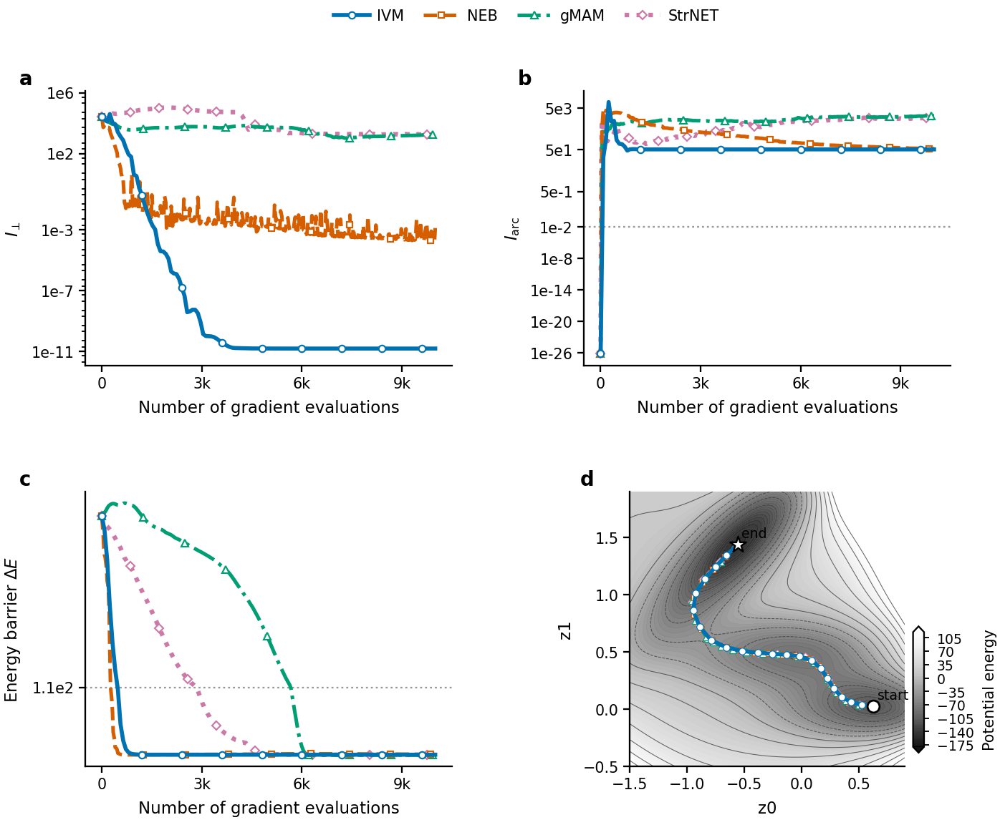

Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/BestMethods_3metrics_contour/N20_BestMethods_1x3_lossperp_lossarc_deltaE_gradEvals_compressed.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/BestMethods_3metrics_contour/N20_BestMethods_1x3_lossperp_lossarc_deltaE_gradEvals_compressed.svg
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/BestMethods_3metrics_contour/N20_BestMethods_1x3_lossperp_lossarc_deltaE_gradEvals_compressed.png


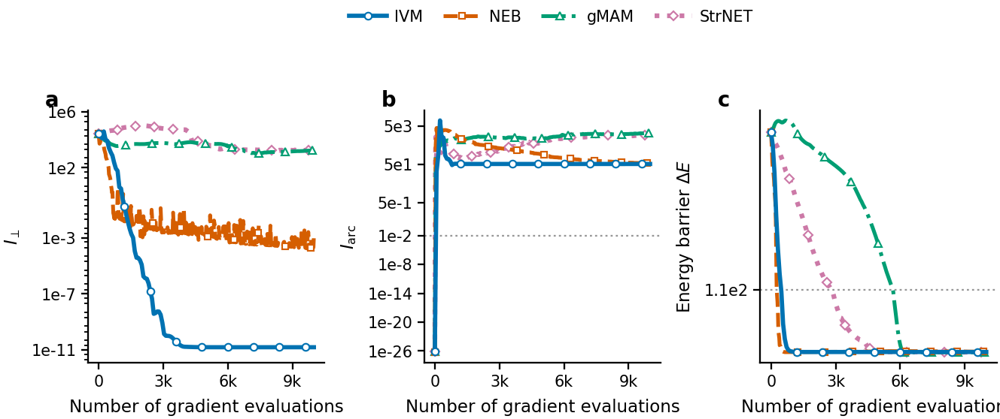

/tmp/ipykernel_171723/809194042.py:2613: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=0.25)


Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/BestMethods_3metrics_contour/N20_BestMethods_contour_final_paths.pdf
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/BestMethods_3metrics_contour/N20_BestMethods_contour_final_paths.svg
Saved: /home/zqcai3/wzy/IVP_IVM/comparison_figures/BestMethods_3metrics_contour/N20_BestMethods_contour_final_paths.png


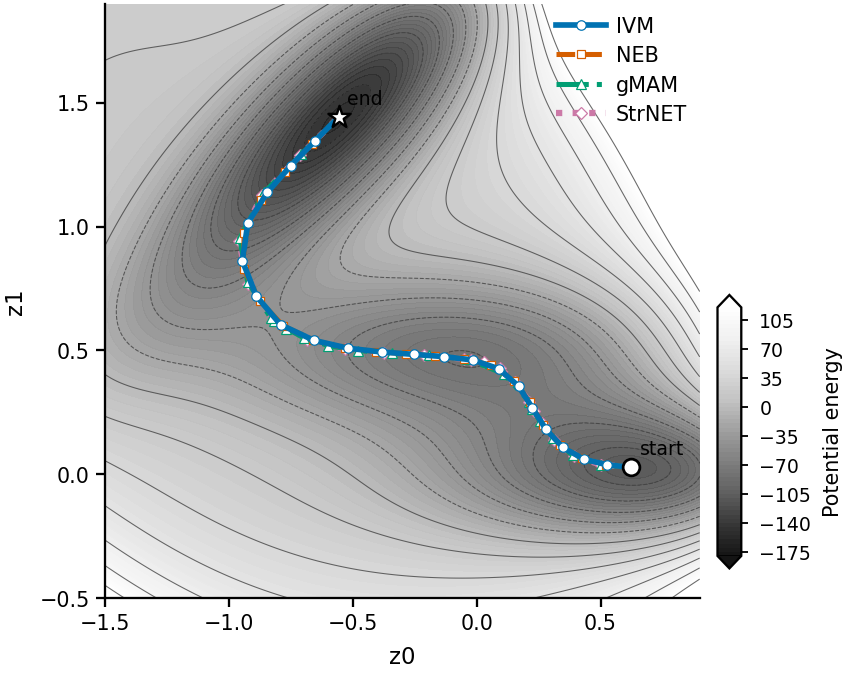


Done.
Figures and CSV saved to:
  /home/zqcai3/wzy/IVP_IVM/comparison_figures/BestMethods_3metrics_contour


In [8]:
# ============================================================
# Best-method comparison plot for IVM / NEB / gMAM
# Metrics:
#   1. loss_perp
#   2. loss_arc
#   3. Delta_Energy
# plus contour plot of final paths
# ============================================================

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

import csv
import re
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter, MaxNLocator
from matplotlib.gridspec import GridSpec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


# ============================================================
# 0. 全局配置
# ============================================================

base_dir = Path("/home/zqcai3/wzy/IVP_IVM")
q_data_path = Path("/home/zqcai3/wzy/IVP_new/Q_data.npz")

dimension = 10

# 你的实验是 N=20
n_images = 20

# ------------------------------------------------------------
# 是否纳入不同方法
# ------------------------------------------------------------

INCLUDE_IVM = True
INCLUDE_NEB = True
INCLUDE_GMAM = True

# 你这次没有给 StrNET 的最优参数，所以默认不画
# 如果之后需要加 StrNET，把这里改成 True，并设置 best_strnet_lr / best_strnet_c
INCLUDE_STRNET = True

# ------------------------------------------------------------
# 当前最优参数
# ------------------------------------------------------------

# IVM:
# 你说的 Nsub = 4, a = 0.01, st = 1500
# 这里的 best_ivm_alpha 对应目录名里的 alpha，也对应你说的 a
best_ivm_Nsub = 4
best_ivm_alpha = 1e-3
best_ivm_steps = 2000

# NEB:
# 你说 NEB 最好的是 20
best_neb_string = 20
neb_alpha = 1e-4

# gMAM:
# 你说 gMAM 最好的是 c = 0.01, lr = 0.01
best_gmam_lr = 1e-2
best_gmam_c = 1e-2

# StrNET:
# 默认不画，仅当 INCLUDE_STRNET = True 时使用
best_strnet_lr = 1e-2
best_strnet_c = 1e-2

# ------------------------------------------------------------
# 结果文件优先级
# ------------------------------------------------------------
# 如果以后你保存中间结果，可以改成:
# RESULT_FILE_PRIORITY = ("results_partial.npz", "results.npz")
RESULT_FILE_PRIORITY = ("results.npz",)

# ------------------------------------------------------------
# 输出目录
# ------------------------------------------------------------

save_dir = base_dir / "comparison_figures" / "BestMethods_3metrics_contour"
save_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 绘图开关
# ------------------------------------------------------------

USE_COMPRESSED_Y = True

SAVE_2X2_PANEL = True
SAVE_1X3_METRICS = True
SAVE_CONTOUR_ONLY = True

SHOW_FIGURES = True
SHOW_GRID = False

SAVE_FORMATS = ("pdf", "svg", "png")
PNG_DPI = 600

# ------------------------------------------------------------
# 横坐标配置：number of gradient evaluations
# ------------------------------------------------------------

X_AXIS_KEY = "grad_count_seq"
X_AXIS_LABEL = "Number of gradient evaluations"

# 当前定义：
# 每个 count 对应 n_images 次 force / gradient evaluation
# 如果你的 IVM count_seq 已经包含 Nsub，例如 count_seq = i * Nsub，
# 那么这里不需要再乘 Nsub。
N_GRAD_EVALS_PER_COUNT = n_images

GRAD_EVALS_PER_COUNT_BY_METHOD = {
    "IVM": N_GRAD_EVALS_PER_COUNT,
    "NEB": N_GRAD_EVALS_PER_COUNT,
    "gMAM": N_GRAD_EVALS_PER_COUNT,
    "StrNET": N_GRAD_EVALS_PER_COUNT,
}

# 如果你之后确认 IVM 的 count_seq 没有包含 Nsub，
# 而你想把内部 Nsub 子步也算进 gradient evaluations，
# 可以改成:
# GRAD_EVALS_PER_COUNT_BY_METHOD["IVM"] = N_GRAD_EVALS_PER_COUNT * best_ivm_Nsub

# ------------------------------------------------------------
# Contour plot 配置
# ------------------------------------------------------------

CONTOUR_XLIM = (-1.5, 0.9)
CONTOUR_YLIM = (-0.5, 1.9)
CONTOUR_N_GRID = 320

POTENTIAL_LEVEL_MIN = -180.0
POTENTIAL_LEVEL_MAX = 120.0
POTENTIAL_N_LEVELS = 61

CONTOUR_LABELS = False
SHOW_CONTOUR_COLORBAR = True
SHOW_START_END = True

# ------------------------------------------------------------
# Delta Energy 插值密度
# ------------------------------------------------------------

DENSE_N_FOR_DELTA_E = 500

# 如果你的 numpy 版本比较旧，没有 np.trapezoid，就自动改用 np.trapz
try:
    trapz = np.trapezoid
except AttributeError:
    trapz = np.trapz


# ============================================================
# 1. Nature / Science 风格 Matplotlib 设置
# ============================================================

def mm_to_inch(mm):
    return mm / 25.4


def setup_publication_style():
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 7.0,
        "axes.labelsize": 7.5,
        "xtick.labelsize": 6.8,
        "ytick.labelsize": 6.8,
        "legend.fontsize": 6.8,

        "mathtext.fontset": "dejavusans",
        "mathtext.default": "it",

        "axes.linewidth": 0.75,
        "axes.spines.top": False,
        "axes.spines.right": False,

        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.width": 0.75,
        "ytick.major.width": 0.75,
        "xtick.minor.width": 0.6,
        "ytick.minor.width": 0.6,
        "xtick.major.size": 3.0,
        "ytick.major.size": 3.0,
        "xtick.minor.size": 1.8,
        "ytick.minor.size": 1.8,

        "legend.frameon": False,
        "legend.handlelength": 2.2,
        "legend.handletextpad": 0.5,
        "legend.borderaxespad": 0.4,

        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",

        "figure.dpi": 180,
        "savefig.dpi": PNG_DPI,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.02,
        "savefig.transparent": False,
    })


setup_publication_style()


# ============================================================
# 2. Müller-10 势能
# ============================================================

Q_np = np.load(q_data_path)["Q"]

a_np = np.array([-1.0, -1.0, -6.5, 0.7], dtype=float)
b_np = np.array([0.0, 0.0, 11.0, 0.6], dtype=float)
c_np = np.array([-10.0, -10.0, -6.5, 0.7], dtype=float)
D_np = np.array([-200.0, -100.0, -170.0, 15.0], dtype=float)
X_np = np.array([1.0, 0.0, -0.5, -1.0], dtype=float)
Y_np = np.array([0.0, 0.5, 1.5, 1.0], dtype=float)
sigma = 0.5


def V_muller10_np(x_vec):
    """
    Müller-10 势能，支持单点和批量输入。

    参数:
        x_vec: shape (10,) 或 (N, 10)

    返回:
        单点输入 -> float
        批量输入 -> shape (N,) numpy array
    """
    x = np.asarray(x_vec, dtype=float)
    single_input = x.ndim == 1

    if single_input:
        x = x.reshape(1, dimension)
    elif x.ndim != 2 or x.shape[1] != dimension:
        raise ValueError(
            f"Input must have shape ({dimension},) or (N,{dimension}), got {x.shape}"
        )

    z = x @ Q_np

    z0 = z[:, 0]
    z1 = z[:, 1]
    rest = z[:, 2:]

    V = np.zeros(z.shape[0], dtype=float)

    for i in range(4):
        exponent = (
            a_np[i] * (z0 - X_np[i]) ** 2
            + b_np[i] * (z0 - X_np[i]) * (z1 - Y_np[i])
            + c_np[i] * (z1 - Y_np[i]) ** 2
        )
        V += D_np[i] * np.exp(exponent)

    V += np.sum((1.0 / (2.0 * sigma ** 2)) * rest ** 2, axis=1)

    if single_input:
        return float(V[0])

    return V


# ============================================================
# 3. 指标计算函数
# ============================================================

def compute_path_derivatives(images_seq):
    """
    images_seq: shape (T, N, d)

    返回:
        s: shape (N,)
        phi_s: shape (T, N, d)
        phi_ss: shape (T, N, d)
        speed: shape (T, N)
    """
    images_seq = np.asarray(images_seq, dtype=float)

    if images_seq.ndim != 3:
        raise ValueError(
            f"images_seq must have shape (T, N, d), got {images_seq.shape}"
        )

    T, N, d = images_seq.shape

    s = np.linspace(0.0, 1.0, N)
    edge_order = 2 if N >= 3 else 1

    phi_s = np.gradient(images_seq, s, axis=1, edge_order=edge_order)
    phi_ss = np.gradient(phi_s, s, axis=1, edge_order=edge_order)

    speed = np.linalg.norm(phi_s, axis=2)

    return s, phi_s, phi_ss, speed


def line_integral_force_quantity(q_force, speed, N_path):
    """
    对定义在 force 网格上的 quantity 做 line integral。

    支持:
        N_force = N_path - 2
        N_force = N_path - 1
        N_force = N_path
        其他情况用插值兜底
    """
    q_force = np.asarray(q_force, dtype=float)
    speed = np.asarray(speed, dtype=float)

    if q_force.ndim != 2:
        raise ValueError(
            f"q_force must have shape (T, N_force), got {q_force.shape}"
        )

    if speed.ndim != 2:
        raise ValueError(
            f"speed must have shape (T, N_path), got {speed.shape}"
        )

    T, N_force = q_force.shape
    ds = 1.0 / (N_path - 1)

    if N_force == N_path - 2:
        speed_force = speed[:, 1:-1]
        return np.sum(q_force * speed_force, axis=1) * ds

    elif N_force == N_path - 1:
        speed_force = speed[:, :-1]
        return np.sum(q_force * speed_force, axis=1) * ds

    elif N_force == N_path:
        s = np.linspace(0.0, 1.0, N_path)
        return trapz(q_force * speed, s, axis=1)

    else:
        s_path = np.linspace(0.0, 1.0, N_path)
        s_force = np.linspace(0.0, 1.0, N_force)

        speed_force = np.empty((T, N_force), dtype=float)

        for i in range(T):
            speed_force[i] = np.interp(s_force, s_path, speed[i])

        return trapz(q_force * speed_force, s_force, axis=1)


def compute_delta_energy(images_seq, V_func, dense_n=500, E_min=None):
    """
    计算:
        Delta_Energy = max_s V(phi(s)) - E_min

    默认:
        E_min = min V(images_seq[0])
    """
    images_seq = np.asarray(images_seq, dtype=float)

    if images_seq.ndim != 3:
        raise ValueError(
            f"images_seq must have shape (T, N, d), got {images_seq.shape}"
        )

    T, N, d = images_seq.shape

    t_old = np.linspace(0.0, 1.0, N)
    t_new = np.linspace(0.0, 1.0, dense_n)

    if E_min is None:
        E0 = V_func(images_seq[0])
        E_min = float(np.min(E0))

    Delta_Energy = np.empty(T, dtype=float)

    for i in range(T):
        X = images_seq[i]

        X_dense = np.column_stack([
            np.interp(t_new, t_old, X[:, dim])
            for dim in range(d)
        ])

        E_dense = V_func(X_dense)
        Delta_Energy[i] = float(np.max(E_dense) - E_min)

    return Delta_Energy


def compute_selected_metrics(
    images_seq,
    count_seq,
    F_perp,
    V_func,
):
    """
    计算三个指标:
        loss_perp
        loss_arc
        Delta_Energy
    """
    images_seq = np.asarray(images_seq, dtype=float)
    count_seq = np.asarray(count_seq, dtype=float).reshape(-1)
    F_perp = np.asarray(F_perp, dtype=float)

    if images_seq.ndim != 3:
        raise ValueError(
            f"images_seq must have shape (T, N_path, d), got {images_seq.shape}"
        )

    if F_perp.ndim != 3:
        raise ValueError(
            f"F_perp must have shape (T, N_force, d), got {F_perp.shape}"
        )

    T = min(
        images_seq.shape[0],
        count_seq.shape[0],
        F_perp.shape[0],
    )

    images_seq = images_seq[:T]
    count_seq = count_seq[:T]
    F_perp = F_perp[:T]

    T, N_path, d = images_seq.shape

    s, phi_s, phi_ss, speed = compute_path_derivatives(images_seq)

    # ------------------------------------------------------------
    # loss_perp = integral |F_perp|^2 |phi'(s)| ds
    # ------------------------------------------------------------
    F_perp_norm_sq = np.sum(F_perp ** 2, axis=2)

    loss_perp = line_integral_force_quantity(
        q_force=F_perp_norm_sq,
        speed=speed,
        N_path=N_path,
    )

    # ------------------------------------------------------------
    # loss_arc = integral (<phi'(s), phi''(s)>)^2 |phi'(s)| ds
    # ------------------------------------------------------------
    inner_phi_s_phi_ss = np.sum(phi_s * phi_ss, axis=2)
    arc_integrand = inner_phi_s_phi_ss ** 2 * speed

    loss_arc = trapz(arc_integrand, s, axis=1)

    # ------------------------------------------------------------
    # Delta_Energy
    # ------------------------------------------------------------
    Delta_Energy = compute_delta_energy(
        images_seq=images_seq,
        V_func=V_func,
        dense_n=DENSE_N_FOR_DELTA_E,
        E_min=None,
    )

    return {
        "count_seq": count_seq,
        "loss_perp": loss_perp,
        "loss_arc": loss_arc,
        "Delta_Energy": Delta_Energy,
    }


def add_gradient_eval_count_to_run(run):
    """
    给每个 run 的 metrics 新增:
        grad_count_seq = count_seq * grad_evals_per_count
    """
    method = run.get("method", "")
    factor = GRAD_EVALS_PER_COUNT_BY_METHOD.get(
        method,
        N_GRAD_EVALS_PER_COUNT,
    )

    m = run["metrics"]
    count_seq = np.asarray(m["count_seq"], dtype=float).reshape(-1)

    m["grad_count_seq"] = count_seq * float(factor)
    m["grad_evals_per_count"] = float(factor)

    return run


# ============================================================
# 4. 文件搜索工具函数
# ============================================================

def candidate_float_strings(v):
    """
    生成多个可能的浮点数字符串，用来兼容不同文件名。
    例如:
        0.01, 1e-2, 1e-02, 1.0e-02
    """
    out = []

    def add(s):
        if s is None:
            return

        s = str(s)
        variants = [s]

        if "E" in s:
            variants.append(s.replace("E", "e"))

        if "e" in s or "E" in s:
            ss = s.replace("E", "e")
            variants.append(ss.replace("e-0", "e-").replace("e+0", "e+"))

        for item in variants:
            if item not in out:
                out.append(item)

    add(str(v))

    try:
        fv = float(v)

        add(str(fv))
        add(f"{fv:g}")
        add(f"{fv:.1e}")
        add(f"{fv:.0e}")

        for nd in [2, 3, 4, 5, 6, 8, 10, 12]:
            add(f"{fv:.{nd}g}")

        for nd in [1, 2, 3, 4, 5, 6, 8, 10, 12]:
            s = f"{fv:.{nd}f}".rstrip("0").rstrip(".")
            if s == "-0":
                s = "0"
            add(s)

        if fv.is_integer():
            add(str(int(fv)))

    except Exception:
        pass

    return out


def get_data_dir(base_dir, data_subdir="Data"):
    """
    允许 base_dir 是:
        /home/zqcai3/wzy/IVP_IVM

    或者:
        /home/zqcai3/wzy/IVP_IVM/Data
    """
    base_dir = Path(base_dir)

    if base_dir.name == data_subdir:
        return base_dir

    return base_dir / data_subdir


def method_tag_candidates(method_tag):
    """
    兼容大小写不同的 gMAM / StrNET 文件名。
    """
    m = method_tag.lower()

    if m == "gmam":
        return ["gMAM", "GMAM", "gmam", "Gmam"]

    if m == "strnet":
        return ["StrNET", "STRNET", "strnet", "StrNet"]

    return [method_tag]


def load_npz_run(file_path, method, label, details):
    """
    通用读取函数。

    必需字段:
        images_seq
        count_seq
        F_perp

    可选字段:
        F_original
    """
    file_path = Path(file_path)
    loaded = np.load(file_path, allow_pickle=True)

    required = [
        "images_seq",
        "count_seq",
        "F_perp",
    ]

    missing = [
        k for k in required
        if k not in loaded.files
    ]

    if len(missing) > 0:
        raise KeyError(
            f"{file_path} missing required keys: {missing}\n"
            f"Available keys: {loaded.files}"
        )

    run = {
        "method": method,
        "label": label,
        "details": details,
        "file": file_path,
        "images_seq": loaded["images_seq"],
        "count_seq": loaded["count_seq"],
        "F_perp": loaded["F_perp"],
    }

    if "F_original" in loaded.files:
        run["F_original"] = loaded["F_original"]

    return run


def parse_ivm_alpha_from_folder_name(folder_name, n_images, Nsub, steps):
    """
    解析目录:
        M10_IVM_images_N20_Nsub4_alpha0.01_steps1500
    或:
        M10_IVM_images_N20_Nsub4_a0.01_steps1500
    """
    pattern = (
        rf"^M10_IVM_images_N{n_images}_"
        rf"Nsub{Nsub}_"
        rf"(?:alpha|a)(?P<alpha>[^_]+)_"
        rf"steps{steps}$"
    )

    m = re.match(pattern, folder_name)

    if m is None:
        return None

    try:
        return float(m.group("alpha"))
    except Exception:
        return None


# ============================================================
# 5. 读取 IVM / NEB / gMAM / StrNET
# ============================================================

def load_ivm_best_run(
    base_dir,
    n_images,
    Nsub,
    alpha,
    steps,
):
    """
    读取当前新版 IVM 结果。

    优先搜索:
        M10_IVM_images_N20_Nsub4_alpha0.01_steps1500/results.npz

    也兼容:
        M10_IVM_images_N20_Nsub4_a0.01_steps1500/results.npz
    """
    base_dir = Path(base_dir)

    alpha_candidates = candidate_float_strings(alpha)

    tried = []
    candidates = []

    # ------------------------------------------------------------
    # 1. 精确路径搜索
    # ------------------------------------------------------------
    for alpha_s in alpha_candidates:
        folder_names = [
            f"M10_IVM_images_N{n_images}_Nsub{Nsub}_alpha{alpha_s}_steps{steps}",
            f"M10_IVM_images_N{n_images}_Nsub{Nsub}_a{alpha_s}_steps{steps}",
        ]

        for folder_name in folder_names:
            folder = base_dir / folder_name

            for fname in RESULT_FILE_PRIORITY:
                p = folder / fname
                tried.append(p)

                if p.exists():
                    candidates.append(p)

    if len(candidates) > 0:
        file_path = candidates[0]

        return load_npz_run(
            file_path=file_path,
            method="IVM",
            label="IVM",
            details=f"IVM, Nsub={Nsub}, alpha={alpha:g}, steps={steps}",
        )

    # ------------------------------------------------------------
    # 2. glob 搜索
    # ------------------------------------------------------------
    folder_patterns = [
        f"M10_IVM_images_N{n_images}_Nsub{Nsub}_alpha*_steps{steps}",
        f"M10_IVM_images_N{n_images}_Nsub{Nsub}_a*_steps{steps}",
        f"**/M10_IVM_images_N{n_images}_Nsub{Nsub}_alpha*_steps{steps}",
        f"**/M10_IVM_images_N{n_images}_Nsub{Nsub}_a*_steps{steps}",
    ]

    glob_folders = []

    for pattern in folder_patterns:
        glob_folders.extend(base_dir.glob(pattern))

    glob_folders = [
        p for p in glob_folders
        if p.is_dir()
    ]

    # 去重
    seen = set()
    unique_folders = []

    for p in glob_folders:
        ps = str(p.resolve())

        if ps not in seen:
            unique_folders.append(p)
            seen.add(ps)

    for folder in unique_folders:
        alpha_val = parse_ivm_alpha_from_folder_name(
            folder.name,
            n_images=n_images,
            Nsub=Nsub,
            steps=steps,
        )

        if alpha_val is not None:
            if not np.isclose(alpha_val, float(alpha), rtol=1e-10, atol=1e-14):
                continue

        for fname in RESULT_FILE_PRIORITY:
            p = folder / fname

            if p.exists():
                candidates.append(p)

    if len(candidates) > 0:
        def score_file(p):
            alpha_val = parse_ivm_alpha_from_folder_name(
                p.parent.name,
                n_images=n_images,
                Nsub=Nsub,
                steps=steps,
            )

            if alpha_val is None:
                alpha_score = 1e99
            else:
                alpha_score = abs(alpha_val - float(alpha))

            try:
                priority_score = RESULT_FILE_PRIORITY.index(p.name)
            except ValueError:
                priority_score = 999

            return (
                alpha_score,
                priority_score,
                len(str(p)),
                str(p),
            )

        candidates = sorted(candidates, key=score_file)
        file_path = candidates[0]

        return load_npz_run(
            file_path=file_path,
            method="IVM",
            label="IVM",
            details=f"IVM, Nsub={Nsub}, alpha={alpha:g}, steps={steps}",
        )

    tried_preview = "\n".join([f"  {p}" for p in tried[:60]])

    raise FileNotFoundError(
        f"Could not find IVM result for:\n"
        f"  N={n_images}, Nsub={Nsub}, alpha={alpha}, steps={steps}\n\n"
        f"Expected folder like:\n"
        f"  {base_dir}/M10_IVM_images_N{n_images}_Nsub{Nsub}_alpha{alpha:g}_steps{steps}/results.npz\n\n"
        f"Some tried paths:\n{tried_preview}"
    )


def load_neb_best_run(
    base_dir,
    n_images,
    k_neb=20,
    alpha_neb=1e-4,
):
    """
    读取 NEB 最优数据。

    优先搜索:
        M10_neb/N22_k20_alpha1e-04_ode_results.npz

    也会兼容 N20 和不同 alpha 字符串写法。
    """
    base_dir = Path(base_dir)
    neb_dirs = [
        base_dir / "M10_neb",
        base_dir,
    ]

    N_candidates = [
        n_images + 2,
        n_images,
    ]

    alpha_candidates = candidate_float_strings(alpha_neb)

    tried = []
    candidates = []

    # ------------------------------------------------------------
    # 1. 精确路径搜索
    # ------------------------------------------------------------
    for neb_dir in neb_dirs:
        for N_tag in N_candidates:
            for alpha_s in alpha_candidates:
                p = neb_dir / f"N{N_tag}_k{k_neb}_alpha{alpha_s}_ode_results.npz"
                tried.append(p)

                if p.exists():
                    candidates.append(p)

    if len(candidates) > 0:
        file_path = candidates[0]

        return load_npz_run(
            file_path=file_path,
            method="NEB",
            label="NEB",
            details=f"NEB, k={k_neb}",
        )

    # ------------------------------------------------------------
    # 2. glob 搜索
    # ------------------------------------------------------------
    for neb_dir in neb_dirs:
        if not neb_dir.exists():
            continue

        for N_tag in N_candidates:
            pattern = f"N{N_tag}_k{k_neb}_alpha*_ode_results.npz"
            candidates.extend(neb_dir.glob(pattern))

        # 递归兜底
        pattern = f"**/N*_k{k_neb}_alpha*_ode_results.npz"
        candidates.extend(neb_dir.glob(pattern))

    candidates = [
        p for p in candidates
        if p.is_file()
    ]

    # 去重
    seen = set()
    unique_candidates = []

    for p in candidates:
        ps = str(p.resolve())

        if ps not in seen:
            unique_candidates.append(p)
            seen.add(ps)

    if len(unique_candidates) > 0:
        def score_neb_file(p):
            name = p.name

            score_N = 999
            for i, N_tag in enumerate(N_candidates):
                if f"N{N_tag}_" in name:
                    score_N = i
                    break

            score_alpha = 999
            for i, alpha_s in enumerate(alpha_candidates):
                if f"alpha{alpha_s}_" in name:
                    score_alpha = i
                    break

            return (
                score_N,
                score_alpha,
                len(str(p)),
                str(p),
            )

        unique_candidates = sorted(unique_candidates, key=score_neb_file)
        file_path = unique_candidates[0]

        return load_npz_run(
            file_path=file_path,
            method="NEB",
            label="NEB",
            details=f"NEB, k={k_neb}",
        )

    tried_preview = "\n".join([f"  {p}" for p in tried[:60]])

    raise FileNotFoundError(
        f"Could not find NEB file for k/string={k_neb}, alpha={alpha_neb}.\n"
        f"Some tried paths:\n{tried_preview}"
    )


def find_param_method_npz(
    base_dir,
    method_tag,
    n_images,
    lr,
    c,
    data_subdir="Data",
):
    """
    搜索 gMAM / StrNET 的 npz 文件。
    """
    data_dir = get_data_dir(base_dir, data_subdir=data_subdir)

    if not data_dir.exists():
        raise FileNotFoundError(f"Data directory does not exist: {data_dir}")

    lr_candidates = candidate_float_strings(lr)
    c_candidates = candidate_float_strings(c)
    tag_candidates = method_tag_candidates(method_tag)

    tried = []

    # ------------------------------------------------------------
    # 1. 精确候选路径
    # ------------------------------------------------------------
    for tag in tag_candidates:
        for lr_s in lr_candidates:
            for c_s in c_candidates:

                case_candidates = [
                    f"M10_N{n_images}_Images_{tag}_lr{lr_s}_c{c_s}",
                    f"M10_N{n_images}_{tag}_lr{lr_s}_c{c_s}",
                    f"M10_N{n_images}_Images_{tag}_c{c_s}_lr{lr_s}",
                    f"M10_N{n_images}_{tag}_c{c_s}_lr{lr_s}",

                    # 兼容旧代码里可能出现的 c3 写法
                    f"M10_N{n_images}_Images_{tag}_lr{lr_s}_c3{c_s}",
                    f"M10_N{n_images}_{tag}_lr{lr_s}_c3{c_s}",
                ]

                for casenum in case_candidates:
                    exact_paths = [
                        data_dir / casenum / f"M10_{casenum}.npz",
                        data_dir / casenum / f"{casenum}.npz",
                        data_dir / casenum / f"M10_{casenum}_results.npz",
                        data_dir / casenum / "results.npz",
                        data_dir / f"M10_{casenum}.npz",
                        data_dir / f"{casenum}.npz",
                    ]

                    for p in exact_paths:
                        tried.append(p)

                        if p.exists():
                            return p

                    folder = data_dir / casenum

                    if folder.exists() and folder.is_dir():
                        npz_files = sorted(folder.glob("*.npz"))

                        if len(npz_files) > 0:
                            return npz_files[0]

    # ------------------------------------------------------------
    # 2. glob 递归搜索
    # ------------------------------------------------------------
    glob_matches = []

    for tag in tag_candidates:
        for lr_s in lr_candidates:
            for c_s in c_candidates:
                patterns = [
                    f"**/*N{n_images}*{tag}*lr{lr_s}*c{c_s}*.npz",
                    f"**/*N{n_images}*{tag}*c{c_s}*lr{lr_s}*.npz",
                    f"**/*N{n_images}*{tag}*lr{lr_s}*c3{c_s}*.npz",
                ]

                for pattern in patterns:
                    glob_matches.extend(data_dir.glob(pattern))

    glob_matches = [
        p for p in glob_matches
        if p.is_file()
    ]

    unique_matches = []
    seen = set()

    for p in glob_matches:
        ps = str(p.resolve())

        if ps not in seen:
            unique_matches.append(p)
            seen.add(ps)

    if len(unique_matches) > 0:
        unique_matches = sorted(
            unique_matches,
            key=lambda p: (
                0 if "Images" in str(p) else 1,
                len(str(p)),
                str(p),
            )
        )

        return unique_matches[0]

    tried_preview = "\n".join([f"  {p}" for p in tried[:80]])

    raise FileNotFoundError(
        f"Could not find npz file for method={method_tag}, "
        f"N={n_images}, lr={lr}, c={c}.\n"
        f"Data dir:\n  {data_dir}\n\n"
        f"Some tried paths:\n{tried_preview}\n"
    )


def load_param_method_best_run(
    base_dir,
    method_tag,
    n_images,
    lr,
    c,
    data_subdir="Data",
):
    """
    读取 gMAM 或 StrNET 最优参数数据。
    """
    file_path = find_param_method_npz(
        base_dir=base_dir,
        method_tag=method_tag,
        n_images=n_images,
        lr=lr,
        c=c,
        data_subdir=data_subdir,
    )

    method_lower = method_tag.lower()

    if method_lower == "gmam":
        method_name = "gMAM"
    elif method_lower == "strnet":
        method_name = "StrNET"
    else:
        method_name = method_tag

    return load_npz_run(
        file_path=file_path,
        method=method_name,
        label=method_name,
        details=f"{method_name}, lr={lr:g}, c={c:g}",
    )


# ============================================================
# 6. Publication-style 绘图工具
# ============================================================

Y_TICK_LABEL_STYLE = "e"
Y_TICK_SIG_DIGITS = 2

COMPRESS_Y_CONFIG = {
    "loss_arc": {
        "threshold": 1e-2,
        "side": "below",
        "factor": 0.25,
        "tick_multipliers_normal": (1, 2, 5),
        "tick_multipliers_compressed": (1,),
        "compressed_tick_every": 1,
        "max_total_ticks": 8,
        "force_threshold_tick": True,
    },
    "Delta_Energy": {
        "threshold": 1.1e2,
        "side": "above",
        "factor": 0.25,
        "tick_multipliers_normal": (1, 2, 5),
        "tick_multipliers_compressed": (1,),
        "compressed_tick_every": 1,
        "max_total_ticks": 8,
        "force_threshold_tick": True,
    },
}

# Okabe-Ito / colorblind-friendly palette
METHOD_STYLE = {
    "IVM": {
        "linestyle": "-",
        "linewidth": 1.85,
        "color": "#0072B2",
        "marker": "o",
        "markersize": 3.1,
        "zorder": 5,
    },
    "NEB": {
        "linestyle": "--",
        "linewidth": 1.65,
        "color": "#D55E00",
        "marker": "s",
        "markersize": 2.9,
        "zorder": 4,
    },
    "gMAM": {
        "linestyle": "-.",
        "linewidth": 1.65,
        "color": "#009E73",
        "marker": "^",
        "markersize": 3.1,
        "zorder": 3,
    },
    "StrNET": {
        "linestyle": ":",
        "linewidth": 2.05,
        "color": "#CC79A7",
        "marker": "D",
        "markersize": 2.8,
        "zorder": 2,
    },
}

METRIC_INFO = {
    "loss_perp": {
        "ylabel": r"$I_{\perp}$",
        "panel": "a",
    },
    "loss_arc": {
        "ylabel": r"$I_{\mathrm{arc}}$",
        "panel": "b",
    },
    "Delta_Energy": {
        "ylabel": r"Energy barrier $\Delta E$",
        "panel": "c",
    },
}


def get_plot_style(run):
    method = run.get("method", "")

    default_style = {
        "linestyle": "-",
        "linewidth": 1.4,
        "color": "black",
        "marker": None,
        "markersize": 2.8,
        "zorder": 1,
    }

    return METHOD_STYLE.get(method, default_style)


def format_tick_label_sci(v, sig_digits=2, style="e"):
    """
    把原始 y 数值格式化成科学计数法。
    """
    if not np.isfinite(v):
        return ""

    if v == 0:
        return "0"

    sign = "-" if v < 0 else ""
    av = abs(float(v))

    exponent = int(np.floor(np.log10(av)))
    mantissa = av / (10.0 ** exponent)

    mantissa_str = f"{mantissa:.{sig_digits}g}"
    mantissa_val = float(mantissa_str)

    if mantissa_val >= 10.0:
        mantissa_val = mantissa_val / 10.0
        exponent += 1
        mantissa_str = f"{mantissa_val:.{sig_digits}g}"

    if style == "e":
        return f"{sign}{mantissa_str}e{exponent}"

    elif style == "times":
        return f"{sign}{mantissa_str}×10^{exponent}"

    else:
        raise ValueError("style must be either 'e' or 'times'.")


def mpl_sci_formatter(y, pos=None):
    if not np.isfinite(y) or y <= 0:
        return ""

    return format_tick_label_sci(
        y,
        sig_digits=Y_TICK_SIG_DIGITS,
        style=Y_TICK_LABEL_STYLE,
    )


def apply_scientific_y_formatter(ax):
    ax.yaxis.set_major_formatter(FuncFormatter(mpl_sci_formatter))


def count_formatter(x, pos=None):
    """
    横坐标格式。
    当前横坐标是 number of gradient evaluations。
    """
    if not np.isfinite(x):
        return ""

    ax_abs = abs(x)

    if ax_abs >= 1e6:
        return f"{x / 1e6:g}M"

    if ax_abs >= 1e3:
        return f"{x / 1e3:g}k"

    if abs(x - round(x)) < 1e-8:
        return f"{int(round(x))}"

    return f"{x:g}"


def get_x_values_for_run(run):
    """
    获取绘图横坐标。

    默认优先使用:
        grad_count_seq

    如果没有，则退回:
        count_seq
    """
    m = run["metrics"]

    if X_AXIS_KEY in m:
        return m[X_AXIS_KEY]

    return m["count_seq"]


def compressed_log10_transform(y, threshold, side="above", factor=0.25):
    """
    在 log10(y) 空间做局部压缩。
    """
    y = np.asarray(y, dtype=float)

    z = np.log10(y)
    z0 = np.log10(threshold)

    z_new = z.copy()

    if side == "above":
        mask = z > z0
        z_new[mask] = z0 + factor * (z[mask] - z0)

    elif side == "below":
        mask = z < z0
        z_new[mask] = z0 + factor * (z[mask] - z0)

    else:
        raise ValueError("side must be either 'above' or 'below'.")

    return z_new


def is_in_compressed_region(v, threshold, side):
    if threshold is None or side is None:
        return False

    if side == "above":
        return v > threshold

    elif side == "below":
        return v < threshold

    else:
        raise ValueError("side must be either 'above' or 'below'.")


def unique_sorted(values):
    values = [
        float(v)
        for v in values
        if np.isfinite(v)
    ]

    values = sorted(values)

    if len(values) == 0:
        return []

    out = [values[0]]

    for v in values[1:]:
        if not np.isclose(v, out[-1], rtol=1e-12, atol=0.0):
            out.append(v)

    return out


def downsample_keep_ends(values, max_n):
    values = list(values)

    if max_n is None:
        return values

    if len(values) <= max_n:
        return values

    if max_n <= 0:
        return []

    if max_n == 1:
        return [values[len(values) // 2]]

    idx = np.linspace(0, len(values) - 1, max_n)
    idx = np.round(idx).astype(int)
    idx = sorted(set(idx.tolist()))

    while len(idx) > max_n:
        idx.pop(-2)

    return [
        values[i]
        for i in idx
    ]


def thin_compressed_ticks(ticks, threshold, side, compressed_tick_every=1):
    ticks = unique_sorted(ticks)

    if compressed_tick_every is None or compressed_tick_every <= 1:
        return ticks

    normal_ticks = []
    compressed_ticks = []

    for t in ticks:
        if is_in_compressed_region(t, threshold, side):
            compressed_ticks.append(t)
        else:
            normal_ticks.append(t)

    compressed_ticks = [
        t for i, t in enumerate(compressed_ticks)
        if i % compressed_tick_every == 0
    ]

    return unique_sorted(normal_ticks + compressed_ticks)


def enforce_max_total_ticks(
    ticks,
    max_total_ticks,
    threshold=None,
    force_threshold_tick=True,
):
    ticks = unique_sorted(ticks)

    if max_total_ticks is None:
        return ticks

    if len(ticks) <= max_total_ticks:
        return ticks

    ticks_new = downsample_keep_ends(ticks, max_total_ticks)

    if (
        force_threshold_tick
        and threshold is not None
        and any(np.isclose(t, threshold, rtol=1e-12, atol=0.0) for t in ticks)
        and not any(np.isclose(t, threshold, rtol=1e-12, atol=0.0) for t in ticks_new)
    ):
        log_ticks_new = np.log10(np.asarray(ticks_new))
        log_threshold = np.log10(threshold)

        idx_replace = int(np.argmin(np.abs(log_ticks_new - log_threshold)))
        ticks_new[idx_replace] = float(threshold)
        ticks_new = unique_sorted(ticks_new)

    return ticks_new


def make_log_ticks(
    y_min,
    y_max,
    threshold=None,
    side=None,
    tick_multipliers_normal=(1, 2, 5),
    tick_multipliers_compressed=(1,),
    compressed_tick_every=1,
    max_total_ticks=8,
    force_threshold_tick=True,
):
    y_min = float(y_min)
    y_max = float(y_max)

    if y_min <= 0 or y_max <= 0:
        return []

    if y_min > y_max:
        y_min, y_max = y_max, y_min

    e_min = int(np.floor(np.log10(y_min)))
    e_max = int(np.ceil(np.log10(y_max)))

    multipliers_all = sorted(
        set(list(tick_multipliers_normal) + list(tick_multipliers_compressed))
    )

    ticks = []

    for e in range(e_min, e_max + 1):
        for m in multipliers_all:
            v = m * (10.0 ** e)

            if not (y_min <= v <= y_max):
                continue

            if threshold is None or side is None:
                if m in tick_multipliers_normal:
                    ticks.append(v)
            else:
                if is_in_compressed_region(v, threshold, side):
                    if m in tick_multipliers_compressed:
                        ticks.append(v)
                else:
                    if m in tick_multipliers_normal:
                        ticks.append(v)

    if (
        force_threshold_tick
        and threshold is not None
        and y_min <= threshold <= y_max
    ):
        ticks.append(float(threshold))

    ticks = unique_sorted(ticks)

    if len(ticks) == 0:
        ticks = [y_min, y_max]

        if threshold is not None and y_min <= threshold <= y_max:
            ticks.append(float(threshold))

        ticks = unique_sorted(ticks)

    if threshold is not None and side is not None:
        ticks = thin_compressed_ticks(
            ticks,
            threshold=threshold,
            side=side,
            compressed_tick_every=compressed_tick_every,
        )

    ticks = enforce_max_total_ticks(
        ticks,
        max_total_ticks=max_total_ticks,
        threshold=threshold,
        force_threshold_tick=force_threshold_tick,
    )

    return ticks


def get_markevery(x, target_markers=8):
    x = np.asarray(x).reshape(-1)
    n = x.size

    if n <= 1:
        return 1

    return max(n // target_markers, 1)


def plot_compressed_logy_safe(
    ax,
    x,
    y,
    label,
    threshold,
    side="above",
    factor=0.25,
    linestyle="-",
    linewidth=1.5,
    color=None,
    marker=None,
    markersize=3.0,
    markevery=1,
    zorder=1,
):
    """
    画局部压缩后的 log-y 曲线。
    """
    x = np.asarray(x).reshape(-1)
    y = np.asarray(y).reshape(-1)

    mask = np.isfinite(x) & np.isfinite(y) & (y > 0)

    if np.count_nonzero(mask) == 0:
        print(f"[Warning] {label}: no positive finite values for compressed log-y plot.")
        return None

    x_valid = x[mask]
    y_valid = y[mask]

    y_plot = compressed_log10_transform(
        y_valid,
        threshold=threshold,
        side=side,
        factor=factor,
    )

    ax.plot(
        x_valid,
        y_plot,
        label=label,
        linestyle=linestyle,
        linewidth=linewidth,
        color=color,
        marker=marker,
        markersize=markersize,
        markerfacecolor="white",
        markeredgewidth=0.7,
        markevery=markevery,
        zorder=zorder,
    )

    return y_valid


def set_compressed_logy_axis(
    ax,
    y_values_all,
    threshold,
    side="above",
    factor=0.25,
    tick_multipliers_normal=(1, 2, 5),
    tick_multipliers_compressed=(1,),
    compressed_tick_every=1,
    max_total_ticks=8,
    force_threshold_tick=True,
):
    """
    给局部压缩后的 log-y 图设置 y ticks 和标签。
    """
    y_values_all = np.asarray(y_values_all, dtype=float)
    y_values_all = y_values_all[np.isfinite(y_values_all) & (y_values_all > 0)]

    if y_values_all.size == 0:
        return

    y_min = np.min(y_values_all)
    y_max = np.max(y_values_all)

    ticks_original = make_log_ticks(
        y_min=y_min,
        y_max=y_max,
        threshold=threshold,
        side=side,
        tick_multipliers_normal=tick_multipliers_normal,
        tick_multipliers_compressed=tick_multipliers_compressed,
        compressed_tick_every=compressed_tick_every,
        max_total_ticks=max_total_ticks,
        force_threshold_tick=force_threshold_tick,
    )

    ticks_transformed = compressed_log10_transform(
        np.asarray(ticks_original),
        threshold=threshold,
        side=side,
        factor=factor,
    )

    ax.set_yticks(ticks_transformed)

    ax.set_yticklabels([
        format_tick_label_sci(
            v,
            sig_digits=Y_TICK_SIG_DIGITS,
            style=Y_TICK_LABEL_STYLE,
        )
        for v in ticks_original
    ])

    y_all_transformed = compressed_log10_transform(
        y_values_all,
        threshold=threshold,
        side=side,
        factor=factor,
    )

    y_low = np.min(y_all_transformed)
    y_high = np.max(y_all_transformed)

    pad = 0.045 * max(y_high - y_low, 1e-12)

    ax.set_ylim(y_low - pad, y_high + pad)

    if y_min <= threshold <= y_max:
        threshold_transformed = compressed_log10_transform(
            np.asarray([threshold]),
            threshold=threshold,
            side=side,
            factor=factor,
        )[0]

        ax.axhline(
            threshold_transformed,
            color="0.55",
            linestyle=(0, (1.2, 1.8)),
            linewidth=0.75,
            alpha=0.9,
            zorder=0,
        )

    ax.minorticks_off()


def semilogy_safe(
    ax,
    x,
    y,
    label,
    linestyle="-",
    linewidth=1.5,
    color=None,
    marker=None,
    markersize=3.0,
    markevery=1,
    zorder=1,
):
    """
    普通 semilogy。
    """
    x = np.asarray(x).reshape(-1)
    y = np.asarray(y).reshape(-1)

    mask = np.isfinite(x) & np.isfinite(y) & (y > 0)

    if np.count_nonzero(mask) == 0:
        print(f"[Warning] {label}: no positive finite values for semilogy.")
        return

    ax.semilogy(
        x[mask],
        y[mask],
        label=label,
        linestyle=linestyle,
        linewidth=linewidth,
        color=color,
        marker=marker,
        markersize=markersize,
        markerfacecolor="white",
        markeredgewidth=0.7,
        markevery=markevery,
        zorder=zorder,
    )


def style_standard_log_y_axis(ax):
    """
    普通 log-y 轴的 tick 设置。
    """
    ax.yaxis.set_major_locator(
        LogLocator(base=10.0, subs=(1.0, 2.0, 5.0), numticks=8)
    )

    ax.yaxis.set_minor_locator(
        LogLocator(base=10.0, subs=(3.0, 4.0, 6.0, 7.0, 8.0, 9.0), numticks=60)
    )

    ax.yaxis.set_minor_formatter(NullFormatter())
    apply_scientific_y_formatter(ax)


def style_loss_perp_log_y_axis(
    ax,
    runs,
    metric_name="loss_perp",
    max_major_ticks=5,
):
    """
    专门给 loss_perp 使用的 y 轴格式。
    """
    y_all = []

    for run in runs:
        y = np.asarray(run["metrics"][metric_name], dtype=float).reshape(-1)
        y = y[np.isfinite(y) & (y > 0)]

        if y.size > 0:
            y_all.append(y)

    if len(y_all) == 0:
        print("[Warning] loss_perp has no positive finite values; log-y ticks cannot be set.")
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(FuncFormatter(mpl_sci_formatter))
        return

    y_all = np.concatenate(y_all)

    y_min = float(np.min(y_all))
    y_max = float(np.max(y_all))

    log_min = np.log10(y_min)
    log_max = np.log10(y_max)

    if np.isclose(log_min, log_max):
        log_low = log_min - 0.5
        log_high = log_max + 0.5
    else:
        pad = 0.07 * (log_max - log_min)
        log_low = log_min - pad
        log_high = log_max + pad

    y_low = 10.0 ** log_low
    y_high = 10.0 ** log_high

    ax.set_yscale("log")
    ax.set_ylim(y_low, y_high)

    ticks = make_log_ticks(
        y_min=y_low,
        y_max=y_high,
        threshold=None,
        side=None,
        tick_multipliers_normal=(1,),
        tick_multipliers_compressed=(1,),
        compressed_tick_every=1,
        max_total_ticks=max_major_ticks,
        force_threshold_tick=False,
    )

    if len(ticks) < 2:
        ticks = make_log_ticks(
            y_min=y_low,
            y_max=y_high,
            threshold=None,
            side=None,
            tick_multipliers_normal=(1, 2, 5),
            tick_multipliers_compressed=(1,),
            compressed_tick_every=1,
            max_total_ticks=max_major_ticks,
            force_threshold_tick=False,
        )

    ticks = [
        t for t in ticks
        if np.isfinite(t) and t > 0 and y_low <= t <= y_high
    ]

    if len(ticks) == 0:
        ticks = [y_min, y_max]

    ax.set_yticks(ticks)
    ax.set_yticklabels([
        format_tick_label_sci(
            t,
            sig_digits=Y_TICK_SIG_DIGITS,
            style=Y_TICK_LABEL_STYLE,
        )
        for t in ticks
    ])

    ax.yaxis.set_minor_locator(
        LogLocator(base=10.0, subs=(2.0, 5.0), numticks=40)
    )
    ax.yaxis.set_minor_formatter(NullFormatter())

    ax.tick_params(
        axis="y",
        which="major",
        labelleft=True,
    )


def style_common_axes(ax):
    """
    所有 panel 的共同风格。
    """
    ax.spines["left"].set_linewidth(0.75)
    ax.spines["bottom"].set_linewidth(0.75)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        length=3.0,
        width=0.75,
        pad=2.0,
    )

    ax.tick_params(
        axis="both",
        which="minor",
        direction="out",
        length=1.8,
        width=0.6,
        pad=2.0,
    )

    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.xaxis.set_major_formatter(FuncFormatter(count_formatter))

    if SHOW_GRID:
        ax.grid(
            True,
            axis="y",
            which="major",
            linestyle="-",
            linewidth=0.35,
            color="0.88",
            alpha=1.0,
            zorder=0,
        )
    else:
        ax.grid(False)


def add_panel_letter(ax, letter, x=-0.18, y=1.08):
    ax.text(
        x,
        y,
        letter,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9.0,
        fontweight="bold",
    )


def unique_legend(handles, labels):
    out_h = []
    out_l = []
    seen = set()

    for h, l in zip(handles, labels):
        if l not in seen:
            out_h.append(h)
            out_l.append(l)
            seen.add(l)

    return out_h, out_l


def plot_metric_on_axis(
    ax,
    runs,
    metric_name,
    ylabel,
    use_compressed_y=True,
    panel_letter=None,
):
    """
    在已有 ax 上画一个 metric。
    横坐标使用 X_AXIS_KEY，当前为 grad_count_seq。
    """
    compress_cfg = None

    if use_compressed_y:
        compress_cfg = COMPRESS_Y_CONFIG.get(metric_name, None)

    y_values_for_axis = []

    for run in runs:
        x = get_x_values_for_run(run)
        y = run["metrics"][metric_name]

        style = get_plot_style(run)
        markevery = get_markevery(x, target_markers=8)

        if compress_cfg is None:
            semilogy_safe(
                ax,
                x,
                y,
                label=run["label"],
                linestyle=style["linestyle"],
                linewidth=style["linewidth"],
                color=style["color"],
                marker=style["marker"],
                markersize=style["markersize"],
                markevery=markevery,
                zorder=style["zorder"],
            )

        else:
            y_valid = plot_compressed_logy_safe(
                ax,
                x,
                y,
                label=run["label"],
                threshold=compress_cfg["threshold"],
                side=compress_cfg["side"],
                factor=compress_cfg["factor"],
                linestyle=style["linestyle"],
                linewidth=style["linewidth"],
                color=style["color"],
                marker=style["marker"],
                markersize=style["markersize"],
                markevery=markevery,
                zorder=style["zorder"],
            )

            if y_valid is not None:
                y_values_for_axis.append(y_valid)

    if compress_cfg is not None and len(y_values_for_axis) > 0:
        y_values_for_axis = np.concatenate(y_values_for_axis)

        set_compressed_logy_axis(
            ax,
            y_values_all=y_values_for_axis,
            threshold=compress_cfg["threshold"],
            side=compress_cfg["side"],
            factor=compress_cfg["factor"],
            tick_multipliers_normal=compress_cfg.get(
                "tick_multipliers_normal", (1, 2, 5)
            ),
            tick_multipliers_compressed=compress_cfg.get(
                "tick_multipliers_compressed", (1,)
            ),
            compressed_tick_every=compress_cfg.get(
                "compressed_tick_every", 1
            ),
            max_total_ticks=compress_cfg.get(
                "max_total_ticks", 8
            ),
            force_threshold_tick=compress_cfg.get(
                "force_threshold_tick", True
            ),
        )

        ax.set_ylabel(ylabel)

    else:
        ax.set_ylabel(ylabel)

        if metric_name == "loss_perp":
            style_loss_perp_log_y_axis(
                ax=ax,
                runs=runs,
                metric_name=metric_name,
                max_major_ticks=5,
            )
        else:
            style_standard_log_y_axis(ax)

    ax.set_xlabel(X_AXIS_LABEL)

    style_common_axes(ax)

    if panel_letter is not None:
        add_panel_letter(ax, panel_letter)

    return ax


# ============================================================
# 7. Contour plot 工具函数
# ============================================================

def get_final_path(images_or_path):
    """
    自动提取最后一条路径。

    支持两种输入：
        images_seq: shape (T, N, d) -> 返回 images_seq[-1]
        path: shape (N, d) -> 直接返回 path
    """
    arr = np.asarray(images_or_path)

    if arr.ndim == 3:
        return arr[-1]

    elif arr.ndim == 2:
        return arr

    else:
        raise ValueError(
            f"images_or_path must have shape (T, N, d) or (N, d), "
            f"but got shape {arr.shape}"
        )


def evaluate_V_on_points(X_points, V_func):
    """
    在一批点上计算势能。
    优先尝试 V_func(X_points) 向量化计算；
    如果失败，则自动退回逐点计算。
    """
    X_points = np.asarray(X_points)

    try:
        V_vals = np.asarray(V_func(X_points)).reshape(-1)

        if V_vals.shape[0] == X_points.shape[0]:
            return V_vals

    except Exception:
        pass

    V_vals = np.array([
        float(np.asarray(V_func(xi)))
        for xi in X_points
    ])

    return V_vals


def project_path_to_z01(path, Q_np):
    """
    把 x 空间路径投影到 z 空间的前两个坐标。

    z = x @ Q_np

    返回:
        z01: shape (N, 2)
    """
    path = np.asarray(path, dtype=float)
    z = path @ Q_np
    return z[:, :2]


def z_grid_to_x_points(Z_points, Q_np):
    """
    z = x @ Q
    因此 x = z @ inv(Q)

    若 Q 不可逆，则使用 pinv(Q)。
    """
    try:
        Q_inv = np.linalg.inv(Q_np)
    except np.linalg.LinAlgError:
        Q_inv = np.linalg.pinv(Q_np)

    return Z_points @ Q_inv


def compute_contour_grid(
    V_func,
    Q_np,
    n_grid=320,
    xlim=(-1.5, 0.9),
    ylim=(-0.5, 1.9),
):
    """
    在 z0-z1 平面上计算 Müller potential contour grid。
    """
    x_lb, x_ub = xlim
    y_lb, y_ub = ylim

    x = np.linspace(x_lb, x_ub, num=n_grid)
    y = np.linspace(y_lb, y_ub, num=n_grid)

    X, Y = np.meshgrid(x, y)

    Z0 = X.reshape(-1)
    Z1 = Y.reshape(-1)

    Z_points = np.zeros((Z0.size, dimension), dtype=float)
    Z_points[:, 0] = Z0
    Z_points[:, 1] = Z1

    X_points = z_grid_to_x_points(Z_points, Q_np=Q_np)

    V_vals = evaluate_V_on_points(
        X_points,
        V_func=V_func,
    )

    Zplot = V_vals.reshape(X.shape)

    return X, Y, Zplot


def build_path_specs_from_runs(runs):
    """
    从 runs 自动构建 contour plot 所需的路径 specs。
    每个 run 使用 images_seq[-1] 作为最终路径。
    """
    path_specs = []

    for run in runs:
        style = get_plot_style(run)

        path_specs.append({
            "label": run["label"],
            "images_seq": run["images_seq"],
            "show": True,
            "color": style["color"],
            "linestyle": style["linestyle"],
            "marker": style["marker"],
            "lw": style["linewidth"],
            "ms": style["markersize"],
            "zorder": style["zorder"],
        })

    return path_specs


def draw_contour_with_paths(
    ax,
    path_specs,
    V_func,
    Q_np,
    n_grid=320,
    xlim=(-1.5, 0.9),
    ylim=(-0.5, 1.9),
    potential_level_min=-180.0,
    potential_level_max=120.0,
    potential_n_levels=61,
    contour_labels=False,
    show_colorbar=True,
    colorbar_inset=True,
    show_start_end=True,
    panel_letter=None,
):
    """
    在给定 ax 上画 Müller potential contour 并叠加多条最终路径。
    """
    X, Y, Zplot = compute_contour_grid(
        V_func=V_func,
        Q_np=Q_np,
        n_grid=n_grid,
        xlim=xlim,
        ylim=ylim,
    )

    levels = np.linspace(
        potential_level_min,
        potential_level_max,
        potential_n_levels,
    )

    line_levels = levels[::4]

    cf = ax.contourf(
        X,
        Y,
        Zplot,
        levels=levels,
        cmap="Greys_r",
        alpha=0.92,
        extend="both",
        zorder=-10,
    )

    cs = ax.contour(
        X,
        Y,
        Zplot,
        levels=line_levels,
        colors="0.25",
        linewidths=0.35,
        alpha=0.78,
        zorder=-5,
    )

    if contour_labels:
        ax.clabel(
            cs,
            inline=True,
            fontsize=5.5,
            fmt="%.0f",
        )

    first_visible_z01 = None

    for i, spec in enumerate(path_specs):
        if not spec.get("show", True):
            continue

        label = spec.get("label", f"path {i}")

        if "images_seq" in spec:
            images_or_path = spec["images_seq"]
        elif "path" in spec:
            images_or_path = spec["path"]
        else:
            raise KeyError(
                f"Path spec {label} must contain either 'images_seq' or 'path'."
            )

        final_path = get_final_path(images_or_path)
        z01 = project_path_to_z01(final_path, Q_np=Q_np)

        if first_visible_z01 is None:
            first_visible_z01 = z01

        color = spec.get("color", None)
        linestyle = spec.get("linestyle", "-")
        marker = spec.get("marker", "o")
        lw = spec.get("lw", 1.8)
        ms = spec.get("ms", 3.0)
        alpha = spec.get("alpha", 1.0)
        zorder = spec.get("zorder", 2)

        ax.plot(
            z01[:, 0],
            z01[:, 1],
            linestyle=linestyle,
            marker=marker,
            lw=lw,
            ms=ms,
            color=color,
            alpha=alpha,
            markerfacecolor="white",
            markeredgewidth=0.4,
            markevery=1,
            label=label,
            zorder=20 + zorder,
        )

    # 起点与终点：默认只标一次，避免多条路径重复遮挡
    if show_start_end and first_visible_z01 is not None:
        z01 = first_visible_z01

        ax.scatter(
            z01[0, 0],
            z01[0, 1],
            s=30,
            marker="o",
            facecolor="white",
            edgecolor="black",
            linewidth=0.9,
            zorder=80,
        )

        ax.scatter(
            z01[-1, 0],
            z01[-1, 1],
            s=58,
            marker="*",
            facecolor="white",
            edgecolor="black",
            linewidth=0.8,
            zorder=85,
        )

        ax.text(
            z01[0, 0] + 0.035,
            z01[0, 1] + 0.035,
            "start",
            fontsize=6.2,
            ha="left",
            va="bottom",
            color="black",
            zorder=90,
        )

        ax.text(
            z01[-1, 0] + 0.035,
            z01[-1, 1] + 0.035,
            "end",
            fontsize=6.2,
            ha="left",
            va="bottom",
            color="black",
            zorder=90,
        )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    ax.set_xlabel("z0")
    ax.set_ylabel("z1")

    ax.set_aspect("equal", adjustable="box")

    ax.spines["left"].set_linewidth(0.75)
    ax.spines["bottom"].set_linewidth(0.75)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        length=3.0,
        width=0.75,
        pad=2.0,
    )

    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

    if SHOW_GRID:
        ax.grid(
            True,
            linestyle="-",
            linewidth=0.30,
            color="0.88",
            alpha=1.0,
            zorder=-20,
        )
    else:
        ax.grid(False)

    if show_colorbar:
        if colorbar_inset:
            cax = inset_axes(
                ax,
                width="4.0%",
                height="46%",
                loc="lower left",
                bbox_to_anchor=(1.03, 0.05, 1, 1),
                bbox_transform=ax.transAxes,
                borderpad=0.0,
            )
        else:
            cax = None

        cbar = plt.colorbar(
            cf,
            ax=ax,
            cax=cax,
            fraction=0.046,
            pad=0.035,
        )

        cbar.set_label("Potential energy", fontsize=6.8)
        cbar.ax.tick_params(labelsize=6.2, length=2.4, width=0.6)

    if panel_letter is not None:
        add_panel_letter(ax, panel_letter)

    return ax


# ============================================================
# 8. 保存图像
# ============================================================

def save_figure(fig, save_dir, stem):
    """
    同时保存 pdf/svg/png。
    """
    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)

    for ext in SAVE_FORMATS:
        path = save_dir / f"{stem}.{ext}"

        if ext.lower() == "png":
            fig.savefig(path, dpi=PNG_DPI, bbox_inches="tight")
        else:
            fig.savefig(path, bbox_inches="tight")

        print(f"Saved: {path}")


# ============================================================
# 9. 三种图：2x2、1x3、单独 contour
# ============================================================

def plot_2x2_metrics_and_contour(
    runs,
    save_dir=None,
    use_compressed_y=True,
):
    """
    2×2 四面板图：
        a loss_perp
        b loss_arc
        c Delta_Energy
        d contour + final paths
    """
    fig = plt.figure(figsize=(mm_to_inch(180), mm_to_inch(138)), dpi=220)

    gs = GridSpec(
        2,
        2,
        figure=fig,
        wspace=0.36,
        hspace=0.46,
    )

    metric_order = [
        "loss_perp",
        "loss_arc",
        "Delta_Energy",
    ]

    positions = [
        (0, 0),
        (0, 1),
        (1, 0),
    ]

    axes = []

    for metric_name, pos in zip(metric_order, positions):
        ax = fig.add_subplot(gs[pos[0], pos[1]])
        axes.append(ax)

        info = METRIC_INFO[metric_name]

        plot_metric_on_axis(
            ax=ax,
            runs=runs,
            metric_name=metric_name,
            ylabel=info["ylabel"],
            use_compressed_y=use_compressed_y,
            panel_letter=info["panel"],
        )

    ax_contour = fig.add_subplot(gs[1, 1])
    axes.append(ax_contour)

    path_specs = build_path_specs_from_runs(runs)

    draw_contour_with_paths(
        ax=ax_contour,
        path_specs=path_specs,
        V_func=V_muller10_np,
        Q_np=Q_np,
        n_grid=CONTOUR_N_GRID,
        xlim=CONTOUR_XLIM,
        ylim=CONTOUR_YLIM,
        potential_level_min=POTENTIAL_LEVEL_MIN,
        potential_level_max=POTENTIAL_LEVEL_MAX,
        potential_n_levels=POTENTIAL_N_LEVELS,
        contour_labels=CONTOUR_LABELS,
        show_colorbar=SHOW_CONTOUR_COLORBAR,
        colorbar_inset=True,
        show_start_end=SHOW_START_END,
        panel_letter="d",
    )

    handles, labels = axes[0].get_legend_handles_labels()
    handles, labels = unique_legend(handles, labels)

    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.52, 1.01),
        ncol=min(len(runs), 4),
        frameon=False,
        handlelength=2.4,
        columnspacing=1.3,
    )

    fig.align_ylabels(axes[:3])
    fig.subplots_adjust(top=0.90)

    if save_dir is not None:
        suffix = "compressed" if use_compressed_y else "standard_log"
        save_figure(
            fig,
            save_dir,
            stem=f"N{n_images}_BestMethods_2x2_lossperp_lossarc_deltaE_contour_gradEvals_{suffix}",
        )

    if SHOW_FIGURES:
        plt.show()
    else:
        plt.close(fig)


def plot_1x3_metrics(
    runs,
    save_dir=None,
    use_compressed_y=True,
):
    """
    1×3 三指标图：
        loss_perp, loss_arc, Delta_Energy
    """
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(mm_to_inch(180), mm_to_inch(58)),
        dpi=220,
    )

    metric_order = [
        "loss_perp",
        "loss_arc",
        "Delta_Energy",
    ]

    panel_letters = ["a", "b", "c"]

    for ax, metric_name, letter in zip(axes, metric_order, panel_letters):
        info = METRIC_INFO[metric_name]

        plot_metric_on_axis(
            ax=ax,
            runs=runs,
            metric_name=metric_name,
            ylabel=info["ylabel"],
            use_compressed_y=use_compressed_y,
            panel_letter=letter,
        )

    handles, labels = axes[0].get_legend_handles_labels()
    handles, labels = unique_legend(handles, labels)

    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.52, 1.08),
        ncol=min(len(runs), 4),
        frameon=False,
        handlelength=2.4,
        columnspacing=1.3,
    )

    fig.align_ylabels(axes)
    fig.subplots_adjust(top=0.78, wspace=0.42)

    if save_dir is not None:
        suffix = "compressed" if use_compressed_y else "standard_log"
        save_figure(
            fig,
            save_dir,
            stem=f"N{n_images}_BestMethods_1x3_lossperp_lossarc_deltaE_gradEvals_{suffix}",
        )

    if SHOW_FIGURES:
        plt.show()
    else:
        plt.close(fig)


def plot_contour_only(
    runs,
    save_dir=None,
):
    """
    单独画 contour plot。
    """
    fig, ax = plt.subplots(
        figsize=(mm_to_inch(89), mm_to_inch(78)),
        dpi=220,
    )

    path_specs = build_path_specs_from_runs(runs)

    draw_contour_with_paths(
        ax=ax,
        path_specs=path_specs,
        V_func=V_muller10_np,
        Q_np=Q_np,
        n_grid=CONTOUR_N_GRID,
        xlim=CONTOUR_XLIM,
        ylim=CONTOUR_YLIM,
        potential_level_min=POTENTIAL_LEVEL_MIN,
        potential_level_max=POTENTIAL_LEVEL_MAX,
        potential_n_levels=POTENTIAL_N_LEVELS,
        contour_labels=CONTOUR_LABELS,
        show_colorbar=SHOW_CONTOUR_COLORBAR,
        colorbar_inset=True,
        show_start_end=SHOW_START_END,
        panel_letter=None,
    )

    handles, labels = ax.get_legend_handles_labels()
    handles, labels = unique_legend(handles, labels)

    ax.legend(
        handles,
        labels,
        loc="upper right",
        frameon=False,
        handlelength=2.4,
        borderpad=0.2,
        labelspacing=0.45,
    )

    fig.tight_layout(pad=0.25)

    if save_dir is not None:
        save_figure(
            fig,
            save_dir,
            stem=f"N{n_images}_BestMethods_contour_final_paths",
        )

    if SHOW_FIGURES:
        plt.show()
    else:
        plt.close(fig)


# ============================================================
# 10. 表格输出
# ============================================================

def make_final_metric_table(runs):
    metric_names = [
        "loss_perp",
        "loss_arc",
        "Delta_Energy",
    ]

    rows = []

    for run in runs:
        m = run["metrics"]

        if "grad_count_seq" in m:
            grad_count_seq = np.asarray(m["grad_count_seq"], dtype=float).reshape(-1)
        else:
            grad_count_seq = np.asarray(m["count_seq"], dtype=float).reshape(-1)

        row = {
            "method": run["method"],
            "label": run["label"],
            "details": run.get("details", ""),
            "file": str(run["file"]),
            "final_count": float(m["count_seq"][-1]),
            "final_gradient_evals": float(grad_count_seq[-1]),
            "grad_evals_per_count": float(m.get("grad_evals_per_count", np.nan)),
        }

        for name in metric_names:
            row[name] = float(m[name][-1])

        rows.append(row)

    return rows


def print_final_metric_table(runs):
    metric_names = [
        "loss_perp",
        "loss_arc",
        "Delta_Energy",
    ]

    header = (
        f"{'method':<12}"
        f"{'details':<44}"
        f"{'final_count':>14}"
        f"{'final_grad_eval':>18}"
        f"{'grad/count':>14}"
    )

    for name in metric_names:
        header += f"{name:>18}"

    print("\nFinal metric table:")
    print(header)
    print("-" * len(header))

    for run in runs:
        m = run["metrics"]

        if "grad_count_seq" in m:
            grad_count_seq = np.asarray(m["grad_count_seq"], dtype=float).reshape(-1)
        else:
            grad_count_seq = np.asarray(m["count_seq"], dtype=float).reshape(-1)

        grad_factor = float(m.get("grad_evals_per_count", np.nan))

        row = (
            f"{run['method']:<12}"
            f"{run.get('details', run['label']):<44}"
            f"{m['count_seq'][-1]:14.0f}"
            f"{grad_count_seq[-1]:18.0f}"
            f"{grad_factor:14.1f}"
        )

        for name in metric_names:
            row += f"{m[name][-1]:18.6e}"

        print(row)


def save_final_metric_table_csv(runs, save_dir):
    rows = make_final_metric_table(runs)

    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)

    csv_path = save_dir / f"N{n_images}_final_metrics_lossperp_lossarc_deltaE_gradEvals.csv"

    fieldnames = [
        "method",
        "label",
        "details",
        "file",
        "final_count",
        "final_gradient_evals",
        "grad_evals_per_count",
        "loss_perp",
        "loss_arc",
        "Delta_Energy",
    ]

    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

        for row in rows:
            writer.writerow(row)

    print(f"Saved: {csv_path}")


# ============================================================
# 11. 主程序
# ============================================================

def main():
    runs = []

    # ------------------------------------------------------------
    # 11.1 读取最优 IVM
    # ------------------------------------------------------------
    if INCLUDE_IVM:
        ivm_run = load_ivm_best_run(
            base_dir=base_dir,
            n_images=n_images,
            Nsub=best_ivm_Nsub,
            alpha=best_ivm_alpha,
            steps=best_ivm_steps,
        )

        runs.append(ivm_run)

    # ------------------------------------------------------------
    # 11.2 读取最优 NEB
    # ------------------------------------------------------------
    if INCLUDE_NEB:
        neb_run = load_neb_best_run(
            base_dir=base_dir,
            n_images=n_images,
            k_neb=best_neb_string,
            alpha_neb=neb_alpha,
        )

        runs.append(neb_run)

    # ------------------------------------------------------------
    # 11.3 读取最优 gMAM
    # ------------------------------------------------------------
    if INCLUDE_GMAM:
        gmam_run = load_param_method_best_run(
            base_dir=base_dir,
            method_tag="gMAM",
            n_images=n_images,
            lr=best_gmam_lr,
            c=best_gmam_c,
            data_subdir="Data",
        )

        runs.append(gmam_run)

    # ------------------------------------------------------------
    # 11.4 可选读取 StrNET
    # ------------------------------------------------------------
    if INCLUDE_STRNET:
        strnet_run = load_param_method_best_run(
            base_dir=base_dir,
            method_tag="StrNET",
            n_images=n_images,
            lr=best_strnet_lr,
            c=best_strnet_c,
            data_subdir="Data",
        )

        runs.append(strnet_run)

    if len(runs) == 0:
        raise RuntimeError("No method is included. Please set INCLUDE_IVM / INCLUDE_NEB / INCLUDE_GMAM to True.")

    # ------------------------------------------------------------
    # 11.5 计算三个指标，并加入 gradient evaluation count
    # ------------------------------------------------------------
    for run in runs:
        print("\nProcessing:", run["details"])
        print("Method:", run["method"])
        print("File:", run["file"])
        print("images_seq shape:", np.asarray(run["images_seq"]).shape)
        print("F_perp shape:", np.asarray(run["F_perp"]).shape)

        run["metrics"] = compute_selected_metrics(
            images_seq=run["images_seq"],
            count_seq=run["count_seq"],
            F_perp=run["F_perp"],
            V_func=V_muller10_np,
        )

        add_gradient_eval_count_to_run(run)

        print(
            "gradient evals per count:",
            run["metrics"]["grad_evals_per_count"],
        )
        print(
            "final count:",
            run["metrics"]["count_seq"][-1],
        )
        print(
            "final gradient evaluations:",
            run["metrics"]["grad_count_seq"][-1],
        )
        print(
            "final loss_perp:",
            run["metrics"]["loss_perp"][-1],
        )
        print(
            "final loss_arc:",
            run["metrics"]["loss_arc"][-1],
        )
        print(
            "final Delta_Energy:",
            run["metrics"]["Delta_Energy"][-1],
        )

    # ------------------------------------------------------------
    # 11.6 打印和保存最终指标
    # ------------------------------------------------------------
    print_final_metric_table(runs)
    save_final_metric_table_csv(runs, save_dir=save_dir)

    # ------------------------------------------------------------
    # 11.7 画图
    # ------------------------------------------------------------
    if SAVE_2X2_PANEL:
        plot_2x2_metrics_and_contour(
            runs=runs,
            save_dir=save_dir,
            use_compressed_y=USE_COMPRESSED_Y,
        )

    if SAVE_1X3_METRICS:
        plot_1x3_metrics(
            runs=runs,
            save_dir=save_dir,
            use_compressed_y=USE_COMPRESSED_Y,
        )

    if SAVE_CONTOUR_ONLY:
        plot_contour_only(
            runs=runs,
            save_dir=save_dir,
        )

    print("\nDone.")
    print(f"Figures and CSV saved to:\n  {save_dir}")

    return runs


# ============================================================
# 12. 在 Notebook 中直接运行
# ============================================================

runs = main()